In [1]:

from pathlib import Path
from collections import Counter
import os
import pandas as pd

DATA_ROOT = Path("/kaggle/input")
DATASET_CONTAINER = DATA_ROOT / "datasets"

AUDIT_DIR = Path("/kaggle/working/lungvision_audit")
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

dataset_roots = []

# Current Kaggle nested structure:
# /kaggle/input/datasets/<owner>/<dataset>/

if DATASET_CONTAINER.exists():

    for owner in DATASET_CONTAINER.iterdir():

        if not owner.is_dir():
            continue

        child_dirs = [
            p for p in owner.iterdir()
            if p.is_dir()
        ]

        if child_dirs:
            dataset_roots.extend(child_dirs)
        elif any(p.is_file() for p in owner.iterdir()):
            dataset_roots.append(owner)

# Also support direct Kaggle mounts
for folder in DATA_ROOT.iterdir():
    if folder.is_dir() and folder.name != "datasets":
        dataset_roots.append(folder)

# Remove duplicate paths
dataset_roots = sorted(set(dataset_roots))

dataset_path_by_name = {}

for root in dataset_roots:
    name = root.name

    if name in dataset_path_by_name:
        name = root.relative_to(DATA_ROOT).as_posix()

    dataset_path_by_name[name] = root

print("=" * 60)
print("LUNGVISION AI - DATASET DISCOVERY")
print("=" * 60)

print("DATASETS FOUND:", len(dataset_path_by_name))

for name, path in dataset_path_by_name.items():
    print(f"\n{name}")
    print(f"Path: {path}")

def get_extension(path):
    name = path.name.lower()

    if name.endswith(".nii.gz"):
        return ".nii.gz"

    return path.suffix.lower() or "[no extension]"

file_index = {}
inventory_rows = []

for dataset, root in dataset_path_by_name.items():

    files = []
    extensions = Counter()
    total_bytes = 0

    for current_root, _, filenames in os.walk(root):

        for filename in filenames:

            path = Path(current_root) / filename
            files.append(path)

            extensions[get_extension(path)] += 1

            try:
                total_bytes += path.stat().st_size
            except OSError:
                pass

    file_index[dataset] = files

    image_count = sum(
        extensions[e]
        for e in [
            ".png", ".jpg", ".jpeg",
            ".bmp", ".tif", ".tiff"
        ]
    )

    inventory_rows.append({
        "dataset": dataset,
        "dataset_path": str(root),
        "total_files": len(files),
        "total_size_gb": round(total_bytes / (1024**3), 3),
        "image_files": image_count,
        "dicom_files": extensions[".dcm"],
        "mhd_headers": extensions[".mhd"],
        "nii_files": extensions[".nii"] + extensions[".nii.gz"],
        "nrrd_files": extensions[".nrrd"],
        "raw_files": extensions[".raw"],
        "zraw_files": extensions[".zraw"],
        "csv_files": extensions[".csv"],
        "json_files": extensions[".json"],
        "txt_files": extensions[".txt"],
        "other_extensions": dict(extensions)
    })

inventory_df = pd.DataFrame(inventory_rows)

inventory_df.to_csv(
    AUDIT_DIR / "dataset_inventory.csv",
    index=False
)

display(inventory_df.drop(columns=["other_extensions"]))

print("\nDETAILED FILE FORMATS")

for name, files in file_index.items():

    counts = Counter(get_extension(p) for p in files)

    print(f"\n{name}")

    for ext, count in counts.most_common(15):
        print(f"  {ext}: {count}")


LUNGVISION AI - DATASET DISCOVERY
DATASETS FOUND: 6

in-cxr-dataset-png
Path: /kaggle/input/datasets/arjav007/in-cxr-dataset-png

vinbigdata-chest-xray-original-png
Path: /kaggle/input/datasets/corochann/vinbigdata-chest-xray-original-png

mimic-cxr
Path: /kaggle/input/datasets/itsanmol124/mimic-cxr

rsna-pneumonia-detection-challenge-train-val
Path: /kaggle/input/datasets/poeticmage/rsna-pneumonia-detection-challenge-train-val

luna16
Path: /kaggle/input/datasets/vafaeii/luna16

tbx11k-simplified
Path: /kaggle/input/datasets/vbookshelf/tbx11k-simplified


,dataset,dataset_path,total_files,total_size_gb,image_files,dicom_files,mhd_headers,nii_files,nrrd_files,raw_files,zraw_files,csv_files,json_files,txt_files
0,in-cxr-dataset-png,/kaggle/input/datasets/arjav007/in-cxr-dataset...,12600,0.351,12600,0,0,0,0,0,0,0,0,0
1,vinbigdata-chest-xray-original-png,/kaggle/input/datasets/corochann/vinbigdata-ch...,18003,46.504,18000,0,0,0,0,0,0,2,1,0
2,mimic-cxr,/kaggle/input/datasets/itsanmol124/mimic-cxr,86004,2.071,86003,0,0,0,0,0,0,1,0,0
3,rsna-pneumonia-detection-challenge-train-val,/kaggle/input/datasets/poeticmage/rsna-pneumon...,53368,10.039,26684,0,0,0,0,0,0,0,0,26684
4,luna16,/kaggle/input/datasets/vafaeii/luna16,3570,111.584,1,0,1776,0,0,888,888,10,0,3
5,tbx11k-simplified,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,11703,3.791,11702,0,0,0,0,0,0,1,0,0



DETAILED FILE FORMATS

in-cxr-dataset-png
  .png: 12600

vinbigdata-chest-xray-original-png
  .png: 18000
  .csv: 2
  .json: 1

mimic-cxr
  .jpg: 86003
  .csv: 1

rsna-pneumonia-detection-challenge-train-val
  .png: 26684
  .txt: 26684

luna16
  .mhd: 1776
  .zraw: 888
  .raw: 888
  .csv: 10
  .py: 4
  .txt: 3
  .png: 1

tbx11k-simplified
  .png: 11702
  .csv: 1


In [2]:

import json

table_extensions = {
    ".csv", ".tsv", ".json",
    ".parquet", ".txt", ".xml"
}

table_rows = []
columns_by_dataset = {}

for dataset, files in file_index.items():

    columns_by_dataset[dataset] = []

    root = dataset_path_by_name[dataset]

    for path in files:

        ext = path.suffix.lower()

        if ext not in table_extensions:
            continue

        # Correct path relative to actual dataset folder
        relative_path = path.relative_to(root).as_posix()

        columns = []
        preview = ""

        try:

            if ext == ".csv":

                df = pd.read_csv(path, nrows=5)

                columns = list(df.columns)

                preview = str(
                    df.head(2).to_dict("records")
                )[:500]

            elif ext == ".tsv":

                df = pd.read_csv(
                    path,
                    sep="\t",
                    nrows=5
                )

                columns = list(df.columns)

                preview = str(
                    df.head(2).to_dict("records")
                )[:500]

            elif ext == ".parquet":

                df = pd.read_parquet(path)

                columns = list(df.columns)

                preview = str(
                    df.head(2).to_dict("records")
                )[:500]

            elif ext == ".json":

                with open(path, "r", encoding="utf-8") as f:
                    content = f.read(3000)

                preview = content[:500]

            elif ext in {".txt", ".xml"}:

                with open(
                    path, "r", encoding="utf-8",
                    errors="ignore"
                ) as f:
                    preview = f.read(500)

            columns_by_dataset[dataset].extend(columns)

        except Exception as e:

            preview = f"READ ERROR: {str(e)[:250]}"

        table_rows.append({
            "dataset": dataset,
            "file": relative_path,
            "size_mb": round(
                path.stat().st_size / (1024**2), 2
            ),
            "columns": ", ".join(map(str, columns)),
            "preview": preview
        })

table_df = pd.DataFrame(table_rows)

table_df.to_csv(
    AUDIT_DIR / "metadata_inventory.csv",
    index=False
)

print("METADATA FILES FOUND")

if not table_df.empty:

    display(
        table_df[
            ["dataset", "file", "size_mb", "columns"]
        ]
    )

else:

    print("No supported metadata files found.")

print("\nFOLDER STRUCTURE SAMPLES")

for dataset, files in file_index.items():

    print(f"\n===== {dataset} =====")

    for path in files[:12]:

        print(
            path.relative_to(
                dataset_path_by_name[dataset]
            )
        )


METADATA FILES FOUND


,dataset,file,size_mb,columns
0,vinbigdata-chest-xray-original-png,dataset-metadata.json,0.00,
1,vinbigdata-chest-xray-original-png,test_meta.csv,0.12,"image_id, dim0, dim1"
2,vinbigdata-chest-xray-original-png,train_meta.csv,0.62,"image_id, dim0, dim1"
3,mimic-cxr,mimic-cxr.csv,6.99,"filename, split, label, Atelectasis, Cardiomeg..."
4,rsna-pneumonia-detection-challenge-train-val,rsna_yolo/labels/train/000924cf-0f8d-42bd-9158...,0.00,
...,...,...,...,...
26697,luna16,evaluationScript/evaluationScript/exampleFiles...,20.23,
26698,luna16,evaluationScript/evaluationScript/exampleFiles...,0.48,"FPrate, Sensivity[Mean], Sensivity[Lower bound..."
26699,luna16,evaluationScript/evaluationScript/exampleFiles...,0.01,
26700,luna16,evaluationScript/evaluationScript/exampleFiles...,56.56,"seriesuid, coordX, coordY, coordZ, probability"



FOLDER STRUCTURE SAMPLES

===== in-cxr-dataset-png =====
IN-CXR (pre-processed)/AbNormal/0002cf17990411884714c891625b41f8_Abnormal.png
IN-CXR (pre-processed)/AbNormal/002b7cc36b8730684907451365938c47_Abnormal.png
IN-CXR (pre-processed)/AbNormal/003941c644f14c6b49233343a8973df1_Abnormal.png
IN-CXR (pre-processed)/AbNormal/003bfdbd3ae65eaf9801de11b347e8fa_Abnormal.png
IN-CXR (pre-processed)/AbNormal/007ae1519525452792f25b9df59fecd7_Abnormal.png
IN-CXR (pre-processed)/AbNormal/007edb0e589dc36c7717a2c45972264e_Abnormal.png
IN-CXR (pre-processed)/AbNormal/008342273cfa550d241b17e7ec3afda9_Abnormal.png
IN-CXR (pre-processed)/AbNormal/0090ffcbe73fbe553ae0f0421f36cea3_Abnormal.png
IN-CXR (pre-processed)/AbNormal/010776145b85e0a0c98edae31efc054d_Abnormal.png
IN-CXR (pre-processed)/AbNormal/0115b634fec96d4d333d7925fccf89d8_Abnormal.png
IN-CXR (pre-processed)/AbNormal/01362110022d3ef346b0884d38c98de0_Abnormal.png
IN-CXR (pre-processed)/AbNormal/0142faec962b3d80adf2d4a27acb2aa3_Abnormal.png

=====

In [3]:

import re
import pandas as pd
from collections import defaultdict, Counter
from pathlib import Path

# ---------------------------------------------------------
# CONFIGURATION
# ---------------------------------------------------------

LABEL_PATTERN = re.compile(
    r"label|class|target|finding|diagnos|abnormal|disease|"
    r"opacity|pneumonia|tuberculosis|\btb\b|nodule|mass|"
    r"consolidation|effusion|atelectasis|pneumothorax|"
    r"edema|cardiomegaly|fracture|lesion",
    re.IGNORECASE
)

PATIENT_PATTERN = re.compile(
    r"patient|subject|study|accession|exam|series",
    re.IGNORECASE
)

VIEW_PATTERN = re.compile(
    r"view|projection|position",
    re.IGNORECASE
)

TABLE_EXTENSIONS = {".csv", ".tsv"}
CHUNK_SIZE = 50000

annotation_rows = []
label_counters = defaultdict(Counter)
columns_by_dataset = {}

# ---------------------------------------------------------
# HELPER FUNCTIONS
# ---------------------------------------------------------

def normalized_column_name(column):
    return re.sub(r"[^a-z0-9]", "", str(column).lower())


def find_alias(column_map, aliases):
    for alias in aliases:
        key = normalized_column_name(alias)
        if key in column_map:
            return column_map[key]
    return None


def detect_bbox_format(columns):
    column_map = {
        normalized_column_name(c): c
        for c in columns
    }

    # Format 1: x_min, y_min, x_max, y_max
    xyxy = [
        find_alias(column_map, ["x_min", "xmin", "x1", "left"]),
        find_alias(column_map, ["y_min", "ymin", "y1", "top"]),
        find_alias(column_map, ["x_max", "xmax", "x2", "right"]),
        find_alias(column_map, ["y_max", "ymax", "y2", "bottom"])
    ]

    if all(xyxy):
        return "xyxy", xyxy

    # Format 2: x, y, width, height
    xywh = [
        find_alias(column_map, ["x"]),
        find_alias(column_map, ["y"]),
        find_alias(column_map, ["width", "bbox_width", "box_width", "w"]),
        find_alias(column_map, ["height", "bbox_height", "box_height", "h"])
    ]

    if all(xywh):
        return "xywh", xywh

    # Format 3: x_center, y_center, width, height
    cxcywh = [
        find_alias(column_map, ["x_center", "center_x", "cx"]),
        find_alias(column_map, ["y_center", "center_y", "cy"]),
        find_alias(column_map, ["width", "bbox_width", "box_width", "w"]),
        find_alias(column_map, ["height", "bbox_height", "box_height", "h"])
    ]

    if all(cxcywh):
        return "cxcywh", cxcywh

    available = [
        c for c in columns
        if re.search(
            r"x_min|y_min|x_max|y_max|xmin|ymin|xmax|ymax|"
            r"bbox|box|width|height",
            str(c),
            re.IGNORECASE
        )
    ]

    if available:
        return "partial_coordinates", available

    return "none", []


# ---------------------------------------------------------
# SCAN CSV / TSV ANNOTATION FILES
# ---------------------------------------------------------

for dataset, files in file_index.items():

    root = dataset_path_by_name[dataset]
    columns_by_dataset[dataset] = []

    print(f"\nInspecting: {dataset}")

    for path in files:

        ext = path.suffix.lower()

        if ext not in TABLE_EXTENSIONS:
            continue

        relative_path = path.relative_to(root).as_posix()
        separator = "\t" if ext == ".tsv" else ","

        try:
            header = pd.read_csv(
                path,
                sep=separator,
                nrows=0
            )

            columns = [str(c) for c in header.columns]

        except Exception as e:
            annotation_rows.append({
                "dataset": dataset,
                "file": relative_path,
                "read_status": f"ERROR: {str(e)[:200]}",
                "total_columns": 0,
                "label_columns": "",
                "patient_columns": "",
                "view_columns": "",
                "bbox_format": "unknown",
                "bbox_columns": ""
            })
            continue

        # Find likely information-bearing columns
        label_columns = [
            c for c in columns
            if LABEL_PATTERN.search(c)
        ]

        patient_columns = [
            c for c in columns
            if PATIENT_PATTERN.search(c)
        ]

        view_columns = [
            c for c in columns
            if VIEW_PATTERN.search(c)
        ]

        bbox_format, bbox_columns = detect_bbox_format(columns)

        annotation_rows.append({
            "dataset": dataset,
            "file": relative_path,
            "read_status": "OK",
            "total_columns": len(columns),
            "all_columns": ", ".join(columns),
            "label_columns": ", ".join(label_columns),
            "patient_columns": ", ".join(patient_columns),
            "view_columns": ", ".join(view_columns),
            "bbox_format": bbox_format,
            "bbox_columns": ", ".join(bbox_columns)
        })

        columns_by_dataset[dataset].extend(columns)

        # Profile label and view values without loading
        # the entire CSV into memory.
        profile_columns = list(dict.fromkeys(
            label_columns + view_columns
        ))

        if not profile_columns:
            continue

        try:
            for chunk in pd.read_csv(
                path,
                sep=separator,
                usecols=profile_columns,
                chunksize=CHUNK_SIZE,
                low_memory=False
            ):

                for col in profile_columns:

                    values = (
                        chunk[col]
                        .fillna("<MISSING>")
                        .astype(str)
                    )

                    counts = values.value_counts(dropna=False)

                    key = (dataset, relative_path, col)

                    for value, count in counts.items():
                        label_counters[key][str(value)] += int(count)

        except Exception as e:
            print(
                f"Could not profile {relative_path}: "
                f"{str(e)[:200]}"
            )

# ---------------------------------------------------------
# BUILD OUTPUT TABLES
# ---------------------------------------------------------

annotation_df = pd.DataFrame(annotation_rows)

label_count_rows = []

for (dataset, file_name, column), counts in label_counters.items():

    for value, count in counts.items():

        label_count_rows.append({
            "dataset": dataset,
            "file": file_name,
            "column": column,
            "value": value,
            "count": count
        })

label_counts_df = pd.DataFrame(label_count_rows)

annotation_df.to_csv(
    AUDIT_DIR / "annotation_inventory.csv",
    index=False
)

label_counts_df.to_csv(
    AUDIT_DIR / "label_value_counts.csv",
    index=False
)

# ---------------------------------------------------------
# DISPLAY RESULTS
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ANNOTATION INVENTORY")
print("=" * 70)

if not annotation_df.empty:

    display(
        annotation_df[
            [
                "dataset",
                "file",
                "total_columns",
                "label_columns",
                "patient_columns",
                "view_columns",
                "bbox_format",
                "bbox_columns"
            ]
        ]
    )
else:
    print("No CSV or TSV annotation files found.")

print("\n" + "=" * 70)
print("LABEL AND VIEW VALUE DISTRIBUTIONS")
print("=" * 70)

if not label_counts_df.empty:

    summary = label_counts_df.sort_values(
        ["dataset", "file", "column", "count"],
        ascending=[True, True, True, False]
    )

    for dataset in summary["dataset"].unique():

        print(f"\nDATASET: {dataset}")

        subset = summary[summary["dataset"] == dataset]

        for (file_name, column), group in subset.groupby(
            ["file", "column"]
        ):

            print(f"\nFile: {file_name}")
            print(f"Column: {column}")

            display(group.head(20)[["value", "count"]])

else:
    print("No label/view columns identified.")

print("\nSaved:")
print(AUDIT_DIR / "annotation_inventory.csv")
print(AUDIT_DIR / "label_value_counts.csv")



Inspecting: in-cxr-dataset-png

Inspecting: vinbigdata-chest-xray-original-png

Inspecting: mimic-cxr

Inspecting: rsna-pneumonia-detection-challenge-train-val

Inspecting: luna16

Inspecting: tbx11k-simplified

ANNOTATION INVENTORY


,dataset,file,total_columns,label_columns,patient_columns,view_columns,bbox_format,bbox_columns
0,vinbigdata-chest-xray-original-png,test_meta.csv,3,,,,none,
1,vinbigdata-chest-xray-original-png,train_meta.csv,3,,,,none,
2,mimic-cxr,mimic-cxr.csv,14,"label, Atelectasis, Cardiomegaly, Consolidatio...",,,none,
3,luna16,annotations.csv,5,,seriesuid,,none,
4,luna16,candidates.csv,5,class,seriesuid,,none,
5,luna16,sampleSubmission.csv,5,,seriesuid,,none,
6,luna16,candidates_V2/candidates_V2.csv,5,class,seriesuid,,none,
7,luna16,evaluationScript/evaluationScript/annotations/...,5,,seriesuid,,none,
8,luna16,evaluationScript/evaluationScript/annotations/...,5,,seriesuid,,none,
9,luna16,evaluationScript/evaluationScript/annotations/...,1,,,,none,



LABEL AND VIEW VALUE DISTRIBUTIONS

DATASET: luna16

File: candidates.csv
Column: class


,value,count
533,0,549714
534,1,1351



File: candidates_V2/candidates_V2.csv
Column: class


,value,count
535,0,753418
536,1,1557


... (19 outputs left out)

,value,count
0,Normal,31827
1,Lung Opacity,5694
2,Cardiomegaly,4221
3,Atelectasis,3865
4,Pleural Effusion,2935
5,"Atelectasis, Pleural Effusion",2622
6,Edema,1681
7,"Atelectasis, Lung Opacity",1545
8,"Lung Opacity, Pleural Effusion",1497
9,Pneumonia,1298



DATASET: tbx11k-simplified

File: tbx11k-simplified/data.csv
Column: target


,value,count
537,no_tb,7600
538,tb,1211



Saved:
/kaggle/working/lungvision_audit/annotation_inventory.csv
/kaggle/working/lungvision_audit/label_value_counts.csv


In [4]:

import re
import random
import pandas as pd
from pathlib import Path
from collections import Counter
from PIL import Image

MAX_IMAGES_PER_DATASET = 300
random_generator = random.Random(42)

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

MASK_PATTERN = re.compile(
    r"mask|segmentation|lung.?seg|manual.?mask",
    re.IGNORECASE
)

image_quality_rows = []
asset_rows = []
mhd_pair_rows = []

# ---------------------------------------------------------
# SCAN EACH DATASET
# ---------------------------------------------------------

for dataset, files in file_index.items():

    root = dataset_path_by_name[dataset]

    print(f"\nInspecting images: {dataset}")

    images = [
        p for p in files
        if get_extension(p) in IMAGE_EXTENSIONS
    ]

    # Sample images for quality inspection
    if len(images) > MAX_IMAGES_PER_DATASET:
        selected_images = random_generator.sample(
            images,
            MAX_IMAGES_PER_DATASET
        )
    else:
        selected_images = images

    dimensions = Counter()
    image_modes = Counter()
    read_errors = []

    for path in selected_images:

        try:
            with Image.open(path) as img:

                dimensions[str(img.size)] += 1
                image_modes[img.mode] += 1

                # Verify image decoding
                img.verify()

        except Exception as e:

            read_errors.append({
                "file": path.relative_to(root).as_posix(),
                "error": str(e)[:200]
            })

    # -----------------------------------------------------
    # POSSIBLE SEGMENTATION MASKS
    # -----------------------------------------------------

    mask_files = [
        p for p in files
        if MASK_PATTERN.search(str(p.relative_to(root)))
    ]

    # -----------------------------------------------------
    # CT VOLUME FILES
    # -----------------------------------------------------

    mhd_files = [
        p for p in files
        if get_extension(p) == ".mhd"
    ]

    nii_files = [
        p for p in files
        if get_extension(p) in {".nii", ".nii.gz"}
    ]

    nrrd_files = [
        p for p in files
        if get_extension(p) == ".nrrd"
    ]

    valid_mhd_count = 0

    for mhd_path in mhd_files:

        data_reference = None
        reference_exists = False
        reference_type = "unknown"

        try:

            with open(
                mhd_path,
                "r",
                encoding="utf-8",
                errors="ignore"
            ) as f:

                for line in f:

                    if line.strip().lower().startswith(
                        "elementdatafile"
                    ):

                        data_reference = (
                            line.split("=", 1)[1].strip().strip('"')
                        )
                        break

            if data_reference:

                if data_reference.upper() == "LOCAL":

                    reference_exists = True
                    reference_type = "embedded"

                else:

                    referenced_path = (
                        mhd_path.parent / data_reference
                    ).resolve()

                    reference_exists = referenced_path.exists()
                    reference_type = get_extension(
                        Path(data_reference)
                    )

            if reference_exists:
                valid_mhd_count += 1

        except Exception as e:

            data_reference = f"ERROR: {str(e)[:150]}"

        mhd_pair_rows.append({
            "dataset": dataset,
            "mhd_file": mhd_path.relative_to(root).as_posix(),
            "element_data_file": data_reference,
            "data_reference_exists": reference_exists,
            "reference_type": reference_type
        })

    estimated_volume_count = (
        valid_mhd_count +
        len(nii_files) +
        len(nrrd_files)
    )

    # -----------------------------------------------------
    # ASSET SUMMARY
    # -----------------------------------------------------

    asset_rows.append({
        "dataset": dataset,
        "raster_image_count": len(images),
        "images_sampled": len(selected_images),
        "ct_mhd_header_count": len(mhd_files),
        "valid_mhd_volume_count": valid_mhd_count,
        "nii_volume_count": len(nii_files),
        "nrrd_volume_count": len(nrrd_files),
        "estimated_ct_volume_count": estimated_volume_count,
        "possible_mask_file_count": len(mask_files),
        "mask_examples": "; ".join(
            p.relative_to(root).as_posix()
            for p in mask_files[:10]
        )
    })

    image_quality_rows.append({
        "dataset": dataset,
        "images_sampled": len(selected_images),
        "dimension_counts": dict(dimensions),
        "image_modes": dict(image_modes),
        "read_error_count": len(read_errors),
        "read_error_examples": str(read_errors[:5])
    })

# ---------------------------------------------------------
# CREATE REPORTS
# ---------------------------------------------------------

asset_df = pd.DataFrame(asset_rows)
image_quality_df = pd.DataFrame(image_quality_rows)
mhd_pair_df = pd.DataFrame(mhd_pair_rows)

asset_df.to_csv(
    AUDIT_DIR / "image_and_annotation_assets.csv",
    index=False
)

image_quality_df.to_csv(
    AUDIT_DIR / "image_quality_sample.csv",
    index=False
)

mhd_pair_df.to_csv(
    AUDIT_DIR / "mhd_volume_reference_audit.csv",
    index=False
)

# ---------------------------------------------------------
# DISPLAY
# ---------------------------------------------------------

print("\nIMAGE, MASK AND CT INVENTORY")
display(asset_df)

print("\nIMAGE QUALITY SAMPLE")
display(image_quality_df)

print("\nMHD TO RAW VOLUME REFERENCES")

if not mhd_pair_df.empty:
    display(mhd_pair_df.head(30))
else:
    print("No MHD headers found.")

print("\nCell 4 completed.")



Inspecting images: in-cxr-dataset-png

Inspecting images: vinbigdata-chest-xray-original-png

Inspecting images: mimic-cxr

Inspecting images: rsna-pneumonia-detection-challenge-train-val

Inspecting images: luna16

Inspecting images: tbx11k-simplified

IMAGE, MASK AND CT INVENTORY


,dataset,raster_image_count,images_sampled,ct_mhd_header_count,valid_mhd_volume_count,nii_volume_count,nrrd_volume_count,estimated_ct_volume_count,possible_mask_file_count,mask_examples
0,in-cxr-dataset-png,12600,300,0,0,0,0,0,0,
1,vinbigdata-chest-xray-original-png,18000,300,0,0,0,0,0,0,
2,mimic-cxr,86003,300,0,0,0,0,0,0,
3,rsna-pneumonia-detection-challenge-train-val,26684,300,0,0,0,0,0,0,
4,luna16,1,1,1776,1776,0,0,1776,0,
5,tbx11k-simplified,11702,300,0,0,0,0,0,0,



IMAGE QUALITY SAMPLE


,dataset,images_sampled,dimension_counts,image_modes,read_error_count,read_error_examples
0,in-cxr-dataset-png,300,"{'(224, 224)': 300}",{'L': 300},0,[]
1,vinbigdata-chest-xray-original-png,300,"{'(2948, 2831)': 1, '(1994, 2430)': 45, '(2048...",{'L': 300},0,[]
2,mimic-cxr,300,"{'(512, 512)': 300}",{'RGB': 300},0,[]
3,rsna-pneumonia-detection-challenge-train-val,300,"{'(1024, 1024)': 300}",{'L': 300},0,[]
4,luna16,1,"{'(2400, 1800)': 1}",{'RGBA': 1},0,[]
5,tbx11k-simplified,300,"{'(512, 512)': 300}",{'RGB': 300},0,[]



MHD TO RAW VOLUME REFERENCES


,dataset,mhd_file,element_data_file,data_reference_exists,reference_type
0,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,True,.zraw
1,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840...,True,.zraw
2,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...,True,.zraw
3,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926...,True,.zraw
4,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482...,True,.zraw
5,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,True,.zraw
6,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163...,True,.zraw
7,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100953483028...,True,.zraw
8,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.101228986346...,True,.zraw
9,luna16,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.102133688497...,True,.zraw



Cell 4 completed.


In [5]:

import re
import pandas as pd

# ---------------------------------------------------------
# HELPER FUNCTIONS
# ---------------------------------------------------------

def get_dataset_annotations(dataset):

    if annotation_df.empty:
        return pd.DataFrame()

    return annotation_df[
        annotation_df["dataset"] == dataset
    ]


def get_asset_row(dataset):

    result = asset_df[
        asset_df["dataset"] == dataset
    ]

    if result.empty:
        return {}

    return result.iloc[0].to_dict()


def get_inventory_row(dataset):

    result = inventory_df[
        inventory_df["dataset"] == dataset
    ]

    if result.empty:
        return {}

    return result.iloc[0].to_dict()


def get_unique_columns(frame, column_name):

    if frame.empty or column_name not in frame.columns:
        return []

    values = []

    for value in frame[column_name].dropna():
        values.extend(
            str(value).split(", ")
        )

    return sorted(set(
        v for v in values if v and v != "nan"
    ))


def get_view_evidence(dataset, view_columns):

    if label_counts_df.empty or not view_columns:
        return False, False, []

    subset = label_counts_df[
        (label_counts_df["dataset"] == dataset) &
        (label_counts_df["column"].isin(view_columns))
    ]

    values = [
        str(v).strip().lower()
        for v in subset["value"].tolist()
    ]

    frontal_terms = [
        "ap", "pa", "frontal", "front",
        "ap portable", "pa erect"
    ]

    lateral_terms = [
        "lateral", "lat", "left lateral",
        "right lateral"
    ]

    frontal_found = any(
        v in frontal_terms or
        v.startswith("ap ") or
        v.startswith("pa ")
        for v in values
    )

    lateral_found = any(
        v in lateral_terms or
        "lateral" in v
        for v in values
    )

    return frontal_found, lateral_found, sorted(set(values))


# ---------------------------------------------------------
# DATASET READINESS MATRIX
# ---------------------------------------------------------

readiness_rows = []

for dataset in dataset_path_by_name:

    inventory = get_inventory_row(dataset)
    assets = get_asset_row(dataset)
    annotations = get_dataset_annotations(dataset)

    image_count = int(inventory.get("image_files", 0) or 0)

    ct_count = int(
        assets.get("estimated_ct_volume_count", 0) or 0
    )

    mask_count = int(
        assets.get("possible_mask_file_count", 0) or 0
    )

    label_columns = get_unique_columns(
        annotations, "label_columns"
    )

    patient_columns = get_unique_columns(
        annotations, "patient_columns"
    )

    view_columns = get_unique_columns(
        annotations, "view_columns"
    )

    bbox_formats = (
        annotations["bbox_format"].dropna().tolist()
        if not annotations.empty
        else []
    )

    has_bbox_table = any(
        value in {"xyxy", "xywh", "cxcywh"}
        for value in bbox_formats
    )

    has_label_metadata = len(label_columns) > 0

    has_images = image_count > 0

    frontal_found, lateral_found, observed_views = (
        get_view_evidence(dataset, view_columns)
    )

    # This is only a candidate for paired data.
    # It does not prove X-ray and CT patient matching.
    paired_data_candidate = (
        has_images and
        ct_count > 0 and
        len(patient_columns) > 0
    )

    cancer_related_columns = [
        c for c in label_columns
        if re.search(
            r"cancer|malignant|benign|pathology|histopath",
            c,
            re.IGNORECASE
        )
    ]

    readiness_rows.append({

        "dataset": dataset,

        "image_count": image_count,

        "ct_volume_count": ct_count,

        "possible_mask_count": mask_count,

        "label_columns": ", ".join(label_columns),

        "patient_id_columns": ", ".join(patient_columns),

        "view_columns": ", ".join(view_columns),

        "observed_view_values": ", ".join(observed_views),

        "frontal_view_evidence": frontal_found,

        "lateral_view_evidence": lateral_found,

        "bbox_formats": ", ".join(sorted(set(bbox_formats))),

        "classification_candidate": (
            has_images and has_label_metadata
        ),

        "detection_candidate": (
            has_images and has_bbox_table
        ),

        "segmentation_candidate": (
            mask_count > 0
        ),

        "ct_analysis_candidate": (
            ct_count > 0
        ),

        "paired_xray_ct_candidate": paired_data_candidate,

        "cancer_related_column_candidate": (
            len(cancer_related_columns) > 0
        ),

        "pathology_confirmed_cancer_labels_verified": False,

        "manual_validation_required": True
    })

readiness_df = pd.DataFrame(readiness_rows)

readiness_df.to_csv(
    AUDIT_DIR / "dataset_readiness_matrix.csv",
    index=False
)

print("=" * 75)
print("LUNGVISION AI - DATASET READINESS MATRIX")
print("=" * 75)

display(readiness_df)

# ---------------------------------------------------------
# PROJECT-LEVEL MODEL READINESS
# ---------------------------------------------------------

task_rows = []

def add_task(task, status, evidence, missing_data):

    task_rows.append({
        "project_task": task,
        "preliminary_status": status,
        "available_evidence": evidence,
        "remaining_gap": missing_data
    })


# General chest X-ray classification
classification_datasets = readiness_df[
    readiness_df["classification_candidate"]
]["dataset"].tolist()

add_task(
    "General X-ray classification",
    "Candidate" if classification_datasets else "Not established",
    ", ".join(classification_datasets) or "No matching metadata found",
    "Verify label meanings, image-ID matching, label quality and patient splits"
)

# Pneumonia detection
rsna_rows = readiness_df[
    readiness_df["dataset"].str.contains("rsna", case=False, na=False)
]

rsna_detection = (
    not rsna_rows.empty and
    bool(rsna_rows.iloc[0]["detection_candidate"])
)

add_task(
    "Pneumonia detection",
    "Candidate" if rsna_detection else "Needs verification",
    "RSNA annotations and image files" if rsna_detection else "RSNA annotation structure not confirmed",
    "Verify target labels, bounding-box coordinates and patient-level splits"
)

# TB screening
tb_rows = readiness_df[
    readiness_df["dataset"].str.contains("tbx11k", case=False, na=False)
]

tb_candidate = (
    not tb_rows.empty and
    (
        bool(tb_rows.iloc[0]["classification_candidate"]) or
        bool(tb_rows.iloc[0]["detection_candidate"])
    )
)

add_task(
    "TB-suggestive X-ray screening",
    "Candidate" if tb_candidate else "Needs verification",
    "TBX11K dataset connected" if not tb_rows.empty else "TBX11K not detected",
    "Verify TB label definitions, image matching and independent clinical validation"
)

# VinBigData localization
vin_rows = readiness_df[
    readiness_df["dataset"].str.contains("vinbig", case=False, na=False)
]

vin_candidate = (
    not vin_rows.empty and
    bool(vin_rows.iloc[0]["detection_candidate"])
)

add_task(
    "Multiple abnormality localization",
    "Candidate" if vin_candidate else "Needs verification",
    "VinBigData annotation files" if vin_candidate else "Bounding-box table not confirmed",
    "Verify class definitions, image IDs, multiple-reader annotations and class imbalance"
)

# CT analysis and synthetic DRRs
luna_rows = readiness_df[
    readiness_df["dataset"].str.contains("luna16", case=False, na=False)
]

luna_ct = (
    not luna_rows.empty and
    int(luna_rows.iloc[0]["ct_volume_count"]) > 0
)

add_task(
    "CT nodule analysis and synthetic DRR generation",
    "Candidate" if luna_ct else "Needs verification",
    "LUNA16 CT volume files" if luna_ct else "No CT volumes verified",
    "Verify CT annotations, volume integrity and scan-to-annotation matching"
)

# Real paired X-ray and CT
paired_any = readiness_df["paired_xray_ct_candidate"].any()

add_task(
    "Real paired X-ray-to-CT reconstruction validation",
    "Unverified",
    "Same-dataset image/CT/patient metadata candidate found"
    if paired_any else "No matching evidence found",
    "Must verify same-patient frontal X-ray, lateral X-ray and CT examinations"
)

# Pathology labels
add_task(
    "Benign versus malignant cancer classification",
    "Not established",
    "Cancer-related column names, if any, are not proof of pathology",
    "Acquire suitable pathology-confirmed or clinically validated reference labels"
)

# Segmentation
segmentation_any = readiness_df["segmentation_candidate"].any()

add_task(
    "Lung segmentation",
    "Candidate" if segmentation_any else "Needs verification",
    "Possible mask files found" if segmentation_any else "No mask candidates identified",
    "Verify mask contents, classes, image alignment and patient linkage"
)

task_gap_df = pd.DataFrame(task_rows)

task_gap_df.to_csv(
    AUDIT_DIR / "task_gap_report.csv",
    index=False
)

print("\n" + "=" * 75)
print("PROJECT TASK READINESS AND DATA GAPS")
print("=" * 75)

display(task_gap_df)

print("\nReports saved:")
print(AUDIT_DIR / "dataset_readiness_matrix.csv")
print(AUDIT_DIR / "task_gap_report.csv")


LUNGVISION AI - DATASET READINESS MATRIX


,dataset,image_count,ct_volume_count,possible_mask_count,label_columns,patient_id_columns,view_columns,observed_view_values,frontal_view_evidence,lateral_view_evidence,bbox_formats,classification_candidate,detection_candidate,segmentation_candidate,ct_analysis_candidate,paired_xray_ct_candidate,cancer_related_column_candidate,pathology_confirmed_cancer_labels_verified,manual_validation_required
0,in-cxr-dataset-png,12600,0,0,,,,,False,False,,False,False,False,False,False,False,False,True
1,vinbigdata-chest-xray-original-png,18000,0,0,,,,,False,False,none,False,False,False,False,False,False,False,True
2,mimic-cxr,86003,0,0,"Atelectasis, Cardiomegaly, Consolidation, Edem...",,,,False,False,none,True,False,False,False,False,False,False,True
3,rsna-pneumonia-detection-challenge-train-val,26684,0,0,,,,,False,False,,False,False,False,False,False,False,False,True
4,luna16,1,1776,0,class,seriesuid,,,False,False,none,True,False,False,True,True,False,False,True
5,tbx11k-simplified,11702,0,0,target,,,,False,False,partial_coordinates,True,False,False,False,False,False,False,True



PROJECT TASK READINESS AND DATA GAPS


,project_task,preliminary_status,available_evidence,remaining_gap
0,General X-ray classification,Candidate,"mimic-cxr, luna16, tbx11k-simplified","Verify label meanings, image-ID matching, labe..."
1,Pneumonia detection,Needs verification,RSNA annotation structure not confirmed,"Verify target labels, bounding-box coordinates..."
2,TB-suggestive X-ray screening,Candidate,TBX11K dataset connected,"Verify TB label definitions, image matching an..."
3,Multiple abnormality localization,Needs verification,Bounding-box table not confirmed,"Verify class definitions, image IDs, multiple-..."
4,CT nodule analysis and synthetic DRR generation,Candidate,LUNA16 CT volume files,"Verify CT annotations, volume integrity and sc..."
5,Real paired X-ray-to-CT reconstruction validation,Unverified,Same-dataset image/CT/patient metadata candida...,"Must verify same-patient frontal X-ray, latera..."
6,Benign versus malignant cancer classification,Not established,"Cancer-related column names, if any, are not p...",Acquire suitable pathology-confirmed or clinic...
7,Lung segmentation,Needs verification,No mask candidates identified,"Verify mask contents, classes, image alignment..."



Reports saved:
/kaggle/working/lungvision_audit/dataset_readiness_matrix.csv
/kaggle/working/lungvision_audit/task_gap_report.csv


In [6]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink
import json

zip_path = Path(
    "/kaggle/working/LungVision_Dataset_Audit.zip"
)

# Expected audit reports
expected_reports = [
    "dataset_inventory.csv",
    "metadata_inventory.csv",
    "annotation_inventory.csv",
    "label_value_counts.csv",
    "image_and_annotation_assets.csv",
    "image_quality_sample.csv",
    "mhd_volume_reference_audit.csv",
    "dataset_readiness_matrix.csv",
    "task_gap_report.csv"
]

available_reports = []
missing_reports = []

for filename in expected_reports:

    path = AUDIT_DIR / filename

    if path.exists():
        available_reports.append(path)
    else:
        missing_reports.append(filename)

# Add a small machine-readable summary
summary = {
    "datasets_detected": len(dataset_path_by_name),
    "dataset_names": list(dataset_path_by_name.keys()),
    "audit_reports_created": [
        p.name for p in available_reports
    ],
    "missing_reports": missing_reports
}

summary_path = AUDIT_DIR / "audit_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

available_reports.append(summary_path)

# Create ZIP
with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:

    for path in available_reports:
        archive.write(path, arcname=path.name)

print("=" * 65)
print("LUNGVISION AI - DATASET AUDIT EXPORT")
print("=" * 65)

print("Datasets detected:", len(dataset_path_by_name))
print("Reports included:", len(available_reports))
print("Missing reports:", missing_reports)

print("\nZIP created:")
print(zip_path)

print("\nDownload your audit report:")

display(FileLink(str(zip_path)))


LUNGVISION AI - DATASET AUDIT EXPORT
Datasets detected: 6
Reports included: 10
Missing reports: []

ZIP created:
/kaggle/working/LungVision_Dataset_Audit.zip

Download your audit report:


/kaggle/working/LungVision_Dataset_Audit.zip

In [7]:

import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter, defaultdict
import re

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

def find_dataset(keyword):
    matches = [
        name for name in dataset_path_by_name
        if keyword.lower() in name.lower()
    ]
    return matches[0] if matches else None

def print_csv_details(dataset, keyword=None):
    if dataset is None:
        print("Dataset not found.")
        return

    root = dataset_path_by_name[dataset]

    csv_files = [
        p for p in file_index[dataset]
        if p.suffix.lower() == ".csv"
    ]

    for path in csv_files:
        if keyword and keyword.lower() not in path.name.lower():
            continue

        print(f"\nFILE: {path.relative_to(root)}")

        try:
            df = pd.read_csv(path, low_memory=False)

            print("Rows:", len(df))
            print("Columns:", list(df.columns))
            display(df.head(5))

            # Show likely category columns
            for col in df.columns:
                if re.search(
                    r"label|class|finding|target|diagnosis|"
                    r"view|position|status|abnormal|"
                    r"tb|pneumonia",
                    str(col),
                    re.I
                ):
                    print(f"\nDistribution: {col}")
                    display(
                        df[col]
                        .fillna("<MISSING>")
                        .astype(str)
                        .value_counts()
                        .head(25)
                        .rename_axis("value")
                        .reset_index(name="count")
                    )

            # Detect likely box coordinates
            normalized = {
                re.sub(r"[^a-z0-9]", "", str(c).lower()): c
                for c in df.columns
            }

            coordinate_aliases = [
                ["xmin", "x1", "left", "x"],
                ["ymin", "y1", "top", "y"],
                ["xmax", "x2", "right"],
                ["ymax", "y2", "bottom"]
            ]

            found = [
                next(
                    (normalized[a] for a in aliases if a in normalized),
                    None
                )
                for aliases in coordinate_aliases
            ]

            print("Possible bounding-box columns:", found)

        except Exception as e:
            print("CSV inspection error:", str(e))

# ---------------------------------------------------------
# A. IN-CXR: CLASS FOLDER DISTRIBUTION
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("A. IN-CXR CLASS FOLDER DISTRIBUTION")
print("=" * 70)

incxr = find_dataset("in-cxr")

if incxr:
    root = dataset_path_by_name[incxr]

    class_counts = Counter()

    for path in file_index[incxr]:
        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative = path.relative_to(root)
        class_folder = (
            relative.parts[-2]
            if len(relative.parts) >= 2
            else "<ROOT>"
        )

        class_counts[class_folder] += 1

    display(pd.DataFrame(
        [
            {"class_folder": k, "image_count": v}
            for k, v in class_counts.most_common()
        ]
    ))
else:
    print("IN-CXR not detected.")

# ---------------------------------------------------------
# B. RSNA: VERIFY YOLO TEXT ANNOTATIONS
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("B. RSNA YOLO ANNOTATION VERIFICATION")
print("=" * 70)

rsna = find_dataset("rsna")

if rsna:
    root = dataset_path_by_name[rsna]
    files = file_index[rsna]

    images_by_stem = defaultdict(list)

    for path in files:
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            images_by_stem[path.stem].append(path)

    txt_files = [
        p for p in files
        if p.suffix.lower() == ".txt"
    ]

    matched = 0
    unmatched = 0
    empty = 0
    valid_lines = 0
    invalid_lines = 0
    invalid_coordinates = 0
    class_counts = Counter()
    annotation_examples = []

    for txt_path in txt_files:

        if txt_path.stem in images_by_stem:
            matched += 1
        else:
            unmatched += 1

        try:
            content = txt_path.read_text(
                encoding="utf-8",
                errors="ignore"
            ).strip()

            if not content:
                empty += 1
                continue

            for line in content.splitlines():

                values = line.split()

                if len(values) != 5:
                    invalid_lines += 1
                    continue

                try:
                    class_id = int(float(values[0]))
                    x_center, y_center, width, height = map(
                        float, values[1:]
                    )
                except ValueError:
                    invalid_lines += 1
                    continue

                valid_lines += 1
                class_counts[class_id] += 1

                if not (
                    0 <= x_center <= 1
                    and 0 <= y_center <= 1
                    and 0 < width <= 1
                    and 0 < height <= 1
                    and 0 <= x_center - width / 2
                    and x_center + width / 2 <= 1
                    and 0 <= y_center - height / 2
                    and y_center + height / 2 <= 1
                ):
                    invalid_coordinates += 1

                if len(annotation_examples) < 10:
                    annotation_examples.append({
                        "file": txt_path.name,
                        "line": line
                    })

        except Exception:
            invalid_lines += 1

    print("Images:", len(images_by_stem))
    print("TXT files:", len(txt_files))
    print("TXT files matched to an image:", matched)
    print("TXT files without matching image:", unmatched)
    print("Empty TXT files:", empty)
    print("Valid YOLO annotation rows:", valid_lines)
    print("Malformed annotation rows:", invalid_lines)
    print("Invalid normalized coordinates:", invalid_coordinates)

    print("\nYOLO class distribution:")
    display(pd.DataFrame(
        [
            {"class_id": k, "box_count": v}
            for k, v in sorted(class_counts.items())
        ]
    ))

    print("\nSample annotations:")
    display(pd.DataFrame(annotation_examples))

else:
    print("RSNA not detected.")

# ---------------------------------------------------------
# C. VINBIGDATA CSV INSPECTION
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("C. VINBIGDATA METADATA AND ANNOTATIONS")
print("=" * 70)

vinbig = find_dataset("vinbigdata")

print_csv_details(vinbig)

# ---------------------------------------------------------
# D. TBX11K CSV INSPECTION
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("D. TBX11K LABELS AND ANNOTATIONS")
print("=" * 70)

tbx = find_dataset("tbx11k")

print_csv_details(tbx)

# ---------------------------------------------------------
# E. MIMIC-CXR METADATA INSPECTION
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("E. MIMIC-CXR METADATA")
print("=" * 70)

mimic = find_dataset("mimic-cxr")

if mimic:
    root = dataset_path_by_name[mimic]

    csv_files = [
        p for p in file_index[mimic]
        if p.suffix.lower() == ".csv"
    ]

    for path in csv_files:

        print("Metadata file:", path.relative_to(root))

        try:
            header = pd.read_csv(path, nrows=0)
            print("Columns:", list(header.columns))

            df = pd.read_csv(path, nrows=10)
            display(df)

        except Exception as e:
            print("MIMIC metadata error:", str(e))
else:
    print("MIMIC-CXR not detected.")

# ---------------------------------------------------------
# F. LUNA16 MHD / RAW / ZRAW REFERENCE VERIFICATION
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("F. LUNA16 CT VOLUME REFERENCE VERIFICATION")
print("=" * 70)

luna = find_dataset("luna16")

if luna:
    root = dataset_path_by_name[luna]

    mhd_files = [
        p for p in file_index[luna]
        if p.suffix.lower() == ".mhd"
    ]

    reference_rows = []
    reference_counts = Counter()
    missing_references = []

    for mhd_path in mhd_files:

        referenced_file = None
        dimensions = None
        spacing = None
        status = False

        try:
            with open(
                mhd_path,
                "r",
                encoding="utf-8",
                errors="ignore"
            ) as f:

                for line in f:

                    if "=" not in line:
                        continue

                    key, value = [
                        x.strip() for x in line.split("=", 1)
                    ]

                    if key.lower() == "elementdatafile":
                        referenced_file = value.strip('"')

                    elif key.lower() == "dimsize":
                        dimensions = value

                    elif key.lower() == "elementspacing":
                        spacing = value

            if referenced_file:

                if referenced_file.upper() == "LOCAL":
                    status = True
                else:
                    candidate = (
                        mhd_path.parent / referenced_file
                    ).resolve()
                    status = candidate.exists()

                reference_counts[
                    Path(referenced_file).suffix.lower()
                    if referenced_file.upper() != "LOCAL"
                    else "embedded"
                ] += 1

            if not status:
                missing_references.append(
                    str(mhd_path.relative_to(root))
                )

            reference_rows.append({
                "mhd_file": str(mhd_path.relative_to(root)),
                "element_data_file": referenced_file,
                "reference_exists": status,
                "dimensions": dimensions,
                "spacing": spacing
            })

        except Exception as e:

            reference_rows.append({
                "mhd_file": str(mhd_path.relative_to(root)),
                "element_data_file": referenced_file,
                "reference_exists": False,
                "error": str(e)[:200]
            })

    luna_reference_df = pd.DataFrame(reference_rows)

    luna_reference_df.to_csv(
        AUDIT_DIR / "luna_ct_reference_check.csv",
        index=False
    )

    print("MHD headers:", len(mhd_files))
    print("Valid data references:", len(mhd_files) - len(missing_references))
    print("Missing data references:", len(missing_references))
    print("Referenced data formats:", dict(reference_counts))

    display(luna_reference_df.head(20))

else:
    print("LUNA16 not detected.")

print("\nDataset-specific verification completed.")



A. IN-CXR CLASS FOLDER DISTRIBUTION


,class_folder,image_count
0,AbNormal,6300
1,Normal,6300



B. RSNA YOLO ANNOTATION VERIFICATION
Images: 26684
TXT files: 26684
TXT files matched to an image: 26684
TXT files without matching image: 0
Empty TXT files: 20672
Valid YOLO annotation rows: 9555
Malformed annotation rows: 0
Invalid normalized coordinates: 2

YOLO class distribution:


,class_id,box_count
0,0,9555



Sample annotations:


,file,line
0,000fe35a-2649-43d4-b027-e67796d412e0.txt,0 0.687988 0.475098 0.262695 0.399414
1,000fe35a-2649-43d4-b027-e67796d412e0.txt,0 0.225586 0.435547 0.289062 0.427734
2,001031d9-f904-4a23-b3e5-2c088acd19c6.txt,0 0.246582 0.453125 0.364258 0.593750
3,001031d9-f904-4a23-b3e5-2c088acd19c6.txt,0 0.722656 0.490234 0.367188 0.660156
4,001916b8-3d30-4935-a5d1-8eaddb1646cd.txt,0 0.249023 0.466797 0.111328 0.201172
5,0022073f-cec8-42ec-ab5f-bc2314649235.txt,0 0.681641 0.484375 0.240234 0.515625
6,0022073f-cec8-42ec-ab5f-bc2314649235.txt,0 0.266113 0.461914 0.217773 0.474609
7,002cb550-2e31-42f1-a29d-fbc279977e71.txt,0 0.254883 0.450684 0.166016 0.233398
8,002cb550-2e31-42f1-a29d-fbc279977e71.txt,0 0.584473 0.447754 0.163086 0.245117
9,00704310-78a8-4b38-8475-49f4573b2dbb.txt,0 0.393555 0.614258 0.156250 0.101562


... (11 outputs left out)

,filename,split,label,Atelectasis,Cardiomegaly,Consolidation,Edema,Enlarged Cardiomediastinum,Lung Lesion,Lung Opacity,Normal,Pleural Effusion,Pneumonia,Pneumothorax
0,s50000014.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,s50000052.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,s50000125.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,s50000173.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,s50000198.jpg,train,Consolidation,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,s50001042.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
6,s50001080.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
7,s50001166.jpg,train,"Pleural Effusion, Pneumonia",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
8,s50001349.jpg,train,Lung Opacity,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
9,s50001417.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0



F. LUNA16 CT VOLUME REFERENCE VERIFICATION
MHD headers: 1776
Valid data references: 1776
Missing data references: 0
Referenced data formats: {'.zraw': 888, '.raw': 888}


,mhd_file,element_data_file,reference_exists,dimensions,spacing
0,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,True,512 512 194,0.64453125 0.64453125 1.7999999523162842
1,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840...,True,512 512 481,0.703125 0.703125 0.625
2,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...,True,512 512 157,0.625 0.625 1.7999999523162842
3,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926...,True,512 512 471,0.6640620231628418 0.6640620231628418 0.625
4,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482...,True,512 512 126,0.6640620231628418 0.6640620231628418 2.5
5,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,True,512 512 321,0.556640625 0.556640625 1
6,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163...,True,512 512 171,0.48828125 0.48828125 1.7999999523162842
7,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.100953483028...,True,512 512 133,0.703125 0.703125 2.5
8,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.101228986346...,True,512 512 257,0.78710901737213135 0.78710901737213135 1.25
9,seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1....,1.3.6.1.4.1.14519.5.2.1.6279.6001.102133688497...,True,512 512 280,0.626953125 0.626953125 1



Dataset-specific verification completed.



## Dataset Verification Findings — LungVision AI

The initial audit confirms six connected datasets.

| Dataset | Verified samples | Intended use |
|---|---:|---|
| IN-CXR | 12,600 | Normal vs abnormal classification |
| RSNA Pneumonia | 26,684 | Pneumonia detection and localization |
| TBX11K | 8,811 annotated records | TB-suggestive screening |
| MIMIC-CXR | 86,003 | Multi-label abnormality classification |
| VinBigData | 18,000 | Multi-abnormality detection (annotations need to be acquired) |
| LUNA16 | 1,776 CT headers | CT nodule analysis and synthetic DRR generation |

### Findings requiring further verification

1. RSNA contains 20,672 empty annotation files and 9,555 bounding-box rows. Two rows have invalid normalized coordinates.
2. TBX11K has 8,811 CSV records, while its image directory contains 11,702 images. Unmatched images must be investigated.
3. VinBigData's current copy has image metadata but no supervised disease annotations.
4. MIMIC-CXR contains 11 finding/normal label columns. Image mapping, label distributions and patient identifiers require verification.
5. All 1,776 LUNA16 MHD headers successfully reference an existing RAW or ZRAW volume.

### Research limitations

- Chest X-ray labels must not be interpreted as pathology-confirmed cancer diagnoses.
- Latent TB must not be diagnosed from chest X-rays.
- Real paired X-ray/CT data is still required for real-world 3D reconstruction validation.
- All datasets require patient-level leakage checks before final evaluation.


In [8]:

import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter, defaultdict
import re

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

verification_results = []

def locate_dataset(keyword):
    matches = [
        name for name in dataset_path_by_name
        if keyword.lower() in name.lower()
    ]
    return matches[0] if matches else None

def register_result(dataset, check, status, details):
    verification_results.append({
        "dataset": dataset,
        "check": check,
        "status": status,
        "details": details
    })

def get_image_files(dataset):
    return [
        p for p in file_index[dataset]
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]

# =========================================================
# A. IN-CXR IMAGE-TO-CLASS MAPPING
# =========================================================

incxr = locate_dataset("in-cxr")

if incxr:

    root = dataset_path_by_name[incxr]
    rows = []

    for path in get_image_files(incxr):

        relative = path.relative_to(root)

        class_name = (
            relative.parts[-2]
            if len(relative.parts) >= 2
            else "UNKNOWN"
        )

        rows.append({
            "image_path": str(path),
            "image_filename": path.name,
            "image_id": path.stem,
            "label": class_name
        })

    incxr_manifest = pd.DataFrame(rows)

    incxr_manifest.to_csv(
        AUDIT_DIR / "incxr_image_label_manifest.csv",
        index=False
    )

    print("\nIN-CXR image-class matching:")
    display(
        incxr_manifest["label"]
        .value_counts()
        .rename_axis("class")
        .reset_index(name="image_count")
    )

    register_result(
        incxr,
        "Image-to-folder-label mapping",
        "PASS" if len(incxr_manifest) == 12600 else "REVIEW",
        f"{len(incxr_manifest)} images mapped to directory labels"
    )

# =========================================================
# B. RSNA IMAGE-TO-YOLO ANNOTATION MAPPING
# =========================================================

rsna = locate_dataset("rsna")

if rsna:

    images = get_image_files(rsna)

    images_by_stem = {
        p.stem: p for p in images
    }

    txt_files = [
        p for p in file_index[rsna]
        if p.suffix.lower() == ".txt"
    ]

    txt_by_stem = {
        p.stem: p for p in txt_files
    }

    manifest_rows = []
    bad_rows = []

    for image_stem, image_path in images_by_stem.items():

        txt_path = txt_by_stem.get(image_stem)

        box_count = 0
        invalid_box_count = 0
        annotation_status = "MISSING"

        if txt_path is not None:

            content = txt_path.read_text(
                encoding="utf-8",
                errors="ignore"
            ).strip()

            if not content:
                annotation_status = "EMPTY"
            else:
                annotation_status = "ANNOTATED"

                for line_number, line in enumerate(
                    content.splitlines(), start=1
                ):

                    parts = line.split()

                    if len(parts) != 5:
                        bad_rows.append({
                            "image": image_stem,
                            "txt_file": txt_path.name,
                            "line_number": line_number,
                            "raw_line": line,
                            "error": "Expected five YOLO values"
                        })
                        invalid_box_count += 1
                        continue

                    try:
                        class_id = int(float(parts[0]))
                        xc, yc, width, height = map(float, parts[1:])

                    except ValueError:
                        bad_rows.append({
                            "image": image_stem,
                            "txt_file": txt_path.name,
                            "line_number": line_number,
                            "raw_line": line,
                            "error": "Non-numeric annotation"
                        })
                        invalid_box_count += 1
                        continue

                    coordinates_valid = (
                        np.isfinite([xc, yc, width, height]).all()
                        and 0 <= xc <= 1
                        and 0 <= yc <= 1
                        and 0 < width <= 1
                        and 0 < height <= 1
                        and xc - width / 2 >= 0
                        and xc + width / 2 <= 1
                        and yc - height / 2 >= 0
                        and yc + height / 2 <= 1
                    )

                    if coordinates_valid:
                        box_count += 1
                    else:
                        invalid_box_count += 1

                        bad_rows.append({
                            "image": image_stem,
                            "txt_file": txt_path.name,
                            "line_number": line_number,
                            "raw_line": line,
                            "error": "Invalid normalized coordinates"
                        })

        manifest_rows.append({
            "image_id": image_stem,
            "image_path": str(image_path),
            "annotation_path": (
                str(txt_path) if txt_path else None
            ),
            "annotation_status": annotation_status,
            "valid_box_count": box_count,
            "invalid_box_count": invalid_box_count,
            "target": int(box_count > 0)
        })

    rsna_manifest = pd.DataFrame(manifest_rows)
    rsna_bad_df = pd.DataFrame(bad_rows)

    rsna_manifest.to_csv(
        AUDIT_DIR / "rsna_image_annotation_manifest.csv",
        index=False
    )

    rsna_bad_df.to_csv(
        AUDIT_DIR / "rsna_invalid_annotations.csv",
        index=False
    )

    print("\nRSNA annotation matching:")
    display(
        rsna_manifest["annotation_status"]
        .value_counts()
        .rename_axis("annotation_status")
        .reset_index(name="images")
    )

    print("\nRSNA positive/negative image counts:")
    display(
        rsna_manifest["target"]
        .value_counts()
        .rename_axis("target")
        .reset_index(name="images")
    )

    print("\nRSNA invalid annotations:")
    display(rsna_bad_df)

    register_result(
        rsna,
        "Image-to-YOLO annotation mapping",
        "PASS" if not rsna_manifest["annotation_status"].eq("MISSING").any()
        else "REVIEW",
        f"{len(rsna_manifest)} images; "
        f"{int(rsna_manifest['target'].sum())} with valid boxes"
    )

# =========================================================
# C. TBX11K IMAGE-TO-LABEL MATCHING
# =========================================================

tbx = locate_dataset("tbx11k")

if tbx:

    root = dataset_path_by_name[tbx]

    csv_files = [
        p for p in file_index[tbx]
        if p.suffix.lower() == ".csv"
    ]

    tb_csv = next(
        (p for p in csv_files if "data" in p.name.lower()),
        None
    )

    if tb_csv:

        tb_df = pd.read_csv(tb_csv)

        image_files = get_image_files(tbx)

        images_by_name = {
            p.name: p for p in image_files
        }

        tb_df["image_path"] = tb_df["fname"].map(
            lambda x: (
                str(images_by_name[x])
                if x in images_by_name else None
            )
        )

        tb_df["image_match"] = tb_df["image_path"].notna()

        tb_df.to_csv(
            AUDIT_DIR / "tbx11k_image_label_manifest.csv",
            index=False
        )

        unmatched_images = [
            p for p in image_files
            if p.name not in set(tb_df["fname"].astype(str))
        ]

        unmatched_df = pd.DataFrame({
            "image_path": [str(p) for p in unmatched_images],
            "image_filename": [p.name for p in unmatched_images]
        })

        unmatched_df.to_csv(
            AUDIT_DIR / "tbx11k_unmatched_images.csv",
            index=False
        )

        print("\nTBX11K exact filename matching:")
        print("CSV records:", len(tb_df))
        print("Matched CSV images:", int(tb_df["image_match"].sum()))
        print("Unmatched CSV records:", int((~tb_df["image_match"]).sum()))
        print("Images absent from CSV:", len(unmatched_images))

        print("\nTBX11K bbox examples:")
        display(
            tb_df[["fname", "target", "tb_type", "bbox"]].head(20)
        )

        print("\nTBX11K bbox value counts:")
        display(
            tb_df["bbox"]
            .fillna("<MISSING>")
            .astype(str)
            .value_counts()
            .head(20)
            .rename_axis("bbox_value")
            .reset_index(name="count")
        )

        register_result(
            tbx,
            "CSV-to-image matching",
            "PASS" if tb_df["image_match"].all() else "REVIEW",
            f"{int(tb_df['image_match'].sum())}/{len(tb_df)} "
            f"CSV records matched; {len(unmatched_images)} images not in CSV"
        )

# =========================================================
# D. MIMIC-CXR MULTI-LABEL AND IMAGE MAPPING
# =========================================================

mimic = locate_dataset("mimic-cxr")

if mimic:

    root = dataset_path_by_name[mimic]

    csv_files = [
        p for p in file_index[mimic]
        if p.name.lower() == "mimic-cxr.csv"
    ]

    if csv_files:

        mimic_df = pd.read_csv(csv_files[0])

        image_files = get_image_files(mimic)

        images_by_name = {
            p.name: p for p in image_files
        }

        mimic_df["image_path"] = mimic_df["filename"].map(
            lambda x: (
                str(images_by_name[x])
                if x in images_by_name else None
            )
        )

        mimic_df["image_match"] = mimic_df["image_path"].notna()

        label_columns = [
            c for c in mimic_df.columns
            if c not in {
                "filename", "split", "label", "image_path",
                "image_match"
            }
        ]

        print("\nMIMIC image matching:")
        print("Metadata rows:", len(mimic_df))
        print("Matched images:", int(mimic_df["image_match"].sum()))
        print("Unmatched rows:", int((~mimic_df["image_match"]).sum()))
        print("Duplicate metadata filenames:",
              int(mimic_df["filename"].duplicated().sum()))

        print("\nMIMIC split counts:")
        display(mimic_df["split"].value_counts(dropna=False))

        print("\nMIMIC label prevalence:")

        prevalence = []

        for col in label_columns:

            values = pd.to_numeric(
                mimic_df[col],
                errors="coerce"
            )

            prevalence.append({
                "label": col,
                "positive": int((values == 1).sum()),
                "negative": int((values == 0).sum()),
                "missing_or_uncertain": int(values.isna().sum())
            })

        mimic_prevalence_df = pd.DataFrame(prevalence)

        display(mimic_prevalence_df)

        mimic_df.to_csv(
            AUDIT_DIR / "mimic_image_label_manifest.csv",
            index=False
        )

        mimic_prevalence_df.to_csv(
            AUDIT_DIR / "mimic_label_prevalence.csv",
            index=False
        )

        register_result(
            mimic,
            "Image-to-multilabel matching",
            "PASS" if mimic_df["image_match"].all() else "REVIEW",
            f"{int(mimic_df['image_match'].sum())}/{len(mimic_df)} "
            f"metadata records matched"
        )

# =========================================================
# E. VINBIGDATA ANNOTATION AVAILABILITY
# =========================================================

vinbig = locate_dataset("vinbigdata")

if vinbig:

    root = dataset_path_by_name[vinbig]

    csv_files = [
        p for p in file_index[vinbig]
        if p.suffix.lower() == ".csv"
    ]

    vin_rows = []

    for path in csv_files:

        df = pd.read_csv(path, nrows=5)
        cols = list(df.columns)

        has_class = any(
            re.search(
                r"class|label|finding|target|diagnosis",
                c, re.I
            )
            for c in cols
        )

        has_box = all(
            any(alias in re.sub(r"[^a-z0-9]", "", c.lower())
                for c in cols)
            for alias in ["xmin", "ymin", "xmax", "ymax"]
        )

        vin_rows.append({
            "file": path.name,
            "columns": ", ".join(cols),
            "has_class_information": has_class,
            "has_bounding_box_information": has_box
        })

    vin_df = pd.DataFrame(vin_rows)

    vin_df.to_csv(
        AUDIT_DIR / "vinbig_annotation_availability.csv",
        index=False
    )

    print("\nVinBigData annotation availability:")
    display(vin_df)

    has_supervised_annotations = (
        vin_df["has_class_information"].any()
        and vin_df["has_bounding_box_information"].any()
    )

    register_result(
        vinbig,
        "Supervised annotation availability",
        "PASS" if has_supervised_annotations else "MISSING",
        "Class and box columns present" if has_supervised_annotations
        else "Available CSVs appear to contain image metadata only"
    )

# =========================================================
# F. LUNA16 CSV SCHEMA AND SERIES MATCHING
# =========================================================

luna = locate_dataset("luna16")

if luna:

    root = dataset_path_by_name[luna]

    mhd_files = [
        p for p in file_index[luna]
        if get_extension(p) == ".mhd"
    ]

    mhd_ids = {p.stem for p in mhd_files}

    luna_csv_rows = []
    luna_series_matches = []

    csv_files = [
        p for p in file_index[luna]
        if p.suffix.lower() == ".csv"
    ]

    for path in csv_files:

        try:
            df = pd.read_csv(path)

            normalized = {
                re.sub(r"[^a-z0-9]", "", str(c).lower()): c
                for c in df.columns
            }

            series_col = normalized.get("seriesuid")

            matched_series = 0
            if series_col:
                csv_ids = set(df[series_col].dropna().astype(str))
                matched_series = len(csv_ids & mhd_ids)

                for uid in sorted(csv_ids & mhd_ids):
                    luna_series_matches.append({
                        "csv_file": path.name,
                        "seriesuid": uid
                    })

            luna_csv_rows.append({
                "file": path.name,
                "rows": len(df),
                "columns": ", ".join(map(str, df.columns)),
                "seriesuid_column": series_col,
                "matching_mhd_series": matched_series
            })

        except Exception as e:

            luna_csv_rows.append({
                "file": path.name,
                "error": str(e)[:250]
            })

    luna_csv_df = pd.DataFrame(luna_csv_rows)

    luna_csv_df.to_csv(
        AUDIT_DIR / "luna_csv_annotation_inventory.csv",
        index=False
    )

    pd.DataFrame(luna_series_matches).drop_duplicates().to_csv(
        AUDIT_DIR / "luna_csv_mhd_series_matches.csv",
        index=False
    )

    print("\nLUNA16 CSV schema and scan matching:")
    display(luna_csv_df)

    register_result(
        luna,
        "CT headers and referenced volumes",
        "PASS",
        f"{len(mhd_files)} MHD headers available"
    )

# =========================================================
# G. CONSOLIDATED VERIFICATION REPORT
# =========================================================

verification_df = pd.DataFrame(verification_results)

verification_df.to_csv(
    AUDIT_DIR / "final_dataset_verification.csv",
    index=False
)

print("\n" + "=" * 75)
print("FINAL DATASET VERIFICATION REPORT")
print("=" * 75)

display(verification_df)

print("\nReports saved at:", AUDIT_DIR)



IN-CXR image-class matching:


,class,image_count
0,AbNormal,6300
1,Normal,6300



RSNA annotation matching:


,annotation_status,images
0,EMPTY,20672
1,ANNOTATED,6012



RSNA positive/negative image counts:


,target,images
0,0,20672
1,1,6012


... (13 outputs left out)

,file,rows,columns,seriesuid_column,matching_mhd_series
0,annotations.csv,1186,"seriesuid, coordX, coordY, coordZ, diameter_mm",seriesuid,601
1,candidates.csv,551065,"seriesuid, coordX, coordY, coordZ, class",seriesuid,888
2,sampleSubmission.csv,8,"seriesuid, coordX, coordY, coordZ, probability",seriesuid,4
3,candidates_V2.csv,754975,"seriesuid, coordX, coordY, coordZ, class",seriesuid,888
4,annotations.csv,1186,"seriesuid, coordX, coordY, coordZ, diameter_mm",seriesuid,601
5,annotations_excluded.csv,35192,"seriesuid, coordX, coordY, coordZ, diameter_mm",seriesuid,888
6,seriesuids.csv,887,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,None,0
7,froc_gt_prob_vectors_sampleSubmission.csv,549605,"1, 0.553532742",None,0
8,froc_sampleSubmission_bootstrapping.csv,10000,"FPrate, Sensivity[Mean], Sensivity[Lower bound...",None,0
9,sampleSubmission.csv,551065,"seriesuid, coordX, coordY, coordZ, probability",seriesuid,888



FINAL DATASET VERIFICATION REPORT


,dataset,check,status,details
0,in-cxr-dataset-png,Image-to-folder-label mapping,PASS,12600 images mapped to directory labels
1,rsna-pneumonia-detection-challenge-train-val,Image-to-YOLO annotation mapping,PASS,26684 images; 6012 with valid boxes
2,tbx11k-simplified,CSV-to-image matching,PASS,8811/8811 CSV records matched; 3303 images not...
3,mimic-cxr,Image-to-multilabel matching,PASS,86003/86003 metadata records matched
4,vinbigdata-chest-xray-original-png,Supervised annotation availability,MISSING,Available CSVs appear to contain image metadat...
5,luna16,CT headers and referenced volumes,PASS,1776 MHD headers available



Reports saved at: /kaggle/working/lungvision_audit


In [9]:

# ============================================================
# LUNGVISION AI - CELL 9
# FINAL DATA CLEANING AND MANIFEST GENERATION
# ============================================================

import os
import re
import ast
import json
import math
import zipfile
import hashlib
import warnings

import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter, defaultdict

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 0. CONFIGURATION AND VALIDATION
# ------------------------------------------------------------

DATA_ROOT = Path("/kaggle/input")
AUDIT_DIR = Path("/kaggle/working/lungvision_audit")

CELL9_DIR = Path("/kaggle/working/lungvision_final_manifests")
CELL9_DIR.mkdir(parents=True, exist_ok=True)

RSNA_CLEAN_LABEL_DIR = CELL9_DIR / "rsna_clean_labels"
RSNA_CLEAN_LABEL_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_VARIABLES = [
    "dataset_path_by_name",
    "file_index"
]

for variable in REQUIRED_VARIABLES:
    if variable not in globals():
        raise RuntimeError(
            f"{variable} is missing. Run Cell 1 first."
        )

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

# Only clip extremely small annotation boundary overflow.
# Larger errors are recorded for manual review.
RSNA_CLIP_TOLERANCE = 0.002

summary_rows = []
cell9_files = []

print("=" * 75)
print("LUNGVISION AI - FINAL DATA CLEANING")
print("=" * 75)

print("Detected datasets:", len(dataset_path_by_name))

# ------------------------------------------------------------
# 1. HELPER FUNCTIONS
# ------------------------------------------------------------

def find_dataset(keyword):

    matches = [
        name for name in dataset_path_by_name
        if keyword.lower() in name.lower()
    ]

    if not matches:
        return None

    if len(matches) > 1:
        print(
            f"WARNING: Multiple datasets match {keyword}: "
            f"{matches}"
        )

    return matches[0]


def get_files(dataset):

    return file_index.get(dataset, [])


def get_images(dataset):

    return [
        p for p in get_files(dataset)
        if p.suffix.lower() in IMAGE_EXTENSIONS
    ]


def get_csv_files(dataset):

    return [
        p for p in get_files(dataset)
        if p.suffix.lower() == ".csv"
    ]


def get_file_by_name(dataset, filename):

    matches = [
        p for p in get_files(dataset)
        if p.name.lower() == filename.lower()
    ]

    if not matches:
        return None

    # Choose the largest copy when duplicate metadata files exist.
    return max(matches, key=lambda p: p.stat().st_size)


def save_report(df, filename):

    path = CELL9_DIR / filename

    df.to_csv(path, index=False)

    cell9_files.append(path)

    print("Saved:", path.name)

    return path


def add_summary(dataset, task, records, eligible, excluded, notes):

    summary_rows.append({
        "dataset": dataset,
        "task": task,
        "total_records": records,
        "eligible_records": eligible,
        "excluded_or_review_records": excluded,
        "notes": notes
    })


def normalize_text(value):

    if pd.isna(value):
        return ""

    return str(value).strip().lower()


# ------------------------------------------------------------
# 2. IN-CXR - NORMAL VS ABNORMAL MANIFEST
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("A. IN-CXR CLEAN MANIFEST")
print("=" * 75)

incxr = find_dataset("in-cxr")

if incxr:

    root = dataset_path_by_name[incxr]

    incxr_rows = []

    for image_path in get_images(incxr):

        relative = image_path.relative_to(root)

        class_name = (
            relative.parts[-2]
            if len(relative.parts) >= 2
            else "unknown"
        )

        class_normalized = normalize_text(class_name)

        if class_normalized == "normal":
            label = 0
            label_name = "normal"

        elif class_normalized in {
            "abnormal",
            "abnormality",
            "abnormalities"
        }:
            label = 1
            label_name = "abnormal"

        else:
            label = np.nan
            label_name = "review"

        incxr_rows.append({

            "image_id": image_path.stem,

            "filename": image_path.name,

            "image_path": str(image_path),

            "original_class": class_name,

            "label": label,

            "label_name": label_name,

            "dataset": incxr,

            "split": "pending_grouped_split",

            "patient_id_available": False
        })

    incxr_manifest = pd.DataFrame(incxr_rows)

    incxr_manifest = incxr_manifest.sort_values(
        "image_id"
    ).reset_index(drop=True)

    save_report(
        incxr_manifest,
        "incxr_final_manifest.csv"
    )

    print("\nClass distribution:")

    display(
        incxr_manifest["label_name"]
        .value_counts(dropna=False)
        .rename_axis("class")
        .reset_index(name="images")
    )

    eligible = int(incxr_manifest["label"].notna().sum())

    add_summary(
        incxr,
        "Normal vs abnormal classification",
        len(incxr_manifest),
        eligible,
        len(incxr_manifest) - eligible,
        "Folder-derived binary labels. Not disease-specific."
    )

else:

    print("IN-CXR dataset not found.")


# ------------------------------------------------------------
# 3. RSNA - CLEAN YOLO LABELS AND IMAGE MANIFEST
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("B. RSNA PNEUMONIA CLEAN MANIFEST")
print("=" * 75)

rsna = find_dataset("rsna")

if rsna:

    root = dataset_path_by_name[rsna]

    image_paths = get_images(rsna)

    txt_files = [
        p for p in get_files(rsna)
        if p.suffix.lower() == ".txt"
    ]

    txt_by_stem = defaultdict(list)

    for txt_path in txt_files:
        txt_by_stem[txt_path.stem].append(txt_path)

    rsna_rows = []
    rsna_box_rows = []
    rsna_invalid_rows = []
    rsna_correction_rows = []
    ambiguous_txt_rows = []

    for image_path in image_paths:

        candidates = txt_by_stem.get(image_path.stem, [])

        txt_path = None

        if len(candidates) == 1:

            txt_path = candidates[0]

        elif len(candidates) > 1:

            image_parts = set(image_path.parts)

            same_partition = [
                p for p in candidates
                if image_parts.intersection(p.parts)
            ]

            if len(same_partition) == 1:
                txt_path = same_partition[0]

            else:
                ambiguous_txt_rows.append({
                    "image_path": str(image_path),
                    "candidate_txt_files": "; ".join(
                        str(p) for p in candidates
                    )
                })

        valid_boxes = []
        invalid_count = 0
        correction_count = 0

        annotation_status = "MISSING"

        if txt_path is not None:

            content = txt_path.read_text(
                encoding="utf-8",
                errors="ignore"
            ).strip()

            if not content:

                annotation_status = "EMPTY"

            else:

                annotation_status = "ANNOTATED"

                for line_number, line in enumerate(
                    content.splitlines(),
                    start=1
                ):

                    parts = line.split()

                    if len(parts) != 5:

                        invalid_count += 1

                        rsna_invalid_rows.append({
                            "image_id": image_path.stem,
                            "line_number": line_number,
                            "original_line": line,
                            "reason": "Expected five YOLO values"
                        })

                        continue

                    try:

                        class_id = int(float(parts[0]))

                        xc, yc, width, height = map(
                            float,
                            parts[1:]
                        )

                    except Exception:

                        invalid_count += 1

                        rsna_invalid_rows.append({
                            "image_id": image_path.stem,
                            "line_number": line_number,
                            "original_line": line,
                            "reason": "Invalid numeric values"
                        })

                        continue

                    values = np.array(
                        [xc, yc, width, height],
                        dtype=float
                    )

                    if not np.isfinite(values).all():

                        invalid_count += 1

                        rsna_invalid_rows.append({
                            "image_id": image_path.stem,
                            "line_number": line_number,
                            "original_line": line,
                            "reason": "Non-finite coordinates"
                        })

                        continue

                    if width <= 0 or height <= 0:

                        invalid_count += 1

                        rsna_invalid_rows.append({
                            "image_id": image_path.stem,
                            "line_number": line_number,
                            "original_line": line,
                            "reason": "Non-positive box dimensions"
                        })

                        continue

                    x1 = xc - width / 2
                    x2 = xc + width / 2

                    y1 = yc - height / 2
                    y2 = yc + height / 2

                    overflow = max(
                        0.0,
                        -x1,
                        -y1,
                        x2 - 1.0,
                        y2 - 1.0
                    )

                    if overflow > RSNA_CLIP_TOLERANCE:

                        invalid_count += 1

                        rsna_invalid_rows.append({
                            "image_id": image_path.stem,
                            "line_number": line_number,
                            "original_line": line,
                            "reason": (
                                f"Boundary overflow {overflow:.8f} "
                                "exceeds tolerance"
                            )
                        })

                        continue

                    original_box = [
                        xc, yc, width, height
                    ]

                    # Clip only the box boundaries, not the
                    # center/width independently.
                    cx1 = float(np.clip(x1, 0, 1))
                    cy1 = float(np.clip(y1, 0, 1))
                    cx2 = float(np.clip(x2, 0, 1))
                    cy2 = float(np.clip(y2, 0, 1))

                    if cx2 <= cx1 or cy2 <= cy1:

                        invalid_count += 1

                        rsna_invalid_rows.append({
                            "image_id": image_path.stem,
                            "line_number": line_number,
                            "original_line": line,
                            "reason": "Box collapsed after clipping"
                        })

                        continue

                    new_xc = (cx1 + cx2) / 2
                    new_yc = (cy1 + cy2) / 2

                    new_width = cx2 - cx1
                    new_height = cy2 - cy1

                    cleaned_box = [
                        new_xc,
                        new_yc,
                        new_width,
                        new_height
                    ]

                    corrected = not np.allclose(
                        original_box,
                        cleaned_box,
                        atol=1e-10
                    )

                    if corrected:

                        correction_count += 1

                        rsna_correction_rows.append({

                            "image_id": image_path.stem,

                            "line_number": line_number,

                            "original_line": line,

                            "original_coordinates": original_box,

                            "corrected_coordinates": cleaned_box,

                            "overflow": overflow
                        })

                    valid_boxes.append({
                        "class_id": class_id,
                        "xc": new_xc,
                        "yc": new_yc,
                        "width": new_width,
                        "height": new_height
                    })

                    rsna_box_rows.append({

                        "image_id": image_path.stem,

                        "class_id": class_id,

                        "x_center": new_xc,

                        "y_center": new_yc,

                        "width": new_width,

                        "height": new_height,

                        "corrected": corrected
                    })

        # Create cleaned YOLO file using the image-relative path.
        # Original labels remain untouched.
        relative_image = image_path.relative_to(root)

        cleaned_label_path = (
            RSNA_CLEAN_LABEL_DIR /
            relative_image.with_suffix(".txt")
        )

        cleaned_label_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        label_content = "\n".join(
            (
                f"{b['class_id']} "
                f"{b['xc']:.8f} "
                f"{b['yc']:.8f} "
                f"{b['width']:.8f} "
                f"{b['height']:.8f}"
            )
            for b in valid_boxes
        )

        cleaned_label_path.write_text(
            label_content,
            encoding="utf-8"
        )

        if valid_boxes and invalid_count:
            annotation_status = "PARTIAL_REVIEW"

        elif valid_boxes and correction_count:
            annotation_status = "CORRECTED"

        elif valid_boxes:
            annotation_status = "VALID"

        elif invalid_count:
            annotation_status = "INVALID_REVIEW"

        elif txt_path is not None and not content:
            annotation_status = "EMPTY"

        box_presence_target = (
            1 if valid_boxes
            else 0 if txt_path is not None and not content
            else np.nan
        )

        # Split name is captured only from folder structure.
        path_parts = {
            p.lower() for p in relative_image.parts
        }

        source_partition = next(
            (
                x for x in ["train", "valid", "val", "test"]
                if x in path_parts
            ),
            "unknown"
        )

        rsna_rows.append({

            "image_id": image_path.stem,

            "image_path": str(image_path),

            "original_annotation_path": (
                str(txt_path) if txt_path else None
            ),

            "cleaned_annotation_path": str(cleaned_label_path),

            "annotation_status": annotation_status,

            "valid_box_count": len(valid_boxes),

            "invalid_box_count": invalid_count,

            "corrected_box_count": correction_count,

            "box_presence_target": box_presence_target,

            "source_partition": source_partition,

            "split": "pending_grouped_split",

            "patient_id_available": False
        })

    rsna_manifest = pd.DataFrame(rsna_rows)

    rsna_box_manifest = pd.DataFrame(rsna_box_rows)

    rsna_invalid_manifest = pd.DataFrame(rsna_invalid_rows)

    rsna_corrections = pd.DataFrame(
        rsna_correction_rows
    )

    rsna_ambiguous = pd.DataFrame(
        ambiguous_txt_rows
    )

    save_report(
        rsna_manifest,
        "rsna_final_manifest.csv"
    )

    save_report(
        rsna_box_manifest,
        "rsna_clean_bbox_manifest.csv"
    )

    save_report(
        rsna_invalid_manifest,
        "rsna_invalid_bbox_report.csv"
    )

    save_report(
        rsna_corrections,
        "rsna_coordinate_corrections.csv"
    )

    save_report(
        rsna_ambiguous,
        "rsna_ambiguous_matching_report.csv"
    )

    print("\nRSNA annotation status:")

    display(
        rsna_manifest["annotation_status"]
        .value_counts(dropna=False)
        .rename_axis("status")
        .reset_index(name="images")
    )

    print("\nRSNA cleaned bounding boxes:", len(rsna_box_manifest))
    print("Invalid annotation rows:", len(rsna_invalid_manifest))
    print("Boundary corrections:", len(rsna_corrections))

    print(
        "Note: empty annotation files are only candidate negatives. "
        "Confirm the source conversion's labeling convention."
    )

    eligible = int(
        rsna_manifest["valid_box_count"].gt(0).sum()
    )

    add_summary(
        rsna,
        "Pneumonia localization",
        len(rsna_manifest),
        eligible,
        len(rsna_invalid_manifest),
        "YOLO boxes cleaned; empty files retained as candidate negatives."
    )


# ------------------------------------------------------------
# 4. TBX11K - ACTIVE TB / NO TB / LATENT TB HANDLING
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("C. TBX11K CLEAN MANIFEST")
print("=" * 75)

tbx = find_dataset("tbx11k")

def parse_bbox_value(value):

    if value is None or (
        isinstance(value, float) and np.isnan(value)
    ):
        return []

    if isinstance(value, dict):
        return [value]

    if isinstance(value, list):
        return value

    text = str(value).strip()

    if text.lower() in {
        "", "none", "nan", "null", "[]", "{}"
    }:
        return []

    try:
        parsed = ast.literal_eval(text)
    except Exception:
        try:
            parsed = json.loads(text)
        except Exception:
            return None

    if isinstance(parsed, dict):
        return [parsed]

    if isinstance(parsed, list):
        return parsed

    return None


if tbx:

    root = dataset_path_by_name[tbx]

    tb_csv = get_file_by_name(
        tbx,
        "data.csv"
    )

    if tb_csv is None:
        raise FileNotFoundError(
            "TBX11K data.csv was not found."
        )

    tb_df = pd.read_csv(tb_csv)

    required_tb_columns = [
        "fname",
        "target",
        "tb_type",
        "bbox",
        "image_height",
        "image_width"
    ]

    missing_columns = [
        c for c in required_tb_columns
        if c not in tb_df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"TBX11K missing columns: {missing_columns}"
        )

    images_by_name = defaultdict(list)

    for image_path in get_images(tbx):
        images_by_name[image_path.name].append(image_path)

    tb_rows = []
    tb_bbox_rows = []
    tb_bbox_errors = []

    for _, row in tb_df.iterrows():

        filename = str(row["fname"])

        candidates = images_by_name.get(filename, [])

        image_path = (
            candidates[0]
            if len(candidates) == 1
            else None
        )

        target = normalize_text(row["target"])
        tb_type = normalize_text(row["tb_type"])

        # Important:
        # Do not treat latent TB as an X-ray-diagnosable condition.
        if target == "no_tb" and tb_type in {"none", ""}:

            active_tb_target = 0
            eligibility = "eligible_negative"

        elif target == "tb" and tb_type == "active_tb":

            active_tb_target = 1
            eligibility = "eligible_active_tb_positive"

        elif tb_type == "latent_tb":

            active_tb_target = np.nan
            eligibility = "excluded_latent_tb"

        else:

            active_tb_target = np.nan
            eligibility = "review_label_combination"

        bbox_list = parse_bbox_value(row["bbox"])

        bbox_status = "NO_BOX"

        if bbox_list is None:

            bbox_status = "PARSE_ERROR"

            tb_bbox_errors.append({
                "image_id": filename,
                "bbox_value": str(row["bbox"]),
                "reason": "Could not parse bbox structure"
            })

        elif bbox_list:

            bbox_status = "INVALID"

            height = float(row["image_height"])
            width = float(row["image_width"])

            for box_number, box in enumerate(
                bbox_list,
                start=1
            ):

                if not isinstance(box, dict):

                    tb_bbox_errors.append({
                        "image_id": filename,
                        "box_number": box_number,
                        "bbox_value": str(box),
                        "reason": "Bounding box is not a dictionary"
                    })

                    continue

                key_map = {
                    normalize_text(k): k
                    for k in box.keys()
                }

                aliases = {
                    "xmin": ["xmin", "x_min"],
                    "ymin": ["ymin", "y_min"],
                    "xmax": ["xmax", "x_max"],
                    "ymax": ["ymax", "y_max"]
                }

                parsed_coords = {}

                for target_key, possible_keys in aliases.items():

                    original_key = next(
                        (
                            key_map[k]
                            for k in possible_keys
                            if k in key_map
                        ),
                        None
                    )

                    if original_key is not None:
                        parsed_coords[target_key] = float(
                            box[original_key]
                        )

                if len(parsed_coords) != 4:

                    tb_bbox_errors.append({
                        "image_id": filename,
                        "box_number": box_number,
                        "bbox_value": str(box),
                        "reason": "Missing bbox coordinates"
                    })

                    continue

                xmin = parsed_coords["xmin"]
                ymin = parsed_coords["ymin"]
                xmax = parsed_coords["xmax"]
                ymax = parsed_coords["ymax"]

                coordinates = np.array([
                    xmin, ymin, xmax, ymax
                ])

                valid = (
                    np.isfinite(coordinates).all()
                    and xmin >= 0
                    and ymin >= 0
                    and xmax <= width
                    and ymax <= height
                    and xmax > xmin
                    and ymax > ymin
                )

                if not valid:

                    tb_bbox_errors.append({
                        "image_id": filename,
                        "box_number": box_number,
                        "bbox_value": str(box),
                        "reason": "Invalid pixel coordinates"
                    })

                    continue

                bbox_status = "VALID"

                tb_bbox_rows.append({

                    "image_id": filename,

                    "box_number": box_number,

                    "xmin": xmin,

                    "ymin": ymin,

                    "xmax": xmax,

                    "ymax": ymax,

                    "image_width": width,

                    "image_height": height,

                    "x_center_normalized": (
                        (xmin + xmax) / 2 / width
                    ),

                    "y_center_normalized": (
                        (ymin + ymax) / 2 / height
                    ),

                    "width_normalized": (
                        (xmax - xmin) / width
                    ),

                    "height_normalized": (
                        (ymax - ymin) / height
                    ),

                    "target": target,

                    "tb_type": tb_type
                })

        if image_path is None:
            eligibility = "review_image_match"

        tb_rows.append({

            "image_id": Path(filename).stem,

            "filename": filename,

            "image_path": (
                str(image_path)
                if image_path else None
            ),

            "target_original": target,

            "tb_type_original": tb_type,

            "active_tb_target": active_tb_target,

            "training_eligibility": eligibility,

            "bbox_status": bbox_status,

            "image_width": row["image_width"],

            "image_height": row["image_height"],

            "source": row["source"],

            "image_type": row["image_type"],

            "split": "pending_grouped_split",

            "patient_id_available": False
        })

    tb_manifest = pd.DataFrame(tb_rows)

    tb_bbox_manifest = pd.DataFrame(tb_bbox_rows)

    tb_errors_manifest = pd.DataFrame(tb_bbox_errors)

    matched_names = set(
        tb_manifest.loc[
            tb_manifest["image_path"].notna(),
            "filename"
        ].astype(str)
    )

    unlabeled_images = [
        p for p in get_images(tbx)
        if p.name not in matched_names
    ]

    tb_unlabeled_manifest = pd.DataFrame([{
        "image_id": p.stem,
        "filename": p.name,
        "image_path": str(p),
        "label_status": "UNLABELED_NOT_IN_CSV",
        "eligible_for_supervised_training": False
    } for p in unlabeled_images])

    save_report(
        tb_manifest,
        "tbx11k_final_manifest.csv"
    )

    save_report(
        tb_bbox_manifest,
        "tbx11k_clean_bbox_manifest.csv"
    )

    save_report(
        tb_errors_manifest,
        "tbx11k_bbox_errors.csv"
    )

    save_report(
        tb_unlabeled_manifest,
        "tbx11k_unlabeled_images.csv"
    )

    print("\nTBX11K training eligibility:")

    display(
        tb_manifest["training_eligibility"]
        .value_counts(dropna=False)
        .rename_axis("status")
        .reset_index(name="images")
    )

    print("\nTBX11K bbox status:")

    display(
        tb_manifest["bbox_status"]
        .value_counts(dropna=False)
        .rename_axis("bbox_status")
        .reset_index(name="images")
    )

    print("\nUnlabeled images:", len(tb_unlabeled_manifest))

    tb_eligible = int(
        tb_manifest["training_eligibility"].isin([
            "eligible_negative",
            "eligible_active_tb_positive"
        ]).sum()
    )

    add_summary(
        tbx,
        "Active-TB-suggestive screening",
        len(tb_manifest),
        tb_eligible,
        len(tb_manifest) - tb_eligible,
        "Active TB positives only; latent TB excluded."
    )


# ------------------------------------------------------------
# 5. MIMIC-CXR - MULTI-LABEL MANIFEST
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("D. MIMIC-CXR MULTI-LABEL MANIFEST")
print("=" * 75)

mimic = find_dataset("mimic-cxr")

if mimic:

    root = dataset_path_by_name[mimic]

    mimic_csv = get_file_by_name(
        mimic,
        "mimic-cxr.csv"
    )

    if mimic_csv is None:
        raise FileNotFoundError(
            "mimic-cxr.csv not found."
        )

    mimic_df = pd.read_csv(mimic_csv)

    required_columns = [
        "filename",
        "split",
        "label"
    ]

    for column in required_columns:
        if column not in mimic_df.columns:
            raise ValueError(
                f"MIMIC missing required column: {column}"
            )

    mimic_images = defaultdict(list)

    for path in get_images(mimic):
        mimic_images[path.name].append(path)

    mimic_manifest_rows = []

    label_columns = [
        c for c in mimic_df.columns
        if c not in {
            "filename",
            "split",
            "label"
        }
    ]

    for _, row in mimic_df.iterrows():

        filename = str(row["filename"])

        candidates = mimic_images.get(filename, [])

        image_path = (
            candidates[0]
            if len(candidates) == 1
            else None
        )

        output = {

            "image_id": Path(filename).stem,

            "filename": filename,

            "image_path": (
                str(image_path)
                if image_path else None
            ),

            "original_label": row["label"],

            "provided_split": normalize_text(row["split"]),

            "split": normalize_text(row["split"]),

            "patient_id": None,

            "patient_id_available": False,

            "mapping_status": (
                "MATCHED" if len(candidates) == 1
                else "MISSING_OR_AMBIGUOUS"
            )
        }

        for col in label_columns:

            value = pd.to_numeric(
                pd.Series([row[col]]),
                errors="coerce"
            ).iloc[0]

            if pd.isna(value):
                output[col] = np.nan

            elif value in (0, 1):
                output[col] = int(value)

            else:
                output[col] = np.nan

        mimic_manifest_rows.append(output)

    mimic_manifest = pd.DataFrame(
        mimic_manifest_rows
    )

    invalid_label_rows = []

    for col in label_columns:

        original_values = pd.to_numeric(
            mimic_df[col],
            errors="coerce"
        )

        invalid_mask = (
            original_values.notna()
            & ~original_values.isin([0, 1])
        )

        if invalid_mask.any():

            invalid_label_rows.append({
                "label": col,
                "invalid_values": int(invalid_mask.sum())
            })

    mimic_label_audit = pd.DataFrame([
        {
            "label": col,

            "positive": int(
                pd.to_numeric(mimic_df[col], errors="coerce")
                .eq(1).sum()
            ),

            "negative": int(
                pd.to_numeric(mimic_df[col], errors="coerce")
                .eq(0).sum()
            ),

            "missing": int(
                pd.to_numeric(mimic_df[col], errors="coerce")
                .isna().sum()
            ),

            "invalid_non_binary": int(
                (
                    pd.to_numeric(mimic_df[col], errors="coerce").notna()
                    &
                    ~pd.to_numeric(
                        mimic_df[col],
                        errors="coerce"
                    ).isin([0, 1])
                ).sum()
            )
        }
        for col in label_columns
    ])

    # Check whether Normal coexists with other findings.
    if "Normal" in label_columns:

        normal_positive = (
            pd.to_numeric(
                mimic_df["Normal"],
                errors="coerce"
            ) == 1
        )

        other_columns = [
            c for c in label_columns
            if c != "Normal"
        ]

        other_positive = (
            mimic_df[other_columns]
            .apply(pd.to_numeric, errors="coerce")
            .eq(1)
            .any(axis=1)
        )

        normal_conflicts = int(
            (normal_positive & other_positive).sum()
        )

    else:

        normal_conflicts = None

    save_report(
        mimic_manifest,
        "mimic_multilabel_final_manifest.csv"
    )

    save_report(
        mimic_label_audit,
        "mimic_label_quality_report.csv"
    )

    print("\nMIMIC split distribution:")

    display(
        mimic_manifest["provided_split"]
        .value_counts(dropna=False)
        .rename_axis("split")
        .reset_index(name="images")
    )

    print("\nMIMIC label quality:")
    display(mimic_label_audit)

    print(
        "\nNormal and other finding co-occurrences:",
        normal_conflicts
    )

    print(
        "\nPatient-level separation cannot be certified "
        "because this metadata file has no patient ID."
    )

    matched = int(
        mimic_manifest["mapping_status"].eq("MATCHED").sum()
    )

    add_summary(
        mimic,
        "Multi-label abnormality classification",
        len(mimic_manifest),
        matched,
        len(mimic_manifest) - matched,
        "Original splits preserved; patient-level separation unverified."
    )


# ------------------------------------------------------------
# 6. LUNA16 - SCAN AND ANNOTATION MANIFEST
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("E. LUNA16 CT SCAN AND ANNOTATION MANIFEST")
print("=" * 75)

luna = find_dataset("luna16")

if luna:

    root = dataset_path_by_name[luna]

    mhd_files = [
        p for p in get_files(luna)
        if p.suffix.lower() == ".mhd"
    ]

    mhd_by_uid = defaultdict(list)

    luna_scan_rows = []

    for mhd_path in mhd_files:

        uid = mhd_path.stem

        dimensions = None
        spacing = None
        element_type = None
        data_reference = None

        try:

            with open(
                mhd_path,
                "r",
                encoding="utf-8",
                errors="ignore"
            ) as f:

                for line in f:

                    if "=" not in line:
                        continue

                    key, value = [
                        x.strip()
                        for x in line.split("=", 1)
                    ]

                    key = key.lower()

                    if key == "dimsize":
                        dimensions = value

                    elif key == "elementspacing":
                        spacing = value

                    elif key == "elementtype":
                        element_type = value

                    elif key == "elementdatafile":
                        data_reference = value.strip('"')

            if data_reference:

                if data_reference.upper() == "LOCAL":
                    data_path = None
                    reference_exists = True

                else:
                    data_path = (
                        mhd_path.parent / data_reference
                    ).resolve()

                    reference_exists = data_path.exists()

            else:

                data_path = None
                reference_exists = False

        except Exception as e:

            data_path = None
            reference_exists = False

            data_reference = f"ERROR: {str(e)[:200]}"

        mhd_by_uid[uid].append(mhd_path)

        luna_scan_rows.append({

            "seriesuid": uid,

            "mhd_path": str(mhd_path),

            "element_data_file": data_reference,

            "data_file_path": (
                str(data_path)
                if data_path else None
            ),

            "reference_exists": reference_exists,

            "dimensions": dimensions,

            "spacing": spacing,

            "element_type": element_type,

            "seriesuid_header_count": 1
        })

    luna_scan_manifest = pd.DataFrame(luna_scan_rows)

    # Determine repeated MHD series identifiers.
    if not luna_scan_manifest.empty:

        mhd_uid_counts = (
            luna_scan_manifest
            .groupby("seriesuid")
            .size()
        )

        luna_scan_manifest["duplicate_seriesuid"] = (
            luna_scan_manifest["seriesuid"]
            .map(mhd_uid_counts)
            .gt(1)
        )

        luna_scan_manifest["mhd_header_count_for_seriesuid"] = (
            luna_scan_manifest["seriesuid"]
            .map(mhd_uid_counts)
        )

    # --------------------------------------------------------
    # SELECT LUNA ANNOTATION CSVs
    # --------------------------------------------------------

    def select_luna_csv(name):

        candidates = [
            p for p in get_csv_files(luna)
            if p.name.lower() == name.lower()
        ]

        if not candidates:
            return None

        return max(
            candidates,
            key=lambda p: p.stat().st_size
        )

    annotations_csv = select_luna_csv(
        "annotations.csv"
    )

    candidates_csv = select_luna_csv(
        "candidates_V2.csv"
    )

    luna_annotations_manifest = pd.DataFrame()
    luna_candidates_manifest = pd.DataFrame()

    if annotations_csv:

        annotations_df = pd.read_csv(
            annotations_csv
        )

        if "seriesuid" in annotations_df.columns:

            annotations_df["matching_mhd"] = (
                annotations_df["seriesuid"]
                .astype(str)
                .isin(mhd_by_uid)
            )

            annotations_df["mhd_match_count"] = (
                annotations_df["seriesuid"]
                .astype(str)
                .map(lambda x: len(mhd_by_uid.get(x, [])))
            )

        luna_annotations_manifest = annotations_df

        save_report(
            luna_annotations_manifest,
            "luna16_nodule_annotations_manifest.csv"
        )

        print("\nLUNA16 nodule annotations:")
        print("Source:", annotations_csv)
        print("Rows:", len(annotations_df))

        if "matching_mhd" in annotations_df.columns:

            print(
                "Matched annotations:",
                int(annotations_df["matching_mhd"].sum())
            )

            print(
                "Unmatched annotations:",
                int((~annotations_df["matching_mhd"]).sum())
            )

    if candidates_csv:

        candidates_df = pd.read_csv(
            candidates_csv
        )

        if "seriesuid" in candidates_df.columns:

            candidates_df["matching_mhd"] = (
                candidates_df["seriesuid"]
                .astype(str)
                .isin(mhd_by_uid)
            )

        if "class" in candidates_df.columns:

            candidates_df["class"] = pd.to_numeric(
                candidates_df["class"],
                errors="coerce"
            )

        luna_candidates_manifest = candidates_df

        save_report(
            luna_candidates_manifest,
            "luna16_candidates_manifest.csv"
        )

        print("\nLUNA16 candidate distribution:")

        if "class" in candidates_df.columns:

            display(
                candidates_df["class"]
                .value_counts(dropna=False)
                .rename_axis("class")
                .reset_index(name="candidate_count")
            )

        print(
            "Unique candidate series:",
            candidates_df["seriesuid"].nunique()
            if "seriesuid" in candidates_df.columns
            else "Unknown"
        )

        print(
            "Candidate rows matched to MHD:",
            int(candidates_df["matching_mhd"].sum())
            if "matching_mhd" in candidates_df.columns
            else "Unknown"
        )

    save_report(
        luna_scan_manifest,
        "luna16_scan_manifest.csv"
    )

    print("\nLUNA16 scan header inventory:")
    print("MHD headers:", len(luna_scan_manifest))
    print(
        "Unique series IDs:",
        luna_scan_manifest["seriesuid"].nunique()
    )
    print(
        "Headers with valid data references:",
        int(luna_scan_manifest["reference_exists"].sum())
    )
    print(
        "Repeated series IDs:",
        int(luna_scan_manifest["duplicate_seriesuid"].sum())
    )

    display(luna_scan_manifest.head(10))

    add_summary(
        luna,
        "CT nodule analysis and synthetic DRR research",
        len(luna_scan_manifest),
        int(luna_scan_manifest["reference_exists"].sum()),
        int((~luna_scan_manifest["reference_exists"]).sum()),
        "Series UID duplicates and scan-level grouping require review."
    )


# ------------------------------------------------------------
# 7. VINBIGDATA - HOLD FOR ANNOTATION ACQUISITION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("F. VINBIGDATA ANNOTATION STATUS")
print("=" * 75)

vinbig = find_dataset("vinbigdata")

if vinbig:

    vinbig_csvs = get_csv_files(vinbig)

    vinbig_rows = []

    for path in vinbig_csvs:

        try:

            header = pd.read_csv(
                path,
                nrows=0
            )

            columns = list(header.columns)

            vinbig_rows.append({

                "file": path.name,

                "columns": ", ".join(columns),

                "has_image_id": "image_id" in columns,

                "has_class_label": any(
                    re.search(
                        r"class|label|finding|target",
                        str(c),
                        re.I
                    )
                    for c in columns
                ),

                "has_bbox": all(
                    any(
                        re.sub(
                            r"[^a-z0-9]",
                            "",
                            str(c).lower()
                        ) == alias
                        for c in columns
                    )
                    for alias in [
                        "xmin", "ymin", "xmax", "ymax"
                    ]
                )
            })

        except Exception as e:

            vinbig_rows.append({
                "file": path.name,
                "error": str(e)[:200]
            })

    vinbig_audit = pd.DataFrame(vinbig_rows)

    save_report(
        vinbig_audit,
        "vinbigdata_annotation_status.csv"
    )

    display(vinbig_audit)

    add_summary(
        vinbig,
        "Multi-abnormality detection",
        len(get_images(vinbig)),
        0,
        len(get_images(vinbig)),
        "Current CSVs only provide image dimensions and IDs."
    )


# ------------------------------------------------------------
# 8. CONSOLIDATED CELL 9 SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("G. FINAL CELL 9 SUMMARY")
print("=" * 75)

cell9_summary = pd.DataFrame(summary_rows)

save_report(
    cell9_summary,
    "cell9_final_cleaning_summary.csv"
)

display(cell9_summary)

# ------------------------------------------------------------
# 9. EXPORT ALL MANIFESTS
# ------------------------------------------------------------

zip_path = Path(
    "/kaggle/working/LungVision_Final_Manifests.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in cell9_files:

        if path.exists():
            archive.write(
                path,
                arcname=path.name
            )

    # Include cleaned RSNA YOLO annotation files.
    if RSNA_CLEAN_LABEL_DIR.exists():

        for path in RSNA_CLEAN_LABEL_DIR.rglob("*.txt"):

            archive.write(
                path,
                arcname=str(
                    Path("rsna_clean_labels") /
                    path.relative_to(RSNA_CLEAN_LABEL_DIR)
                )
            )

print("\n" + "=" * 75)
print("CELL 9 COMPLETED")
print("=" * 75)

print("Manifest directory:", CELL9_DIR)
print("ZIP output:", zip_path)
print("Generated CSV reports:", len(cell9_files))

from IPython.display import display, FileLink

display(FileLink(str(zip_path)))


LUNGVISION AI - FINAL DATA CLEANING
Detected datasets: 6

A. IN-CXR CLEAN MANIFEST
Saved: incxr_final_manifest.csv

Class distribution:


,class,images
0,abnormal,6300
1,normal,6300



B. RSNA PNEUMONIA CLEAN MANIFEST
Saved: rsna_final_manifest.csv
Saved: rsna_clean_bbox_manifest.csv
Saved: rsna_invalid_bbox_report.csv
Saved: rsna_coordinate_corrections.csv
Saved: rsna_ambiguous_matching_report.csv

RSNA annotation status:


,status,images
0,EMPTY,20672
1,VALID,6012



RSNA cleaned bounding boxes: 9555
Invalid annotation rows: 0
Boundary corrections: 0
Note: empty annotation files are only candidate negatives. Confirm the source conversion's labeling convention.

C. TBX11K CLEAN MANIFEST
Saved: tbx11k_final_manifest.csv
Saved: tbx11k_clean_bbox_manifest.csv
Saved: tbx11k_bbox_errors.csv
Saved: tbx11k_unlabeled_images.csv

TBX11K training eligibility:


,status,images
0,eligible_negative,7600
1,eligible_active_tb_positive,972
2,excluded_latent_tb,239


... (12 outputs left out)


G. FINAL CELL 9 SUMMARY
Saved: cell9_final_cleaning_summary.csv


,dataset,task,total_records,eligible_records,excluded_or_review_records,notes
0,in-cxr-dataset-png,Normal vs abnormal classification,12600,12600,0,Folder-derived binary labels. Not disease-spec...
1,rsna-pneumonia-detection-challenge-train-val,Pneumonia localization,26684,6012,0,YOLO boxes cleaned; empty files retained as ca...
2,tbx11k-simplified,Active-TB-suggestive screening,8811,8572,239,Active TB positives only; latent TB excluded.
3,mimic-cxr,Multi-label abnormality classification,86003,86003,0,Original splits preserved; patient-level separ...
4,luna16,CT nodule analysis and synthetic DRR research,1776,1776,0,Series UID duplicates and scan-level grouping ...
5,vinbigdata-chest-xray-original-png,Multi-abnormality detection,18000,0,18000,Current CSVs only provide image dimensions and...



CELL 9 COMPLETED
Manifest directory: /kaggle/working/lungvision_final_manifests
ZIP output: /kaggle/working/LungVision_Final_Manifests.zip
Generated CSV reports: 17


/kaggle/working/LungVision_Final_Manifests.zip

In [10]:

# ============================================================
# LUNGVISION AI - CELL 9.1
# TBX11K BBOX VALIDATION + LUNA16 DEDUPLICATION AUDIT
# ============================================================

import ast
import json
import re
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict, Counter

FIX_DIR = Path(
    "/kaggle/working/lungvision_validation"
)
FIX_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. TBX11K - REVALIDATE BOUNDING BOXES
# ------------------------------------------------------------

print("=" * 75)
print("A. TBX11K BOUNDING BOX REVALIDATION")
print("=" * 75)

tbx = find_dataset("tbx11k")

tb_bbox_rows = []
tb_image_rows = []
tb_error_rows = []

if tbx:

    root = dataset_path_by_name[tbx]

    csv_path = get_file_by_name(tbx, "data.csv")

    if csv_path is None:
        raise FileNotFoundError("TBX11K data.csv not found.")

    df = pd.read_csv(csv_path)

    def parse_bbox_safe(value):

        if value is None or (
            isinstance(value, float) and np.isnan(value)
        ):
            return []

        if isinstance(value, (dict, list)):
            parsed = value
        else:
            text = str(value).strip()

            if text.lower() in {
                "", "none", "null", "nan", "[]", "{}"
            }:
                return []

            try:
                parsed = ast.literal_eval(text)
            except Exception:
                try:
                    parsed = json.loads(text)
                except Exception:
                    return None

        if isinstance(parsed, dict):
            return [parsed]

        if isinstance(parsed, list):
            return parsed

        return None

    image_lookup = {
        p.name: p for p in get_images(tbx)
    }

    for _, row in df.iterrows():

        filename = str(row["fname"])

        image_path = image_lookup.get(filename)

        boxes = parse_bbox_safe(row["bbox"])

        valid_count = 0
        invalid_count = 0
        clipped_count = 0

        status = "NO_BOX"

        if boxes is None:

            status = "PARSE_ERROR"

            tb_error_rows.append({
                "filename": filename,
                "reason": "Cannot parse bbox field",
                "bbox": str(row["bbox"])
            })

        elif boxes:

            width = float(row["image_width"])
            height = float(row["image_height"])

            for box_number, box in enumerate(boxes, start=1):

                if not isinstance(box, dict):

                    invalid_count += 1

                    tb_error_rows.append({
                        "filename": filename,
                        "box_number": box_number,
                        "reason": "Box is not a dictionary",
                        "bbox": str(box)
                    })

                    continue

                normalized_keys = {
                    re.sub(r"[^a-z0-9]", "", str(k).lower()): v
                    for k, v in box.items()
                }

                aliases = {
                    "xmin": ["xmin", "x_min"],
                    "ymin": ["ymin", "y_min"],
                    "xmax": ["xmax", "x_max"],
                    "ymax": ["ymax", "y_max"]
                }

                coordinates = {}

                for key, candidates in aliases.items():

                    found = next(
                        (
                            normalized_keys[c]
                            for c in candidates
                            if c in normalized_keys
                        ),
                        None
                    )

                    if found is None:
                        break

                    coordinates[key] = float(found)

                if len(coordinates) != 4:

                    invalid_count += 1

                    tb_error_rows.append({
                        "filename": filename,
                        "box_number": box_number,
                        "reason": "Missing coordinate fields",
                        "bbox": str(box)
                    })

                    continue

                xmin = coordinates["xmin"]
                ymin = coordinates["ymin"]
                xmax = coordinates["xmax"]
                ymax = coordinates["ymax"]

                values = np.array([
                    xmin, ymin, xmax, ymax
                ])

                if not np.isfinite(values).all():

                    invalid_count += 1

                    tb_error_rows.append({
                        "filename": filename,
                        "box_number": box_number,
                        "reason": "Non-finite coordinates",
                        "bbox": str(box)
                    })

                    continue

                # One-pixel tolerance for floating-point rounding.
                tolerance = 1.0

                overflow = max(
                    0.0,
                    -xmin,
                    -ymin,
                    xmax - width,
                    ymax - height
                )

                if (
                    overflow > tolerance
                    or xmax <= xmin
                    or ymax <= ymin
                ):

                    invalid_count += 1

                    tb_error_rows.append({
                        "filename": filename,
                        "box_number": box_number,
                        "reason": "Invalid image-space coordinates",
                        "bbox": str(box)
                    })

                    continue

                clipped = (
                    xmin < 0
                    or ymin < 0
                    or xmax > width
                    or ymax > height
                )

                xmin_clean = float(np.clip(xmin, 0, width))
                ymin_clean = float(np.clip(ymin, 0, height))
                xmax_clean = float(np.clip(xmax, 0, width))
                ymax_clean = float(np.clip(ymax, 0, height))

                if xmax_clean <= xmin_clean or ymax_clean <= ymin_clean:

                    invalid_count += 1
                    continue

                valid_count += 1

                if clipped:
                    clipped_count += 1

                tb_bbox_rows.append({

                    "image_id": Path(filename).stem,

                    "filename": filename,

                    "box_number": box_number,

                    "xmin": xmin_clean,
                    "ymin": ymin_clean,
                    "xmax": xmax_clean,
                    "ymax": ymax_clean,

                    "x_center_normalized": (
                        (xmin_clean + xmax_clean) / 2 / width
                    ),

                    "y_center_normalized": (
                        (ymin_clean + ymax_clean) / 2 / height
                    ),

                    "width_normalized": (
                        (xmax_clean - xmin_clean) / width
                    ),

                    "height_normalized": (
                        (ymax_clean - ymin_clean) / height
                    ),

                    "was_clipped": clipped,

                    "target": row["target"],

                    "tb_type": row["tb_type"]
                })

        if valid_count and invalid_count:
            status = "PARTIAL_REVIEW"

        elif valid_count:
            status = "VALID"

        elif invalid_count:
            status = "INVALID"

        elif boxes == []:
            status = "NO_BOX"

        eligibility = "unmatched_image"

        if image_path is not None:

            if row["target"] == "no_tb":
                eligibility = "negative_candidate"

            elif row["tb_type"] == "active_tb":
                eligibility = "active_tb_positive_candidate"

            elif row["tb_type"] == "latent_tb":
                eligibility = "latent_tb_excluded"

            else:
                eligibility = "label_review"

        tb_image_rows.append({

            "image_id": Path(filename).stem,

            "filename": filename,

            "image_path": (
                str(image_path) if image_path else None
            ),

            "target": row["target"],

            "tb_type": row["tb_type"],

            "bbox_status": status,

            "valid_box_count": valid_count,

            "invalid_box_count": invalid_count,

            "clipped_box_count": clipped_count,

            "training_eligibility": eligibility
        })

tb_bbox_fixed_df = pd.DataFrame(tb_bbox_rows)
tb_image_fixed_df = pd.DataFrame(tb_image_rows)
tb_errors_fixed_df = pd.DataFrame(tb_error_rows)

tb_bbox_fixed_df.to_csv(
    FIX_DIR / "tbx11k_verified_bboxes.csv",
    index=False
)

tb_image_fixed_df.to_csv(
    FIX_DIR / "tbx11k_verified_image_manifest.csv",
    index=False
)

tb_errors_fixed_df.to_csv(
    FIX_DIR / "tbx11k_verified_bbox_errors.csv",
    index=False
)

print("\nTBX11K bbox status:")

display(
    tb_image_fixed_df["bbox_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="images")
)

print("\nVerified bounding boxes:", len(tb_bbox_fixed_df))
print("Invalid boxes:", len(tb_errors_fixed_df))

print("\nTraining eligibility:")

display(
    tb_image_fixed_df["training_eligibility"]
    .value_counts()
    .rename_axis("eligibility")
    .reset_index(name="images")
)

# ------------------------------------------------------------
# 2. LUNA16 - COMPARE DUPLICATE MHD HEADERS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("B. LUNA16 DUPLICATE HEADER INVESTIGATION")
print("=" * 75)

luna = find_dataset("luna16")

luna_header_rows = []

if luna:

    luna_root = dataset_path_by_name[luna]

    mhd_files = [
        p for p in get_files(luna)
        if p.suffix.lower() == ".mhd"
    ]

    metadata_fields = [
        "ndims",
        "dimsize",
        "elementspacing",
        "elementtype",
        "transformmatrix",
        "offset",
        "position",
        "origin",
        "headersize",
        "analyzeorientation"
    ]

    def read_mhd_header(path):

        header = {}

        with open(
            path,
            "r",
            encoding="utf-8",
            errors="ignore"
        ) as f:

            for line in f:

                if "=" not in line:
                    continue

                key, value = [
                    x.strip()
                    for x in line.split("=", 1)
                ]

                header[key.lower()] = value.strip('"')

        return header

    grouped_headers = defaultdict(list)

    for path in mhd_files:

        try:

            header = read_mhd_header(path)

            uid = path.stem

            data_reference = header.get(
                "elementdatafile"
            )

            if not data_reference:
                reference_path = None
                reference_exists = False
                data_format = "missing"

            elif data_reference.upper() == "LOCAL":

                reference_path = None
                reference_exists = True
                data_format = "embedded"

            else:

                reference_path = (
                    path.parent / data_reference
                ).resolve()

                reference_exists = reference_path.exists()

                data_format = Path(
                    data_reference
                ).suffix.lower()

            signature = tuple(
                (field, header.get(field))
                for field in metadata_fields
            )

            grouped_headers[uid].append({

                "uid": uid,

                "mhd_path": path,

                "data_reference": data_reference,

                "reference_path": reference_path,

                "reference_exists": reference_exists,

                "data_format": data_format,

                "header": header,

                "metadata_signature": signature
            })

        except Exception as e:

            print(
                "Header reading error:",
                path.name,
                str(e)[:200]
            )

    luna_unique_rows = []

    for uid, records in sorted(grouped_headers.items()):

        signatures = {
            record["metadata_signature"]
            for record in records
        }

        metadata_identical = len(signatures) == 1

        formats = Counter(
            r["data_format"] for r in records
        )

        all_references_exist = all(
            r["reference_exists"] for r in records
        )

        # Prefer an uncompressed RAW reference when
        # all metadata are identical and the reference exists.
        raw_records = [
            r for r in records
            if r["data_format"] == ".raw"
            and r["reference_exists"]
        ]

        zraw_records = [
            r for r in records
            if r["data_format"] == ".zraw"
            and r["reference_exists"]
        ]

        if metadata_identical and raw_records:

            selected = raw_records[0]
            selection_reason = "RAW preferred; metadata identical"

        elif metadata_identical and zraw_records:

            selected = zraw_records[0]
            selection_reason = "ZRAW used; metadata identical"

        elif metadata_identical and records[0]["reference_exists"]:

            selected = records[0]
            selection_reason = "Single valid representation"

        else:

            selected = None
            selection_reason = "MANUAL REVIEW REQUIRED"

        luna_unique_rows.append({

            "seriesuid": uid,

            "mhd_header_count": len(records),

            "referenced_formats": ", ".join(
                sorted(formats.keys())
            ),

            "metadata_variants": len(signatures),

            "metadata_identical": metadata_identical,

            "all_references_exist": all_references_exist,

            "selected_mhd_path": (
                str(selected["mhd_path"])
                if selected else None
            ),

            "selected_volume_path": (
                str(selected["reference_path"])
                if selected and selected["reference_path"]
                else None
            ),

            "selection_reason": selection_reason,

            "dimensions": records[0]["header"].get("dimsize"),

            "spacing": records[0]["header"].get("elementspacing"),

            "element_type": records[0]["header"].get("elementtype")

        })

        for r in records:

            luna_header_rows.append({

                "seriesuid": uid,

                "mhd_path": str(r["mhd_path"]),

                "data_file": r["data_reference"],

                "data_format": r["data_format"],

                "reference_exists": r["reference_exists"],

                "metadata_signature": str(
                    r["metadata_signature"]
                )
            })

    luna_unique_df = pd.DataFrame(luna_unique_rows)
    luna_headers_df = pd.DataFrame(luna_header_rows)

    luna_unique_df.to_csv(
        FIX_DIR / "luna16_unique_series_manifest.csv",
        index=False
    )

    luna_headers_df.to_csv(
        FIX_DIR / "luna16_header_comparison.csv",
        index=False
    )

    print("MHD headers:", len(mhd_files))
    print("Unique Series UIDs:", len(luna_unique_df))
    print(
        "Series with identical header metadata:",
        int(luna_unique_df["metadata_identical"].sum())
    )
    print(
        "Series with different header metadata:",
        int((~luna_unique_df["metadata_identical"]).sum())
    )
    print(
        "Series with valid selected volume:",
        int(luna_unique_df["selected_volume_path"].notna().sum())
    )

    print("\nReference formats:")

    display(
        luna_unique_df["referenced_formats"]
        .value_counts()
        .rename_axis("formats")
        .reset_index(name="series_count")
    )

    print("\nUnique scan manifest sample:")

    display(luna_unique_df.head(15))

# ------------------------------------------------------------
# 3. RSNA - VERIFY FINAL CLEANED BOX BOUNDARIES
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("C. RSNA NORMALIZED BOX BOUNDARY CHECK")
print("=" * 75)

rsna = find_dataset("rsna")

if rsna:

    rsna_box_path = (
        Path("/kaggle/working/lungvision_final_manifests")
        / "rsna_clean_bbox_manifest.csv"
    )

    if rsna_box_path.exists():

        rsna_boxes = pd.read_csv(rsna_box_path)

        rsna_boxes["xmin"] = (
            rsna_boxes["x_center"]
            - rsna_boxes["width"] / 2
        )

        rsna_boxes["xmax"] = (
            rsna_boxes["x_center"]
            + rsna_boxes["width"] / 2
        )

        rsna_boxes["ymin"] = (
            rsna_boxes["y_center"]
            - rsna_boxes["height"] / 2
        )

        rsna_boxes["ymax"] = (
            rsna_boxes["y_center"]
            + rsna_boxes["height"] / 2
        )

        coordinate_columns = [
            "xmin", "ymin", "xmax", "ymax"
        ]

        bad_mask = (
            ~np.isfinite(rsna_boxes[coordinate_columns]).all(axis=1)
            |
            (rsna_boxes["xmin"] < 0)
            |
            (rsna_boxes["ymin"] < 0)
            |
            (rsna_boxes["xmax"] > 1)
            |
            (rsna_boxes["ymax"] > 1)
            |
            (rsna_boxes["xmax"] <= rsna_boxes["xmin"])
            |
            (rsna_boxes["ymax"] <= rsna_boxes["ymin"])
        )

        rsna_boundary_errors = rsna_boxes[bad_mask].copy()

        rsna_boundary_errors.to_csv(
            FIX_DIR / "rsna_final_boundary_errors.csv",
            index=False
        )

        print("Total boxes:", len(rsna_boxes))
        print("Boxes outside valid boundaries:", int(bad_mask.sum()))

        if bad_mask.any():
            display(rsna_boundary_errors.head(20))

# ------------------------------------------------------------
# 4. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CELL 9.1 VALIDATION SUMMARY")
print("=" * 75)

print(
    "TBX11K valid boxes:",
    len(tb_bbox_fixed_df)
)

print(
    "TBX11K invalid boxes:",
    len(tb_errors_fixed_df)
)

if luna:
    print(
        "LUNA16 unique series:",
        len(luna_unique_df)
    )

if rsna and rsna_box_path.exists():
    print(
        "RSNA final boundary errors:",
        len(rsna_boundary_errors)
    )

print("\nSaved validation reports:")
for path in sorted(FIX_DIR.glob("*.csv")):
    print(path.name)

print("\nCell 9.1 completed.")


A. TBX11K BOUNDING BOX REVALIDATION

TBX11K bbox status:


,status,images
0,NO_BOX,7600
1,INVALID,1211



Verified bounding boxes: 0
Invalid boxes: 1211

Training eligibility:


,eligibility,images
0,negative_candidate,7600
1,active_tb_positive_candidate,972
2,latent_tb_excluded,239



B. LUNA16 DUPLICATE HEADER INVESTIGATION
MHD headers: 1776
Unique Series UIDs: 888
Series with identical header metadata: 415
Series with different header metadata: 473
Series with valid selected volume: 415

Reference formats:


,formats,series_count
0,".raw, .zraw",888



Unique scan manifest sample:


,seriesuid,mhd_header_count,referenced_formats,metadata_variants,metadata_identical,all_references_exist,selected_mhd_path,selected_volume_path,selection_reason,dimensions,spacing,element_type
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,2,".raw, .zraw",1,True,True,/kaggle/input/datasets/vafaeii/luna16/subset8/...,/kaggle/input/datasets/vafaeii/luna16/subset8/...,RAW preferred; metadata identical,512 512 194,0.64453125 0.64453125 1.7999999523162842,MET_SHORT
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840...,2,".raw, .zraw",1,True,True,/kaggle/input/datasets/vafaeii/luna16/subset5/...,/kaggle/input/datasets/vafaeii/luna16/subset5/...,RAW preferred; metadata identical,512 512 481,0.703125 0.703125 0.625,MET_SHORT
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...,2,".raw, .zraw",1,True,True,/kaggle/input/datasets/vafaeii/luna16/subset5/...,/kaggle/input/datasets/vafaeii/luna16/subset5/...,RAW preferred; metadata identical,512 512 157,0.625 0.625 1.7999999523162842,MET_SHORT
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926...,2,".raw, .zraw",2,False,True,None,None,MANUAL REVIEW REQUIRED,512 512 471,0.6640620231628418 0.6640620231628418 0.625,MET_SHORT
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482...,2,".raw, .zraw",2,False,True,None,None,MANUAL REVIEW REQUIRED,512 512 126,0.6640620231628418 0.6640620231628418 2.5,MET_SHORT
5,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,2,".raw, .zraw",2,False,True,None,None,MANUAL REVIEW REQUIRED,512 512 321,0.556640625 0.556640625 1,MET_SHORT
6,1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163...,2,".raw, .zraw",1,True,True,/kaggle/input/datasets/vafaeii/luna16/subset1/...,/kaggle/input/datasets/vafaeii/luna16/subset1/...,RAW preferred; metadata identical,512 512 171,0.48828125 0.48828125 1.7999999523162842,MET_SHORT
7,1.3.6.1.4.1.14519.5.2.1.6279.6001.100953483028...,2,".raw, .zraw",2,False,True,None,None,MANUAL REVIEW REQUIRED,512 512 133,0.703125 0.703125 2.5,MET_SHORT
8,1.3.6.1.4.1.14519.5.2.1.6279.6001.101228986346...,2,".raw, .zraw",1,True,True,/kaggle/input/datasets/vafaeii/luna16/subset5/...,/kaggle/input/datasets/vafaeii/luna16/subset5/...,RAW preferred; metadata identical,512 512 257,0.78710901737213135 0.78710901737213135 1.25,MET_SHORT
9,1.3.6.1.4.1.14519.5.2.1.6279.6001.102133688497...,2,".raw, .zraw",2,False,True,None,None,MANUAL REVIEW REQUIRED,512 512 280,0.626953125 0.626953125 1,MET_SHORT



C. RSNA NORMALIZED BOX BOUNDARY CHECK
Total boxes: 9555
Boxes outside valid boundaries: 0

CELL 9.1 VALIDATION SUMMARY
TBX11K valid boxes: 0
TBX11K invalid boxes: 1211
LUNA16 unique series: 888
RSNA final boundary errors: 0

Saved validation reports:
luna16_header_comparison.csv
luna16_unique_series_manifest.csv
rsna_final_boundary_errors.csv
tbx11k_verified_bbox_errors.csv
tbx11k_verified_bboxes.csv
tbx11k_verified_image_manifest.csv

Cell 9.1 completed.


In [11]:

# ============================================================
# LUNGVISION AI - CELL 9.2
# TBX11K CORRECT BOUNDING-BOX VALIDATION
# ============================================================

import ast
import json
import re
import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter, defaultdict

TBX_FIX_DIR = Path(
    "/kaggle/working/lungvision_validation/tbx11k_corrected"
)

TBX_LABEL_DIR = TBX_FIX_DIR / "yolo_labels"

TBX_FIX_DIR.mkdir(parents=True, exist_ok=True)
TBX_LABEL_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. LOCATE ORIGINAL TBX11K DATA
# ------------------------------------------------------------

tbx = find_dataset("tbx11k")

if tbx is None:
    raise FileNotFoundError("TBX11K dataset not found.")

tbx_root = dataset_path_by_name[tbx]

csv_path = get_file_by_name(tbx, "data.csv")

if csv_path is None:
    raise FileNotFoundError("TBX11K data.csv not found.")

df = pd.read_csv(csv_path)

required_columns = [
    "fname",
    "image_height",
    "image_width",
    "target",
    "tb_type",
    "bbox"
]

missing = [
    c for c in required_columns
    if c not in df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Image filename lookup
image_lookup = {
    p.name: p
    for p in get_images(tbx)
}

# ------------------------------------------------------------
# 2. PARSE THE ORIGINAL BBOX FORMAT
# ------------------------------------------------------------

def parse_bbox_payload(value):

    if value is None:
        return []

    if isinstance(value, float) and np.isnan(value):
        return []

    if isinstance(value, dict):
        return [value]

    if isinstance(value, list):
        return value

    text = str(value).strip()

    if text.lower() in {
        "", "none", "null", "nan", "[]", "{}"
    }:
        return []

    try:
        parsed = ast.literal_eval(text)
    except Exception:
        try:
            parsed = json.loads(text)
        except Exception:
            return None

    if isinstance(parsed, dict):
        return [parsed]

    if isinstance(parsed, list):
        return parsed

    return None


def normalize_keys(box):

    return {
        re.sub(r"[^a-z0-9]", "", str(k).lower()): v
        for k, v in box.items()
    }


def get_coordinate(mapping, aliases):

    for alias in aliases:

        key = re.sub(
            r"[^a-z0-9]",
            "",
            alias.lower()
        )

        if key in mapping:
            return float(mapping[key])

    return None


def convert_box(box, image_width, image_height):

    if not isinstance(box, dict):
        return None, "BOX_NOT_DICTIONARY"

    mapping = normalize_keys(box)

    # Top-left coordinate
    xmin = get_coordinate(
        mapping,
        ["xmin", "x_min", "left", "x"]
    )

    ymin = get_coordinate(
        mapping,
        ["ymin", "y_min", "top", "y"]
    )

    if xmin is None or ymin is None:
        return None, "MISSING_XMIN_OR_YMIN"

    # Support both XYWH and XYXY representations.
    xmax = get_coordinate(
        mapping,
        ["xmax", "x_max", "right"]
    )

    ymax = get_coordinate(
        mapping,
        ["ymax", "y_max", "bottom"]
    )

    if xmax is not None and ymax is not None:

        # XYXY
        box_width = xmax - xmin
        box_height = ymax - ymin

    else:

        # TBX11K original representation: XYWH
        box_width = get_coordinate(
            mapping,
            ["width", "bbox_width", "w"]
        )

        box_height = get_coordinate(
            mapping,
            ["height", "bbox_height", "h"]
        )

        if box_width is None or box_height is None:
            return None, "MISSING_WIDTH_OR_HEIGHT"

        xmax = xmin + box_width
        ymax = ymin + box_height

    values = np.array([
        xmin, ymin, xmax, ymax,
        box_width, box_height
    ])

    if not np.isfinite(values).all():
        return None, "NON_FINITE_COORDINATES"

    if box_width <= 0 or box_height <= 0:
        return None, "NON_POSITIVE_BOX_SIZE"

    # One-pixel tolerance for boundary rounding.
    tolerance = 1.0

    overflow = max(
        0.0,
        -xmin,
        -ymin,
        xmax - image_width,
        ymax - image_height
    )

    if overflow > tolerance:
        return None, "BOX_OUTSIDE_IMAGE"

    # Clip only small rounding overflow.
    xmin = float(np.clip(xmin, 0, image_width))
    ymin = float(np.clip(ymin, 0, image_height))
    xmax = float(np.clip(xmax, 0, image_width))
    ymax = float(np.clip(ymax, 0, image_height))

    box_width = xmax - xmin
    box_height = ymax - ymin

    if box_width <= 0 or box_height <= 0:
        return None, "BOX_COLLAPSED_AFTER_CLIPPING"

    # Normalized YOLO coordinates
    xc = ((xmin + xmax) / 2) / image_width
    yc = ((ymin + ymax) / 2) / image_height

    nw = box_width / image_width
    nh = box_height / image_height

    return {
        "xmin": xmin,
        "ymin": ymin,
        "xmax": xmax,
        "ymax": ymax,
        "width": box_width,
        "height": box_height,
        "x_center_normalized": xc,
        "y_center_normalized": yc,
        "width_normalized": nw,
        "height_normalized": nh,
        "coordinate_format": "XYWH_ORIGINAL"
    }, None


# ------------------------------------------------------------
# 3. CLASS MAPPING
# ------------------------------------------------------------

# These are dataset annotation classes, not clinical diagnoses.
#
# 0 = active TB-related radiographic finding
# 1 = latent TB-related radiographic finding
#
# Latent TB infection itself cannot be diagnosed from CXR.

DETECTION_CLASS_MAP = {
    "active_tb": 0,
    "latent_tb": 1
}

# ------------------------------------------------------------
# 4. VALIDATE ALL TBX11K RECORDS
# ------------------------------------------------------------

image_rows = []
bbox_rows = []
error_rows = []

class_counts = Counter()
bbox_format_counts = Counter()

for _, row in df.iterrows():

    filename = str(row["fname"])

    image_path = image_lookup.get(filename)

    image_width = float(row["image_width"])
    image_height = float(row["image_height"])

    target = str(row["target"]).strip().lower()
    tb_type = str(row["tb_type"]).strip().lower()

    payload = parse_bbox_payload(row["bbox"])

    valid_boxes = []
    invalid_boxes = []
    clipped_boxes = []

    if payload is None:

        invalid_boxes.append("BBOX_PARSE_ERROR")

    else:

        for box_number, box in enumerate(
            payload,
            start=1
        ):

            converted, error = convert_box(
                box,
                image_width,
                image_height
            )

            if error:

                invalid_boxes.append(error)

                error_rows.append({
                    "filename": filename,
                    "box_number": box_number,
                    "reason": error,
                    "original_bbox": str(box)
                })

                continue

            detection_class = DETECTION_CLASS_MAP.get(
                tb_type,
                -1
            )

            if detection_class == -1:

                invalid_boxes.append("UNKNOWN_TB_TYPE")

                error_rows.append({
                    "filename": filename,
                    "box_number": box_number,
                    "reason": "UNKNOWN_TB_TYPE",
                    "original_bbox": str(box)
                })

                continue

            converted["filename"] = filename
            converted["image_id"] = Path(filename).stem
            converted["image_path"] = (
                str(image_path) if image_path else None
            )
            converted["dataset_tb_type"] = tb_type
            converted["target"] = target
            converted["class_id"] = detection_class

            valid_boxes.append(converted)

            class_counts[tb_type] += 1
            bbox_format_counts[
                converted["coordinate_format"]
            ] += 1

            if (
                converted["xmin"] != get_coordinate(
                    normalize_keys(box),
                    ["xmin", "x_min", "left", "x"]
                )
            ):
                clipped_boxes.append(1)

            bbox_rows.append(converted)

    if valid_boxes and invalid_boxes:
        bbox_status = "PARTIAL_VALID"

    elif valid_boxes:
        bbox_status = "VALID"

    elif invalid_boxes:
        bbox_status = "INVALID"

    else:
        bbox_status = "NO_BOX"

    if image_path is None:
        eligibility = "IMAGE_NOT_FOUND"

    elif target == "no_tb" and tb_type == "none":
        eligibility = "NO_TB_NEGATIVE"

    elif target == "tb" and tb_type == "active_tb":
        eligibility = "ACTIVE_TB_POSITIVE"

    elif target == "tb" and tb_type == "latent_tb":
        eligibility = "LATENT_TB_EXCLUDED_FROM_CLASSIFICATION"

    else:
        eligibility = "LABEL_REVIEW"

    image_rows.append({

        "image_id": Path(filename).stem,
        "filename": filename,
        "image_path": str(image_path) if image_path else None,

        "target": target,
        "tb_type": tb_type,

        "bbox_status": bbox_status,
        "valid_box_count": len(valid_boxes),
        "invalid_box_count": len(invalid_boxes),

        "training_eligibility": eligibility,

        "image_width": image_width,
        "image_height": image_height
    })

# ------------------------------------------------------------
# 5. BUILD FINAL MANIFESTS
# ------------------------------------------------------------

tbx_image_manifest = pd.DataFrame(image_rows)
tbx_bbox_manifest = pd.DataFrame(bbox_rows)
tbx_error_manifest = pd.DataFrame(error_rows)

tbx_image_manifest.to_csv(
    TBX_FIX_DIR / "tbx11k_verified_image_manifest.csv",
    index=False
)

tbx_bbox_manifest.to_csv(
    TBX_FIX_DIR / "tbx11k_verified_bbox_manifest.csv",
    index=False
)

tbx_error_manifest.to_csv(
    TBX_FIX_DIR / "tbx11k_bbox_validation_errors.csv",
    index=False
)

# ------------------------------------------------------------
# 6. GENERATE YOLO LABEL FILES
# ------------------------------------------------------------

for _, image_row in tbx_image_manifest.iterrows():

    filename = image_row["filename"]

    image_boxes = tbx_bbox_manifest[
        tbx_bbox_manifest["filename"] == filename
    ]

    lines = []

    for _, box in image_boxes.iterrows():

        lines.append(
            f"{int(box['class_id'])} "
            f"{box['x_center_normalized']:.8f} "
            f"{box['y_center_normalized']:.8f} "
            f"{box['width_normalized']:.8f} "
            f"{box['height_normalized']:.8f}"
        )

    label_path = (
        TBX_LABEL_DIR /
        f"{Path(filename).stem}.txt"
    )

    label_path.write_text(
        "\n".join(lines),
        encoding="utf-8"
    )

# ------------------------------------------------------------
# 7. VERIFY FINAL BOUNDARIES
# ------------------------------------------------------------

if not tbx_bbox_manifest.empty:

    x1 = (
        tbx_bbox_manifest["x_center_normalized"]
        - tbx_bbox_manifest["width_normalized"] / 2
    )

    x2 = (
        tbx_bbox_manifest["x_center_normalized"]
        + tbx_bbox_manifest["width_normalized"] / 2
    )

    y1 = (
        tbx_bbox_manifest["y_center_normalized"]
        - tbx_bbox_manifest["height_normalized"] / 2
    )

    y2 = (
        tbx_bbox_manifest["y_center_normalized"]
        + tbx_bbox_manifest["height_normalized"] / 2
    )

    invalid_boundary_mask = (
        (x1 < -1e-8)
        | (y1 < -1e-8)
        | (x2 > 1 + 1e-8)
        | (y2 > 1 + 1e-8)
        | (x2 <= x1)
        | (y2 <= y1)
    )

    boundary_errors = int(
        invalid_boundary_mask.sum()
    )

else:

    boundary_errors = 0

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TBX11K CORRECTED BOUNDING-BOX RESULTS")
print("=" * 75)

print("Total CSV records:", len(tbx_image_manifest))
print("Valid bounding boxes:", len(tbx_bbox_manifest))
print("Invalid bounding boxes:", len(tbx_error_manifest))
print("Normalized boundary errors:", boundary_errors)

print("\nBounding-box class distribution:")

display(
    tbx_bbox_manifest["dataset_tb_type"]
    .value_counts(dropna=False)
    .rename_axis("annotation_type")
    .reset_index(name="box_count")
)

print("\nImage-level annotation status:")

display(
    tbx_image_manifest["bbox_status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="images")
)

print("\nTraining eligibility:")

display(
    tbx_image_manifest["training_eligibility"]
    .value_counts(dropna=False)
    .rename_axis("eligibility")
    .reset_index(name="images")
)

print("\nSample valid annotations:")

display(tbx_bbox_manifest.head(10))

print("\nValidation errors:")

if not tbx_error_manifest.empty:
    display(tbx_error_manifest.head(20))
else:
    print("No invalid bounding boxes found.")

print("\nSaved reports:")
print(TBX_FIX_DIR)



TBX11K CORRECTED BOUNDING-BOX RESULTS
Total CSV records: 8811
Valid bounding boxes: 1211
Invalid bounding boxes: 0
Normalized boundary errors: 0

Bounding-box class distribution:


,annotation_type,box_count
0,active_tb,972
1,latent_tb,239



Image-level annotation status:


,status,images
0,NO_BOX,7600
1,VALID,1211



Training eligibility:


,eligibility,images
0,NO_TB_NEGATIVE,7600
1,ACTIVE_TB_POSITIVE,972
2,LATENT_TB_EXCLUDED_FROM_CLASSIFICATION,239



Sample valid annotations:


,xmin,ymin,xmax,ymax,width,height,x_center_normalized,y_center_normalized,width_normalized,height_normalized,coordinate_format,filename,image_id,image_path,dataset_tb_type,target,class_id
0,381.833710,126.873390,422.070618,171.439163,40.236908,44.565773,0.785063,0.291321,0.078588,0.087043,XYWH_ORIGINAL,tb0005.png,tb0005,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0
1,307.307343,62.050446,442.811035,208.661728,135.503693,146.611282,0.732537,0.264367,0.264656,0.286350,XYWH_ORIGINAL,tb0007.png,tb0007,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,latent_tb,tb,1
2,144.120087,52.934719,270.298798,169.160229,126.178711,116.225510,0.404706,0.216890,0.246443,0.227003,XYWH_ORIGINAL,tb0007.png,tb0007,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,latent_tb,tb,1
3,307.451935,81.311111,451.640808,265.488892,144.188873,184.177780,0.741302,0.338672,0.281619,0.359722,XYWH_ORIGINAL,tb0012.png,tb0012,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0
4,138.103104,119.276955,173.297867,150.169144,35.194763,30.892189,0.304103,0.263131,0.068740,0.060336,XYWH_ORIGINAL,tb0017.png,tb0017,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,latent_tb,tb,1
5,317.467499,45.338280,455.246307,185.365959,137.778809,140.027679,0.754603,0.225297,0.269099,0.273492,XYWH_ORIGINAL,tb0018.png,tb0018,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0
6,173.368759,57.239368,276.379608,147.130573,103.010849,89.891205,0.439207,0.199580,0.201193,0.175569,XYWH_ORIGINAL,tb0020.png,tb0020,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0
7,351.347076,55.720078,458.522766,226.133530,107.175690,170.413452,0.790889,0.275248,0.209328,0.332839,XYWH_ORIGINAL,tb0020.png,tb0020,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0
8,308.879395,64.835808,461.197937,253.733940,152.318542,188.898132,0.752029,0.311103,0.297497,0.368942,XYWH_ORIGINAL,tb0021.png,tb0021,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0
9,389.844147,276.776459,460.032990,325.393677,70.188843,48.617218,0.829958,0.588057,0.137088,0.094956,XYWH_ORIGINAL,tb0021.png,tb0021,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,active_tb,tb,0



Validation errors:
No invalid bounding boxes found.

Saved reports:
/kaggle/working/lungvision_validation/tbx11k_corrected


In [12]:

# ============================================================
# LUNGVISION AI - CELL 10
# TRAIN / VALIDATION / TEST SPLIT GENERATION
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter
import zipfile

# ------------------------------------------------------------
# 0. PATHS AND SETTINGS
# ------------------------------------------------------------

BASE_DIR = Path(
    "/kaggle/working/lungvision_final_manifests"
)

TBX_DIR = Path(
    "/kaggle/working/lungvision_validation/tbx11k_corrected"
)

LUNA_DIR = Path(
    "/kaggle/working/lungvision_validation"
)

SPLIT_DIR = Path(
    "/kaggle/working/lungvision_splits"
)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

TRAIN_RATIO = 0.80
VALID_RATIO = 0.10
TEST_RATIO = 0.10

split_summary = []

# ------------------------------------------------------------
# 1. HELPER FUNCTIONS
# ------------------------------------------------------------

def load_manifest(filename, directory=BASE_DIR):

    path = directory / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Required manifest not found: {path}"
        )

    return pd.read_csv(path)


def stratified_image_split(
    dataframe,
    stratify_column,
    random_state=SEED
):

    df = dataframe.copy().reset_index(drop=True)

    if stratify_column not in df.columns:
        raise ValueError(
            f"Missing stratification column: {stratify_column}"
        )

    if df[stratify_column].isna().any():
        raise ValueError(
            f"Missing values in {stratify_column}. "
            "Resolve these before splitting."
        )

    counts = df[stratify_column].value_counts()

    if len(counts) < 2 or counts.min() < 3:
        raise ValueError(
            f"Insufficient class samples for stratification: "
            f"{counts.to_dict()}"
        )

    train_df, temp_df = train_test_split(
        df,
        test_size=0.20,
        random_state=random_state,
        stratify=df[stratify_column]
    )

    valid_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=random_state,
        stratify=temp_df[stratify_column]
    )

    train_df["split"] = "train"
    valid_df["split"] = "val"
    test_df["split"] = "test"

    result = pd.concat(
        [train_df, valid_df, test_df],
        ignore_index=True
    )

    return result


def save_split(
    df,
    filename,
    task,
    label_column=None
):

    path = SPLIT_DIR / filename

    df.to_csv(path, index=False)

    counts = df["split"].value_counts().to_dict()

    row = {
        "task": task,
        "manifest": filename,
        "total_samples": len(df),
        "train": counts.get("train", 0),
        "validation": counts.get("val", 0),
        "test": counts.get("test", 0),
        "split_type": (
            "series-level" if task.startswith("LUNA16")
            else "existing dataset split" if task.startswith("MIMIC")
            else "provisional image-level"
        )
    }

    if label_column and label_column in df.columns:

        for split_name in ["train", "val", "test"]:

            subset = df[df["split"] == split_name]

            row[f"{split_name}_class_distribution"] = str(
                subset[label_column]
                .value_counts()
                .to_dict()
            )

    split_summary.append(row)

    print(f"\nSaved: {filename}")
    print("Split counts:", counts)

    return df


# ------------------------------------------------------------
# 2. IN-CXR - NORMAL VS ABNORMAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("A. IN-CXR SPLITTING")
print("=" * 70)

incxr_df = load_manifest(
    "incxr_final_manifest.csv"
)

incxr_df = incxr_df[
    incxr_df["label"].notna()
].copy()

incxr_df["label"] = incxr_df["label"].astype(int)

incxr_split = stratified_image_split(
    incxr_df,
    stratify_column="label"
)

incxr_split = save_split(
    incxr_split,
    "incxr_train_val_test.csv",
    "IN-CXR normal vs abnormal",
    "label"
)

display(
    pd.crosstab(
        incxr_split["split"],
        incxr_split["label"]
    )
)


# ------------------------------------------------------------
# 3. RSNA - PNEUMONIA DETECTION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("B. RSNA SPLITTING")
print("=" * 70)

rsna_df = load_manifest(
    "rsna_final_manifest.csv"
)

rsna_df = rsna_df[
    rsna_df["box_presence_target"].notna()
].copy()

rsna_df["box_presence_target"] = (
    rsna_df["box_presence_target"].astype(int)
)

rsna_split = stratified_image_split(
    rsna_df,
    stratify_column="box_presence_target"
)

# Keep the detection interpretation explicit.
rsna_split["target_semantics"] = (
    "bounding_box_presence_proxy"
)

rsna_split["empty_annotation_negative_verified"] = False

rsna_split = save_split(
    rsna_split,
    "rsna_train_val_test.csv",
    "RSNA pneumonia localization",
    "box_presence_target"
)

print("\nRSNA split distribution:")
display(
    pd.crosstab(
        rsna_split["split"],
        rsna_split["box_presence_target"]
    )
)

print(
    "\nWARNING: Confirm the source conversion's empty-TXT "
    "negative-label convention before using these as "
    "confirmed pneumonia-negative examples."
)


# ------------------------------------------------------------
# 4. TBX11K - ACTIVE TB CLASSIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("C. TBX11K ACTIVE TB CLASSIFICATION")
print("=" * 70)

tbx_df = load_manifest(
    "tbx11k_verified_image_manifest.csv",
    directory=TBX_DIR
)

# Use only verified active-TB and no-TB records.
tbx_classification = tbx_df[
    tbx_df["training_eligibility"].isin([
        "NO_TB_NEGATIVE",
        "ACTIVE_TB_POSITIVE"
    ])
].copy()

tbx_classification["label"] = (
    tbx_classification["training_eligibility"]
    .map({
        "NO_TB_NEGATIVE": 0,
        "ACTIVE_TB_POSITIVE": 1
    })
    .astype(int)
)

tbx_split = stratified_image_split(
    tbx_classification,
    stratify_column="label"
)

tbx_split = save_split(
    tbx_split,
    "tbx11k_active_tb_train_val_test.csv",
    "TBX11K active-TB-suggestive screening",
    "label"
)

display(
    pd.crosstab(
        tbx_split["split"],
        tbx_split["label"]
    )
)

print(
    "\nLatent-TB records excluded:",
    int(
        (tbx_df["training_eligibility"]
         == "LATENT_TB_EXCLUDED_FROM_CLASSIFICATION").sum()
    )
)


# ------------------------------------------------------------
# 5. TBX11K - ACTIVE TB LOCALIZATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("D. TBX11K ACTIVE TB DETECTION")
print("=" * 70)

tbx_bbox_df = load_manifest(
    "tbx11k_verified_bbox_manifest.csv",
    directory=TBX_DIR
)

# Only active-TB radiographic annotations.
active_boxes = tbx_bbox_df[
    tbx_bbox_df["dataset_tb_type"] == "active_tb"
].copy()

# One detection class: TB-suggestive radiographic finding.
active_boxes["class_id"] = 0

# Include no-TB images as background examples.
active_image_records = tbx_split.copy()

tbx_detection_rows = []

for _, row in active_image_records.iterrows():

    image_id = row["image_id"]

    boxes = active_boxes[
        active_boxes["image_id"] == image_id
    ]

    tbx_detection_rows.append({

        "image_id": image_id,

        "filename": row["filename"],

        "image_path": row["image_path"],

        "split": row["split"],

        "target": row["label"],

        "valid_box_count": len(boxes),

        "detection_class": "TB_suggestive_finding",

        "ground_truth_type": (
            row["training_eligibility"]
        )
    })

tbx_detection_manifest = pd.DataFrame(
    tbx_detection_rows
)

# Write active-TB-only YOLO annotations.
TBX_ACTIVE_LABEL_DIR = (
    SPLIT_DIR / "tbx11k_active_yolo_labels"
)

TBX_ACTIVE_LABEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for _, row in active_image_records.iterrows():

    image_id = row["image_id"]

    boxes = active_boxes[
        active_boxes["image_id"] == image_id
    ]

    lines = []

    for _, box in boxes.iterrows():

        lines.append(
            f"0 "
            f"{float(box['x_center_normalized']):.8f} "
            f"{float(box['y_center_normalized']):.8f} "
            f"{float(box['width_normalized']):.8f} "
            f"{float(box['height_normalized']):.8f}"
        )

    label_path = (
        TBX_ACTIVE_LABEL_DIR /
        f"{image_id}.txt"
    )

    label_path.write_text(
        "\n".join(lines),
        encoding="utf-8"
    )

tbx_detection_manifest = save_split(
    tbx_detection_manifest,
    "tbx11k_active_detection_train_val_test.csv",
    "TBX11K active-TB localization"
)

print("\nTBX11K detection distribution:")
display(
    pd.crosstab(
        tbx_detection_manifest["split"],
        tbx_detection_manifest["target"]
    )
)

print(
    "\nLatent-TB boxes are deliberately excluded "
    "from this one-class active-TB detector."
)


# ------------------------------------------------------------
# 6. MIMIC-CXR - PRESERVE SUPPLIED SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("E. MIMIC-CXR SPLIT PRESERVATION")
print("=" * 70)

mimic_df = load_manifest(
    "mimic_multilabel_final_manifest.csv"
)

mimic_df["split"] = (
    mimic_df["provided_split"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        "valid": "val",
        "validation": "val"
    })
)

allowed_splits = {"train", "val", "test"}

invalid_splits = set(
    mimic_df["split"].unique()
) - allowed_splits

if invalid_splits:
    raise ValueError(
        f"Unexpected MIMIC split values: {invalid_splits}"
    )

# Derive abnormality output columns.
metadata_columns = {
    "image_id",
    "filename",
    "image_path",
    "original_label",
    "provided_split",
    "split",
    "patient_id",
    "patient_id_available",
    "mapping_status",
    "Normal"
}

mimic_abnormality_columns = [
    c for c in mimic_df.columns
    if c not in metadata_columns
]

# Normal is logically redundant when the dataset encodes
# it as mutually exclusive with all abnormality labels.
if mimic_abnormality_columns:

    mimic_values = mimic_df[
        mimic_abnormality_columns
    ].apply(pd.to_numeric, errors="coerce")

    mimic_df["derived_normal"] = (
        mimic_values.eq(0).all(axis=1).astype(int)
    )

mimic_df["patient_level_split_verified"] = False

mimic_split = save_split(
    mimic_df,
    "mimic_multilabel_preserved_split.csv",
    "MIMIC multi-label classification"
)

print("\nMIMIC split distribution:")
display(mimic_df["split"].value_counts())

print("\nMIMIC model output labels:")
print(mimic_abnormality_columns)

print(
    "\nOriginal Normal column retained in source manifest "
    "but excluded from the initial redundant output head."
)


# ------------------------------------------------------------
# 7. LUNA16 - SERIES-LEVEL SPLITTING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("F. LUNA16 SERIES-LEVEL SPLITTING")
print("=" * 70)

luna_unique_path = (
    LUNA_DIR / "luna16_unique_series_manifest.csv"
)

if not luna_unique_path.exists():
    raise FileNotFoundError(
        "Run Cell 9.1 first. LUNA16 unique-series report missing."
    )

luna_series_df = pd.read_csv(luna_unique_path)

required_luna_columns = [
    "seriesuid",
    "metadata_identical",
    "all_references_exist",
    "selected_mhd_path",
    "selected_volume_path"
]

missing_luna = [
    c for c in required_luna_columns
    if c not in luna_series_df.columns
]

if missing_luna:
    raise ValueError(
        f"LUNA16 manifest missing columns: {missing_luna}"
    )

# Require a selected representation with verified references
# and identical metadata across duplicate headers.
luna_usable = luna_series_df[
    luna_series_df["metadata_identical"].astype(bool)
    & luna_series_df["all_references_exist"].astype(bool)
    & luna_series_df["selected_volume_path"].notna()
].copy()

if luna_usable.empty:
    raise RuntimeError(
        "No LUNA16 series passed the duplicate-header checks. "
        "Review luna16_header_comparison.csv."
    )

# Select candidate V2 annotations.
luna_dataset = find_dataset("luna16")

candidate_paths = [
    p for p in get_files(luna_dataset)
    if p.name.lower() == "candidates_v2.csv"
]

if not candidate_paths:
    raise FileNotFoundError(
        "candidates_V2.csv not found."
    )

candidate_path = max(
    candidate_paths,
    key=lambda p: p.stat().st_size
)

luna_candidates = pd.read_csv(candidate_path)

luna_candidates["seriesuid"] = (
    luna_candidates["seriesuid"].astype(str)
)

luna_usable["seriesuid"] = (
    luna_usable["seriesuid"].astype(str)
)

luna_candidates = luna_candidates[
    luna_candidates["seriesuid"].isin(
        set(luna_usable["seriesuid"])
    )
].copy()

luna_candidates["class"] = pd.to_numeric(
    luna_candidates["class"],
    errors="coerce"
)

# Build a scan-level nodule-presence target.
luna_positive_series = set(
    luna_candidates.loc[
        luna_candidates["class"] == 1,
        "seriesuid"
    ]
)

luna_usable["has_nodule_candidate"] = (
    luna_usable["seriesuid"]
    .isin(luna_positive_series)
    .astype(int)
)

luna_split = stratified_image_split(
    luna_usable,
    stratify_column="has_nodule_candidate"
)

luna_split = save_split(
    luna_split,
    "luna16_series_train_val_test.csv",
    "LUNA16 series-level reconstruction and CT research",
    "has_nodule_candidate"
)

# Map series split back to every CT candidate.
series_split_map = (
    luna_split.set_index("seriesuid")["split"].to_dict()
)

luna_candidates["split"] = (
    luna_candidates["seriesuid"].map(series_split_map)
)

luna_candidates.to_csv(
    SPLIT_DIR / "luna16_candidate_train_val_test.csv",
    index=False
)

# Map series split to nodule annotations.
luna_annotations_path = (
    BASE_DIR / "luna16_nodule_annotations_manifest.csv"
)

if luna_annotations_path.exists():

    luna_annotations = pd.read_csv(
        luna_annotations_path
    )

    luna_annotations["seriesuid"] = (
        luna_annotations["seriesuid"].astype(str)
    )

    luna_annotations["split"] = (
        luna_annotations["seriesuid"]
        .map(series_split_map)
    )

    luna_annotations.to_csv(
        SPLIT_DIR / "luna16_nodule_annotations_split.csv",
        index=False
    )

print("\nLUNA16 split distribution:")
display(
    pd.crosstab(
        luna_split["split"],
        luna_split["has_nodule_candidate"]
    )
)

print(
    "\nUnique usable LUNA16 series:",
    len(luna_split)
)


# ------------------------------------------------------------
# 8. FINAL SPLIT VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("G. FINAL SPLIT VALIDATION")
print("=" * 70)

def verify_split_integrity(df, name, id_column):

    if df[id_column].duplicated().any():

        print(
            f"WARNING: Duplicate {id_column} in {name}"
        )

        return False

    counts = df["split"].value_counts()

    print(f"\n{name}")
    print(counts)

    return (
        set(counts.index).issubset(
            {"train", "val", "test"}
        )
    )


checks = []

checks.append(
    verify_split_integrity(
        incxr_split, "IN-CXR", "image_id"
    )
)

checks.append(
    verify_split_integrity(
        rsna_split, "RSNA", "image_id"
    )
)

checks.append(
    verify_split_integrity(
        tbx_split, "TBX11K", "image_id"
    )
)

checks.append(
    verify_split_integrity(
        luna_split, "LUNA16", "seriesuid"
    )
)

# MIMIC preserves source-supplied splits.
mimic_split_overlap = any([
    set(
        mimic_df.loc[
            mimic_df["split"] == "train", "image_id"
        ]
    ) & set(
        mimic_df.loc[
            mimic_df["split"] == "val", "image_id"
        ]
    ),
    set(
        mimic_df.loc[
            mimic_df["split"] == "train", "image_id"]
        ) & set(
        mimic_df.loc[
            mimic_df["split"] == "test", "image_id"
        ]
    )
])

print("\nMIMIC image-ID split overlap:", mimic_split_overlap)

# ------------------------------------------------------------
# 9. SUMMARY REPORT
# ------------------------------------------------------------

split_summary_df = pd.DataFrame(split_summary)

split_summary_df.to_csv(
    SPLIT_DIR / "training_split_summary.csv",
    index=False
)

print("\nTraining split summary:")
display(split_summary_df)

# ------------------------------------------------------------
# 10. EXPORT ALL SPLITS
# ------------------------------------------------------------

zip_path = Path(
    "/kaggle/working/LungVision_Training_Splits.zip"
)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as archive:

    for path in SPLIT_DIR.rglob("*"):

        if path.is_file():

            archive.write(
                path,
                arcname=path.relative_to(SPLIT_DIR)
            )

print("\n" + "=" * 70)
print("CELL 10 COMPLETED")
print("=" * 70)

print("Split directory:", SPLIT_DIR)
print("Split ZIP:", zip_path)

from IPython.display import display, FileLink
display(FileLink(str(zip_path)))

print(
    "\nIMPORTANT: IN-CXR, RSNA and TBX11K currently use "
    "provisional image-level splits. Patient-level "
    "independence has not been established."
)



A. IN-CXR SPLITTING

Saved: incxr_train_val_test.csv
Split counts: {'train': 10080, 'val': 1260, 'test': 1260}


label,0,1
split,,
test,630,630
train,5040,5040
val,630,630



B. RSNA SPLITTING

Saved: rsna_train_val_test.csv
Split counts: {'train': 21347, 'test': 2669, 'val': 2668}

RSNA split distribution:


box_presence_target,0,1
split,,
test,2068,601
train,16537,4810
val,2067,601




C. TBX11K ACTIVE TB CLASSIFICATION

Saved: tbx11k_active_tb_train_val_test.csv
Split counts: {'train': 6857, 'test': 858, 'val': 857}


label,0,1
split,,
test,761,97
train,6079,778
val,760,97


... (7 outputs left out)

,task,manifest,total_samples,train,validation,test,split_type,train_class_distribution,val_class_distribution,test_class_distribution
0,IN-CXR normal vs abnormal,incxr_train_val_test.csv,12600,10080,1260,1260,provisional image-level,"{0: 5040, 1: 5040}","{1: 630, 0: 630}","{1: 630, 0: 630}"
1,RSNA pneumonia localization,rsna_train_val_test.csv,26684,21347,2668,2669,provisional image-level,"{0: 16537, 1: 4810}","{0: 2067, 1: 601}","{0: 2068, 1: 601}"
2,TBX11K active-TB-suggestive screening,tbx11k_active_tb_train_val_test.csv,8572,6857,857,858,provisional image-level,"{0: 6079, 1: 778}","{0: 760, 1: 97}","{0: 761, 1: 97}"
3,TBX11K active-TB localization,tbx11k_active_detection_train_val_test.csv,8572,6857,857,858,provisional image-level,NaN,NaN,NaN
4,MIMIC multi-label classification,mimic_multilabel_preserved_split.csv,86003,83837,711,1455,existing dataset split,NaN,NaN,NaN
5,LUNA16 series-level reconstruction and CT rese...,luna16_series_train_val_test.csv,415,332,41,42,series-level,"{1: 222, 0: 110}","{1: 27, 0: 14}","{1: 28, 0: 14}"



CELL 10 COMPLETED
Split directory: /kaggle/working/lungvision_splits
Split ZIP: /kaggle/working/LungVision_Training_Splits.zip


/kaggle/working/LungVision_Training_Splits.zip


IMPORTANT: IN-CXR, RSNA and TBX11K currently use provisional image-level splits. Patient-level independence has not been established.


In [13]:

# ============================================================
# LUNGVISION AI - CELL 10.1
# TBX11K DUPLICATE AUDIT + LUNA16 HEADER DIFFERENCE AUDIT
# ============================================================

import pandas as pd
import numpy as np
import hashlib
import re

from pathlib import Path
from collections import defaultdict, Counter

DIAG_DIR = Path(
    "/kaggle/working/lungvision_split_diagnostics"
)
DIAG_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# A. TBX11K DUPLICATE INVESTIGATION
# ============================================================

print("=" * 75)
print("A. TBX11K DUPLICATE IMAGE INVESTIGATION")
print("=" * 75)

tbx = find_dataset("tbx11k")

tbx_root = dataset_path_by_name[tbx]

tb_csv = get_file_by_name(tbx, "data.csv")

tb_original = pd.read_csv(tb_csv)

tb_manifest_path = Path(
    "/kaggle/working/lungvision_validation/"
    "tbx11k_corrected/"
    "tbx11k_verified_image_manifest.csv"
)

tb_split_path = Path(
    "/kaggle/working/lungvision_splits/"
    "tbx11k_active_tb_train_val_test.csv"
)

tb_manifest = pd.read_csv(tb_manifest_path)
tb_split = pd.read_csv(tb_split_path)

# Original CSV duplicate filenames
duplicate_csv_rows = tb_original[
    tb_original["fname"].duplicated(keep=False)
].sort_values("fname")

print("\nDuplicate filenames in original CSV:")
print(len(duplicate_csv_rows))

if not duplicate_csv_rows.empty:
    display(duplicate_csv_rows.head(30))

# Repeated image IDs in cleaned manifest
duplicate_image_ids = (
    tb_manifest[
        tb_manifest["image_id"].duplicated(keep=False)
    ]
    .sort_values("image_id")
)

print("\nRepeated image IDs in corrected manifest:")
print(len(duplicate_image_ids))

if not duplicate_image_ids.empty:
    display(duplicate_image_ids.head(40))

# Check repeated IDs across split assignments
split_id_counts = (
    tb_split.groupby("image_id")["split"]
    .nunique()
)

ids_crossing_splits = split_id_counts[
    split_id_counts > 1
]

print("\nImage IDs appearing in multiple splits:")
print(len(ids_crossing_splits))

# Check whether a single ID maps to multiple paths
path_counts = (
    tb_manifest.groupby("image_id")["image_path"]
    .nunique(dropna=True)
)

ids_with_multiple_paths = path_counts[
    path_counts > 1
]

print("\nImage IDs mapping to multiple image paths:")
print(len(ids_with_multiple_paths))

# Find repeated image stems directly from disk
tb_image_files = get_images(tbx)

paths_by_stem = defaultdict(list)

for path in tb_image_files:
    paths_by_stem[path.stem].append(path)

collisions = {
    stem: paths
    for stem, paths in paths_by_stem.items()
    if len(paths) > 1
}

collision_rows = []

for stem, paths in collisions.items():

    for path in paths:

        collision_rows.append({
            "image_id": stem,
            "image_path": str(path),
            "filename": path.name,
            "parent_folder": str(path.parent)
        })

collision_df = pd.DataFrame(collision_rows)

collision_df.to_csv(
    DIAG_DIR / "tbx11k_disk_filename_collisions.csv",
    index=False
)

print("\nRepeated image stems on disk:")
print(len(collisions))

if not collision_df.empty:
    display(collision_df.head(40))

# Compare SHA256 hashes only for duplicate-stem files.
def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


duplicate_hash_rows = []

for stem, paths in collisions.items():

    for path in paths:

        try:
            digest = sha256_file(path)

        except Exception as e:
            digest = f"ERROR: {str(e)[:100]}"

        duplicate_hash_rows.append({
            "image_id": stem,
            "image_path": str(path),
            "sha256": digest
        })

hash_df = pd.DataFrame(duplicate_hash_rows)

hash_df.to_csv(
    DIAG_DIR / "tbx11k_duplicate_image_hashes.csv",
    index=False
)

if not hash_df.empty:

    print("\nDuplicate image hash comparison:")

    hash_summary = (
        hash_df.groupby("image_id")["sha256"]
        .nunique()
        .reset_index(name="unique_hashes")
    )

    display(hash_summary)

# Check exact duplicate filenames in the split
print("\nSplit duplicate filename count:")
print(tb_split["filename"].duplicated().sum())

print("\nSplit overlap by image ID:")
print(
    tb_split.groupby("split")["image_id"]
    .nunique()
)

# Save detailed duplicate findings
duplicate_report = pd.DataFrame({
    "check": [
        "original_csv_duplicate_rows",
        "corrected_manifest_duplicate_image_ids",
        "image_ids_crossing_splits",
        "image_ids_mapping_to_multiple_paths",
        "duplicate_stems_on_disk",
        "duplicate_filenames_in_split"
    ],
    "count": [
        len(duplicate_csv_rows),
        len(duplicate_image_ids),
        len(ids_crossing_splits),
        len(ids_with_multiple_paths),
        len(collisions),
        int(tb_split["filename"].duplicated().sum())
    ]
})

duplicate_report.to_csv(
    DIAG_DIR / "tbx11k_duplicate_summary.csv",
    index=False
)

display(duplicate_report)


# ============================================================
# B. LUNA16 HEADER DIFFERENCE INVESTIGATION
# ============================================================

print("\n" + "=" * 75)
print("B. LUNA16 HEADER DIFFERENCE INVESTIGATION")
print("=" * 75)

luna = find_dataset("luna16")

luna_header_files = [
    p for p in get_files(luna)
    if p.suffix.lower() == ".mhd"
]

def read_full_mhd_header(path):

    header = {}

    with open(
        path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        for line in f:

            if "=" not in line:
                continue

            key, value = [
                x.strip()
                for x in line.split("=", 1)
            ]

            header[key.strip().lower()] = (
                value.strip().strip('"')
            )

    return header


headers_by_uid = defaultdict(list)

for path in luna_header_files:

    try:

        header = read_full_mhd_header(path)

        uid = path.stem

        data_reference = header.get(
            "elementdatafile"
        )

        if not data_reference:
            continue

        data_path = (
            path.parent / data_reference
        ).resolve()

        data_size = (
            data_path.stat().st_size
            if data_path.exists()
            else None
        )

        headers_by_uid[uid].append({

            "uid": uid,

            "header_path": path,

            "data_reference": data_reference,

            "data_path": data_path,

            "data_exists": data_path.exists(),

            "data_size_bytes": data_size,

            "header": header
        })

    except Exception as e:

        print(
            "Header error:",
            path.name,
            str(e)[:150]
        )

luna_difference_rows = []

metadata_ignore = {
    "elementdatafile"
}

for uid, records in sorted(headers_by_uid.items()):

    if len(records) < 2:
        continue

    field_names = set()

    for record in records:
        field_names.update(
            record["header"].keys()
        )

    differing_fields = []

    for field in sorted(field_names - metadata_ignore):

        values = [
            record["header"].get(field, "<MISSING>")
            for record in records
        ]

        if len(set(values)) > 1:

            differing_fields.append(field)

    formats = [
        Path(record["data_reference"]).suffix.lower()
        for record in records
    ]

    sizes = [
        record["data_size_bytes"]
        for record in records
    ]

    luna_difference_rows.append({

        "seriesuid": uid,

        "header_count": len(records),

        "data_formats": ", ".join(formats),

        "volume_sizes_bytes": str(sizes),

        "all_data_files_exist": all(
            record["data_exists"]
            for record in records
        ),

        "differing_metadata_fields": ", ".join(
            differing_fields
        ),

        "metadata_identical_except_datafile": (
            len(differing_fields) == 0
        ),

        "header_paths": " | ".join(
            str(record["header_path"])
            for record in records
        )
    })

luna_diff_df = pd.DataFrame(
    luna_difference_rows
)

luna_diff_df.to_csv(
    DIAG_DIR / "luna16_duplicate_header_differences.csv",
    index=False
)

print("\nUnique series with multiple headers:")
print(len(luna_diff_df))

print("\nMetadata difference distribution:")

display(
    luna_diff_df["metadata_identical_except_datafile"]
    .value_counts(dropna=False)
    .rename_axis("metadata_identical")
    .reset_index(name="series_count")
)

print("\nMost frequent differing fields:")

field_counter = Counter()

for field_list in luna_diff_df[
    "differing_metadata_fields"
].fillna(""):

    for field in field_list.split(", "):

        if field:
            field_counter[field] += 1

display(pd.DataFrame([
    {"field": field, "series_count": count}
    for field, count in field_counter.most_common()
]))

print("\nHeader comparison examples:")

display(luna_diff_df.head(20))

# Inspect a few differing headers in detail
different_series = luna_diff_df.loc[
    ~luna_diff_df["metadata_identical_except_datafile"],
    "seriesuid"
].head(5).tolist()

for uid in different_series:

    print("\nSERIES:", uid)

    for record in headers_by_uid[uid]:

        print("\nHeader:", record["header_path"])
        print("Referenced volume:", record["data_path"])
        print("Volume size:", record["data_size_bytes"])

        for key, value in record["header"].items():

            if key != "elementdatafile":
                print(f"  {key}: {value}")


# ============================================================
# C. CANDIDATE ANNOTATION SERIES COVERAGE
# ============================================================

print("\n" + "=" * 75)
print("C. LUNA16 CANDIDATE SERIES COVERAGE")
print("=" * 75)

candidate_path = next(
    (
        p for p in get_files(luna)
        if p.name.lower() == "candidates_v2.csv"
    ),
    None
)

if candidate_path is None:
    raise FileNotFoundError(
        "candidates_V2.csv not found."
    )

candidate_df = pd.read_csv(candidate_path)

candidate_series = set(
    candidate_df["seriesuid"].astype(str).unique()
)

header_series = set(headers_by_uid.keys())

print("Candidate series:", len(candidate_series))
print("Header series:", len(header_series))
print(
    "Candidate series without headers:",
    len(candidate_series - header_series)
)
print(
    "Header series without candidates:",
    len(header_series - candidate_series)
)

candidate_series_counts = (
    candidate_df.groupby("seriesuid")["class"]
    .agg(
        candidate_count="count",
        positive_candidates="sum"
    )
    .reset_index()
)

candidate_series_counts["series_has_nodule_candidate"] = (
    candidate_series_counts["positive_candidates"] > 0
)

candidate_series_counts.to_csv(
    DIAG_DIR / "luna16_candidate_series_summary.csv",
    index=False
)

display(
    candidate_series_counts[
        "series_has_nodule_candidate"
    ].value_counts()
    .rename_axis("has_nodule_candidate")
    .reset_index(name="series_count")
)

# ============================================================
# D. DIAGNOSTIC SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("CELL 10.1 DIAGNOSTIC FILES")
print("=" * 75)

for path in sorted(DIAG_DIR.glob("*.csv")):
    print(path.name)

print("\nTBX11K duplicate IDs:", len(duplicate_image_ids))
print("TBX11K disk stem collisions:", len(collisions))
print("TBX11K IDs crossing splits:", len(ids_crossing_splits))

print(
    "LUNA16 series with differing headers:",
    int(
        (~luna_diff_df["metadata_identical_except_datafile"]).sum()
    )
)

print("\nCell 10.1 completed.")


A. TBX11K DUPLICATE IMAGE INVESTIGATION

Duplicate filenames in original CSV:
794


,fname,image_height,image_width,source,bbox,target,tb_type,image_type
8502,tb0003.png,512,512,val,"{'xmin': 259.68731689453125, 'ymin': 44.277679...",tb,latent_tb,tb
8503,tb0003.png,512,512,val,"{'xmin': 110.4140853881836, 'ymin': 69.8142929...",tb,latent_tb,tb
8504,tb0004.png,512,512,val,"{'xmin': 128.65875244140625, 'ymin': 56.732936...",tb,active_tb,tb
8505,tb0004.png,512,512,val,"{'xmin': 324.39093017578125, 'ymin': 79.269042...",tb,active_tb,tb
8506,tb0006.png,512,512,val,"{'xmin': 79.21698760986328, 'ymin': 93.9118804...",tb,active_tb,tb
8507,tb0006.png,512,512,val,"{'xmin': 297.5753173828125, 'ymin': 101.400001...",tb,active_tb,tb
7601,tb0007.png,512,512,train,"{'xmin': 307.3073425292969, 'ymin': 62.0504455...",tb,latent_tb,tb
7602,tb0007.png,512,512,train,"{'xmin': 144.12008666992188, 'ymin': 52.934719...",tb,latent_tb,tb
8509,tb0014.png,512,512,val,"{'xmin': 130.2032012939453, 'ymin': 124.216461...",tb,active_tb,tb
8510,tb0014.png,512,512,val,"{'xmin': 308.7283935546875, 'ymin': 112.225830...",tb,active_tb,tb



Repeated image IDs in corrected manifest:
794


,image_id,filename,image_path,target,tb_type,bbox_status,valid_box_count,invalid_box_count,training_eligibility,image_width,image_height
8502,tb0003,tb0003.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,latent_tb,VALID,1,0,LATENT_TB_EXCLUDED_FROM_CLASSIFICATION,512.0,512.0
8503,tb0003,tb0003.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,latent_tb,VALID,1,0,LATENT_TB_EXCLUDED_FROM_CLASSIFICATION,512.0,512.0
8504,tb0004,tb0004.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,active_tb,VALID,1,0,ACTIVE_TB_POSITIVE,512.0,512.0
8505,tb0004,tb0004.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,active_tb,VALID,1,0,ACTIVE_TB_POSITIVE,512.0,512.0
8506,tb0006,tb0006.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,active_tb,VALID,1,0,ACTIVE_TB_POSITIVE,512.0,512.0
8507,tb0006,tb0006.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,active_tb,VALID,1,0,ACTIVE_TB_POSITIVE,512.0,512.0
7601,tb0007,tb0007.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,latent_tb,VALID,1,0,LATENT_TB_EXCLUDED_FROM_CLASSIFICATION,512.0,512.0
7602,tb0007,tb0007.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,latent_tb,VALID,1,0,LATENT_TB_EXCLUDED_FROM_CLASSIFICATION,512.0,512.0
8509,tb0014,tb0014.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,active_tb,VALID,1,0,ACTIVE_TB_POSITIVE,512.0,512.0
8510,tb0014,tb0014.png,/kaggle/input/datasets/vbookshelf/tbx11k-simpl...,tb,active_tb,VALID,1,0,ACTIVE_TB_POSITIVE,512.0,512.0



Image IDs appearing in multiple splits:
105

Image IDs mapping to multiple image paths:
0

Repeated image stems on disk:
0

Split duplicate filename count:
312

Split overlap by image ID:
split
test      854
train    6655
val       856
Name: image_id, dtype: int64


,check,count
0,original_csv_duplicate_rows,794
1,corrected_manifest_duplicate_image_ids,794
2,image_ids_crossing_splits,105
3,image_ids_mapping_to_multiple_paths,0
4,duplicate_stems_on_disk,0
5,duplicate_filenames_in_split,312


... (5 outputs left out)

,seriesuid,header_count,data_formats,volume_sizes_bytes,all_data_files_exist,differing_metadata_fields,metadata_identical_except_datafile,header_paths
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,2,".zraw, .raw","[451779, 101711872]",True,"compresseddata, compresseddatasize",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100332161840...,2,".zraw, .raw","[832119, 252182528]",True,"compresseddata, compresseddatasize",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...,2,".zraw, .raw","[306479, 82313216]",True,"compresseddata, compresseddatasize",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.100530488926...,2,".zraw, .raw","[868302, 246939648]",True,"compresseddata, compresseddatasize, offset",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.100620385482...,2,".zraw, .raw","[247378, 66060288]",True,"compresseddata, compresseddatasize, offset",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
5,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,2,".zraw, .raw","[550191, 168296448]",True,"compresseddata, compresseddatasize, offset",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
6,1.3.6.1.4.1.14519.5.2.1.6279.6001.100684836163...,2,".zraw, .raw","[436394, 89653248]",True,"compresseddata, compresseddatasize",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
7,1.3.6.1.4.1.14519.5.2.1.6279.6001.100953483028...,2,".zraw, .raw","[199817, 69730304]",True,"compresseddata, compresseddatasize, offset",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
8,1.3.6.1.4.1.14519.5.2.1.6279.6001.101228986346...,2,".zraw, .raw","[404612, 134742016]",True,"compresseddata, compresseddatasize",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...
9,1.3.6.1.4.1.14519.5.2.1.6279.6001.102133688497...,2,".zraw, .raw","[575268, 146800640]",True,"compresseddata, compresseddatasize, offset",False,/kaggle/input/datasets/vafaeii/luna16/seg-lung...



SERIES: 1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860

Header: /kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.mhd
Referenced volume: /kaggle/input/datasets/vafaeii/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16/1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.zraw
Volume size: 451779
  objecttype: Image
  ndims: 3
  binarydata: True
  binarydatabyteordermsb: False
  compresseddata: True
  compresseddatasize: 451779
  transformmatrix: 1 0 0 0 1 0 0 0 1
  offset: -157.67773 -311.67773 -438.39999999999998
  centerofrotation: 0 0 0
  anatomicalorientation: RAI
  elementspacing: 0.64453125 0.64453125 1.7999999523162842
  dimsize: 512 512 194
  elementtype: MET_SHORT

Header: /kaggle/input/datasets/vafaeii/luna16/subset8/subset8/1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222365663678666836860.mhd
Referenced volume: /kaggle/input/datasets/vafaeii/luna16/subset8/subset8/1.3.6

,has_nodule_candidate,series_count
0,True,600
1,False,288



CELL 10.1 DIAGNOSTIC FILES
luna16_candidate_series_summary.csv
luna16_duplicate_header_differences.csv
tbx11k_disk_filename_collisions.csv
tbx11k_duplicate_image_hashes.csv
tbx11k_duplicate_summary.csv

TBX11K duplicate IDs: 794
TBX11K disk stem collisions: 0
TBX11K IDs crossing splits: 105
LUNA16 series with differing headers: 888

Cell 10.1 completed.


In [14]:

# ============================================================
# CELL 10.2 - TBX11K UNIQUE IMAGE MANIFEST AND SPLITS
# ============================================================

import ast
import json
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

TBX_DIR = Path(
    "/kaggle/working/lungvision_validation/tbx11k_corrected"
)

TBX_SPLIT_DIR = Path(
    "/kaggle/working/lungvision_splits/tbx11k_corrected"
)

TBX_SPLIT_DIR.mkdir(parents=True, exist_ok=True)

tbx = find_dataset("tbx11k")
tbx_root = dataset_path_by_name[tbx]

source_csv = get_file_by_name(tbx, "data.csv")
source_df = pd.read_csv(source_csv)

image_lookup = {
    p.name: p for p in get_images(tbx)
}

def parse_tbx_boxes(value):

    if value is None or (
        isinstance(value, float) and np.isnan(value)
    ):
        return []

    if isinstance(value, dict):
        return [value]

    if isinstance(value, list):
        return value

    value = str(value).strip()

    if value.lower() in {"", "none", "nan", "null", "[]"}:
        return []

    try:
        parsed = ast.literal_eval(value)
    except Exception:
        try:
            parsed = json.loads(value)
        except Exception:
            return None

    if isinstance(parsed, dict):
        return [parsed]

    return parsed if isinstance(parsed, list) else None


def get_box_value(box, keys):

    normalized = {
        "".join(c for c in str(k).lower() if c.isalnum()): v
        for k, v in box.items()
    }

    for key in keys:
        key = "".join(
            c for c in key.lower() if c.isalnum()
        )

        if key in normalized:
            return float(normalized[key])

    return None


image_rows = []
bbox_rows = []
review_rows = []

# ------------------------------------------------------------
# 1. AGGREGATE ANNOTATION ROWS BY UNIQUE IMAGE
# ------------------------------------------------------------

for filename, group in source_df.groupby(
    "fname",
    sort=True
):

    filename = str(filename)

    image_path = image_lookup.get(filename)

    targets = set(
        group["target"].dropna().astype(str).str.lower()
    )

    tb_types = set(
        group["tb_type"].dropna().astype(str).str.lower()
    )

    sources = set(
        group["source"].dropna().astype(str).str.lower()
    )

    widths = pd.to_numeric(
        group["image_width"],
        errors="coerce"
    ).dropna().unique()

    heights = pd.to_numeric(
        group["image_height"],
        errors="coerce"
    ).dropna().unique()

    conflicts = []

    if len(sources) != 1:
        conflicts.append("SOURCE_CONFLICT")

    if len(widths) != 1 or len(heights) != 1:
        conflicts.append("IMAGE_DIMENSION_CONFLICT")

    if image_path is None:
        conflicts.append("IMAGE_NOT_FOUND")

    width = float(widths[0]) if len(widths) == 1 else None
    height = float(heights[0]) if len(heights) == 1 else None

    # Multi-label safety:
    # active TB takes precedence if an image has both
    # active and latent findings.
    if "active_tb" in tb_types:

        binary_label = 1
        eligibility = "ACTIVE_TB_POSITIVE"

    elif targets == {"no_tb"}:

        binary_label = 0
        eligibility = "NO_TB_NEGATIVE"

    elif tb_types == {"latent_tb"}:

        binary_label = np.nan
        eligibility = "LATENT_TB_EXCLUDED"

    else:

        binary_label = np.nan
        eligibility = "LABEL_REVIEW"

    source_name = (
        next(iter(sources))
        if len(sources) == 1 else "conflict"
    )

    if conflicts:
        eligibility = "REVIEW"
        binary_label = np.nan

    valid_boxes = []
    invalid_boxes = []

    # --------------------------------------------------------
    # 2. COMBINE ALL BOXES FOR THIS IMAGE
    # --------------------------------------------------------

    for _, row in group.iterrows():

        row_type = str(row["tb_type"]).strip().lower()

        # Keep active TB boxes for the active-TB detector.
        # Latent-only boxes are not mixed into this detector.
        if row_type != "active_tb":
            continue

        payload = parse_tbx_boxes(row["bbox"])

        if payload is None:

            invalid_boxes.append("BBOX_PARSE_ERROR")
            continue

        for box in payload:

            xmin = get_box_value(box, ["xmin", "x_min"])
            ymin = get_box_value(box, ["ymin", "y_min"])

            box_width = get_box_value(
                box, ["width", "bbox_width", "w"]
            )

            box_height = get_box_value(
                box, ["height", "bbox_height", "h"]
            )

            if None in [
                xmin, ymin, box_width, box_height
            ]:

                invalid_boxes.append("MISSING_COORDINATE")
                continue

            if width is None or height is None:
                invalid_boxes.append("MISSING_IMAGE_DIMENSIONS")
                continue

            xmax = xmin + box_width
            ymax = ymin + box_height

            values = np.array([
                xmin, ymin, xmax, ymax
            ])

            if not np.isfinite(values).all():
                invalid_boxes.append("NON_FINITE_COORDINATE")
                continue

            # Small one-pixel tolerance for coordinate rounding.
            overflow = max(
                0.0,
                -xmin,
                -ymin,
                xmax - width,
                ymax - height
            )

            if (
                overflow > 1.0
                or box_width <= 0
                or box_height <= 0
            ):

                invalid_boxes.append("INVALID_BOUNDING_BOX")
                continue

            xmin = float(np.clip(xmin, 0, width))
            ymin = float(np.clip(ymin, 0, height))
            xmax = float(np.clip(xmax, 0, width))
            ymax = float(np.clip(ymax, 0, height))

            if xmax <= xmin or ymax <= ymin:
                invalid_boxes.append("COLLAPSED_BOUNDING_BOX")
                continue

            xc = (xmin + xmax) / 2 / width
            yc = (ymin + ymax) / 2 / height
            nw = (xmax - xmin) / width
            nh = (ymax - ymin) / height

            box_record = {

                "image_id": Path(filename).stem,
                "filename": filename,

                "class_id": 0,

                "xmin": xmin,
                "ymin": ymin,
                "xmax": xmax,
                "ymax": ymax,

                "x_center_normalized": xc,
                "y_center_normalized": yc,
                "width_normalized": nw,
                "height_normalized": nh
            }

            valid_boxes.append(box_record)
            bbox_rows.append(box_record)

    # --------------------------------------------------------
    # 3. ONE RECORD PER UNIQUE IMAGE
    # --------------------------------------------------------

    image_rows.append({

        "image_id": Path(filename).stem,

        "filename": filename,

        "image_path": (
            str(image_path) if image_path else None
        ),

        "label": binary_label,

        "eligibility": eligibility,

        "original_source": source_name,

        "image_width": width,

        "image_height": height,

        "original_annotation_rows": len(group),

        "tb_types": "|".join(sorted(tb_types)),

        "targets": "|".join(sorted(targets)),

        "valid_active_box_count": len(valid_boxes),

        "invalid_active_box_count": len(invalid_boxes),

        "valid_for_detection": (
            eligibility == "NO_TB_NEGATIVE"
            or (
                eligibility == "ACTIVE_TB_POSITIVE"
                and len(valid_boxes) > 0
                and not invalid_boxes
            )
        ),

        "review_reasons": "|".join(conflicts),

        "patient_id_available": False
    })

tbx_unique = pd.DataFrame(image_rows)
tbx_boxes = pd.DataFrame(bbox_rows)

# ------------------------------------------------------------
# 4. REMOVE CONFLICTED IMAGE RECORDS FROM SUPERVISED TASKS
# ------------------------------------------------------------

tbx_class = tbx_unique[
    tbx_unique["eligibility"].isin([
        "NO_TB_NEGATIVE",
        "ACTIVE_TB_POSITIVE"
    ])
].copy()

tbx_detection = tbx_unique[
    tbx_unique["valid_for_detection"]
].copy()

# Ensure one filename per record.
assert tbx_unique["filename"].is_unique
assert tbx_class["filename"].is_unique
assert tbx_detection["filename"].is_unique

# ------------------------------------------------------------
# 5. PRESERVE ORIGINAL VALIDATION AS TEST SET
# ------------------------------------------------------------

print("\nOriginal source distribution:")

display(
    tbx_unique["original_source"]
    .value_counts(dropna=False)
)

print("\nUnique-image label distribution:")

display(
    tbx_class.groupby(
        ["original_source", "eligibility"]
    ).size().rename("images").reset_index()
)

train_source = tbx_class[
    tbx_class["original_source"] == "train"
].copy()

test_source = tbx_class[
    tbx_class["original_source"] == "val"
].copy()

unexpected_sources = set(
    tbx_class["original_source"].unique()
) - {"train", "val"}

if unexpected_sources:
    raise ValueError(
        "Unexpected TBX11K source categories: "
        f"{unexpected_sources}. Inspect before splitting."
    )

if train_source.empty or test_source.empty:
    raise ValueError(
        "Original train/val source split is incomplete. "
        "Inspect source values before continuing."
    )

# Split original training cohort 80:20 into train/validation.
tbx_train, tbx_val = train_test_split(
    train_source,
    test_size=0.20,
    random_state=42,
    stratify=train_source["label"]
)

tbx_train["split"] = "train"
tbx_val["split"] = "val"
test_source["split"] = "test"

tbx_class_split = pd.concat(
    [tbx_train, tbx_val, test_source],
    ignore_index=True
)

# ------------------------------------------------------------
# 6. REBUILD DETECTION IMAGE SPLITS
# ------------------------------------------------------------

split_map = (
    tbx_class_split.set_index("filename")["split"]
    .to_dict()
)

tbx_detection = tbx_detection[
    tbx_detection["filename"].isin(split_map)
].copy()

tbx_detection["split"] = (
    tbx_detection["filename"].map(split_map)
)

# Keep only active TB boxes.
active_bbox_manifest = tbx_boxes[
    tbx_boxes["filename"].isin(
        set(tbx_detection["filename"])
    )
].copy()

# ------------------------------------------------------------
# 7. VERIFY THAT AN IMAGE NEVER CROSSES SPLITS
# ------------------------------------------------------------

assert not tbx_class_split["filename"].duplicated().any()

split_overlap = {}

for first, second in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test")
]:

    first_ids = set(
        tbx_class_split.loc[
            tbx_class_split["split"] == first,
            "filename"
        ]
    )

    second_ids = set(
        tbx_class_split.loc[
            tbx_class_split["split"] == second,
            "filename"
        ]
    )

    split_overlap[f"{first}_vs_{second}"] = len(
        first_ids & second_ids
    )

assert all(v == 0 for v in split_overlap.values())

# ------------------------------------------------------------
# 8. WRITE IMAGE-LEVEL YOLO LABELS
# ------------------------------------------------------------

TBX_YOLO_DIR = (
    TBX_SPLIT_DIR / "yolo_labels"
)

for split_name in ["train", "val", "test"]:

    label_directory = TBX_YOLO_DIR / split_name
    label_directory.mkdir(parents=True, exist_ok=True)

    split_images = tbx_detection[
        tbx_detection["split"] == split_name
    ]

    for _, image_row in split_images.iterrows():

        filename = image_row["filename"]

        boxes = active_bbox_manifest[
            active_bbox_manifest["filename"] == filename
        ]

        lines = []

        for _, box in boxes.iterrows():

            lines.append(
                f"0 "
                f"{box['x_center_normalized']:.8f} "
                f"{box['y_center_normalized']:.8f} "
                f"{box['width_normalized']:.8f} "
                f"{box['height_normalized']:.8f}"
            )

        label_file = (
            label_directory /
            f"{Path(filename).stem}.txt"
        )

        label_file.write_text(
            "\n".join(lines),
            encoding="utf-8"
        )

# ------------------------------------------------------------
# 9. SAVE CORRECTED MANIFESTS
# ------------------------------------------------------------

tbx_unique.to_csv(
    TBX_SPLIT_DIR / "tbx11k_unique_image_manifest.csv",
    index=False
)

tbx_class_split.to_csv(
    TBX_SPLIT_DIR / "tbx11k_classification_splits.csv",
    index=False
)

tbx_detection.to_csv(
    TBX_SPLIT_DIR / "tbx11k_detection_splits.csv",
    index=False
)

active_bbox_manifest.to_csv(
    TBX_SPLIT_DIR / "tbx11k_active_bbox_splits.csv",
    index=False
)

# ------------------------------------------------------------
# 10. DISPLAY FINAL COUNTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TBX11K IMAGE-LEVEL SPLIT RESULTS")
print("=" * 75)

print("Original CSV rows:", len(source_df))
print("Unique image records:", len(tbx_unique))
print("Repeated annotation rows:", len(source_df) - len(tbx_unique))

print("\nUnique classification records:", len(tbx_class_split))

display(
    pd.crosstab(
        tbx_class_split["split"],
        tbx_class_split["label"]
    )
)

print("\nDetection image distribution:")

display(
    pd.crosstab(
        tbx_detection["split"],
        tbx_detection["eligibility"]
    )
)

print("\nActive TB bounding boxes:", len(active_bbox_manifest))

print("\nSplit overlap checks:")
print(split_overlap)

print("\nSaved to:", TBX_SPLIT_DIR)



Original source distribution:


original_source
train    6599
val      1800
Name: count, dtype: int64


Unique-image label distribution:


,original_source,eligibility,images
0,train,ACTIVE_TB_POSITIVE,496
1,train,NO_TB_NEGATIVE,6000
2,val,ACTIVE_TB_POSITIVE,164
3,val,NO_TB_NEGATIVE,1600



TBX11K IMAGE-LEVEL SPLIT RESULTS
Original CSV rows: 8811
Unique image records: 8399
Repeated annotation rows: 412

Unique classification records: 8260


label,0.0,1.0
split,,
test,1600,164
train,4799,397
val,1201,99



Detection image distribution:


eligibility,ACTIVE_TB_POSITIVE,NO_TB_NEGATIVE
split,,
test,164,1600
train,397,4799
val,99,1201



Active TB bounding boxes: 972

Split overlap checks:
{'train_vs_val': 0, 'train_vs_test': 0, 'val_vs_test': 0}

Saved to: /kaggle/working/lungvision_splits/tbx11k_corrected


In [15]:

# ============================================================
# CELL 10.3 - LUNA16 CT + LUNG MASK PAIRING AND SPLITS
# ============================================================

import os
import re
import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict
from sklearn.model_selection import train_test_split

LUNA_OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_splits/luna16_corrected"
)

LUNA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

luna = find_dataset("luna16")

if luna is None:
    raise FileNotFoundError("LUNA16 dataset not found.")

luna_root = dataset_path_by_name[luna]

# ------------------------------------------------------------
# 1. READ METIMAGE HEADER
# ------------------------------------------------------------

def read_metaimage_header(path):

    header = {}

    with open(
        path,
        "r",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        for line in f:

            if "=" not in line:
                continue

            key, value = [
                x.strip()
                for x in line.split("=", 1)
            ]

            header[key.lower()] = value.strip().strip('"')

    return header


def parse_vector(value):

    if value is None:
        return None

    try:
        return np.array(
            [float(x) for x in value.split()],
            dtype=float
        )
    except Exception:
        return None


def compare_header_geometry(ct_header, mask_header):

    spatial_fields = [
        "dimsize",
        "elementspacing",
        "transformmatrix",
        "offset"
    ]

    differences = {}

    for field in spatial_fields:

        ct_value = ct_header.get(field)
        mask_value = mask_header.get(field)

        if field == "dimsize":

            match = (
                ct_value is not None
                and mask_value is not None
                and ct_value.split() == mask_value.split()
            )

            differences[field] = {
                "match": match,
                "ct": ct_value,
                "mask": mask_value
            }

        else:

            ct_vector = parse_vector(ct_value)
            mask_vector = parse_vector(mask_value)

            if (
                ct_vector is None
                or mask_vector is None
                or len(ct_vector) != len(mask_vector)
            ):

                differences[field] = {
                    "match": False,
                    "ct": ct_value,
                    "mask": mask_value,
                    "max_abs_difference": None
                }

            else:

                max_difference = float(
                    np.max(np.abs(ct_vector - mask_vector))
                )

                tolerance = (
                    1e-3 if field == "offset"
                    else 1e-4
                )

                match = bool(
                    np.allclose(
                        ct_vector,
                        mask_vector,
                        rtol=1e-5,
                        atol=tolerance
                    )
                )

                differences[field] = {
                    "match": match,
                    "ct": ct_value,
                    "mask": mask_value,
                    "max_abs_difference": max_difference
                }

    # Anatomical orientation is also spatial metadata.
    ct_orientation = ct_header.get(
        "anatomicalorientation"
    )

    mask_orientation = mask_header.get(
        "anatomicalorientation"
    )

    differences["anatomicalorientation"] = {
        "match": (
            ct_orientation is not None
            and mask_orientation is not None
            and ct_orientation == mask_orientation
        ),
        "ct": ct_orientation,
        "mask": mask_orientation
    }

    return differences


# ------------------------------------------------------------
# 2. INDEX CT HEADERS AND LUNG MASK HEADERS
# ------------------------------------------------------------

headers_by_uid = defaultdict(
    lambda: {"ct": [], "mask": []}
)

mhd_files = [
    p for p in get_files(luna)
    if p.suffix.lower() == ".mhd"
]

for mhd_path in mhd_files:

    uid = mhd_path.stem

    header = read_metaimage_header(mhd_path)

    data_reference = header.get("elementdatafile")

    if not data_reference:
        continue

    data_path = (
        mhd_path.parent / data_reference
    ).resolve()

    data_exists = data_path.exists()

    relative_text = str(
        mhd_path.relative_to(luna_root)
    ).lower()

    is_lung_mask = (
        "seg-lungs-luna16" in relative_text
        or "seg_lungs_luna16" in relative_text
    )

    data_format = data_path.suffix.lower()

    record = {

        "seriesuid": uid,

        "mhd_path": str(mhd_path),

        "volume_path": str(data_path),

        "data_reference": data_reference,

        "data_exists": data_exists,

        "data_format": data_format,

        "relative_path": relative_text,

        "header": header
    }

    if is_lung_mask:
        headers_by_uid[uid]["mask"].append(record)

    else:
        headers_by_uid[uid]["ct"].append(record)


# ------------------------------------------------------------
# 3. VALIDATE ORIGINAL CT FILE SIZE
# ------------------------------------------------------------

BYTES_PER_ELEMENT = {
    "MET_CHAR": 1,
    "MET_UCHAR": 1,
    "MET_SHORT": 2,
    "MET_USHORT": 2,
    "MET_INT": 4,
    "MET_UINT": 4,
    "MET_FLOAT": 4,
    "MET_DOUBLE": 8
}


def expected_volume_bytes(header):

    dimsize = parse_vector(
        header.get("dimsize")
    )

    element_type = header.get(
        "elementtype", ""
    ).upper()

    bytes_per_element = BYTES_PER_ELEMENT.get(
        element_type
    )

    if dimsize is None or bytes_per_element is None:
        return None

    voxel_count = int(
        np.prod(dimsize.astype(np.int64))
    )

    return voxel_count * bytes_per_element


# ------------------------------------------------------------
# 4. CREATE UNIQUE CT + MASK PAIRS
# ------------------------------------------------------------

pair_rows = []
pair_errors = []

for uid, records in sorted(headers_by_uid.items()):

    ct_records = [
        r for r in records["ct"]
        if r["data_format"] == ".raw"
        and r["data_exists"]
    ]

    mask_records = [
        r for r in records["mask"]
        if r["data_format"] == ".zraw"
        and r["data_exists"]
    ]

    if len(ct_records) != 1:

        pair_errors.append({
            "seriesuid": uid,
            "error": "Expected exactly one original RAW CT header",
            "ct_header_count": len(ct_records),
            "mask_header_count": len(mask_records)
        })

        continue

    if len(mask_records) != 1:

        pair_errors.append({
            "seriesuid": uid,
            "error": "Expected exactly one paired ZRAW lung mask",
            "ct_header_count": len(ct_records),
            "mask_header_count": len(mask_records)
        })

        continue

    ct_record = ct_records[0]
    mask_record = mask_records[0]

    ct_header = ct_record["header"]
    mask_header = mask_record["header"]

    geometry = compare_header_geometry(
        ct_header,
        mask_header
    )

    geometry_match = all(
        item["match"]
        for item in geometry.values()
    )

    expected_bytes = expected_volume_bytes(ct_header)

    actual_bytes = Path(
        ct_record["volume_path"]
    ).stat().st_size

    raw_size_valid = (
        expected_bytes is not None
        and actual_bytes == expected_bytes
    )

    mask_compressed = (
        mask_header.get(
            "compresseddata", "false"
        ).lower() == "true"
    )

    dimensions = ct_header.get("dimsize")

    spacing = ct_header.get("elementspacing")

    pair_rows.append({

        "seriesuid": uid,

        "ct_mhd_path": ct_record["mhd_path"],

        "ct_volume_path": ct_record["volume_path"],

        "lung_mask_mhd_path": mask_record["mhd_path"],

        "lung_mask_volume_path": mask_record["volume_path"],

        "ct_data_format": ct_record["data_format"],

        "mask_data_format": mask_record["data_format"],

        "ct_dimensions": dimensions,

        "ct_spacing": spacing,

        "ct_element_type": ct_header.get("elementtype"),

        "mask_element_type": mask_header.get("elementtype"),

        "ct_reference_exists": ct_record["data_exists"],

        "mask_reference_exists": mask_record["data_exists"],

        "ct_expected_bytes": expected_bytes,

        "ct_actual_bytes": actual_bytes,

        "ct_raw_size_valid": raw_size_valid,

        "mask_compressed": mask_compressed,

        "mask_geometry_match": geometry_match,

        "geometry_details": str(geometry),

        "usable_ct": raw_size_valid,

        "usable_mask_pair": (
            raw_size_valid and geometry_match
        )
    })


luna_pairs = pd.DataFrame(pair_rows)

luna_pair_errors = pd.DataFrame(pair_errors)

# ------------------------------------------------------------
# 5. LOAD CANDIDATE AND NODULE ANNOTATIONS
# ------------------------------------------------------------

candidate_files = [
    p for p in get_csv_files(luna)
    if p.name.lower() == "candidates_v2.csv"
]

if not candidate_files:
    raise FileNotFoundError(
        "LUNA16 candidates_V2.csv not found."
    )

candidates = pd.read_csv(
    max(candidate_files, key=lambda p: p.stat().st_size)
)

candidates["seriesuid"] = (
    candidates["seriesuid"].astype(str)
)

candidates["class"] = pd.to_numeric(
    candidates["class"],
    errors="coerce"
)

candidate_summary = (
    candidates.groupby("seriesuid")
    .agg(
        candidate_count=("class", "count"),
        positive_candidate_count=("class", "sum")
    )
    .reset_index()
)

candidate_summary["has_nodule_candidate"] = (
    candidate_summary["positive_candidate_count"] > 0
).astype(int)

luna_pairs = luna_pairs.merge(
    candidate_summary,
    on="seriesuid",
    how="left"
)

luna_pairs["candidate_count"] = (
    luna_pairs["candidate_count"].fillna(0).astype(int)
)

luna_pairs["positive_candidate_count"] = (
    luna_pairs["positive_candidate_count"].fillna(0).astype(int)
)

luna_pairs["has_nodule_candidate"] = (
    luna_pairs["has_nodule_candidate"].fillna(0).astype(int)
)

# ------------------------------------------------------------
# 6. ADD 1,186 CENTROID/DIAMETER NODULE ANNOTATIONS
# ------------------------------------------------------------

annotation_files = [
    p for p in get_csv_files(luna)
    if p.name.lower() == "annotations.csv"
]

if not annotation_files:
    raise FileNotFoundError(
        "LUNA16 annotations.csv not found."
    )

annotations = pd.read_csv(
    max(annotation_files, key=lambda p: p.stat().st_size)
)

annotations["seriesuid"] = (
    annotations["seriesuid"].astype(str)
)

annotation_counts = (
    annotations.groupby("seriesuid")
    .size()
    .rename("radiologist_nodule_annotation_count")
    .reset_index()
)

luna_pairs = luna_pairs.merge(
    annotation_counts,
    on="seriesuid",
    how="left"
)

luna_pairs[
    "radiologist_nodule_annotation_count"
] = luna_pairs[
    "radiologist_nodule_annotation_count"
].fillna(0).astype(int)


# ------------------------------------------------------------
# 7. SELECT ALL VALID ORIGINAL CT SERIES
# ------------------------------------------------------------

luna_usable = luna_pairs[
    luna_pairs["usable_ct"]
].copy()

if luna_usable.empty:
    raise RuntimeError(
        "No original LUNA16 CT volumes passed file checks."
    )

if luna_usable["seriesuid"].duplicated().any():
    raise RuntimeError(
        "Duplicate CT Series UIDs remain."
    )

print("\nLUNA16 pairing report")

print("Original MHD headers:", len(mhd_files))
print("Unique indexed Series UIDs:", len(headers_by_uid))
print("Successfully paired CT + lung-mask series:", len(luna_pairs))
print("Usable original CT series:", len(luna_usable))
print(
    "CT volumes with valid expected file sizes:",
    int(luna_pairs["usable_ct"].sum())
)
print(
    "CT/mask pairs with matching geometry:",
    int(luna_pairs["usable_mask_pair"].sum())
)
print("Unmatched or ambiguous pairs:", len(luna_pair_errors))

print("\nMask geometry results:")

display(
    luna_pairs["mask_geometry_match"]
    .value_counts(dropna=False)
    .rename_axis("geometry_match")
    .reset_index(name="series_count")
)

print("\nCT file integrity:")

display(
    luna_pairs["ct_raw_size_valid"]
    .value_counts(dropna=False)
    .rename_axis("raw_size_valid")
    .reset_index(name="series_count")
)

# ------------------------------------------------------------
# 8. SPLIT ALL 888 SERIES BY SERIESUID
# ------------------------------------------------------------

if luna_usable["has_nodule_candidate"].nunique() != 2:
    raise ValueError(
        "Cannot stratify LUNA16 by candidate presence."
    )

train_series, temporary_series = train_test_split(
    luna_usable,
    test_size=0.20,
    random_state=42,
    stratify=luna_usable["has_nodule_candidate"]
)

val_series, test_series = train_test_split(
    temporary_series,
    test_size=0.50,
    random_state=42,
    stratify=temporary_series["has_nodule_candidate"]
)

train_series = train_series.copy()
val_series = val_series.copy()
test_series = test_series.copy()

train_series["split"] = "train"
val_series["split"] = "val"
test_series["split"] = "test"

luna_split = pd.concat(
    [train_series, val_series, test_series],
    ignore_index=True
)

# Every unique CT series must appear once.
assert luna_split["seriesuid"].is_unique

# Verify no series leakage.
train_ids = set(
    luna_split.loc[
        luna_split["split"] == "train",
        "seriesuid"
    ]
)

val_ids = set(
    luna_split.loc[
        luna_split["split"] == "val",
        "seriesuid"
    ]
)

test_ids = set(
    luna_split.loc[
        luna_split["split"] == "test",
        "seriesuid"
    ]
)

assert not (train_ids & val_ids)
assert not (train_ids & test_ids)
assert not (val_ids & test_ids)

# ------------------------------------------------------------
# 9. ATTACH SERIES SPLITS TO CANDIDATE ROWS
# ------------------------------------------------------------

split_map = (
    luna_split.set_index("seriesuid")["split"]
    .to_dict()
)

candidate_split = candidates[
    candidates["seriesuid"].isin(split_map)
].copy()

candidate_split["split"] = (
    candidate_split["seriesuid"].map(split_map)
)

annotation_split = annotations[
    annotations["seriesuid"].isin(split_map)
].copy()

annotation_split["split"] = (
    annotation_split["seriesuid"].map(split_map)
)

# ------------------------------------------------------------
# 10. SAVE ALL OUTPUTS
# ------------------------------------------------------------

luna_pairs.to_csv(
    LUNA_OUTPUT_DIR / "luna16_ct_mask_pair_audit.csv",
    index=False
)

luna_pair_errors.to_csv(
    LUNA_OUTPUT_DIR / "luna16_unpaired_series.csv",
    index=False
)

luna_split.to_csv(
    LUNA_OUTPUT_DIR / "luna16_all888_series_splits.csv",
    index=False
)

candidate_split.to_csv(
    LUNA_OUTPUT_DIR / "luna16_all888_candidate_splits.csv",
    index=False
)

annotation_split.to_csv(
    LUNA_OUTPUT_DIR / "luna16_all888_nodule_annotation_splits.csv",
    index=False
)

# ------------------------------------------------------------
# 11. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("LUNA16 CORRECTED SERIES SPLITS")
print("=" * 75)

display(
    pd.crosstab(
        luna_split["split"],
        luna_split["has_nodule_candidate"]
    )
)

print("\nCT and mask eligibility:")

display(
    pd.crosstab(
        luna_split["split"],
        luna_split["usable_mask_pair"]
    )
)

print("\nCandidate counts:")

display(
    candidate_split.groupby("split")["class"]
    .agg(
        candidate_count="count",
        positive_candidates="sum"
    )
)

print("\nNodule annotation counts:")

display(
    annotation_split.groupby("split")
    .size()
    .rename("nodule_annotation_rows")
    .reset_index()
)

print("\nUnique series per split:")

display(
    luna_split["split"].value_counts()
)

print("\nSplit intersections:")
print({
    "train_val": len(train_ids & val_ids),
    "train_test": len(train_ids & test_ids),
    "val_test": len(val_ids & test_ids)
})

print("\nSaved corrected LUNA16 manifests:")
for path in sorted(LUNA_OUTPUT_DIR.glob("*.csv")):
    print(path.name)

print("\nCell 10.3 completed.")



LUNA16 pairing report
Original MHD headers: 1776
Unique indexed Series UIDs: 888
Successfully paired CT + lung-mask series: 888
Usable original CT series: 888
CT volumes with valid expected file sizes: 888
CT/mask pairs with matching geometry: 888
Unmatched or ambiguous pairs: 0

Mask geometry results:


,geometry_match,series_count
0,True,888



CT file integrity:


,raw_size_valid,series_count
0,True,888



LUNA16 CORRECTED SERIES SPLITS


has_nodule_candidate,0,1
split,,
test,29,60
train,230,480
val,29,60


... (5 outputs left out)

,split,nodule_annotation_rows
0,test,118
1,train,927
2,val,141



Unique series per split:


split
train    710
val       89
test      89
Name: count, dtype: int64


Split intersections:
{'train_val': 0, 'train_test': 0, 'val_test': 0}

Saved corrected LUNA16 manifests:
luna16_all888_candidate_splits.csv
luna16_all888_nodule_annotation_splits.csv
luna16_all888_series_splits.csv
luna16_ct_mask_pair_audit.csv
luna16_unpaired_series.csv

Cell 10.3 completed.


In [16]:

# ============================================================
# LUNGVISION AI - CELL 11
# LUNA16 ACTUAL CT + LUNG MASK VOXEL VALIDATION
# ============================================================

import numpy as np
import pandas as pd
import gc

from pathlib import Path

try:
    import SimpleITK as sitk
except ImportError as e:
    raise ImportError(
        "SimpleITK is required. Run this in a separate cell first: "
        "!pip install SimpleITK"
    ) from e

LUNA_DIR = Path(
    "/kaggle/working/lungvision_splits/luna16_corrected"
)

REPORT_DIR = Path(
    "/kaggle/working/lungvision_validation"
)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

pair_path = (
    LUNA_DIR / "luna16_ct_mask_pair_audit.csv"
)

split_path = (
    LUNA_DIR / "luna16_all888_series_splits.csv"
)

if not pair_path.exists() or not split_path.exists():
    raise FileNotFoundError(
        "Run Cell 10.3 before Cell 11."
    )

pairs = pd.read_csv(pair_path)
splits = pd.read_csv(split_path)

sample_table = splits[
    ["seriesuid", "split"]
].merge(
    pairs,
    on="seriesuid",
    how="inner"
)

sample_table = sample_table[
    sample_table["usable_mask_pair"].astype(bool)
].copy()

# One representative volume per split
selected = []

for split_name in ["train", "val", "test"]:

    candidates = sample_table[
        sample_table["split"] == split_name
    ]

    if candidates.empty:
        raise RuntimeError(
            f"No valid CT/mask pair found in {split_name}."
        )

    selected.append(candidates.iloc[0])

validation_rows = []

print("=" * 75)
print("LUNGVISION AI - ACTUAL VOXEL VALIDATION")
print("=" * 75)

for row in selected:

    split_name = row["split"]
    seriesuid = row["seriesuid"]

    ct_path = Path(row["ct_mhd_path"])
    mask_path = Path(row["lung_mask_mhd_path"])

    print(f"\nValidating {split_name}: {seriesuid}")

    if not ct_path.exists():
        raise FileNotFoundError(ct_path)

    if not mask_path.exists():
        raise FileNotFoundError(mask_path)

    # Read compressed/uncompressed MetaImage volumes
    ct_image = sitk.ReadImage(str(ct_path))
    mask_image = sitk.ReadImage(str(mask_path))

    ct_array = sitk.GetArrayViewFromImage(ct_image)
    mask_array = sitk.GetArrayViewFromImage(mask_image)

    # --------------------------------------------------------
    # DIMENSION CHECK
    # --------------------------------------------------------

    ct_size = tuple(ct_image.GetSize())
    mask_size = tuple(mask_image.GetSize())

    ct_shape = tuple(ct_array.shape)
    mask_shape = tuple(mask_array.shape)

    shape_match = (
        ct_size == mask_size
        and ct_shape == mask_shape
    )

    # --------------------------------------------------------
    # SPATIAL GEOMETRY CHECK
    # --------------------------------------------------------

    spacing_match = np.allclose(
        ct_image.GetSpacing(),
        mask_image.GetSpacing(),
        atol=1e-4
    )

    origin_match = np.allclose(
        ct_image.GetOrigin(),
        mask_image.GetOrigin(),
        atol=1e-3
    )

    direction_match = np.allclose(
        ct_image.GetDirection(),
        mask_image.GetDirection(),
        atol=1e-4
    )

    # --------------------------------------------------------
    # CT VOXEL CHECK
    # --------------------------------------------------------

    ct_sample = ct_array[::8, ::8, ::8]

    ct_percentiles = np.percentile(
        ct_sample,
        [1, 50, 99]
    )

    ct_min = float(np.min(ct_sample))
    ct_max = float(np.max(ct_sample))

    # --------------------------------------------------------
    # MASK VOXEL CHECK
    # --------------------------------------------------------

    mask_sample = mask_array[::4, ::4, ::4]

    mask_values, mask_counts = np.unique(
        mask_sample,
        return_counts=True
    )

    mask_unique_values = [
        {
            "value": str(value),
            "sample_count": int(count)
        }
        for value, count in sorted(
            zip(mask_values, mask_counts),
            key=lambda x: x[1],
            reverse=True
        )[:15]
    ]

    foreground_fraction = float(
        np.count_nonzero(mask_array) / mask_array.size
    )

    mask_is_nonempty = bool(
        np.count_nonzero(mask_array) > 0
    )

    # --------------------------------------------------------
    # VALIDATION STATUS
    # --------------------------------------------------------

    geometry_valid = (
        shape_match
        and spacing_match
        and origin_match
        and direction_match
    )

    status = (
        "PASS"
        if geometry_valid and mask_is_nonempty
        else "REVIEW"
    )

    validation_rows.append({

        "seriesuid": seriesuid,

        "split": split_name,

        "ct_path": str(ct_path),

        "mask_path": str(mask_path),

        "ct_size_xyz": str(ct_size),

        "mask_size_xyz": str(mask_size),

        "ct_array_shape_zyx": str(ct_shape),

        "mask_array_shape_zyx": str(mask_shape),

        "shape_match": shape_match,

        "spacing_match": spacing_match,

        "origin_match": origin_match,

        "direction_match": direction_match,

        "ct_dtype": str(ct_array.dtype),

        "mask_dtype": str(mask_array.dtype),

        "ct_min_sample": ct_min,

        "ct_max_sample": ct_max,

        "ct_p1_sample": float(ct_percentiles[0]),

        "ct_p50_sample": float(ct_percentiles[1]),

        "ct_p99_sample": float(ct_percentiles[2]),

        "mask_foreground_fraction": foreground_fraction,

        "mask_nonempty": mask_is_nonempty,

        "mask_sample_values": str(mask_unique_values),

        "validation_status": status
    })

    print("CT size:", ct_size)
    print("Mask size:", mask_size)
    print("Array shape:", ct_shape)
    print("CT dtype:", ct_array.dtype)
    print("Mask dtype:", mask_array.dtype)
    print("CT sampled intensity range:", ct_min, ct_max)
    print("CT sampled percentiles:", ct_percentiles)
    print("Mask foreground fraction:", foreground_fraction)
    print("Mask sample values:", mask_unique_values)
    print("Geometry valid:", geometry_valid)
    print("Mask nonempty:", mask_is_nonempty)
    print("Status:", status)

    if status != "PASS":
        print("WARNING: Inspect this series before training.")

    # Release references before loading next volume.
    del ct_array, mask_array
    del ct_image, mask_image
    gc.collect()

# ------------------------------------------------------------
# SAVE FINAL REPORT
# ------------------------------------------------------------

voxel_report = pd.DataFrame(validation_rows)

voxel_report.to_csv(
    REPORT_DIR / "luna16_actual_voxel_validation.csv",
    index=False
)

print("\n" + "=" * 75)
print("CELL 11 SUMMARY")
print("=" * 75)

display(
    voxel_report[
        [
            "split",
            "shape_match",
            "spacing_match",
            "origin_match",
            "direction_match",
            "mask_nonempty",
            "validation_status"
        ]
    ]
)

print(
    "\nPassed:",
    int((voxel_report["validation_status"] == "PASS").sum()),
    "/",
    len(voxel_report)
)

print(
    "Report saved:",
    REPORT_DIR / "luna16_actual_voxel_validation.csv"
)


LUNGVISION AI - ACTUAL VOXEL VALIDATION

Validating train: 1.3.6.1.4.1.14519.5.2.1.6279.6001.390513733720659266816639651938
CT size: (512, 512, 236)
Mask size: (512, 512, 236)
Array shape: (236, 512, 512)
CT dtype: int16
Mask dtype: int16
CT sampled intensity range: -3024.0 3071.0
CT sampled percentiles: [-3024.  -934.   387.]
Mask foreground fraction: 0.11345001802606097
Mask sample values: [{'value': '0', 'sample_count': 856861}, {'value': '4', 'sample_count': 59344}, {'value': '3', 'sample_count': 49584}, {'value': '5', 'sample_count': 867}]
Geometry valid: True
Mask nonempty: True
Status: PASS

Validating val: 1.3.6.1.4.1.14519.5.2.1.6279.6001.178391668569567816549737454720
CT size: (512, 512, 133)
Mask size: (512, 512, 133)
Array shape: (133, 512, 512)
CT dtype: int16
Mask dtype: int16
CT sampled intensity range: -2048.0 3071.0
CT sampled percentiles: [-2048.  -688.   420.]
Mask foreground fraction: 0.05329636882122298
Mask sample values: [{'value': '0', 'sample_count': 528047}, {

,split,shape_match,spacing_match,origin_match,direction_match,mask_nonempty,validation_status
0,train,True,True,True,True,True,PASS
1,val,True,True,True,True,True,PASS
2,test,True,True,True,True,True,PASS



Passed: 3 / 3
Report saved: /kaggle/working/lungvision_validation/luna16_actual_voxel_validation.csv



TRAIN MASK VALUES


,voxel_label,voxel_count,percentage
0,0,54847287,88.654998
1,3,3171301,5.126082
2,4,3793337,6.131539
3,5,54059,0.087381


Selected slice: 118 | CT shape: (236, 512, 512) | Mask shape: (236, 512, 512)

VAL MASK VALUES


,voxel_label,voxel_count,percentage
0,0,33006966,94.670363
1,3,789771,2.265216
2,4,1033962,2.965603
3,5,34453,0.098818


Selected slice: 85 | CT shape: (133, 512, 512) | Mask shape: (133, 512, 512)

TEST MASK VALUES


,voxel_label,voxel_count,percentage
0,0,96671343,80.517884
1,3,11371313,9.471204
2,4,11846773,9.867217
3,5,172523,0.143695


Selected slice: 233 | CT shape: (458, 512, 512) | Mask shape: (458, 512, 512)


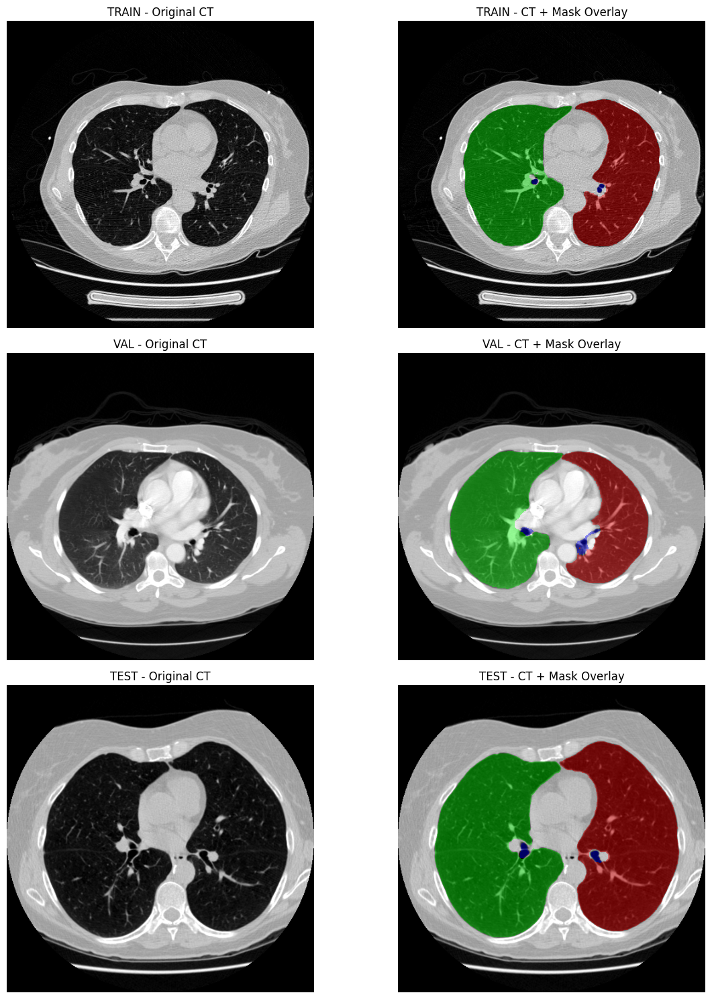

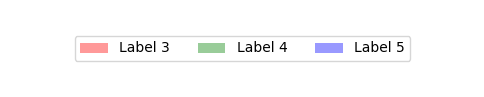

In [17]:

# ============================================================
# CELL 11.1 - VISUAL CT AND MASK LABEL INSPECTION
# ============================================================

import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

LUNA_DIR = Path(
    "/kaggle/working/lungvision_splits/luna16_corrected"
)

split_path = (
    LUNA_DIR / "luna16_all888_series_splits.csv"
)

luna_split = pd.read_csv(split_path)

# Select one representative scan per split
selected_scans = []

for split_name in ["train", "val", "test"]:

    subset = luna_split[
        luna_split["split"] == split_name
    ]

    if subset.empty:
        raise ValueError(f"No scan found for {split_name}")

    selected_scans.append(subset.iloc[0])

# Display categorical mask values without assuming
# their anatomical meaning.
label_colors = [
    (0, 0, 0, 0),
    (0, 0, 0, 0),
    (0, 0, 0, 0),
    (1, 0, 0, 0.40),
    (0, 1, 0, 0.40),
    (0, 0, 1, 0.40)
]

cmap = ListedColormap(label_colors)

norm = BoundaryNorm(
    np.arange(-0.5, 6.5, 1),
    cmap.N
)

fig, axes = plt.subplots(
    3, 2,
    figsize=(13, 15)
)

for i, row in enumerate(selected_scans):

    ct_path = Path(row["ct_mhd_path"])
    mask_path = Path(row["lung_mask_mhd_path"])

    ct_image = sitk.ReadImage(str(ct_path))
    mask_image = sitk.ReadImage(str(mask_path))

    ct = sitk.GetArrayFromImage(ct_image)
    mask = sitk.GetArrayFromImage(mask_image)

    # Select axial slice with maximum foreground area.
    foreground_counts = np.count_nonzero(
        mask,
        axis=(1, 2)
    )

    z = int(np.argmax(foreground_counts))

    ct_slice = ct[z]
    mask_slice = mask[z]

    # Display CT in a lung-window-like range.
    ct_display = np.clip(
        ct_slice,
        -1000,
        400
    )

    axes[i, 0].imshow(
        ct_display,
        cmap="gray",
        vmin=-1000,
        vmax=400
    )

    axes[i, 0].set_title(
        f"{row['split'].upper()} - Original CT"
    )

    axes[i, 1].imshow(
        ct_display,
        cmap="gray",
        vmin=-1000,
        vmax=400
    )

    axes[i, 1].imshow(
        mask_slice,
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    axes[i, 1].set_title(
        f"{row['split'].upper()} - CT + Mask Overlay"
    )

    for ax in axes[i]:
        ax.axis("off")

    values, counts = np.unique(
        mask,
        return_counts=True
    )

    print(f"\n{row['split'].upper()} MASK VALUES")

    display(pd.DataFrame({
        "voxel_label": values,
        "voxel_count": counts,
        "percentage": counts / mask.size * 100
    }))

    print(
        "Selected slice:", z,
        "| CT shape:", ct.shape,
        "| Mask shape:", mask.shape
    )

plt.tight_layout()
plt.show()

legend_items = [
    Patch(facecolor="red", alpha=0.4, label="Label 3"),
    Patch(facecolor="green", alpha=0.4, label="Label 4"),
    Patch(facecolor="blue", alpha=0.4, label="Label 5")
]

fig, ax = plt.subplots(figsize=(6, 1))
ax.legend(
    handles=legend_items,
    loc="center",
    ncol=3
)
ax.axis("off")
plt.show()


In [18]:
# ============================================================
# CELL 12: IN-CXR DATA PIPELINE + RESNET18 BASELINE
# ============================================================

import os
import re
import gc
import copy
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# -------------------- CONFIGURATION --------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 8
LEARNING_RATE = 0.0001
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_PRETRAINED = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# -------------------- FIND IN-CXR MANIFEST --------------------

SPLIT_ROOT = Path("/kaggle/working/lungvision_splits")

csv_files = [
    p for p in SPLIT_ROOT.rglob("*.csv")
    if "incxr" in re.sub(r"[^a-z0-9]", "", p.name.lower())
]

if not csv_files:
    raise FileNotFoundError(
        "No IN-CXR CSV manifest found under " + str(SPLIT_ROOT)
    )


def normalize_column(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def find_column(columns, aliases, fallback=None):
    normalized = {
        normalize_column(col): col
        for col in columns
    }

    for alias in aliases:
        if normalize_column(alias) in normalized:
            return normalized[normalize_column(alias)]

    if fallback:
        for col in columns:
            name = normalize_column(col)
            if any(token in name for token in fallback):
                return col

    return None


manifest_candidates = []

for csv_path in csv_files:
    try:
        temp = pd.read_csv(csv_path)

        path_col = find_column(
            temp.columns,
            [
                "image_path", "filepath", "file_path",
                "image_file", "image", "filename",
                "file_name", "image_name", "image_id"
            ],
            fallback=["imagepath", "filepath", "filename"]
        )

        label_col = find_column(
            temp.columns,
            [
                "label", "class", "target",
                "class_name", "diagnosis", "category"
            ],
            fallback=["label", "target", "class"]
        )

        split_col = find_column(
            temp.columns,
            ["split", "partition", "subset", "set"],
            fallback=["split", "partition"]
        )

        if path_col is not None and label_col is not None:
            score = 2 + int(split_col is not None)
            manifest_candidates.append(
                (score, csv_path, temp, path_col, label_col, split_col)
            )

    except Exception as exc:
        print("Skipped:", csv_path.name, "|", str(exc))


if not manifest_candidates:
    raise ValueError(
        "Could not identify image path and label columns. "
        "Available CSV files: " + str(csv_files)
    )

manifest_candidates.sort(key=lambda x: x[0], reverse=True)

_, MANIFEST_PATH, df, PATH_COL, LABEL_COL, SPLIT_COL = (
    manifest_candidates[0]
)

print("\nSelected manifest:", MANIFEST_PATH)
print("Image column:", PATH_COL)
print("Label column:", LABEL_COL)
print("Split column:", SPLIT_COL)
print("Manifest rows:", len(df))


# -------------------- FIND IMAGE DIRECTORY --------------------

DATASET_ROOT = None

if "dataset_path_by_name" in globals():
    for key, value in dataset_path_by_name.items():
        if "incxr" in normalize_column(key):
            candidate = Path(value)
            if candidate.exists():
                DATASET_ROOT = candidate
                break

if DATASET_ROOT is None:
    possible_roots = [
        p for p in Path("/kaggle/input/datasets").rglob("*")
        if p.is_dir()
        and normalize_column(p.name) == "incxrdatasetpng"
    ]

    if possible_roots:
        DATASET_ROOT = possible_roots[0]

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the IN-CXR dataset directory."
    )

print("Dataset root:", DATASET_ROOT)


# Build a filename lookup for unresolved manifest paths
IMAGE_LOOKUP = {}

for image_path in DATASET_ROOT.rglob("*"):
    if image_path.is_file() and image_path.suffix.lower() in {
        ".png", ".jpg", ".jpeg"
    }:
        IMAGE_LOOKUP.setdefault(image_path.name.lower(), image_path)
        IMAGE_LOOKUP.setdefault(image_path.stem.lower(), image_path)


def resolve_image_path(value):
    raw = str(value).strip()

    if not raw or raw.lower() == "nan":
        return None

    candidate = Path(raw)

    if candidate.is_file():
        return candidate

    candidate = DATASET_ROOT / raw

    if candidate.is_file():
        return candidate

    candidate = DATASET_ROOT / Path(raw).name

    if candidate.is_file():
        return candidate

    basename = Path(raw).name.lower()
    stem = Path(raw).stem.lower()

    return IMAGE_LOOKUP.get(
        basename,
        IMAGE_LOOKUP.get(stem)
    )


df = df.copy()
df["resolved_image_path"] = df[PATH_COL].apply(resolve_image_path)

missing_paths = df["resolved_image_path"].isna().sum()

if missing_paths:
    print("Unresolved image paths:", missing_paths)

df = df.dropna(subset=["resolved_image_path"]).copy()


# -------------------- NORMALIZE LABELS --------------------

def convert_label(value):

    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.integer, np.floating)):
        value = int(value)

        if value in [0, 1]:
            return value

    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9]", "", value)

    normal_labels = {
        "normal", "healthy", "0", "negative"
    }

    abnormal_labels = {
        "abnormal", "abnormality", "1", "positive"
    }

    if value in normal_labels:
        return 0

    if value in abnormal_labels:
        return 1

    return np.nan


df["label"] = df[LABEL_COL].apply(convert_label)

invalid_labels = df["label"].isna().sum()

if invalid_labels:
    print("Rows with unrecognized labels:", invalid_labels)

df = df.dropna(subset=["label"]).copy()
df["label"] = df["label"].astype(int)

assert set(df["label"].unique()).issubset({0, 1})

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index().rename({
    0: "Normal",
    1: "Abnormal"
}))


# -------------------- CREATE / VALIDATE SPLITS --------------------

if SPLIT_COL is not None:

    split_mapping = {
        "train": "train",
        "training": "train",
        "val": "val",
        "valid": "val",
        "validation": "val",
        "test": "test",
        "testing": "test"
    }

    df["split"] = (
        df[SPLIT_COL]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(split_mapping)
    )

    if df["split"].isna().any():
        raise ValueError(
            "Unknown split values: "
            + str(df.loc[df["split"].isna(), SPLIT_COL].unique())
        )

    required_splits = {"train", "val", "test"}

    if set(df["split"].unique()) != required_splits:
        raise ValueError(
            "Expected train, val and test splits. Found: "
            + str(df["split"].value_counts().to_dict())
        )

else:

    train_df, temp_df = train_test_split(
        df,
        test_size=0.20,
        random_state=SEED,
        stratify=df["label"]
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=SEED,
        stratify=temp_df["label"]
    )

    train_df = train_df.copy()
    val_df = val_df.copy()
    test_df = test_df.copy()

    train_df["split"] = "train"
    val_df["split"] = "val"
    test_df["split"] = "test"

    df = pd.concat(
        [train_df, val_df, test_df],
        ignore_index=True
    )


train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print("\nSplit distribution:")

for name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(
        name,
        "| Images:", len(split_df),
        "| Normal:", int((split_df["label"] == 0).sum()),
        "| Abnormal:", int((split_df["label"] == 1).sum())
    )


# -------------------- DATA TRANSFORMS --------------------

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# -------------------- PYTORCH DATASET --------------------

class INCXRDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        image_path = row["resolved_image_path"]
        label = int(row["label"])

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if self.transform:
                image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.float32)

Device: cuda
GPU: Tesla T4

Selected manifest: /kaggle/working/lungvision_splits/incxr_train_val_test.csv
Image column: image_path
Label column: label
Split column: split
Manifest rows: 12600
Dataset root: /kaggle/input/datasets/arjav007/in-cxr-dataset-png

Label distribution:
label
Normal      6300
Abnormal    6300
Name: count, dtype: int64

Split distribution:
TRAIN | Images: 10080 | Normal: 5040 | Abnormal: 5040
VALIDATION | Images: 1260 | Normal: 630 | Abnormal: 630
TEST | Images: 1260 | Normal: 630 | Abnormal: 630


In [19]:
train_dataset = INCXRDataset(train_df, train_transform)
val_dataset = INCXRDataset(val_df, eval_transform)
test_dataset = INCXRDataset(test_df, eval_transform)

In [20]:
# ============================================================
# CELL 12A: DATALOADERS + RESNET18 INITIALIZATION
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models
from pathlib import Path

BATCH_SIZE = 32
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Validate one batch
images, labels = next(iter(train_loader))

print("DATA LOADER VALIDATION")
print("-" * 40)
print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", torch.unique(labels))

# Initialize ResNet18
try:
    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )
    print("\nPretrained ImageNet weights loaded.")

except Exception as e:
    print("\nPretrained weights unavailable:", str(e))
    print("Initializing ResNet18 without pretrained weights.")
    model = models.resnet18(weights=None)

# Replace final layer for binary classification
model.fc = nn.Linear(model.fc.in_features, 1)

model = model.to(DEVICE)

# Loss and optimizer
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("\nMODEL INITIALIZATION SUCCESSFUL")
print("Architecture: ResNet18")
print("Output classes: 1 (binary classification)")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB"
      if torch.cuda.is_available() else "N/A")

DATA LOADER VALIDATION
----------------------------------------
Device: cuda
GPU: Tesla T4
Training images: 10080
Validation images: 1260
Testing images: 1260
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([0., 1.])
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 199MB/s]



Pretrained ImageNet weights loaded.

MODEL INITIALIZATION SUCCESSFUL
Architecture: ResNet18
Output classes: 1 (binary classification)
Parameters: 11177025
GPU memory allocated: 0.04 GB


In [21]:
# ============================================================
# CELL 12B: RESNET18 TRAINING + VALIDATION
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ---------------- CONFIGURATION ----------------

EPOCHS = 8
PATIENCE = 3

MODEL_DIR = Path("/kaggle/working/lungvision_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "incxr_resnet18_best.pth"
HISTORY_PATH = MODEL_DIR / "incxr_resnet18_history.csv"

use_amp = DEVICE.type == "cuda"

scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

# ---------------- METRICS ----------------

def calculate_metrics(y_true, y_prob):

    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob)

    y_pred = (y_prob >= 0.5).astype(int)

    auc = (
        roc_auc_score(y_true, y_prob)
        if len(np.unique(y_true)) == 2
        else np.nan
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    tn, fp, fn, tp = cm.ravel()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "auc": auc,
        "sensitivity": tp / (tp + fn) if (tp + fn) else 0,
        "specificity": tn / (tn + fp) if (tn + fp) else 0,
        "confusion_matrix": cm
    }


# ---------------- TRAIN ONE EPOCH ----------------

def train_one_epoch():

    model.train()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []

    progress = tqdm(
        train_loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True).unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        probabilities = torch.sigmoid(logits.detach())

        all_labels.extend(labels.detach().cpu().numpy().flatten())
        all_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

        progress.set_postfix(loss=f"{loss.item():.4f}")

    metrics = calculate_metrics(
        all_labels,
        all_probabilities
    )

    metrics["loss"] = total_loss / len(train_dataset)

    return metrics


# ---------------- VALIDATION ----------------

@torch.no_grad()
def validate_model():

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []

    progress = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    for images, labels in progress:

        images = images.to(DEVICE, non_blocking=True)
        labels_device = labels.to(
            DEVICE, non_blocking=True
        ).unsqueeze(1)

        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, labels_device)

        total_loss += loss.item() * images.size(0)

        probabilities = torch.sigmoid(logits)

        all_labels.extend(labels.numpy().flatten())
        all_probabilities.extend(
            probabilities.cpu().numpy().flatten()
        )

    metrics = calculate_metrics(
        all_labels,
        all_probabilities
    )

    metrics["loss"] = total_loss / len(val_dataset)

    return metrics


# ---------------- TRAINING LOOP ----------------

history = []

best_val_auc = -1.0
best_epoch = 0
epochs_without_improvement = 0

print("=" * 65)
print("LUNGVISION AI | IN-CXR RESNET18 TRAINING")
print("=" * 65)

training_start = time.time()

for epoch in range(EPOCHS):

    epoch_start = time.time()

    train_metrics = train_one_epoch()
    val_metrics = validate_model()

    epoch_time = time.time() - epoch_start

    history_row = {
        "epoch": epoch + 1,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_auc": train_metrics["auc"],
        "train_f1": train_metrics["f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_auc": val_metrics["auc"],
        "val_sensitivity": val_metrics["sensitivity"],
        "val_specificity": val_metrics["specificity"],
        "epoch_time_seconds": epoch_time
    }

    history.append(history_row)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 50)

    print(
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train AUC: {train_metrics['auc']:.4f} | "
        f"Train F1: {train_metrics['f1']:.4f}"
    )

    print(
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val AUC: {val_metrics['auc']:.4f} | "
        f"Val F1: {val_metrics['f1']:.4f}"
    )

    print(
        f"Val Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val Sensitivity: {val_metrics['sensitivity']:.4f} | "
        f"Val Specificity: {val_metrics['specificity']:.4f}"
    )

    print(f"Epoch time: {epoch_time:.1f} seconds")

    current_auc = val_metrics["auc"]

    if np.isfinite(current_auc) and current_auc > best_val_auc:

        best_val_auc = current_auc
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_auc": best_val_auc,
                "image_size": IMAGE_SIZE,
                "label_mapping": {
                    0: "Normal",
                    1: "Abnormal"
                }
            },
            BEST_MODEL_PATH
        )

        print("Best model checkpoint saved.")

    else:
        epochs_without_improvement += 1
        print("Validation AUC did not improve.")

    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping activated.")
        break


# ---------------- SAVE HISTORY ----------------

history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)

total_training_time = time.time() - training_start

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

print("Best epoch:", best_epoch)
print("Best validation AUC:", round(best_val_auc, 4))
print("Total training time:", round(total_training_time / 60, 2), "minutes")
print("Best checkpoint:", BEST_MODEL_PATH)
print("Training history:", HISTORY_PATH)

if torch.cuda.is_available():
    print(
        "Peak GPU memory allocated:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

LUNGVISION AI | IN-CXR RESNET18 TRAINING


Training:   0%|          | 0/315 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]


Epoch 1/8
--------------------------------------------------
Train Loss: 0.4358 | Train AUC: 0.8774 | Train F1: 0.7872
Val Loss: 0.3982 | Val AUC: 0.9048 | Val F1: 0.8185
Val Accuracy: 0.8349 | Val Sensitivity: 0.7444 | Val Specificity: 0.9254
Epoch time: 393.1 seconds
Best model checkpoint saved.


Training:   0%|          | 0/315 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

... (16 outputs left out)


Epoch 6/8
--------------------------------------------------
Train Loss: 0.1223 | Train AUC: 0.9906 | Train F1: 0.9516
Val Loss: 0.5182 | Val AUC: 0.9176 | Val F1: 0.8262
Val Accuracy: 0.8421 | Val Sensitivity: 0.7508 | Val Specificity: 0.9333
Epoch time: 24.2 seconds
Validation AUC did not improve.


Training:   0%|          | 0/315 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]


Epoch 7/8
--------------------------------------------------
Train Loss: 0.0984 | Train AUC: 0.9939 | Train F1: 0.9611
Val Loss: 0.4920 | Val AUC: 0.9178 | Val F1: 0.8490
Val Accuracy: 0.8532 | Val Sensitivity: 0.8254 | Val Specificity: 0.8810
Epoch time: 23.8 seconds
Validation AUC did not improve.

Early stopping activated.

TRAINING COMPLETED
Best epoch: 4
Best validation AUC: 0.9332
Total training time: 9.45 minutes
Best checkpoint: /kaggle/working/lungvision_models/incxr_resnet18_best.pth
Training history: /kaggle/working/lungvision_models/incxr_resnet18_history.csv
Peak GPU memory allocated: 0.56 GB


In [22]:
# ============================================================
# CELL 13: COMPLETE FINAL IN-CXR TEST EVALUATION
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    brier_score_loss
)

# ============================================================
# 1. CONFIGURATION
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "/kaggle/working/lungvision_models/incxr_resnet18_best.pth"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BATCH_SIZE = 32
THRESHOLD = 0.50

print("=" * 65)
print("LUNGVISION AI | FINAL IN-CXR TEST EVALUATION")
print("=" * 65)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. VERIFY REQUIRED DATASET AND CHECKPOINT
# ============================================================

required_variables = [
    "test_df",
    "test_dataset",
    "INCXRDataset"
]

for variable in required_variables:

    if variable not in globals():
        raise RuntimeError(
            f"Missing variable: {variable}. "
            "Run the IN-CXR data preparation cells first."
        )

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Best model checkpoint not found: {MODEL_PATH}"
    )

print("\nTest dataset:", len(test_dataset))
print("Test manifest:", len(test_df))
print("Checkpoint:", MODEL_PATH)


# ============================================================
# 3. LOAD SAVED RESNET18 CHECKPOINT
# ============================================================

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Reconstruct the original architecture
model = models.resnet18(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

# Restore trained parameters
model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("\nBEST CHECKPOINT LOADED")
print("Best epoch:", checkpoint["epoch"])
print("Best validation AUC:", checkpoint["best_val_auc"])
print("Parameters:", sum(p.numel() for p in model.parameters()))


# ============================================================
# 4. CREATE TEST DATALOADER
# ============================================================

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("\nTest DataLoader ready.")
print("Test batches:", len(test_loader))


# ============================================================
# 5. RUN INFERENCE
# ============================================================

y_true_list = []
y_prob_list = []

print("\nRunning inference on test images...")

model.eval()

with torch.inference_mode():

    for batch_idx, (images, labels) in enumerate(test_loader):

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        # Model prediction
        logits = model(images)

        # Convert logits into probabilities
        probabilities = torch.sigmoid(logits)

        y_true_list.extend(
            labels.cpu().numpy().astype(int).flatten()
        )

        y_prob_list.extend(
            probabilities.cpu().numpy().flatten()
        )

        if (batch_idx + 1) % 10 == 0:
            print(
                f"Processed batches: "
                f"{batch_idx + 1}/{len(test_loader)}"
            )


# Convert predictions into NumPy arrays
y_true = np.asarray(
    y_true_list,
    dtype=int
)

y_prob = np.asarray(
    y_prob_list,
    dtype=float
)

# Apply classification threshold
y_pred = (
    y_prob >= THRESHOLD
).astype(int)


# ============================================================
# 6. VALIDATE PREDICTION ALIGNMENT
# ============================================================

if len(y_true) != len(test_df):

    raise ValueError(
        f"Prediction count mismatch: "
        f"{len(y_true)} predictions vs {len(test_df)} manifest rows."
    )

if len(y_prob) != len(test_df):

    raise ValueError(
        "Probability count does not match test manifest."
    )

manifest_labels = (
    test_df["label"]
    .to_numpy()
    .astype(int)
)

if not np.array_equal(y_true, manifest_labels):

    raise ValueError(
        "Dataset label order does not match test_df. "
        "Check test dataset construction and ordering."
    )

if not np.isfinite(y_prob).all():

    raise ValueError(
        "Non-finite probability values detected."
    )

print("\nINFERENCE COMPLETED SUCCESSFULLY")
print("Total predictions:", len(y_true))
print("Normal images:", int((y_true == 0).sum()))
print("Abnormal images:", int((y_true == 1).sum()))


# ============================================================
# 7. CALCULATE EVALUATION METRICS
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

metrics = {
    "accuracy": accuracy_score(
        y_true,
        y_pred
    ),

    "balanced_accuracy": balanced_accuracy_score(
        y_true,
        y_pred
    ),

    "precision": precision_score(
        y_true,
        y_pred,
        zero_division=0
    ),

    "recall": recall_score(
        y_true,
        y_pred,
        zero_division=0
    ),

    "f1": f1_score(
        y_true,
        y_pred,
        zero_division=0
    ),

    "auc_roc": roc_auc_score(
        y_true,
        y_prob
    ),

    "average_precision": average_precision_score(
        y_true,
        y_prob
    ),

    "sensitivity": (
        tp / (tp + fn)
        if (tp + fn) else 0
    ),

    "specificity": (
        tn / (tn + fp)
        if (tn + fp) else 0
    ),

    "negative_predictive_value": (
        tn / (tn + fn)
        if (tn + fn) else 0
    ),

    "brier_score": brier_score_loss(
        y_true,
        y_prob
    )
}


# ============================================================
# 8. DISPLAY FINAL RESULTS
# ============================================================

print("\n" + "=" * 65)
print("LUNGVISION AI | FINAL TEST RESULTS")
print("=" * 65)

print("Test images:", len(y_true))
print("Decision threshold:", THRESHOLD)

for name, value in metrics.items():

    print(
        f"{name.upper():28s}: {value:.4f}"
    )


print("\nCONFUSION MATRIX")
print("-" * 45)

print("Rows = Actual | Columns = Predicted")
print("Class order: Normal (0), Abnormal (1)")
print(cm)

print("\nCONFUSION MATRIX INTERPRETATION")

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)


# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\nCLASSIFICATION REPORT")
print("-" * 45)

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Normal",
            "Abnormal"
        ],
        zero_division=0
    )
)


# ============================================================
# 10. CREATE PREDICTION DATAFRAME
# ============================================================

prediction_df = test_df.reset_index(
    drop=True
).copy()

prediction_df["actual_label"] = y_true
prediction_df["abnormal_probability"] = y_prob
prediction_df["predicted_label"] = y_pred

prediction_df["actual_class"] = (
    prediction_df["actual_label"]
    .map({
        0: "Normal",
        1: "Abnormal"
    })
)

prediction_df["predicted_class"] = (
    prediction_df["predicted_label"]
    .map({
        0: "Normal",
        1: "Abnormal"
    })
)

prediction_df["correct_prediction"] = (
    prediction_df["actual_label"]
    == prediction_df["predicted_label"]
)


# Assign prediction categories
prediction_df["prediction_type"] = np.select(
    [
        (y_true == 1) & (y_pred == 1),
        (y_true == 0) & (y_pred == 0),
        (y_true == 0) & (y_pred == 1),
        (y_true == 1) & (y_pred == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)


# ============================================================
# 11. SAVE PREDICTION RESULTS
# ============================================================

prediction_path = (
    OUTPUT_DIR / "incxr_test_predictions.csv"
)

prediction_df.to_csv(
    prediction_path,
    index=False
)


# ============================================================
# 12. SAVE METRICS
# ============================================================

metrics_path = (
    OUTPUT_DIR / "incxr_test_metrics.csv"
)

metrics_df = pd.DataFrame([
    {
        "metric": key,
        "value": value
    }
    for key, value in metrics.items()
])

metrics_df.to_csv(
    metrics_path,
    index=False
)


# Save confusion matrix
confusion_path = (
    OUTPUT_DIR / "incxr_confusion_matrix.csv"
)

pd.DataFrame(
    cm,
    index=["Actual_Normal", "Actual_Abnormal"],
    columns=["Predicted_Normal", "Predicted_Abnormal"]
).to_csv(confusion_path)


# ============================================================
# 13. DISPLAY PREDICTION CATEGORIES
# ============================================================

print("\nPREDICTION CATEGORIES")
print("-" * 45)

print(
    prediction_df["prediction_type"].value_counts()
)

print("\nCORRECT PREDICTIONS:",
      int(prediction_df["correct_prediction"].sum()))

print("INCORRECT PREDICTIONS:",
      int((~prediction_df["correct_prediction"]).sum()))


# ============================================================
# 14. DISPLAY MISCLASSIFIED EXAMPLES
# ============================================================

print("\nFALSE NEGATIVE EXAMPLES")

display(
    prediction_df[
        prediction_df["prediction_type"] == "False Negative"
    ][[
        "filename",
        "actual_class",
        "predicted_class",
        "abnormal_probability",
        "prediction_type"
    ]].head(10)
)


print("\nFALSE POSITIVE EXAMPLES")

display(
    prediction_df[
        prediction_df["prediction_type"] == "False Positive"
    ][[
        "filename",
        "actual_class",
        "predicted_class",
        "abnormal_probability",
        "prediction_type"
    ]].head(10)
)


# ============================================================
# 15. FINAL EXPORT SUMMARY
# ============================================================

print("\n" + "=" * 65)
print("CELL 13 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nSAVED FILES:")

print("Predictions:", prediction_path)
print("Metrics:", metrics_path)
print("Confusion matrix:", confusion_path)

print("\nTotal exported predictions:", len(prediction_df))

print("\nAll evaluation and export steps completed.")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

LUNGVISION AI | FINAL IN-CXR TEST EVALUATION
Device: cuda
GPU: Tesla T4

Test dataset: 1260
Test manifest: 1260
Checkpoint: /kaggle/working/lungvision_models/incxr_resnet18_best.pth

BEST CHECKPOINT LOADED
Best epoch: 4
Best validation AUC: 0.9332060972537164
Parameters: 11177025

Test DataLoader ready.
Test batches: 40

Running inference on test images...
Processed batches: 10/40
Processed batches: 20/40
Processed batches: 30/40
Processed batches: 40/40

INFERENCE COMPLETED SUCCESSFULLY
Total predictions: 1260
Normal images: 630
Abnormal images: 630

LUNGVISION AI | FINAL TEST RESULTS
Test images: 1260
Decision threshold: 0.5
ACCURACY                    : 0.8611
BALANCED_ACCURACY           : 0.8611
PRECISION                   : 0.8824
RECALL                      : 0.8333
F1                          : 0.8571
AUC_ROC                     : 0.9348
AVERAGE_PRECISION           : 0.9411
SENSITIVITY                 : 0.8333
SPECIFICITY                 : 0.8889
NEGATIVE_PREDICTIVE_VALUE   : 0.

,filename,actual_class,predicted_class,abnormal_probability,prediction_type
3,9e369cdf157aefee4a3e3008f374fa63_Abnormal.png,Abnormal,Normal,0.302370,False Negative
19,AB_training_28.png,Abnormal,Normal,0.181896,False Negative
27,040ace0e100bb4969d6088f4e6dd761e_Abnormal.png,Abnormal,Normal,0.222525,False Negative
32,2b2f47646ef13c05e5b15d385280c15c_Abnormal.png,Abnormal,Normal,0.129633,False Negative
49,6824c39baf64d23c4e8819416684b96e_Abnormal.png,Abnormal,Normal,0.170400,False Negative
50,9599ae5a1584b049b8f982f9c5367b87_Abnormal.png,Abnormal,Normal,0.283774,False Negative
51,b181dd2430a5c38616e742748f5ffc83_Abnormal.png,Abnormal,Normal,0.190545,False Negative
62,AB_training_713.png,Abnormal,Normal,0.327144,False Negative
67,08c283eeb867f5809649e683075d343c_Abnormal.png,Abnormal,Normal,0.025700,False Negative
74,AB_training_1655.png,Abnormal,Normal,0.338552,False Negative



FALSE POSITIVE EXAMPLES


,filename,actual_class,predicted_class,abnormal_probability,prediction_type
8,35fd978ce38b0b3cba74a9e00faa36c9_Normal.png,Normal,Abnormal,0.843282,False Positive
22,930fca2c4789346484503c8a0d5a99b2_Normal.png,Normal,Abnormal,0.886602,False Positive
29,0d42ec5b318c853d32580439a497b688_Normal.png,Normal,Abnormal,0.967181,False Positive
73,e61e8945eaf0fccdb37fda4d68e8f0bb_Normal.png,Normal,Abnormal,0.722682,False Positive
92,85a71735660d7ae7fca8b2a6d4e278b3_Normal.png,Normal,Abnormal,0.792274,False Positive
98,a0083a27ad86a3b67dbd93330d381b69_Normal.png,Normal,Abnormal,0.943848,False Positive
111,98a30221bc45e1114d1f0f3f4e6bd955_Normal.png,Normal,Abnormal,0.873370,False Positive
122,a9b31bf81ce0ca5bb8857e568cb46eef_Normal.png,Normal,Abnormal,0.988070,False Positive
129,7fd4d3ce0daf0f4f73a199196dd77d0b_Normal.png,Normal,Abnormal,0.907563,False Positive
134,7d8c817b4be71e56d92668381fc50a01_Normal.png,Normal,Abnormal,0.940962,False Positive



CELL 13 COMPLETED SUCCESSFULLY

SAVED FILES:
Predictions: /kaggle/working/lungvision_results/incxr_test_predictions.csv
Metrics: /kaggle/working/lungvision_results/incxr_test_metrics.csv
Confusion matrix: /kaggle/working/lungvision_results/incxr_confusion_matrix.csv

Total exported predictions: 1260

All evaluation and export steps completed.


FALSE NEGATIVES: Abnormal images predicted as Normal


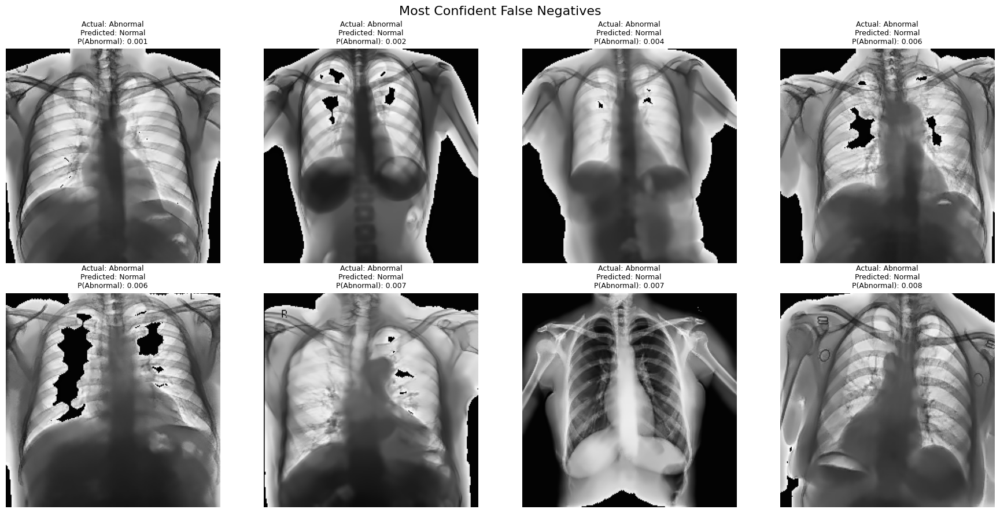

FALSE POSITIVES: Normal images predicted as Abnormal


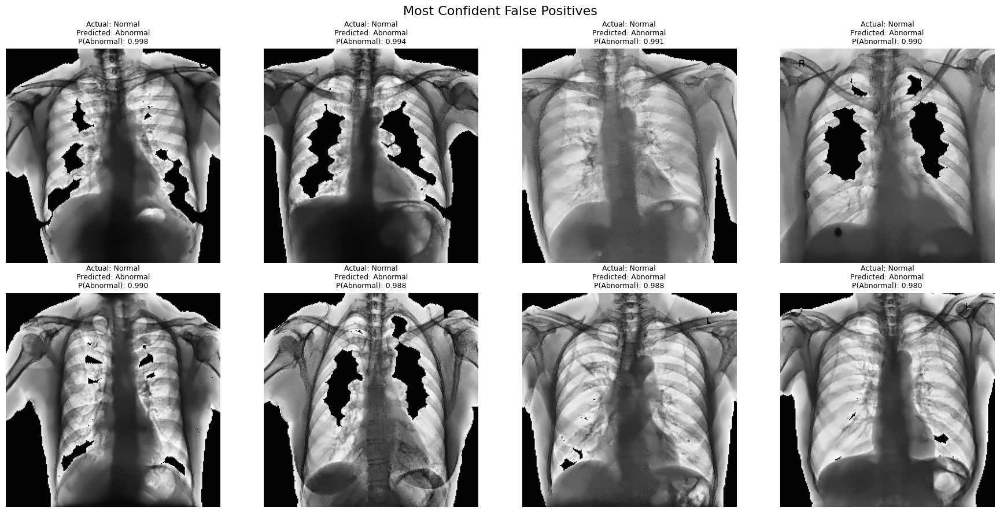

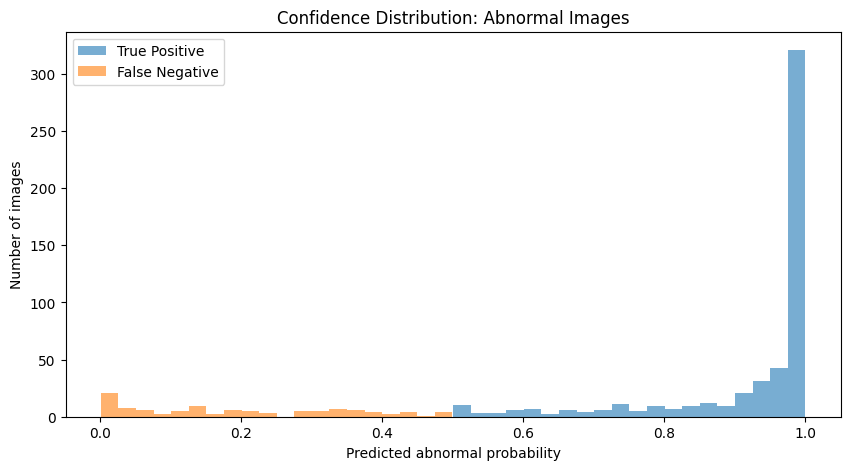

Visual error analysis completed.


In [23]:
# ============================================================
# CELL 14: VISUAL ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

CSV_PATH = Path(
    "/kaggle/working/lungvision_results/incxr_test_predictions.csv"
)

prediction_df = pd.read_csv(CSV_PATH)

required_columns = [
    "resolved_image_path",
    "actual_label",
    "predicted_label",
    "abnormal_probability",
    "prediction_type"
]

missing = [
    col for col in required_columns
    if col not in prediction_df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Most confidently missed abnormal images
false_negatives = (
    prediction_df[
        prediction_df["prediction_type"] == "False Negative"
    ]
    .sort_values("abnormal_probability", ascending=True)
    .head(8)
)

# Most confidently misclassified normal images
false_positives = (
    prediction_df[
        prediction_df["prediction_type"] == "False Positive"
    ]
    .sort_values("abnormal_probability", ascending=False)
    .head(8)
)


def visualize_errors(dataframe, title):

    if dataframe.empty:
        print("No examples found:", title)
        return

    fig, axes = plt.subplots(
        2, 4,
        figsize=(18, 9)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for i, (_, row) in enumerate(dataframe.iterrows()):

        image_path = Path(row["resolved_image_path"])

        try:
            with Image.open(image_path) as img:
                image = img.convert("RGB").copy()

            axes[i].imshow(image)

            axes[i].set_title(
                f"Actual: {row['actual_class']}\n"
                f"Predicted: {row['predicted_class']}\n"
                f"P(Abnormal): {row['abnormal_probability']:.3f}",
                fontsize=9
            )

            axes[i].axis("off")

        except Exception as e:
            axes[i].set_title(f"Image error: {e}")

    fig.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


print("FALSE NEGATIVES: Abnormal images predicted as Normal")
visualize_errors(
    false_negatives,
    "Most Confident False Negatives"
)

print("FALSE POSITIVES: Normal images predicted as Abnormal")
visualize_errors(
    false_positives,
    "Most Confident False Positives"
)


# Confidence distribution
plt.figure(figsize=(10, 5))

plt.hist(
    prediction_df.loc[
        prediction_df["prediction_type"] == "True Positive",
        "abnormal_probability"
    ],
    bins=20,
    alpha=0.6,
    label="True Positive"
)

plt.hist(
    prediction_df.loc[
        prediction_df["prediction_type"] == "False Negative",
        "abnormal_probability"
    ],
    bins=20,
    alpha=0.6,
    label="False Negative"
)

plt.xlabel("Predicted abnormal probability")
plt.ylabel("Number of images")
plt.title("Confidence Distribution: Abnormal Images")
plt.legend()
plt.show()

print("Visual error analysis completed.")

Analysing image properties:   0%|          | 0/12600 [00:00<?, ?it/s]

Image feature extraction completed.
Images: 12600
Saved: /kaggle/working/lungvision_results/incxr_image_quality_audit.csv

NORMAL VS ABNORMAL IMAGE STATISTICS


,Normal,Abnormal
width,224.0000,224.0000
height,224.0000,224.0000
aspect_ratio,1.0000,1.0000
mean_intensity,106.7007,107.8292
std_intensity,65.4649,64.4878
p05,10.3370,13.2809
p50,102.4207,103.5377
p95,213.9914,213.1774
black_fraction,0.0053,0.0054
low_intensity_fraction,0.1376,0.1419


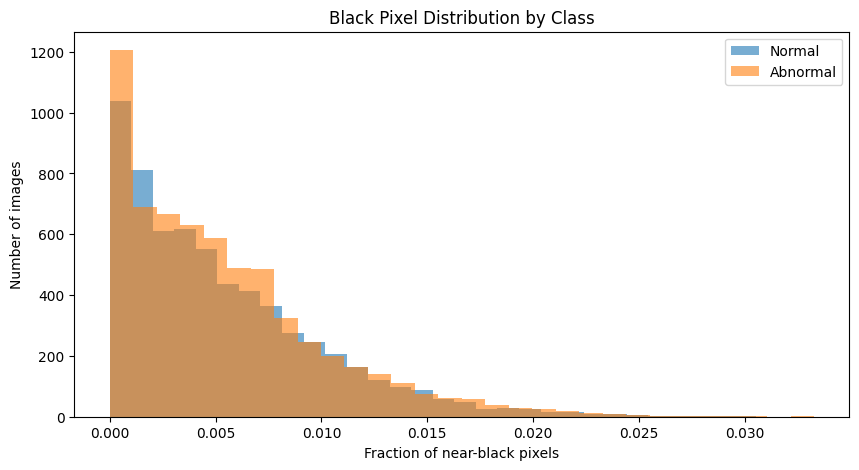


IMAGE STATISTICS-ONLY CLASSIFIER
---------------------------------------------
Validation AUC: 0.6632
Test AUC: 0.6537
Validation Accuracy: 0.6048
Test Accuracy: 0.6119


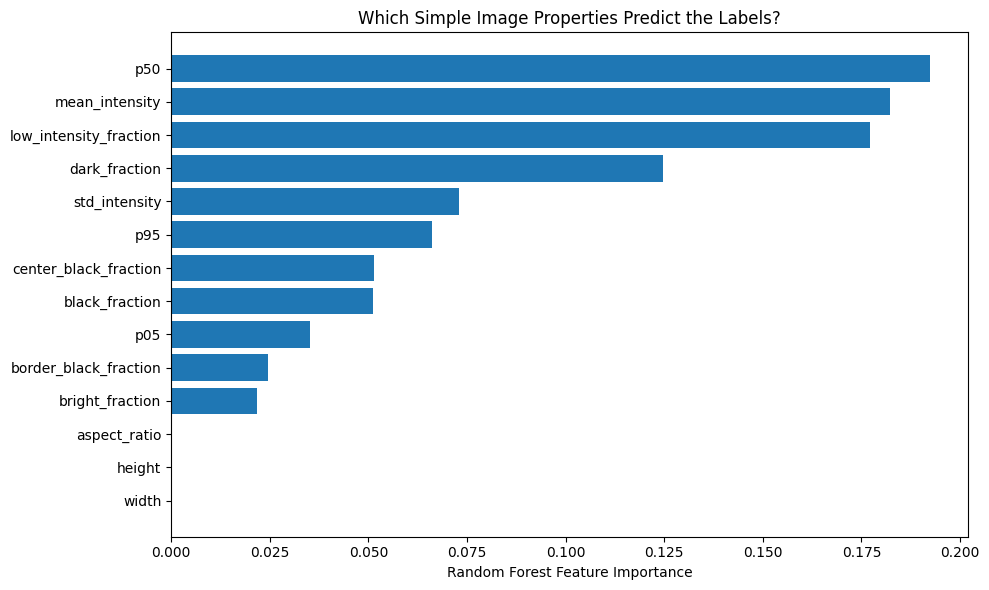

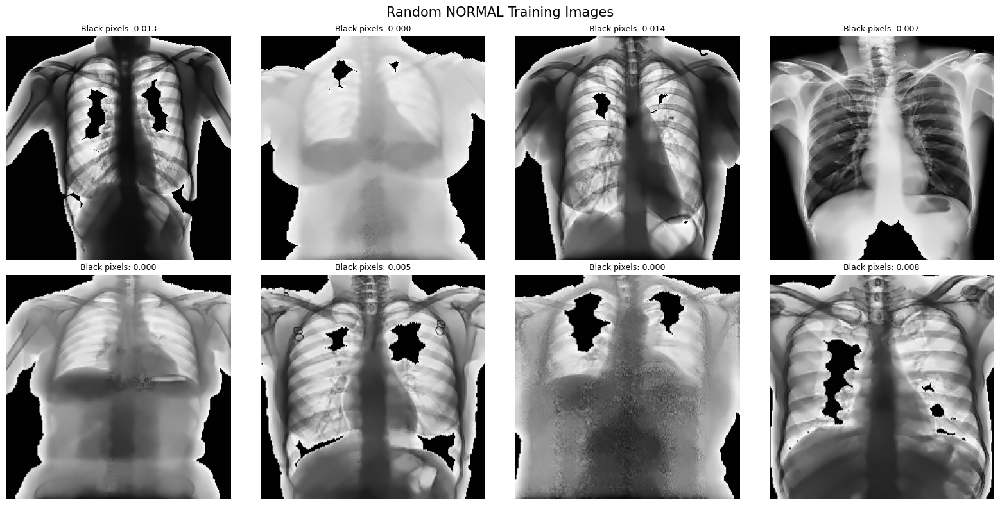

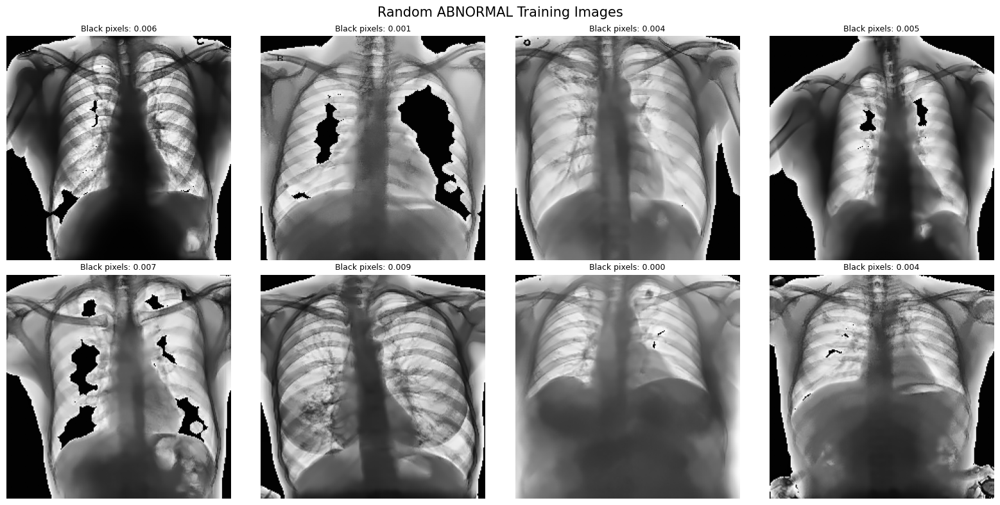


CELL 15 COMPLETED


In [24]:
# ============================================================
# CELL 15: IN-CXR DATASET ARTEFACT AUDIT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

AUDIT_DIR = Path("/kaggle/working/lungvision_results")
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

RESIZE = (128, 128)

# Use the original complete manifest
audit_df = df.copy().reset_index(drop=True)

assert {"resolved_image_path", "label", "split"}.issubset(
    audit_df.columns
)

# ------------------------------------------------------------
# EXTRACT BASIC IMAGE STATISTICS
# ------------------------------------------------------------

def extract_image_features(image_path):

    with Image.open(image_path) as image:

        width, height = image.size

        grayscale = image.convert("L").resize(
            RESIZE,
            Image.Resampling.BILINEAR
        )

        array = np.asarray(
            grayscale,
            dtype=np.uint8
        )

    border = np.concatenate([
        array[:12, :].ravel(),
        array[-12:, :].ravel(),
        array[:, :12].ravel(),
        array[:, -12:].ravel()
    ])

    center = array[16:-16, 16:-16]

    return {
        "width": width,
        "height": height,
        "aspect_ratio": width / max(height, 1),

        "mean_intensity": array.mean(),
        "std_intensity": array.std(),

        "p05": np.percentile(array, 5),
        "p25": np.percentile(array, 25),
        "p50": np.percentile(array, 50),
        "p75": np.percentile(array, 75),
        "p95": np.percentile(array, 95),

        "black_fraction": np.mean(array <= 2),
        "low_intensity_fraction": np.mean(array <= 10),
        "dark_fraction": np.mean(array <= 25),

        "bright_fraction": np.mean(array >= 245),

        "border_black_fraction": np.mean(border <= 2),
        "center_black_fraction": np.mean(center <= 2)
    }


features = []

for path in tqdm(
    audit_df["resolved_image_path"],
    desc="Analysing image properties"
):

    features.append(
        extract_image_features(path)
    )

feature_df = pd.DataFrame(features)

audit_data = pd.concat(
    [
        audit_df[
            ["resolved_image_path", "label", "split"]
        ].reset_index(drop=True),
        feature_df
    ],
    axis=1
)

audit_csv = AUDIT_DIR / "incxr_image_quality_audit.csv"

audit_data.to_csv(
    audit_csv,
    index=False
)

print("Image feature extraction completed.")
print("Images:", len(audit_data))
print("Saved:", audit_csv)


# ------------------------------------------------------------
# LABEL-WISE FEATURE COMPARISON
# ------------------------------------------------------------

feature_columns = [
    "width",
    "height",
    "aspect_ratio",
    "mean_intensity",
    "std_intensity",
    "p05",
    "p50",
    "p95",
    "black_fraction",
    "low_intensity_fraction",
    "dark_fraction",
    "bright_fraction",
    "border_black_fraction",
    "center_black_fraction"
]

print("\nNORMAL VS ABNORMAL IMAGE STATISTICS")

summary = audit_data.groupby("label")[
    feature_columns
].mean().T

summary.columns = ["Normal", "Abnormal"]

display(summary.round(4))


# ------------------------------------------------------------
# VISUALIZE CLASS-WISE BLACK PIXEL DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    audit_data.loc[
        audit_data["label"] == 0,
        "black_fraction"
    ],
    bins=30,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    audit_data.loc[
        audit_data["label"] == 1,
        "black_fraction"
    ],
    bins=30,
    alpha=0.6,
    label="Abnormal"
)

plt.xlabel("Fraction of near-black pixels")
plt.ylabel("Number of images")
plt.title("Black Pixel Distribution by Class")
plt.legend()
plt.show()


# ------------------------------------------------------------
# RANDOM FOREST: IMAGE STATISTICS ONLY
# ------------------------------------------------------------

train_audit = audit_data[
    audit_data["split"] == "train"
]

val_audit = audit_data[
    audit_data["split"] == "val"
]

test_audit = audit_data[
    audit_data["split"] == "test"
]

X_train = train_audit[feature_columns]
y_train = train_audit["label"]

X_val = val_audit[feature_columns]
y_val = val_audit["label"]

X_test = test_audit[feature_columns]
y_test = test_audit["label"]

audit_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

audit_model.fit(X_train, y_train)

val_prob = audit_model.predict_proba(X_val)[:, 1]
test_prob = audit_model.predict_proba(X_test)[:, 1]

val_auc = roc_auc_score(y_val, val_prob)
test_auc = roc_auc_score(y_test, test_prob)

print("\nIMAGE STATISTICS-ONLY CLASSIFIER")
print("-" * 45)

print("Validation AUC:", round(val_auc, 4))
print("Test AUC:", round(test_auc, 4))

print(
    "Validation Accuracy:",
    round(
        accuracy_score(
            y_val,
            (val_prob >= 0.5).astype(int)
        ),
        4
    )
)

print(
    "Test Accuracy:",
    round(
        accuracy_score(
            y_test,
            (test_prob >= 0.5).astype(int)
        ),
        4
    )
)


# ------------------------------------------------------------
# FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "feature": feature_columns,
    "importance": audit_model.feature_importances_
}).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.xlabel("Random Forest Feature Importance")
plt.title("Which Simple Image Properties Predict the Labels?")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# DISPLAY RANDOM ORIGINAL IMAGES BY CLASS
# ------------------------------------------------------------

def show_random_samples(label, class_name, count=8):

    samples = audit_data[
        (audit_data["label"] == label)
        & (audit_data["split"] == "train")
    ].sample(
        n=min(count, (audit_data["label"].eq(label) & audit_data["split"].eq("train")).sum()),
        random_state=42
    )

    fig, axes = plt.subplots(
        2, 4,
        figsize=(16, 8)
    )

    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for i, (_, row) in enumerate(samples.iterrows()):

        with Image.open(row["resolved_image_path"]) as image:
            image = image.convert("L")

            axes[i].imshow(image, cmap="gray")
            axes[i].set_title(
                f"Black pixels: {row['black_fraction']:.3f}",
                fontsize=9
            )
            axes[i].axis("off")

    fig.suptitle(
        f"Random {class_name} Training Images",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


show_random_samples(0, "NORMAL")
show_random_samples(1, "ABNORMAL")

print("\nCELL 15 COMPLETED")

LUNGVISION AI | SPATIAL ARTEFACT AUDIT


Extracting spatial features:   0%|          | 0/12600 [00:00<?, ?it/s]


Spatial feature extraction completed.
Images: 12600
Grid: 8 x 8
Features per image: 64
Saved: /kaggle/working/lungvision_results/spatial_audit/incxr_spatial_features.csv


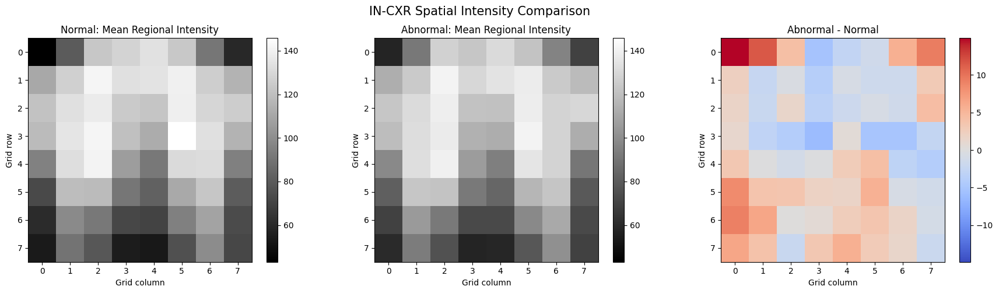


SPATIAL AUDIT EXPERIMENTS

Training: Global statistics (14 features)
Validation AUC: 0.6632
Validation Accuracy: 0.6048

Training: Spatial grid (64 features)
Validation AUC: 0.7876
Validation Accuracy: 0.7087

Training: Combined (78 features)
Validation AUC: 0.786
Validation Accuracy: 0.7008

FINAL VALIDATION COMPARISON


,experiment,feature_count,validation_auc,validation_accuracy,validation_balanced_accuracy,validation_average_precision
0,Global statistics (14 features),14,0.6632,0.6048,0.6048,0.6706
1,Spatial grid (64 features),64,0.7876,0.7087,0.7087,0.7998
2,Combined (78 features),78,0.7860,0.7008,0.7008,0.8020


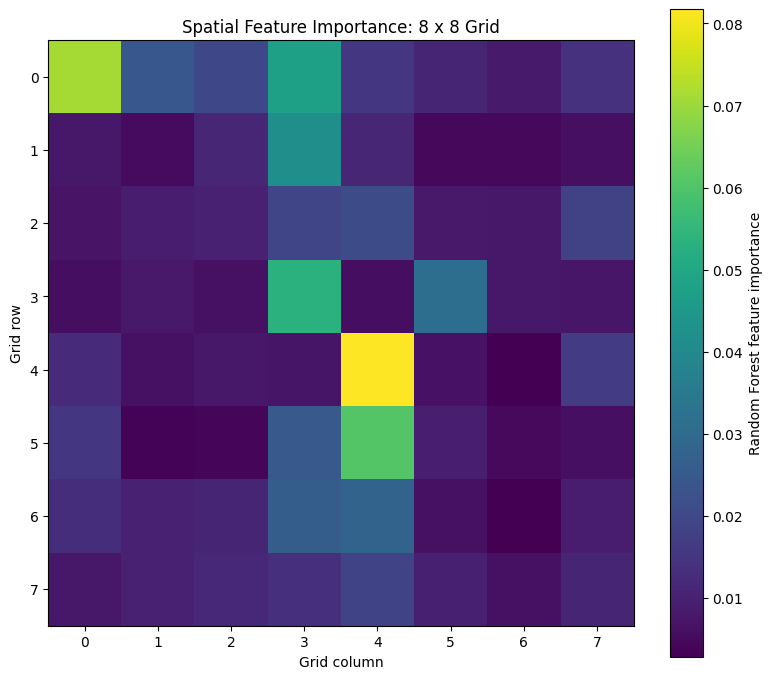


Top 15 spatial regions:


,region,importance
36,grid_4_4,0.081721
0,grid_0_0,0.070949
44,grid_5_4,0.060564
27,grid_3_3,0.053183
3,grid_0_3,0.047678
11,grid_1_3,0.042232
29,grid_3_5,0.031288
52,grid_6_4,0.028095
51,grid_6_3,0.026226
43,grid_5_3,0.024967



Outputs saved under:
/kaggle/working/lungvision_results/spatial_audit

SPATIAL ARTEFACT AUDIT COMPLETED


In [25]:
# ============================================================
# CELL 16: SPATIAL IMAGE ARTEFACT AUDIT
# LungVision AI | IN-CXR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

GRID_SIZE = 8
RESIZE_SIZE = 128
SEED = 42

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/spatial_audit"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert "audit_data" in globals(), (
    "Run Cell 15 first. audit_data was not found."
)

required_columns = {
    "resolved_image_path",
    "label",
    "split"
}

assert required_columns.issubset(audit_data.columns)

print("=" * 65)
print("LUNGVISION AI | SPATIAL ARTEFACT AUDIT")
print("=" * 65)


# ------------------------------------------------------------
# 1. EXTRACT 8 x 8 REGIONAL INTENSITY FEATURES
# ------------------------------------------------------------

def extract_spatial_features(image_path):

    with Image.open(image_path) as image:

        image = image.convert("L")
        image = image.resize(
            (RESIZE_SIZE, RESIZE_SIZE),
            Image.Resampling.BILINEAR
        )

        image_array = np.asarray(
            image,
            dtype=np.float32
        )

    block_size = RESIZE_SIZE // GRID_SIZE

    grid = image_array.reshape(
        GRID_SIZE,
        block_size,
        GRID_SIZE,
        block_size
    ).mean(axis=(1, 3))

    return grid.flatten()


spatial_feature_names = [
    f"grid_{row}_{col}"
    for row in range(GRID_SIZE)
    for col in range(GRID_SIZE)
]

spatial_features = []

for image_path in tqdm(
    audit_data["resolved_image_path"],
    desc="Extracting spatial features"
):

    spatial_features.append(
        extract_spatial_features(image_path)
    )


spatial_array = np.asarray(
    spatial_features,
    dtype=np.float32
)

spatial_df = pd.DataFrame(
    spatial_array,
    columns=spatial_feature_names
)

spatial_data = pd.concat(
    [
        audit_data[
            [
                "resolved_image_path",
                "label",
                "split"
            ]
        ].reset_index(drop=True),
        spatial_df.reset_index(drop=True)
    ],
    axis=1
)

spatial_csv = OUTPUT_DIR / "incxr_spatial_features.csv"

spatial_data.to_csv(
    spatial_csv,
    index=False
)

print("\nSpatial feature extraction completed.")
print("Images:", len(spatial_data))
print("Grid:", f"{GRID_SIZE} x {GRID_SIZE}")
print("Features per image:", len(spatial_feature_names))
print("Saved:", spatial_csv)


# ------------------------------------------------------------
# 2. GENERATE CLASS-WISE SPATIAL INTENSITY MAPS
# ------------------------------------------------------------

normal_data = spatial_data[
    spatial_data["label"] == 0
]

abnormal_data = spatial_data[
    spatial_data["label"] == 1
]

normal_map = normal_data[
    spatial_feature_names
].mean().values.reshape(
    GRID_SIZE,
    GRID_SIZE
)

abnormal_map = abnormal_data[
    spatial_feature_names
].mean().values.reshape(
    GRID_SIZE,
    GRID_SIZE
)

difference_map = abnormal_map - normal_map

shared_min = min(
    normal_map.min(),
    abnormal_map.min()
)

shared_max = max(
    normal_map.max(),
    abnormal_map.max()
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

im1 = axes[0].imshow(
    normal_map,
    cmap="gray",
    vmin=shared_min,
    vmax=shared_max
)

axes[0].set_title("Normal: Mean Regional Intensity")
axes[0].set_xlabel("Grid column")
axes[0].set_ylabel("Grid row")

im2 = axes[1].imshow(
    abnormal_map,
    cmap="gray",
    vmin=shared_min,
    vmax=shared_max
)

axes[1].set_title("Abnormal: Mean Regional Intensity")
axes[1].set_xlabel("Grid column")
axes[1].set_ylabel("Grid row")

limit = max(
    abs(difference_map.min()),
    abs(difference_map.max())
)

im3 = axes[2].imshow(
    difference_map,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)

axes[2].set_title("Abnormal - Normal")
axes[2].set_xlabel("Grid column")
axes[2].set_ylabel("Grid row")

plt.colorbar(im1, ax=axes[0], fraction=0.046)
plt.colorbar(im2, ax=axes[1], fraction=0.046)
plt.colorbar(im3, ax=axes[2], fraction=0.046)

plt.suptitle(
    "IN-CXR Spatial Intensity Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. PREPARE TRAIN AND VALIDATION DATA
# ------------------------------------------------------------

train_spatial = spatial_data[
    spatial_data["split"] == "train"
].reset_index(drop=True)

val_spatial = spatial_data[
    spatial_data["split"] == "val"
].reset_index(drop=True)

global_feature_names = [
    col for col in feature_columns
    if col in audit_data.columns
]

assert len(global_feature_names) > 0

global_train = audit_data[
    audit_data["split"] == "train"
].reset_index(drop=True)

global_val = audit_data[
    audit_data["split"] == "val"
].reset_index(drop=True)

assert np.array_equal(
    train_spatial["label"].values,
    global_train["label"].values
)

assert np.array_equal(
    val_spatial["label"].values,
    global_val["label"].values
)

y_train = train_spatial["label"].values
y_val = val_spatial["label"].values


# ------------------------------------------------------------
# 4. DEFINE THREE EXPERIMENTS
# ------------------------------------------------------------

X_global_train = global_train[
    global_feature_names
]

X_global_val = global_val[
    global_feature_names
]

X_spatial_train = train_spatial[
    spatial_feature_names
]

X_spatial_val = val_spatial[
    spatial_feature_names
]

X_combined_train = pd.concat(
    [
        X_global_train.reset_index(drop=True),
        X_spatial_train.reset_index(drop=True)
    ],
    axis=1
)

X_combined_val = pd.concat(
    [
        X_global_val.reset_index(drop=True),
        X_spatial_val.reset_index(drop=True)
    ],
    axis=1
)


# ------------------------------------------------------------
# 5. TRAIN FAIRLY CONFIGURED RANDOM FORESTS
# ------------------------------------------------------------

def create_audit_model():

    return RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )


experiments = {
    "Global statistics (14 features)": (
        X_global_train,
        X_global_val
    ),

    "Spatial grid (64 features)": (
        X_spatial_train,
        X_spatial_val
    ),

    "Combined (78 features)": (
        X_combined_train,
        X_combined_val
    )
}

results = []
trained_models = {}

print("\n" + "=" * 65)
print("SPATIAL AUDIT EXPERIMENTS")
print("=" * 65)

for experiment_name, (
    X_train_exp,
    X_val_exp
) in experiments.items():

    print("\nTraining:", experiment_name)

    audit_rf = create_audit_model()

    audit_rf.fit(
        X_train_exp,
        y_train
    )

    val_prob = audit_rf.predict_proba(
        X_val_exp
    )[:, 1]

    val_pred = (
        val_prob >= 0.5
    ).astype(int)

    result = {
        "experiment": experiment_name,
        "feature_count": X_train_exp.shape[1],
        "validation_auc": roc_auc_score(
            y_val,
            val_prob
        ),
        "validation_accuracy": accuracy_score(
            y_val,
            val_pred
        ),
        "validation_balanced_accuracy": balanced_accuracy_score(
            y_val,
            val_pred
        ),
        "validation_average_precision": average_precision_score(
            y_val,
            val_prob
        )
    }

    results.append(result)
    trained_models[experiment_name] = audit_rf

    print(
        "Validation AUC:",
        round(result["validation_auc"], 4)
    )

    print(
        "Validation Accuracy:",
        round(result["validation_accuracy"], 4)
    )


# ------------------------------------------------------------
# 6. COMPARE EXPERIMENTS
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFINAL VALIDATION COMPARISON")
display(
    results_df.round(4)
)

results_df.to_csv(
    OUTPUT_DIR / "spatial_audit_model_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 7. SPATIAL FEATURE IMPORTANCE HEATMAP
# ------------------------------------------------------------

spatial_model = trained_models[
    "Spatial grid (64 features)"
]

importance_map = spatial_model.feature_importances_.reshape(
    GRID_SIZE,
    GRID_SIZE
)

plt.figure(figsize=(8, 7))

plt.imshow(
    importance_map,
    cmap="viridis"
)

plt.colorbar(
    label="Random Forest feature importance"
)

plt.title(
    "Spatial Feature Importance: 8 x 8 Grid"
)

plt.xlabel("Grid column")
plt.ylabel("Grid row")

plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. EXPORT SPATIAL FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "region": spatial_feature_names,
    "importance": spatial_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

importance_df.to_csv(
    OUTPUT_DIR / "spatial_feature_importance.csv",
    index=False
)

print("\nTop 15 spatial regions:")

display(
    importance_df.head(15)
)

print("\nOutputs saved under:")
print(OUTPUT_DIR)

print("\nSPATIAL ARTEFACT AUDIT COMPLETED")

Per-image normalization:   0%|          | 0/12600 [00:00<?, ?it/s]

Normalized grid shape: (12600, 64)
Shuffled grid shape: (12600, 64)

SPATIAL POSITION CONTROL EXPERIMENT

Experiment: Raw spatial
Validation AUC: 0.7876
Validation accuracy: 0.7087
Average precision: 0.7998

Experiment: Per-image normalized spatial
Validation AUC: 0.7691
Validation accuracy: 0.6976
Average precision: 0.78

Experiment: Independently shuffled spatial
Validation AUC: 0.5722
Validation accuracy: 0.5421
Average precision: 0.5783

FINAL EXPERIMENT COMPARISON


,experiment,validation_auc,validation_accuracy,average_precision
0,Raw spatial,0.7876,0.7087,0.7998
1,Per-image normalized spatial,0.7691,0.6976,0.7800
2,Independently shuffled spatial,0.5722,0.5421,0.5783


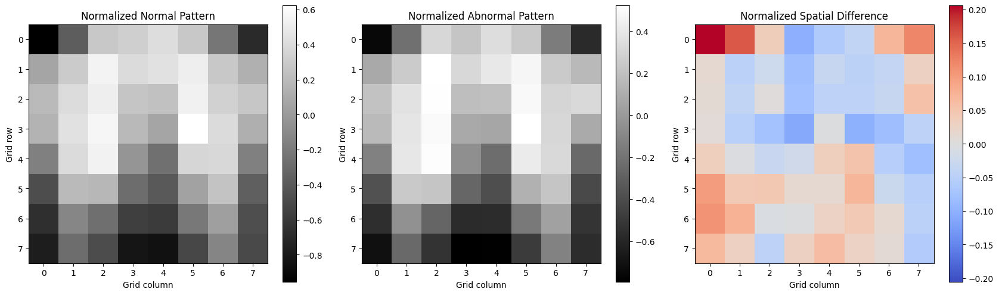


CELL 17 COMPLETED
Original raw spatial AUC: 0.7876
Raw spatial: 0.7876
Per-image normalized spatial: 0.7691
Independently shuffled spatial: 0.5722

Results saved under:
/kaggle/working/lungvision_results/spatial_audit


In [26]:
# ============================================================
# CELL 17: SPATIAL POSITION VS INTENSITY EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    average_precision_score
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

GRID_SIZE = 8
RESIZE_SIZE = 128
SEED = 42

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/spatial_audit"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert "spatial_array" in globals()
assert "audit_data" in globals()

# ------------------------------------------------------------
# 1. RECREATE PER-IMAGE NORMALIZED SPATIAL FEATURES
# ------------------------------------------------------------

def extract_normalized_grid(image_path):

    with Image.open(image_path) as image:

        image = image.convert("L").resize(
            (RESIZE_SIZE, RESIZE_SIZE),
            Image.Resampling.BILINEAR
        )

        array = np.asarray(
            image,
            dtype=np.float32
        )

    # Remove overall image brightness and contrast
    mean = array.mean()
    std = array.std()

    normalized = (array - mean) / (std + 1e-6)

    block = RESIZE_SIZE // GRID_SIZE

    grid = normalized.reshape(
        GRID_SIZE,
        block,
        GRID_SIZE,
        block
    ).mean(axis=(1, 3))

    return grid.flatten()


normalized_features = []

for path in tqdm(
    audit_data["resolved_image_path"],
    desc="Per-image normalization"
):

    normalized_features.append(
        extract_normalized_grid(path)
    )


normalized_array = np.asarray(
    normalized_features,
    dtype=np.float32
)

print("Normalized grid shape:", normalized_array.shape)


# ------------------------------------------------------------
# 2. RANDOMIZE GRID POSITIONS INDEPENDENTLY
# ------------------------------------------------------------

rng = np.random.default_rng(SEED)

shuffled_array = np.stack([
    rng.permutation(row)
    for row in spatial_array
]).astype(np.float32)

print("Shuffled grid shape:", shuffled_array.shape)


# ------------------------------------------------------------
# 3. CREATE TRAIN / VALIDATION ARRAYS
# ------------------------------------------------------------

train_mask = (
    audit_data["split"].values == "train"
)

val_mask = (
    audit_data["split"].values == "val"
)

y_train = audit_data.loc[
    train_mask, "label"
].values.astype(int)

y_val = audit_data.loc[
    val_mask, "label"
].values.astype(int)

X_raw_train = spatial_array[train_mask]
X_raw_val = spatial_array[val_mask]

X_norm_train = normalized_array[train_mask]
X_norm_val = normalized_array[val_mask]

X_shuffle_train = shuffled_array[train_mask]
X_shuffle_val = shuffled_array[val_mask]


# ------------------------------------------------------------
# 4. TRAIN CONTROL EXPERIMENTS
# ------------------------------------------------------------

def build_model():

    return RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )


experiments = {
    "Raw spatial": (
        X_raw_train,
        X_raw_val
    ),

    "Per-image normalized spatial": (
        X_norm_train,
        X_norm_val
    ),

    "Independently shuffled spatial": (
        X_shuffle_train,
        X_shuffle_val
    )
}

results = []

trained_models = {}

print("\n" + "=" * 65)
print("SPATIAL POSITION CONTROL EXPERIMENT")
print("=" * 65)

for name, (X_train, X_val) in experiments.items():

    print("\nExperiment:", name)

    rf = build_model()

    rf.fit(X_train, y_train)

    probabilities = rf.predict_proba(X_val)[:, 1]

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    auc = roc_auc_score(
        y_val,
        probabilities
    )

    accuracy = accuracy_score(
        y_val,
        predictions
    )

    ap = average_precision_score(
        y_val,
        probabilities
    )

    results.append({
        "experiment": name,
        "validation_auc": auc,
        "validation_accuracy": accuracy,
        "average_precision": ap
    })

    trained_models[name] = rf

    print("Validation AUC:", round(auc, 4))
    print("Validation accuracy:", round(accuracy, 4))
    print("Average precision:", round(ap, 4))


# ------------------------------------------------------------
# 5. COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFINAL EXPERIMENT COMPARISON")

display(
    results_df.round(4)
)

results_df.to_csv(
    OUTPUT_DIR / "spatial_position_control_results.csv",
    index=False
)


# ------------------------------------------------------------
# 6. CLASS-WISE NORMALIZED SPATIAL MAPS
# ------------------------------------------------------------

normal_train_mask = (
    train_mask
    & (audit_data["label"].values == 0)
)

abnormal_train_mask = (
    train_mask
    & (audit_data["label"].values == 1)
)

normal_map = normalized_array[
    normal_train_mask
].mean(axis=0).reshape(
    GRID_SIZE,
    GRID_SIZE
)

abnormal_map = normalized_array[
    abnormal_train_mask
].mean(axis=0).reshape(
    GRID_SIZE,
    GRID_SIZE
)

difference_map = abnormal_map - normal_map

limit = max(
    abs(difference_map.min()),
    abs(difference_map.max())
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5)
)

im1 = axes[0].imshow(
    normal_map,
    cmap="gray"
)
axes[0].set_title("Normalized Normal Pattern")

im2 = axes[1].imshow(
    abnormal_map,
    cmap="gray"
)
axes[1].set_title("Normalized Abnormal Pattern")

im3 = axes[2].imshow(
    difference_map,
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit
)
axes[2].set_title("Normalized Spatial Difference")

for ax in axes:
    ax.set_xlabel("Grid column")
    ax.set_ylabel("Grid row")

plt.colorbar(im1, ax=axes[0])
plt.colorbar(im2, ax=axes[1])
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 17 COMPLETED")
print("=" * 65)

print("Original raw spatial AUC: 0.7876")

for _, row in results_df.iterrows():

    print(
        f"{row['experiment']}: "
        f"{row['validation_auc']:.4f}"
    )

print("\nResults saved under:")
print(OUTPUT_DIR)

Loaded ResNet18 checkpoint
Best epoch: 4
Validation AUC: 0.9332060972537164

Validation predictions completed.
Images: 1260
Validation accuracy: 0.8595

Selected examples:
False Negative | Index: 1256 | Actual: 1 | Probability: 0.0019
False Negative | Index: 657 | Actual: 1 | Probability: 0.0024
False Negative | Index: 1016 | Actual: 1 | Probability: 0.0035
False Positive | Index: 428 | Actual: 0 | Probability: 0.9996
False Positive | Index: 459 | Actual: 0 | Probability: 0.9984
False Positive | Index: 839 | Actual: 0 | Probability: 0.9982
True Positive | Index: 90 | Actual: 1 | Probability: 1.0
True Positive | Index: 538 | Actual: 1 | Probability: 1.0
True Positive | Index: 115 | Actual: 1 | Probability: 1.0
True Negative | Index: 350 | Actual: 0 | Probability: 0.0
True Negative | Index: 1008 | Actual: 0 | Probability: 0.0
True Negative | Index: 321 | Actual: 0 | Probability: 0.0


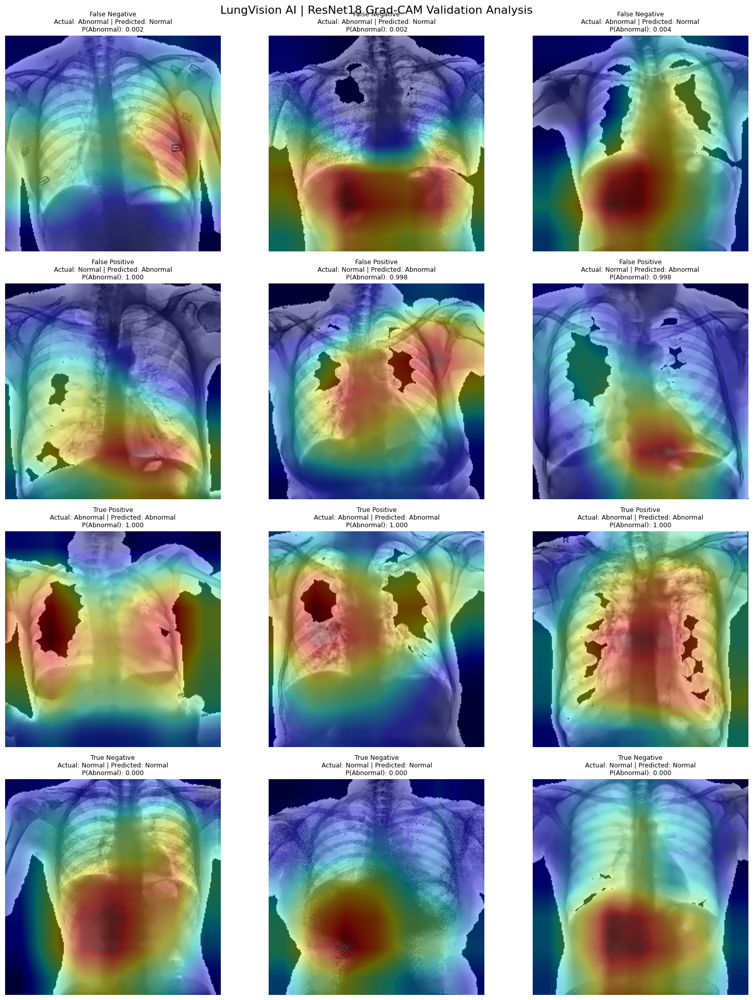


Grad-CAM analysis completed.
Validation images used: 12


In [27]:
# ============================================================
# CELL 18: RESNET18 GRAD-CAM VISUALIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "/kaggle/working/lungvision_models/incxr_resnet18_best.pth"
)

assert MODEL_PATH.exists(), "Best ResNet18 checkpoint not found."

# ------------------------------------------------------------
# LOAD BEST MODEL
# ------------------------------------------------------------

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Loaded ResNet18 checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Validation AUC:", checkpoint["best_val_auc"])


# ------------------------------------------------------------
# VALIDATION PREDICTIONS
# ------------------------------------------------------------

val_loader_gradcam = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

all_labels = []
all_probs = []

with torch.no_grad():

    for images, labels in val_loader_gradcam:

        images = images.to(DEVICE)

        logits = model(images)

        probabilities = torch.sigmoid(logits)

        all_labels.extend(
            labels.numpy().astype(int)
        )

        all_probs.extend(
            probabilities.cpu().numpy().flatten()
        )


y_val_true = np.asarray(all_labels)
y_val_prob = np.asarray(all_probs)

y_val_pred = (
    y_val_prob >= 0.5
).astype(int)

print("\nValidation predictions completed.")

print("Images:", len(y_val_true))
print(
    "Validation accuracy:",
    round(np.mean(y_val_true == y_val_pred), 4)
)


# ------------------------------------------------------------
# SELECT REPRESENTATIVE EXAMPLES
# ------------------------------------------------------------

false_negative_indices = np.where(
    (y_val_true == 1) & (y_val_pred == 0)
)[0]

false_positive_indices = np.where(
    (y_val_true == 0) & (y_val_pred == 1)
)[0]

true_positive_indices = np.where(
    (y_val_true == 1) & (y_val_pred == 1)
)[0]

true_negative_indices = np.where(
    (y_val_true == 0) & (y_val_pred == 0)
)[0]


def highest_confidence(indices, probabilities, category, count=3):

    if len(indices) == 0:
        return []

    if category == "false_negative":
        indices = sorted(
            indices,
            key=lambda i: probabilities[i]
        )

    elif category == "false_positive":
        indices = sorted(
            indices,
            key=lambda i: probabilities[i],
            reverse=True
        )

    elif category == "true_positive":
        indices = sorted(
            indices,
            key=lambda i: probabilities[i],
            reverse=True
        )

    elif category == "true_negative":
        indices = sorted(
            indices,
            key=lambda i: probabilities[i]
        )

    return indices[:count]


selected_samples = []

for indices, category in [
    (false_negative_indices, "False Negative"),
    (false_positive_indices, "False Positive"),
    (true_positive_indices, "True Positive"),
    (true_negative_indices, "True Negative")
]:

    chosen = highest_confidence(
        indices,
        y_val_prob,
        category.lower().replace(" ", "_"),
        count=3
    )

    for index in chosen:
        selected_samples.append(
            (index, category)
        )


print("\nSelected examples:")

for index, category in selected_samples:
    print(
        category,
        "| Index:", index,
        "| Actual:", y_val_true[index],
        "| Probability:", round(y_val_prob[index], 4)
    )


# ------------------------------------------------------------
# GRAD-CAM HOOKS
# ------------------------------------------------------------

activations = {}
gradients = {}


def save_activation(module, inputs, output):
    activations["value"] = output


def save_gradient(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]


target_layer = model.layer4[-1]

forward_handle = target_layer.register_forward_hook(
    save_activation
)

backward_handle = target_layer.register_full_backward_hook(
    save_gradient
)


# ------------------------------------------------------------
# GRAD-CAM FUNCTION
# ------------------------------------------------------------

def generate_gradcam(image_tensor, predicted_label):

    model.zero_grad(set_to_none=True)

    activations.clear()
    gradients.clear()

    image_tensor = image_tensor.unsqueeze(0).to(DEVICE)

    logits = model(image_tensor)

    # Use the score for the predicted class.
    # Positive logit = Abnormal.
    # Negative logit = Normal.
    if predicted_label == 1:
        target_score = logits[0, 0]
    else:
        target_score = -logits[0, 0]

    target_score.backward()

    activation = activations["value"]
    gradient = gradients["value"]

    weights = gradient.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = torch.relu(
        (weights * activation).sum(dim=1, keepdim=True)
    )

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()

    cam_min = cam.min()
    cam_max = cam.max()

    cam = (
        cam - cam_min
    ) / (
        cam_max - cam_min + 1e-8
    )

    return cam


# ------------------------------------------------------------
# VISUALIZE GRAD-CAM
# ------------------------------------------------------------

rows = int(np.ceil(len(selected_samples) / 3))

fig, axes = plt.subplots(
    rows,
    3,
    figsize=(16, rows * 5)
)

axes = np.array(axes).reshape(-1)

for ax in axes:
    ax.axis("off")


for position, (index, category) in enumerate(selected_samples):

    dataset_image, actual_label = val_dataset[index]

    predicted_label = int(y_val_pred[index])
    probability = float(y_val_prob[index])

    gradcam = generate_gradcam(
        dataset_image,
        predicted_label
    )

    image_path = val_dataset.data.iloc[index][
        "resolved_image_path"
    ]

    with Image.open(image_path) as image:
        original = image.convert("L").resize((224, 224))

        original = np.asarray(original)

    ax = axes[position]

    ax.imshow(
        original,
        cmap="gray"
    )

    ax.imshow(
        gradcam,
        cmap="jet",
        alpha=0.40,
        vmin=0,
        vmax=1
    )

    actual_name = "Abnormal" if actual_label == 1 else "Normal"
    predicted_name = "Abnormal" if predicted_label == 1 else "Normal"

    ax.set_title(
        f"{category}\n"
        f"Actual: {actual_name} | Predicted: {predicted_name}\n"
        f"P(Abnormal): {probability:.3f}",
        fontsize=9
    )

    ax.axis("off")


fig.suptitle(
    "LungVision AI | ResNet18 Grad-CAM Validation Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# CLEANUP
# ------------------------------------------------------------

forward_handle.remove()
backward_handle.remove()

print("\nGrad-CAM analysis completed.")
print("Validation images used:", len(selected_samples))

VALIDATION CONSISTENCY CHECK
---------------------------------------------
Accuracy: 0.8595
AUC: 0.9332
Saved checkpoint epoch: 4
False Negative | Available: 118 | Selected: 5
False Positive | Available: 59 | Selected: 5
True Positive | Available: 512 | Selected: 5
True Negative | Available: 571 | Selected: 5

RUNNING OCCLUSION EXPERIMENT
False Negative | Index: 972 | Baseline probability: 0.0257
False Negative | Index: 624 | Baseline probability: 0.2896
False Negative | Index: 893 | Baseline probability: 0.2064
False Negative | Index: 83 | Baseline probability: 0.0967
False Negative | Index: 1258 | Baseline probability: 0.0172
False Positive | Index: 1211 | Baseline probability: 0.6192
False Positive | Index: 169 | Baseline probability: 0.6487
False Positive | Index: 587 | Baseline probability: 0.5521
False Positive | Index: 983 | Baseline probability: 0.6268
False Positive | Index: 938 | Baseline probability: 0.5615
True Positive | Index: 636 | Baseline probability: 1.0
True Positive

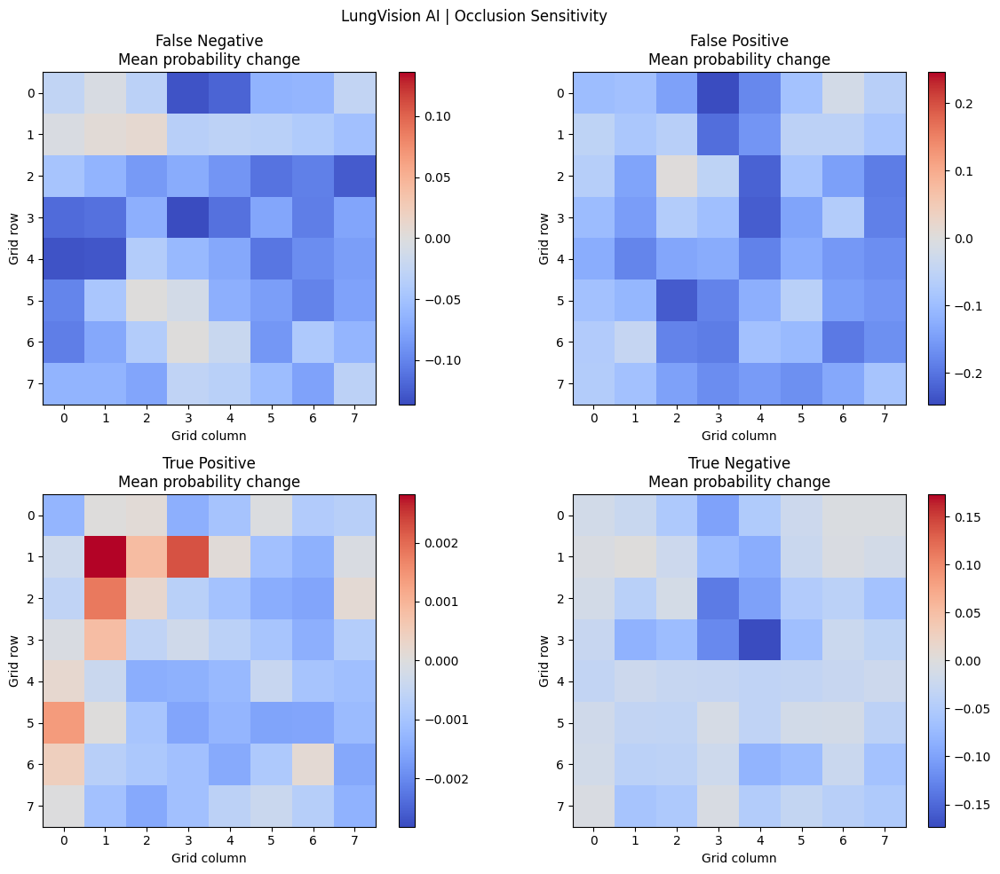


OCCLUSION ANALYSIS COMPLETED
Output directory:
/kaggle/working/lungvision_results/occlusion_analysis


In [28]:
# ============================================================
# CELL 19: RESNET18 OCCLUSION SENSITIVITY ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import pandas as pd

from pathlib import Path
from torch.utils.data import DataLoader

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

GRID_SIZE = 8
IMAGE_SIZE = 224
SAMPLES_PER_CATEGORY = 5
OCCLUSION_BATCH_SIZE = 32

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/occlusion_analysis"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert "model" in globals()
assert "val_dataset" in globals()
assert "y_val_true" in globals()
assert "y_val_pred" in globals()

model.eval()

# ------------------------------------------------------------
# 1. VALIDATION PREDICTION CONSISTENCY CHECK
# ------------------------------------------------------------

val_loader_check = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

check_labels = []
check_probs = []

with torch.no_grad():

    for images, labels in val_loader_check:

        images = images.to(DEVICE)

        probabilities = torch.sigmoid(
            model(images)
        )

        check_labels.extend(
            labels.numpy().astype(int)
        )

        check_probs.extend(
            probabilities.cpu().numpy().flatten()
        )

check_labels = np.asarray(check_labels)
check_probs = np.asarray(check_probs)

check_predictions = (
    check_probs >= 0.5
).astype(int)

from sklearn.metrics import accuracy_score, roc_auc_score

print("VALIDATION CONSISTENCY CHECK")
print("-" * 45)

print(
    "Accuracy:",
    round(
        accuracy_score(check_labels, check_predictions),
        4
    )
)

print(
    "AUC:",
    round(
        roc_auc_score(check_labels, check_probs),
        4
    )
)

print("Saved checkpoint epoch:", checkpoint["epoch"])

# Confirm that validation label order matches
assert np.array_equal(
    check_labels,
    y_val_true
), "Validation label order mismatch."


# ------------------------------------------------------------
# 2. SELECT FOUR PREDICTION CATEGORIES
# ------------------------------------------------------------

categories = {
    "False Negative": (
        (y_val_true == 1) & (y_val_pred == 0)
    ),
    "False Positive": (
        (y_val_true == 0) & (y_val_pred == 1)
    ),
    "True Positive": (
        (y_val_true == 1) & (y_val_pred == 1)
    ),
    "True Negative": (
        (y_val_true == 0) & (y_val_pred == 0)
    )
}

rng = np.random.default_rng(42)

selected = {}

for category, condition in categories.items():

    indices = np.where(condition)[0]

    count = min(
        SAMPLES_PER_CATEGORY,
        len(indices)
    )

    selected[category] = rng.choice(
        indices,
        size=count,
        replace=False
    ).tolist()

    print(
        category,
        "| Available:", len(indices),
        "| Selected:", count
    )


# ------------------------------------------------------------
# 3. OCCLUSION FUNCTION
# ------------------------------------------------------------

@torch.no_grad()
def calculate_occlusion_map(image_tensor):

    image = image_tensor.unsqueeze(0).to(DEVICE)

    baseline_probability = torch.sigmoid(
        model(image)
    ).item()

    patch_size = IMAGE_SIZE // GRID_SIZE

    occluded_images = []

    positions = []

    for row in range(GRID_SIZE):

        for col in range(GRID_SIZE):

            modified = image_tensor.clone()

            y1 = row * patch_size
            y2 = y1 + patch_size

            x1 = col * patch_size
            x2 = x1 + patch_size

            # Zero in normalized input space corresponds
            # approximately to the ImageNet mean pixel value.
            modified[:, y1:y2, x1:x2] = 0.0

            occluded_images.append(modified)
            positions.append((row, col))

    probabilities = []

    for start in range(
        0,
        len(occluded_images),
        OCCLUSION_BATCH_SIZE
    ):

        batch = torch.stack(
            occluded_images[
                start:start + OCCLUSION_BATCH_SIZE
            ]
        ).to(DEVICE)

        with torch.no_grad():

            output = torch.sigmoid(
                model(batch)
            ).flatten()

        probabilities.extend(
            output.cpu().numpy()
        )

    probabilities = np.asarray(probabilities)

    # Positive = region supports abnormal prediction.
    # Negative = masking region increases abnormal probability.
    probability_drop = (
        baseline_probability - probabilities
    )

    heatmap = probability_drop.reshape(
        GRID_SIZE,
        GRID_SIZE
    )

    return baseline_probability, heatmap


# ------------------------------------------------------------
# 4. COMPUTE CATEGORY-WISE OCCLUSION MAPS
# ------------------------------------------------------------

category_maps = {}
sample_results = []

print("\nRUNNING OCCLUSION EXPERIMENT")

for category, indices in selected.items():

    individual_maps = []

    for index in indices:

        image, label = val_dataset[index]

        baseline, occlusion_map = calculate_occlusion_map(
            image
        )

        individual_maps.append(
            occlusion_map
        )

        sample_results.append({
            "category": category,
            "validation_index": index,
            "actual_label": int(label),
            "predicted_label": int(y_val_pred[index]),
            "baseline_probability": baseline
        })

        print(
            category,
            "| Index:", index,
            "| Baseline probability:", round(baseline, 4)
        )

    category_maps[category] = np.mean(
        individual_maps,
        axis=0
    )


# ------------------------------------------------------------
# 5. VISUALIZE CATEGORY-WISE OCCLUSION MAPS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

axes = axes.flatten()

for ax, (category, heatmap) in zip(
    axes,
    category_maps.items()
):

    limit = max(
        abs(heatmap.min()),
        abs(heatmap.max())
    )

    im = ax.imshow(
        heatmap,
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit
    )

    ax.set_title(
        f"{category}\nMean probability change"
    )

    ax.set_xlabel("Grid column")
    ax.set_ylabel("Grid row")

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046
    )

plt.suptitle(
    "LungVision AI | Occlusion Sensitivity"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. SAVE RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame(sample_results)

results_df.to_csv(
    OUTPUT_DIR / "occlusion_sample_results.csv",
    index=False
)

for category, heatmap in category_maps.items():

    filename = (
        category.lower().replace(" ", "_")
        + "_occlusion_map.csv"
    )

    pd.DataFrame(
        heatmap,
        columns=[
            f"column_{i}"
            for i in range(GRID_SIZE)
        ]
    ).to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("\nOCCLUSION ANALYSIS COMPLETED")

print("Output directory:")
print(OUTPUT_DIR)

In [29]:
# ============================================================
# CELL 19A: RESTORE RESNET18 MODEL AND VALIDATION VARIABLES
# ============================================================

import torch
import torch.nn as nn
import numpy as np

from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, roc_auc_score

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_PATH = Path(
    "/kaggle/working/lungvision_models/incxr_resnet18_best.pth"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Model checkpoint not found: {MODEL_PATH}"
    )

# Restore validation dataset if necessary
if "val_dataset" not in globals():

    if "val_df" not in globals() or "eval_transform" not in globals():
        raise RuntimeError(
            "Run the IN-CXR dataset preparation cells first."
        )

    val_dataset = INCXRDataset(
        val_df,
        eval_transform
    )

# Load saved checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Reconstruct architecture
model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("ResNet18 restored successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Best validation AUC:", checkpoint["best_val_auc"])
print("Device:", DEVICE)

# Recreate validation predictions
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

y_val_true = []
y_val_prob = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        logits = model(images)

        probabilities = torch.sigmoid(logits)

        y_val_true.extend(
            labels.numpy().astype(int)
        )

        y_val_prob.extend(
            probabilities.cpu().numpy().flatten()
        )

y_val_true = np.asarray(y_val_true)
y_val_prob = np.asarray(y_val_prob)

y_val_pred = (
    y_val_prob >= 0.5
).astype(int)

print("\nValidation accuracy:",
      round(accuracy_score(y_val_true, y_val_pred), 4))

print("Validation AUC:",
      round(roc_auc_score(y_val_true, y_val_prob), 4))

print("\nAll Cell 19 dependencies restored.")

ResNet18 restored successfully.
Checkpoint epoch: 4
Best validation AUC: 0.9332060972537164
Device: cuda

Validation accuracy: 0.8595
Validation AUC: 0.9332

All Cell 19 dependencies restored.


Loaded checkpoint: 4

Validation accuracy: 0.8595
Validation AUC: 0.9332
False Negative | Available: 118 | Selected: 5
False Positive | Available: 59 | Selected: 5
True Positive | Available: 512 | Selected: 5
True Negative | Available: 571 | Selected: 5

Running corrected occlusion analysis...
False Negative | Index: 972 | P(Abnormal): 0.0257 | Mean logit effect: 0.2401
False Negative | Index: 624 | P(Abnormal): 0.2896 | Mean logit effect: 0.5229
False Negative | Index: 893 | P(Abnormal): 0.2064 | Mean logit effect: 0.3065
False Negative | Index: 83 | P(Abnormal): 0.0967 | Mean logit effect: 0.2217
False Negative | Index: 1258 | P(Abnormal): 0.0172 | Mean logit effect: 0.4422
False Positive | Index: 1211 | P(Abnormal): 0.6192 | Mean logit effect: -0.6139
False Positive | Index: 169 | P(Abnormal): 0.6487 | Mean logit effect: -0.3934
False Positive | Index: 587 | P(Abnormal): 0.5521 | Mean logit effect: -0.3005
False Positive | Index: 983 | P(Abnormal): 0.6268 | Mean logit effect: -0.336

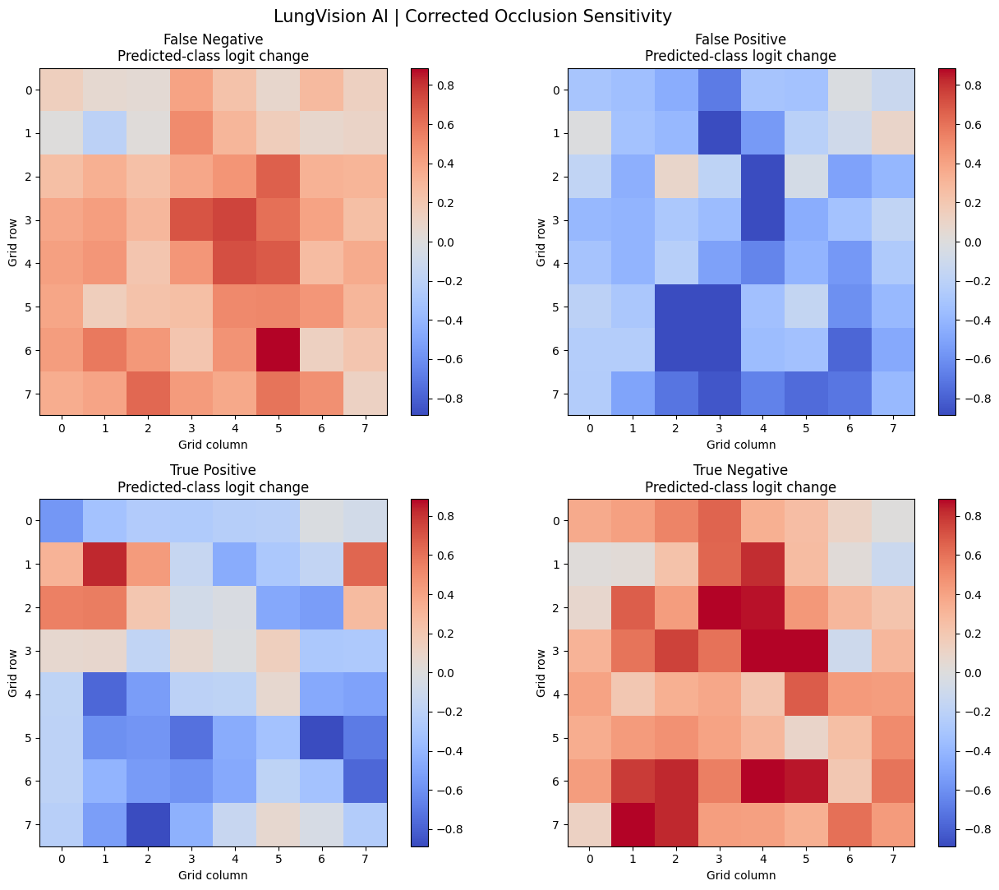


CORRECTED OCCLUSION ANALYSIS COMPLETED
Results: /kaggle/working/lungvision_results/occlusion_analysis_v2


In [30]:
# ============================================================
# CELL 19.1: CORRECTED OCCLUSION SENSITIVITY ANALYSIS
# ============================================================

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

GRID_SIZE = 8
IMAGE_SIZE = 224
SAMPLES_PER_CATEGORY = 5
OCCLUSION_BATCH_SIZE = 32
SEED = 42

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/occlusion_analysis_v2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 1. RESTORE CHECKPOINT
# ------------------------------------------------------------

MODEL_PATH = Path(
    "/kaggle/working/lungvision_models/incxr_resnet18_best.pth"
)

if not MODEL_PATH.exists():
    raise FileNotFoundError(MODEL_PATH)

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = models.resnet18(weights=None)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

print("Loaded checkpoint:", checkpoint["epoch"])


# ------------------------------------------------------------
# 2. RESTORE VALIDATION DATASET IF NECESSARY
# ------------------------------------------------------------

if "val_dataset" not in globals():

    required = [
        "val_df",
        "eval_transform",
        "INCXRDataset"
    ]

    for name in required:
        if name not in globals():
            raise RuntimeError(
                f"Missing {name}. Run the data preparation cells."
            )

    val_dataset = INCXRDataset(
        val_df,
        eval_transform
    )

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)


# ------------------------------------------------------------
# 3. REGENERATE VALIDATION PREDICTIONS
# ------------------------------------------------------------

y_true = []
y_prob = []
y_logits = []

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        logits = model(images).flatten()

        probabilities = torch.sigmoid(logits)

        y_true.extend(
            labels.numpy().astype(int)
        )

        y_prob.extend(
            probabilities.cpu().numpy()
        )

        y_logits.extend(
            logits.cpu().numpy()
        )

y_true = np.asarray(y_true)
y_prob = np.asarray(y_prob)
y_logits = np.asarray(y_logits)

y_pred = (
    y_prob >= 0.5
).astype(int)

from sklearn.metrics import accuracy_score, roc_auc_score

print("\nValidation accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("Validation AUC:",
      round(roc_auc_score(y_true, y_prob), 4))


# ------------------------------------------------------------
# 4. SELECT VALIDATION EXAMPLES
# ------------------------------------------------------------

category_conditions = {
    "False Negative": (y_true == 1) & (y_pred == 0),
    "False Positive": (y_true == 0) & (y_pred == 1),
    "True Positive": (y_true == 1) & (y_pred == 1),
    "True Negative": (y_true == 0) & (y_pred == 0)
}

rng = np.random.default_rng(SEED)

selected = {}

for category, condition in category_conditions.items():

    indices = np.where(condition)[0]

    count = min(
        SAMPLES_PER_CATEGORY,
        len(indices)
    )

    selected[category] = rng.choice(
        indices,
        size=count,
        replace=False
    ).tolist()

    print(
        category,
        "| Available:", len(indices),
        "| Selected:", count
    )


# ------------------------------------------------------------
# 5. CORRECTED OCCLUSION FUNCTION
# ------------------------------------------------------------

@torch.inference_mode()
def calculate_occlusion_map(image_tensor, target_class):

    image = image_tensor.unsqueeze(0).to(DEVICE)

    original_logit = model(image).flatten()[0].item()

    # Target the class the model actually predicted.
    # Class 1: abnormal, class 0: normal.
    original_target_score = (
        original_logit
        if target_class == 1
        else -original_logit
    )

    patch_size = IMAGE_SIZE // GRID_SIZE

    occluded_images = []
    positions = []

    # Use per-image channel means as neutral occlusion values.
    # This preserves the normalized grayscale representation.
    channel_means = image_tensor.mean(
        dim=(1, 2),
        keepdim=True
    )

    for row in range(GRID_SIZE):

        for col in range(GRID_SIZE):

            modified = image_tensor.clone()

            y1 = row * patch_size
            y2 = y1 + patch_size

            x1 = col * patch_size
            x2 = x1 + patch_size

            modified[:, y1:y2, x1:x2] = channel_means

            occluded_images.append(modified)
            positions.append((row, col))

    occluded_logits = []

    for start in range(
        0,
        len(occluded_images),
        OCCLUSION_BATCH_SIZE
    ):

        batch = torch.stack(
            occluded_images[
                start:start + OCCLUSION_BATCH_SIZE
            ]
        ).to(DEVICE)

        logits = model(batch).flatten()

        occluded_logits.extend(
            logits.cpu().numpy()
        )

    occluded_logits = np.asarray(occluded_logits)

    if target_class == 1:
        occluded_target_scores = occluded_logits
    else:
        occluded_target_scores = -occluded_logits

    # Positive: occlusion reduced the predicted class score.
    # Negative: occlusion increased the predicted class score.
    importance = (
        original_target_score - occluded_target_scores
    )

    return (
        original_logit,
        importance.reshape(GRID_SIZE, GRID_SIZE)
    )


# ------------------------------------------------------------
# 6. COMPUTE CATEGORY MAPS
# ------------------------------------------------------------

category_maps = {}
sample_results = []

print("\nRunning corrected occlusion analysis...")

for category, indices in selected.items():

    individual_maps = []

    for index in indices:

        image, actual_label = val_dataset[index]

        predicted_label = int(y_pred[index])

        original_logit, importance_map = (
            calculate_occlusion_map(
                image,
                predicted_label
            )
        )

        individual_maps.append(importance_map)

        sample_results.append({
            "category": category,
            "validation_index": index,
            "actual_label": int(actual_label),
            "predicted_label": predicted_label,
            "abnormal_probability": float(y_prob[index]),
            "original_logit": original_logit,
            "mean_occlusion_effect": float(
                importance_map.mean()
            ),
            "maximum_occlusion_effect": float(
                importance_map.max()
            )
        })

        print(
            category,
            "| Index:", index,
            "| P(Abnormal):", round(float(y_prob[index]), 4),
            "| Mean logit effect:", round(
                float(importance_map.mean()), 4
            )
        )

    category_maps[category] = np.mean(
        individual_maps,
        axis=0
    )


# ------------------------------------------------------------
# 7. COMMON COLOUR SCALE
# ------------------------------------------------------------

all_values = np.concatenate([
    heatmap.flatten()
    for heatmap in category_maps.values()
])

colour_limit = np.percentile(
    np.abs(all_values),
    95
)

colour_limit = max(
    float(colour_limit),
    1e-6
)

# ------------------------------------------------------------
# 8. VISUALIZE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 11)
)

axes = axes.flatten()

for ax, (category, heatmap) in zip(
    axes,
    category_maps.items()
):

    im = ax.imshow(
        heatmap,
        cmap="coolwarm",
        vmin=-colour_limit,
        vmax=colour_limit
    )

    ax.set_title(
        f"{category}\nPredicted-class logit change"
    )

    ax.set_xlabel("Grid column")
    ax.set_ylabel("Grid row")

    fig.colorbar(
        im,
        ax=ax,
        fraction=0.046
    )

plt.suptitle(
    "LungVision AI | Corrected Occlusion Sensitivity",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. SAVE OUTPUTS
# ------------------------------------------------------------

results_df = pd.DataFrame(sample_results)

results_df.to_csv(
    OUTPUT_DIR / "occlusion_sample_results.csv",
    index=False
)

for category, heatmap in category_maps.items():

    filename = (
        category.lower().replace(" ", "_")
        + "_occlusion_map.csv"
    )

    pd.DataFrame(
        heatmap,
        columns=[
            f"column_{i}"
            for i in range(GRID_SIZE)
        ]
    ).to_csv(
        OUTPUT_DIR / filename,
        index=False
    )

print("\nCORRECTED OCCLUSION ANALYSIS COMPLETED")
print("Results:", OUTPUT_DIR)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

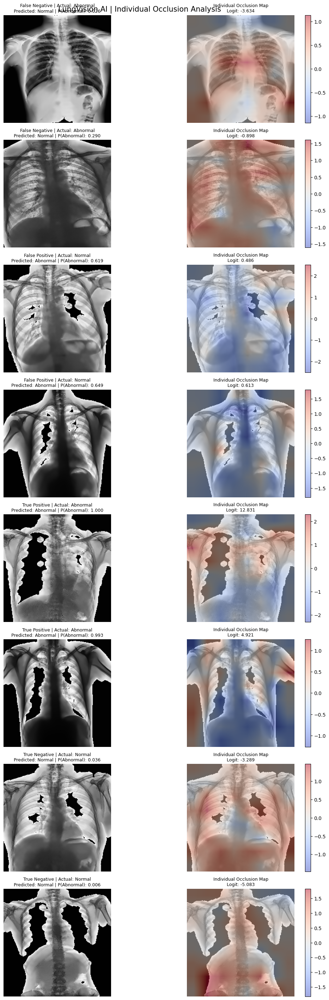


INDIVIDUAL OCCLUSION ANALYSIS COMPLETED


,category,validation_index,actual_label,predicted_label,abnormal_probability,original_logit,mean_occlusion_effect
0,False Negative,972,1,0,0.0257,-3.6337,0.2401
1,False Negative,624,1,0,0.2896,-0.8975,0.5229
2,False Positive,1211,0,1,0.6192,0.4861,-0.6139
3,False Positive,169,0,1,0.6487,0.6133,-0.3934
4,True Positive,636,1,1,1.0000,12.8310,0.0194
5,True Positive,1052,1,1,0.9928,4.9214,-0.2078
6,True Negative,682,0,0,0.0360,-3.2886,0.4688
7,True Negative,299,0,0,0.0062,-5.0828,0.3998



Saved under: /kaggle/working/lungvision_results/individual_occlusion


In [31]:
# ============================================================
# CELL 20: INDIVIDUAL OCCLUSION MAP VISUALIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from PIL import Image
from pathlib import Path

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/individual_occlusion"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify previous cell variables
required = [
    "model",
    "val_dataset",
    "selected",
    "calculate_occlusion_map",
    "y_true",
    "y_pred",
    "y_prob"
]

for name in required:
    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. Run Cell 19.1 first."
        )

categories = [
    "False Negative",
    "False Positive",
    "True Positive",
    "True Negative"
]

# Select two examples from each category
examples = []

for category in categories:

    indices = selected[category]

    for index in indices[:2]:
        examples.append((category, index))

fig, axes = plt.subplots(
    len(examples),
    2,
    figsize=(11, len(examples) * 3.6)
)

if len(examples) == 1:
    axes = np.expand_dims(axes, axis=0)

summary = []

for row, (category, index) in enumerate(examples):

    image_tensor, actual_label = val_dataset[index]

    predicted_label = int(y_pred[index])

    # Generate individual occlusion map
    original_logit, heatmap = calculate_occlusion_map(
        image_tensor,
        predicted_label
    )

    # Upsample the 8x8 heatmap to image dimensions
    heat_tensor = torch.tensor(
        heatmap,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    heat_upscaled = F.interpolate(
        heat_tensor,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )[0, 0].numpy()

    # Load the original X-ray
    image_path = val_dataset.data.iloc[index][
        "resolved_image_path"
    ]

    with Image.open(image_path) as img:
        original = np.asarray(
            img.convert("L").resize((224, 224))
        )

    limit = max(
        abs(heatmap.min()),
        abs(heatmap.max()),
        1e-6
    )

    actual_name = (
        "Abnormal" if actual_label == 1 else "Normal"
    )

    predicted_name = (
        "Abnormal" if predicted_label == 1 else "Normal"
    )

    probability = float(y_prob[index])

    # Original image
    axes[row, 0].imshow(
        original,
        cmap="gray"
    )

    axes[row, 0].set_title(
        f"{category} | Actual: {actual_name}\n"
        f"Predicted: {predicted_name} | "
        f"P(Abnormal): {probability:.3f}",
        fontsize=9
    )

    axes[row, 0].axis("off")

    # Overlay
    axes[row, 1].imshow(
        original,
        cmap="gray"
    )

    overlay = axes[row, 1].imshow(
        heat_upscaled,
        cmap="coolwarm",
        alpha=0.48,
        vmin=-limit,
        vmax=limit
    )

    axes[row, 1].set_title(
        f"Individual Occlusion Map\n"
        f"Logit: {original_logit:.3f}",
        fontsize=9
    )

    axes[row, 1].axis("off")

    fig.colorbar(
        overlay,
        ax=axes[row, 1],
        fraction=0.046
    )

    summary.append({
        "category": category,
        "validation_index": index,
        "actual_label": int(actual_label),
        "predicted_label": predicted_label,
        "abnormal_probability": probability,
        "original_logit": original_logit,
        "mean_occlusion_effect": float(heatmap.mean())
    })

    np.save(
        OUTPUT_DIR / f"sample_{index}_occlusion.npy",
        heatmap
    )

plt.suptitle(
    "LungVision AI | Individual Occlusion Analysis",
    fontsize=15
)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "individual_occlusion_overlays.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

import pandas as pd

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    OUTPUT_DIR / "individual_occlusion_summary.csv",
    index=False
)

print("\nINDIVIDUAL OCCLUSION ANALYSIS COMPLETED")
display(summary_df.round(4))

print("\nSaved under:", OUTPUT_DIR)

Starting baseline sensitivity analysis...
Processed 10/40 batches
Processed 20/40 batches
Processed 30/40 batches
Processed 40/40 batches

CATEGORY-WISE BASELINE COMPARISON


,count,original_mean_probability,constant_mean_probability,blurred_mean_probability,original_abnormal_rate,constant_abnormal_rate,blurred_abnormal_rate,mean_constant_logit_change,mean_blurred_logit_change
category,,,,,,,,,
False Negative,118,0.1847,0.6814,0.5776,0.0,1.0,0.6610,-2.8733,-2.4041
False Positive,59,0.7291,0.6745,0.6929,1.0,1.0,0.8475,0.7147,0.4731
True Negative,571,0.0679,0.6693,0.5123,0.0,1.0,0.5394,-4.6996,-3.9539
True Positive,512,0.9352,0.6608,0.7465,1.0,1.0,0.8945,4.7905,4.1695



OVERALL BASELINE ANALYSIS
Original abnormal prediction rate: 0.4532
Constant-image abnormal prediction rate: 1.0
Blurred-image abnormal prediction rate: 0.7095


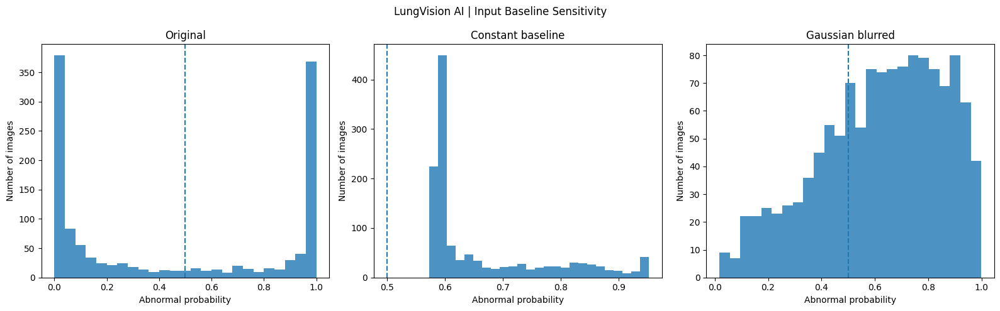


CELL 21 COMPLETED
Results saved: /kaggle/working/lungvision_results/baseline_audit


In [32]:
# ============================================================
# CELL 21: MODEL BASELINE AND BLUR SENSITIVITY AUDIT
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF

from pathlib import Path
from torch.utils.data import DataLoader

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/baseline_audit"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert "model" in globals()
assert "val_dataset" in globals()

model.eval()

# ------------------------------------------------------------
# 1. VALIDATION DATA
# ------------------------------------------------------------

loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

records = []

# ------------------------------------------------------------
# 2. EVALUATE THREE INPUT CONDITIONS
# ------------------------------------------------------------

print("Starting baseline sensitivity analysis...")

with torch.inference_mode():

    for batch_idx, (images, labels) in enumerate(loader):

        images = images.to(DEVICE)
        labels = labels.to(DEVICE).float()

        # Original image
        original_logits = model(images).flatten()

        # Constant image preserving each image's channel means
        channel_mean = images.mean(
            dim=(2, 3),
            keepdim=True
        )

        constant_images = channel_mean.expand_as(images)

        constant_logits = model(
            constant_images
        ).flatten()

        # Gaussian-blurred image
        blurred_images = TF.gaussian_blur(
            images,
            kernel_size=[31, 31],
            sigma=[5.0, 5.0]
        )

        blurred_logits = model(
            blurred_images
        ).flatten()

        original_probs = torch.sigmoid(original_logits)
        constant_probs = torch.sigmoid(constant_logits)
        blurred_probs = torch.sigmoid(blurred_logits)

        for i in range(len(labels)):

            original_logit = original_logits[i].item()
            constant_logit = constant_logits[i].item()
            blurred_logit = blurred_logits[i].item()

            original_prob = original_probs[i].item()

            records.append({
                "label": int(labels[i].item()),

                "original_logit": original_logit,
                "original_probability": original_prob,

                "constant_logit": constant_logit,
                "constant_probability": constant_probs[i].item(),

                "blurred_logit": blurred_logit,
                "blurred_probability": blurred_probs[i].item(),

                "original_prediction": int(original_logit >= 0),
                "constant_prediction": int(constant_logit >= 0),
                "blurred_prediction": int(blurred_logit >= 0),

                "constant_logit_change": (
                    original_logit - constant_logit
                ),

                "blurred_logit_change": (
                    original_logit - blurred_logit
                )
            })

        if (batch_idx + 1) % 10 == 0:
            print(
                f"Processed {batch_idx + 1}/{len(loader)} batches"
            )

# ------------------------------------------------------------
# 3. BUILD RESULTS
# ------------------------------------------------------------

result_df = pd.DataFrame(records)

result_df["category"] = np.select(
    [
        (result_df["label"] == 1) &
        (result_df["original_prediction"] == 0),

        (result_df["label"] == 0) &
        (result_df["original_prediction"] == 1),

        (result_df["label"] == 1) &
        (result_df["original_prediction"] == 1),

        (result_df["label"] == 0) &
        (result_df["original_prediction"] == 0)
    ],
    [
        "False Negative",
        "False Positive",
        "True Positive",
        "True Negative"
    ],
    default="Unknown"
)

# ------------------------------------------------------------
# 4. CATEGORY-WISE COMPARISON
# ------------------------------------------------------------

summary = result_df.groupby("category").agg(
    count=("label", "size"),

    original_mean_probability=(
        "original_probability", "mean"
    ),

    constant_mean_probability=(
        "constant_probability", "mean"
    ),

    blurred_mean_probability=(
        "blurred_probability", "mean"
    ),

    original_abnormal_rate=(
        "original_prediction", "mean"
    ),

    constant_abnormal_rate=(
        "constant_prediction", "mean"
    ),

    blurred_abnormal_rate=(
        "blurred_prediction", "mean"
    ),

    mean_constant_logit_change=(
        "constant_logit_change", "mean"
    ),

    mean_blurred_logit_change=(
        "blurred_logit_change", "mean"
    )
)

print("\nCATEGORY-WISE BASELINE COMPARISON")
display(summary.round(4))

# ------------------------------------------------------------
# 5. OVERALL RESULTS
# ------------------------------------------------------------

print("\nOVERALL BASELINE ANALYSIS")

print(
    "Original abnormal prediction rate:",
    round(result_df["original_prediction"].mean(), 4)
)

print(
    "Constant-image abnormal prediction rate:",
    round(result_df["constant_prediction"].mean(), 4)
)

print(
    "Blurred-image abnormal prediction rate:",
    round(result_df["blurred_prediction"].mean(), 4)
)

# ------------------------------------------------------------
# 6. VISUALIZATION
# ------------------------------------------------------------

plot_data = result_df[
    [
        "original_probability",
        "constant_probability",
        "blurred_probability"
    ]
]

plot_data.columns = [
    "Original",
    "Constant baseline",
    "Gaussian blurred"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, column in zip(axes, plot_data.columns):

    ax.hist(
        plot_data[column],
        bins=25,
        alpha=0.8
    )

    ax.axvline(
        0.5,
        linestyle="--"
    )

    ax.set_title(column)
    ax.set_xlabel("Abnormal probability")
    ax.set_ylabel("Number of images")

plt.suptitle(
    "LungVision AI | Input Baseline Sensitivity"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

result_df.to_csv(
    OUTPUT_DIR / "validation_baseline_predictions.csv",
    index=False
)

summary.to_csv(
    OUTPUT_DIR / "category_baseline_summary.csv"
)

print("\nCELL 21 COMPLETED")
print("Results saved:", OUTPUT_DIR)

LUNGVISION AI | MULTI-LEVEL BLUR ROBUSTNESS

Evaluating: Original
AUC: 0.9332 | Accuracy: 0.8595 | Sensitivity: 0.8127 | Specificity: 0.9063 | Abnormal rate: 0.4532

Evaluating: Mild
AUC: 0.9294 | Accuracy: 0.8524 | Sensitivity: 0.8635 | Specificity: 0.8413 | Abnormal rate: 0.5111

Evaluating: Moderate
AUC: 0.8867 | Accuracy: 0.7262 | Sensitivity: 0.9333 | Specificity: 0.5190 | Abnormal rate: 0.7071

Evaluating: Strong
AUC: 0.8210 | Accuracy: 0.6595 | Sensitivity: 0.9095 | Specificity: 0.4095 | Abnormal rate: 0.7500

Evaluating: Very Strong
AUC: 0.7391 | Accuracy: 0.6413 | Sensitivity: 0.8508 | Specificity: 0.4317 | Abnormal rate: 0.7095

FINAL BLUR ROBUSTNESS RESULTS


,condition,kernel_size,sigma,auc,auc_drop_from_original,accuracy,balanced_accuracy,sensitivity,specificity,f1,abnormal_prediction_rate
0,Original,0,0.0,0.9332,0.0000,0.8595,0.8595,0.8127,0.9063,0.8526,0.4532
1,Mild,3,0.5,0.9294,0.0038,0.8524,0.8524,0.8635,0.8413,0.8540,0.5111
2,Moderate,7,1.0,0.8867,0.0464,0.7262,0.7262,0.9333,0.5190,0.7732,0.7071
3,Strong,15,2.0,0.8210,0.1122,0.6595,0.6595,0.9095,0.4095,0.7276,0.7500
4,Very Strong,31,5.0,0.7391,0.1941,0.6413,0.6413,0.8508,0.4317,0.7034,0.7095


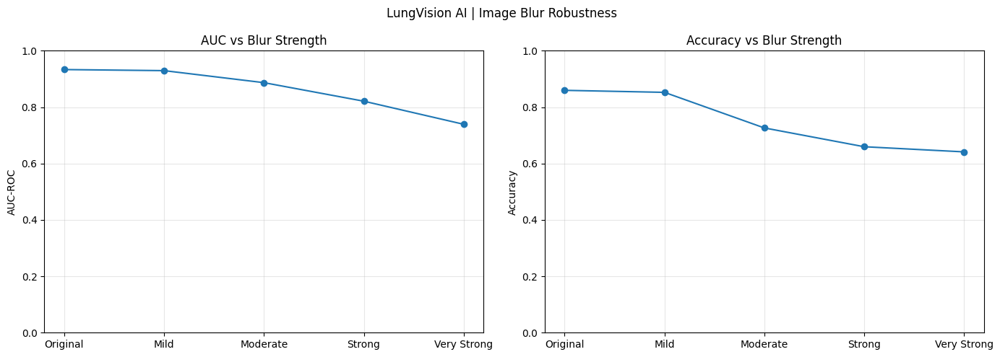

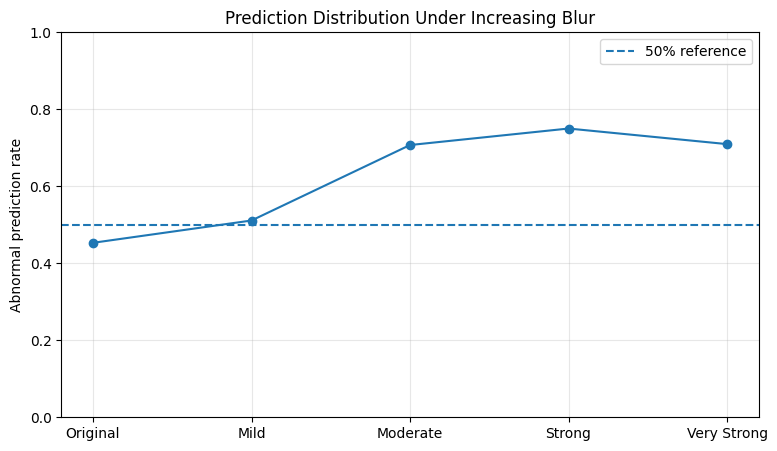


CELL 22 COMPLETED
Results saved: /kaggle/working/lungvision_results/blur_robustness


In [33]:
# ============================================================
# CELL 22: MULTI-LEVEL GAUSSIAN BLUR ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/blur_robustness"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert "model" in globals()
assert "val_dataset" in globals()

model.eval()

BATCH_SIZE = 32
THRESHOLD = 0.50

# ------------------------------------------------------------
# BLUR CONDITIONS
# ------------------------------------------------------------

BLUR_LEVELS = [
    {
        "name": "Original",
        "kernel": None,
        "sigma": None
    },
    {
        "name": "Mild",
        "kernel": 3,
        "sigma": 0.5
    },
    {
        "name": "Moderate",
        "kernel": 7,
        "sigma": 1.0
    },
    {
        "name": "Strong",
        "kernel": 15,
        "sigma": 2.0
    },
    {
        "name": "Very Strong",
        "kernel": 31,
        "sigma": 5.0
    }
]

loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# ------------------------------------------------------------
# EVALUATION FUNCTION
# ------------------------------------------------------------

def calculate_blur_metrics(y_true, probabilities):

    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities)

    predictions = (
        probabilities >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    return {
        "auc": roc_auc_score(
            y_true,
            probabilities
        ),
        "average_precision": average_precision_score(
            y_true,
            probabilities
        ),
        "accuracy": accuracy_score(
            y_true,
            predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions
        ),
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "sensitivity": (
            tp / (tp + fn)
            if tp + fn else 0
        ),
        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),
        "f1": f1_score(
            y_true,
            predictions,
            zero_division=0
        ),
        "abnormal_prediction_rate": predictions.mean()
    }


# ------------------------------------------------------------
# RUN ALL BLUR EXPERIMENTS
# ------------------------------------------------------------

all_results = []
all_probabilities = {}

print("=" * 65)
print("LUNGVISION AI | MULTI-LEVEL BLUR ROBUSTNESS")
print("=" * 65)

for condition in BLUR_LEVELS:

    name = condition["name"]

    print("\nEvaluating:", name)

    y_true = []
    y_prob = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            # Apply controlled Gaussian blur
            if condition["kernel"] is not None:

                images = TF.gaussian_blur(
                    images,
                    kernel_size=[
                        condition["kernel"],
                        condition["kernel"]
                    ],
                    sigma=[
                        condition["sigma"],
                        condition["sigma"]
                    ]
                )

            logits = model(images)

            probabilities = torch.sigmoid(logits)

            y_true.extend(
                labels.numpy().astype(int)
            )

            y_prob.extend(
                probabilities.cpu().numpy().flatten()
            )

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    metrics = calculate_blur_metrics(
        y_true,
        y_prob
    )

    metrics["condition"] = name

    metrics["kernel_size"] = (
        condition["kernel"]
        if condition["kernel"] is not None
        else 0
    )

    metrics["sigma"] = (
        condition["sigma"]
        if condition["sigma"] is not None
        else 0
    )

    all_results.append(metrics)

    all_probabilities[name] = y_prob

    print(
        f"AUC: {metrics['auc']:.4f} | "
        f"Accuracy: {metrics['accuracy']:.4f} | "
        f"Sensitivity: {metrics['sensitivity']:.4f} | "
        f"Specificity: {metrics['specificity']:.4f} | "
        f"Abnormal rate: {metrics['abnormal_prediction_rate']:.4f}"
    )


# ------------------------------------------------------------
# COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

original_auc = results_df.loc[
    results_df["condition"] == "Original",
    "auc"
].iloc[0]

results_df["auc_drop_from_original"] = (
    original_auc - results_df["auc"]
)

columns = [
    "condition",
    "kernel_size",
    "sigma",
    "auc",
    "auc_drop_from_original",
    "accuracy",
    "balanced_accuracy",
    "sensitivity",
    "specificity",
    "f1",
    "abnormal_prediction_rate"
]

print("\nFINAL BLUR ROBUSTNESS RESULTS")

display(
    results_df[columns].round(4)
)


# ------------------------------------------------------------
# PLOT AUC AND ACCURACY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

axes[0].plot(
    results_df["condition"],
    results_df["auc"],
    marker="o"
)

axes[0].set_title("AUC vs Blur Strength")
axes[0].set_ylabel("AUC-ROC")
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.3)

axes[1].plot(
    results_df["condition"],
    results_df["accuracy"],
    marker="o"
)

axes[1].set_title("Accuracy vs Blur Strength")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)

plt.suptitle(
    "LungVision AI | Image Blur Robustness"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# PLOT ABNORMAL PREDICTION RATE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["condition"],
    results_df["abnormal_prediction_rate"],
    marker="o"
)

plt.axhline(
    0.5,
    linestyle="--",
    label="50% reference"
)

plt.ylim(0, 1)

plt.ylabel("Abnormal prediction rate")
plt.title("Prediction Distribution Under Increasing Blur")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    OUTPUT_DIR / "blur_robustness_metrics.csv",
    index=False
)

probability_df = pd.DataFrame(
    all_probabilities
)

probability_df["actual_label"] = y_true

probability_df.to_csv(
    OUTPUT_DIR / "blur_robustness_predictions.csv",
    index=False
)

print("\n" + "=" * 65)
print("CELL 22 COMPLETED")
print("=" * 65)

print("Results saved:", OUTPUT_DIR)

Loaded predictions: 1260

CLASS-WISE PROBABILITY STATISTICS


,condition,actual_class,mean_probability,median_probability,std_probability,predicted_abnormal_rate,samples
0,Original,Normal,0.1298,0.0294,0.2217,0.0937,630
1,Original,Abnormal,0.7946,0.9817,0.3173,0.8127,630
2,Mild,Normal,0.1982,0.0613,0.2765,0.1587,630
3,Mild,Abnormal,0.8475,0.9934,0.2785,0.8635,630
4,Moderate,Normal,0.4883,0.4630,0.3658,0.4810,630
5,Moderate,Abnormal,0.9146,0.9968,0.2089,0.9333,630
6,Strong,Normal,0.5745,0.6437,0.3540,0.5905,630
7,Strong,Abnormal,0.8911,0.9873,0.2130,0.9095,630
8,Very Strong,Normal,0.5292,0.5455,0.2206,0.5683,630
9,Very Strong,Abnormal,0.7149,0.7577,0.2033,0.8508,630


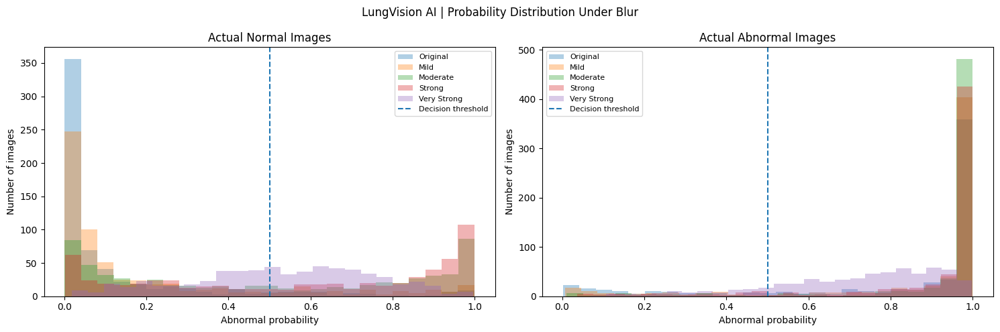


PROBABILITY SHIFT FROM ORIGINAL


,condition,normal_probability_change,abnormal_probability_change
0,Original,0.0000,0.0000
1,Mild,0.0684,0.0529
2,Moderate,0.3585,0.1200
3,Strong,0.4447,0.0965
4,Very Strong,0.3994,-0.0797



CLASS SEPARATION


,condition,normal_mean_probability,abnormal_mean_probability,class_separation
0,Original,0.1298,0.7946,0.6648
1,Mild,0.1982,0.8475,0.6493
2,Moderate,0.4883,0.9146,0.4263
3,Strong,0.5745,0.8911,0.3166
4,Very Strong,0.5292,0.7149,0.1857


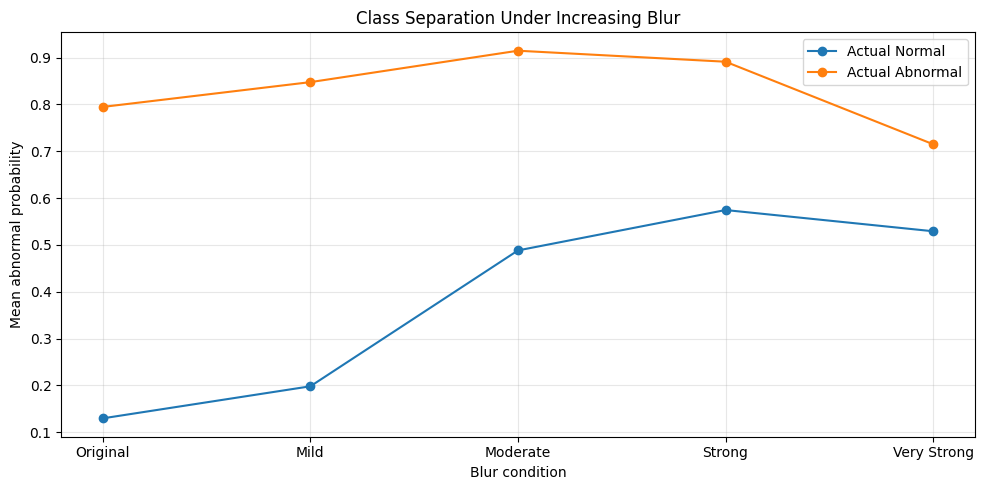


CELL 23 COMPLETED
Results saved under:
/kaggle/working/lungvision_results/probability_shift


In [34]:
# ============================================================
# CELL 23: PROBABILITY DISTRIBUTION SHIFT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

INPUT_PATH = Path(
    "/kaggle/working/lungvision_results/"
    "blur_robustness/blur_robustness_predictions.csv"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "probability_shift"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLD = 0.50

if not INPUT_PATH.exists():
    raise FileNotFoundError(INPUT_PATH)

df = pd.read_csv(INPUT_PATH)

conditions = [
    "Original",
    "Mild",
    "Moderate",
    "Strong",
    "Very Strong"
]

required_columns = conditions + ["actual_label"]

missing = [
    col for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing columns: {missing}"
    )

print("Loaded predictions:", len(df))


# ------------------------------------------------------------
# 1. CLASS-WISE PROBABILITY STATISTICS
# ------------------------------------------------------------

statistics = []

for condition in conditions:

    for label, class_name in [
        (0, "Normal"),
        (1, "Abnormal")
    ]:

        subset = df[
            df["actual_label"] == label
        ]

        probabilities = subset[condition].values

        predictions = (
            probabilities >= THRESHOLD
        ).astype(int)

        statistics.append({
            "condition": condition,
            "actual_class": class_name,
            "mean_probability": probabilities.mean(),
            "median_probability": np.median(probabilities),
            "std_probability": probabilities.std(),
            "predicted_abnormal_rate": predictions.mean(),
            "samples": len(probabilities)
        })

stats_df = pd.DataFrame(statistics)

print("\nCLASS-WISE PROBABILITY STATISTICS")

display(
    stats_df.round(4)
)

stats_df.to_csv(
    OUTPUT_DIR / "classwise_probability_statistics.csv",
    index=False
)


# ------------------------------------------------------------
# 2. PLOT PROBABILITY DISTRIBUTIONS BY TRUE CLASS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

for ax, label, class_name in [
    (axes[0], 0, "Normal"),
    (axes[1], 1, "Abnormal")
]:

    subset = df[
        df["actual_label"] == label
    ]

    for condition in conditions:

        ax.hist(
            subset[condition],
            bins=25,
            alpha=0.35,
            label=condition
        )

    ax.axvline(
        THRESHOLD,
        linestyle="--",
        label="Decision threshold"
    )

    ax.set_title(
        f"Actual {class_name} Images"
    )

    ax.set_xlabel("Abnormal probability")
    ax.set_ylabel("Number of images")

    ax.legend(fontsize=8)

plt.suptitle(
    "LungVision AI | Probability Distribution Under Blur"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. CHANGE IN MEAN PROBABILITY
# ------------------------------------------------------------

normal_shift = []
abnormal_shift = []

original_normal = df.loc[
    df["actual_label"] == 0,
    "Original"
].mean()

original_abnormal = df.loc[
    df["actual_label"] == 1,
    "Original"
].mean()

for condition in conditions:

    current_normal = df.loc[
        df["actual_label"] == 0,
        condition
    ].mean()

    current_abnormal = df.loc[
        df["actual_label"] == 1,
        condition
    ].mean()

    normal_shift.append(
        current_normal - original_normal
    )

    abnormal_shift.append(
        current_abnormal - original_abnormal
    )

shift_df = pd.DataFrame({
    "condition": conditions,
    "normal_probability_change": normal_shift,
    "abnormal_probability_change": abnormal_shift
})

print("\nPROBABILITY SHIFT FROM ORIGINAL")

display(
    shift_df.round(4)
)

shift_df.to_csv(
    OUTPUT_DIR / "probability_shift_from_original.csv",
    index=False
)


# ------------------------------------------------------------
# 4. CLASS SEPARATION
# ------------------------------------------------------------

separation = []

for condition in conditions:

    normal_mean = df.loc[
        df["actual_label"] == 0,
        condition
    ].mean()

    abnormal_mean = df.loc[
        df["actual_label"] == 1,
        condition
    ].mean()

    separation.append({
        "condition": condition,
        "normal_mean_probability": normal_mean,
        "abnormal_mean_probability": abnormal_mean,
        "class_separation": abnormal_mean - normal_mean
    })

separation_df = pd.DataFrame(separation)

print("\nCLASS SEPARATION")

display(
    separation_df.round(4)
)

separation_df.to_csv(
    OUTPUT_DIR / "class_separation.csv",
    index=False
)


# ------------------------------------------------------------
# 5. VISUALIZE CLASS SEPARATION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    separation_df["condition"],
    separation_df["normal_mean_probability"],
    marker="o",
    label="Actual Normal"
)

plt.plot(
    separation_df["condition"],
    separation_df["abnormal_mean_probability"],
    marker="o",
    label="Actual Abnormal"
)

plt.xlabel("Blur condition")
plt.ylabel("Mean abnormal probability")

plt.title(
    "Class Separation Under Increasing Blur"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. SUMMARY
# ------------------------------------------------------------

print("\nCELL 23 COMPLETED")

print("Results saved under:")
print(OUTPUT_DIR)

LUNGVISION AI | BLUR-AUGMENTED RESNET18
Device: cuda
Training images: 10080
Validation images: 1260

Original checkpoint loaded.
Starting from epoch: 4
Original best validation AUC: 0.9332060972537164

Evaluating original checkpoint...
Original: AUC=0.9332, Accuracy=0.8595
Mild: AUC=0.9294, Accuracy=0.8524
Moderate: AUC=0.8867, Accuracy=0.7262
Strong: AUC=0.8210, Accuracy=0.6595

STARTING BLUR-AUGMENTED FINE-TUNING

Epoch 1/6
Train loss: 0.1123
Validation AUC: 0.9381
Validation accuracy: 0.8683
Sensitivity: 0.8238
Specificity: 0.9127
New best augmented checkpoint saved.

Epoch 2/6
Train loss: 0.0844
Validation AUC: 0.9378
Validation accuracy: 0.8651
Sensitivity: 0.8365
Specificity: 0.8937
No validation AUC improvement.

Epoch 3/6
Train loss: 0.0713
Validation AUC: 0.9373
Validation accuracy: 0.8651
Sensitivity: 0.8508
Specificity: 0.8794
No validation AUC improvement.

Early stopping activated.

Best augmented epoch: 1
Best augmented validation AUC: 0.9381

Evaluating augmented model..

,model,condition,auc,accuracy,sensitivity,specificity,f1,abnormal_prediction_rate
0,Original ResNet18,Original,0.9332,0.8595,0.8127,0.9063,0.8526,0.4532
1,Original ResNet18,Mild,0.9294,0.8524,0.8635,0.8413,0.8540,0.5111
2,Original ResNet18,Moderate,0.8867,0.7262,0.9333,0.5190,0.7732,0.7071
3,Original ResNet18,Strong,0.8210,0.6595,0.9095,0.4095,0.7276,0.7500
4,Blur-Augmented ResNet18,Original,0.9381,0.8683,0.8238,0.9127,0.8621,0.4556
5,Blur-Augmented ResNet18,Mild,0.9360,0.8651,0.8222,0.9079,0.8590,0.4571
6,Blur-Augmented ResNet18,Moderate,0.9147,0.8556,0.8127,0.8984,0.8491,0.4571
7,Blur-Augmented ResNet18,Strong,0.8637,0.7825,0.7111,0.8540,0.7658,0.4286


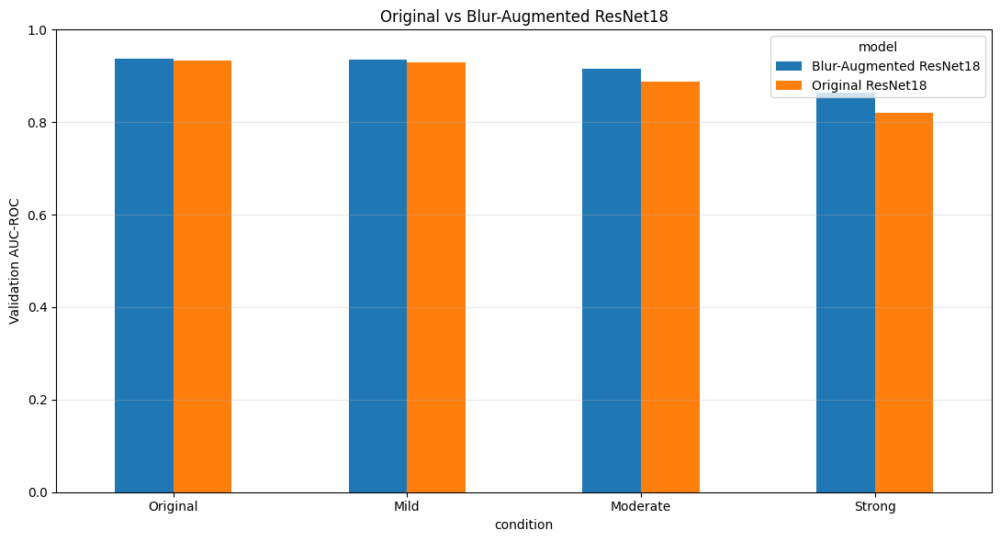


CELL 24 COMPLETED
Original model preserved:
/kaggle/working/lungvision_models/incxr_resnet18_best.pth

New augmented model:
/kaggle/working/lungvision_models/blur_augmented/incxr_resnet18_bluraug_best.pth

Comparison:
/kaggle/working/lungvision_models/blur_augmented/bluraug_model_comparison.csv


In [35]:
# ============================================================
# CELL 24: BLUR-AUGMENTED RESNET18 FINE-TUNING
# ============================================================

import os
import gc
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from torchvision import models, transforms
from torchvision.transforms import functional as TF

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 6
PATIENCE = 2

BLUR_PROBABILITY = 0.35
LEARNING_RATE = 0.00001

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MODEL_PATH = Path(
    "/kaggle/working/lungvision_models/incxr_resnet18_best.pth"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_models/blur_augmented"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert MODEL_PATH.exists()
assert "train_df" in globals()
assert "val_df" in globals()

print("=" * 65)
print("LUNGVISION AI | BLUR-AUGMENTED RESNET18")
print("=" * 65)

print("Device:", DEVICE)


# ------------------------------------------------------------
# 2. TRANSFORMS
# ------------------------------------------------------------

normalization = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

resize = transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE)
)

to_tensor = transforms.ToTensor()

rotation = transforms.RandomRotation(
    degrees=5
)


# ------------------------------------------------------------
# 3. CUSTOM AUGMENTED DATASET
# ------------------------------------------------------------

class BlurAugmentedINCXRDataset(Dataset):

    def __init__(self, dataframe, augment=False):

        self.data = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image_path = row["resolved_image_path"]
        label = int(row["label"])

        with Image.open(image_path) as image:

            image = image.convert("RGB")
            image = resize(image)

            if self.augment:
                image = rotation(image)

            image = to_tensor(image)

        # Apply blur BEFORE normalization
        # Only to a portion of training images
        if (
            self.augment
            and random.random() < BLUR_PROBABILITY
        ):

            kernel_size = random.choice([3, 5])
            sigma = random.uniform(0.3, 0.8)

            image = TF.gaussian_blur(
                image,
                kernel_size=[
                    kernel_size,
                    kernel_size
                ],
                sigma=[sigma, sigma]
            )

        image = normalization(image)

        return (
            image,
            torch.tensor(label, dtype=torch.float32)
        )


# ------------------------------------------------------------
# 4. CREATE DATASETS AND LOADERS
# ------------------------------------------------------------

train_aug_dataset = BlurAugmentedINCXRDataset(
    train_df,
    augment=True
)

val_clean_dataset = BlurAugmentedINCXRDataset(
    val_df,
    augment=False
)

train_loader_aug = DataLoader(
    train_aug_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader_clean = DataLoader(
    val_clean_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_aug_dataset))
print("Validation images:", len(val_clean_dataset))


# ------------------------------------------------------------
# 5. LOAD ORIGINAL BEST MODEL
# ------------------------------------------------------------

checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = models.resnet18(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    1
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)

print("\nOriginal checkpoint loaded.")
print("Starting from epoch:", checkpoint["epoch"])
print("Original best validation AUC:", checkpoint["best_val_auc"])


# ------------------------------------------------------------
# 6. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_model(model, loader, blur_kernel=None, blur_sigma=None):

    model.eval()

    labels_all = []
    probabilities_all = []

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            # Optional validation stress transformation
            if blur_kernel is not None:

                images = TF.gaussian_blur(
                    images,
                    kernel_size=[
                        blur_kernel,
                        blur_kernel
                    ],
                    sigma=[
                        blur_sigma,
                        blur_sigma
                    ]
                )

            logits = model(images).flatten()

            probabilities = torch.sigmoid(logits)

            labels_all.extend(
                labels.numpy().astype(int)
            )

            probabilities_all.extend(
                probabilities.cpu().numpy()
            )

    y_true_local = np.asarray(labels_all)
    y_prob_local = np.asarray(probabilities_all)

    y_pred_local = (
        y_prob_local >= 0.5
    ).astype(int)

    cm = confusion_matrix(
        y_true_local,
        y_pred_local,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    results = {
        "auc": roc_auc_score(
            y_true_local,
            y_prob_local
        ),

        "accuracy": accuracy_score(
            y_true_local,
            y_pred_local
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true_local,
            y_pred_local
        ),

        "precision": precision_score(
            y_true_local,
            y_pred_local,
            zero_division=0
        ),

        "sensitivity": (
            tp / (tp + fn)
            if tp + fn else 0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true_local,
            y_pred_local,
            zero_division=0
        ),

        "abnormal_prediction_rate": float(
            y_pred_local.mean()
        )
    }

    return results, y_true_local, y_prob_local


# ------------------------------------------------------------
# 7. ORIGINAL MODEL BASELINE
# ------------------------------------------------------------

baseline_conditions = [
    ("Original", None, None),
    ("Mild", 3, 0.5),
    ("Moderate", 7, 1.0),
    ("Strong", 15, 2.0)
]

baseline_results = []

print("\nEvaluating original checkpoint...")

for name, kernel, sigma in baseline_conditions:

    metrics, _, _ = evaluate_model(
        model,
        val_loader_clean,
        kernel,
        sigma
    )

    metrics["model"] = "Original ResNet18"
    metrics["condition"] = name

    baseline_results.append(metrics)

    print(
        f"{name}: AUC={metrics['auc']:.4f}, "
        f"Accuracy={metrics['accuracy']:.4f}"
    )


# ------------------------------------------------------------
# 8. LOSS AND OPTIMIZER
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.0001
)


# ------------------------------------------------------------
# 9. TRAINING FUNCTION
# ------------------------------------------------------------

def train_one_epoch():

    model.train()

    total_loss = 0.0

    for images, labels in train_loader_aug:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        ).unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item() * images.size(0)
        )

    return total_loss / len(train_aug_dataset)


# ------------------------------------------------------------
# 10. FINE-TUNING
# ------------------------------------------------------------

BEST_AUG_MODEL = (
    OUTPUT_DIR / "incxr_resnet18_bluraug_best.pth"
)

history = []

best_auc = -1.0
best_epoch = 0
bad_epochs = 0

print("\n" + "=" * 65)
print("STARTING BLUR-AUGMENTED FINE-TUNING")
print("=" * 65)

for epoch in range(EPOCHS):

    train_loss = train_one_epoch()

    val_metrics, _, _ = evaluate_model(
        model,
        val_loader_clean
    )

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_auc": val_metrics["auc"],
        "val_accuracy": val_metrics["accuracy"],
        "val_sensitivity": val_metrics["sensitivity"],
        "val_specificity": val_metrics["specificity"],
        "val_f1": val_metrics["f1"]
    }

    history.append(row)

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    print("Train loss:", round(train_loss, 4))

    print(
        "Validation AUC:",
        round(val_metrics["auc"], 4)
    )

    print(
        "Validation accuracy:",
        round(val_metrics["accuracy"], 4)
    )

    print(
        "Sensitivity:",
        round(val_metrics["sensitivity"], 4)
    )

    print(
        "Specificity:",
        round(val_metrics["specificity"], 4)
    )

    if val_metrics["auc"] > best_auc:

        best_auc = val_metrics["auc"]
        best_epoch = epoch + 1
        bad_epochs = 0

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_auc": best_auc,
            "augmentation": {
                "blur_probability": BLUR_PROBABILITY,
                "blur_sigma_min": 0.3,
                "blur_sigma_max": 0.8,
                "blur_kernels": [3, 5]
            }
        }, BEST_AUG_MODEL)

        print("New best augmented checkpoint saved.")

    else:

        bad_epochs += 1
        print("No validation AUC improvement.")

    if bad_epochs >= PATIENCE:

        print("\nEarly stopping activated.")
        break


# ------------------------------------------------------------
# 11. SAVE TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "bluraug_training_history.csv",
    index=False
)

# ------------------------------------------------------------
# 12. LOAD BEST AUGMENTED CHECKPOINT
# ------------------------------------------------------------

best_checkpoint = torch.load(
    BEST_AUG_MODEL,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model.eval()

print("\nBest augmented epoch:", best_epoch)
print("Best augmented validation AUC:", round(best_auc, 4))


# ------------------------------------------------------------
# 13. AUGMENTED MODEL ROBUSTNESS EVALUATION
# ------------------------------------------------------------

augmented_results = []

print("\nEvaluating augmented model...")

for name, kernel, sigma in baseline_conditions:

    metrics, _, _ = evaluate_model(
        model,
        val_loader_clean,
        kernel,
        sigma
    )

    metrics["model"] = "Blur-Augmented ResNet18"
    metrics["condition"] = name

    augmented_results.append(metrics)

    print(
        f"{name}: AUC={metrics['auc']:.4f}, "
        f"Accuracy={metrics['accuracy']:.4f}"
    )


# ------------------------------------------------------------
# 14. FINAL COMPARISON
# ------------------------------------------------------------

comparison = pd.DataFrame(
    baseline_results + augmented_results
)

comparison = comparison[[
    "model",
    "condition",
    "auc",
    "accuracy",
    "sensitivity",
    "specificity",
    "f1",
    "abnormal_prediction_rate"
]]

comparison.to_csv(
    OUTPUT_DIR / "bluraug_model_comparison.csv",
    index=False
)

print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON")
print("=" * 65)

display(
    comparison.round(4)
)


# ------------------------------------------------------------
# 15. VISUALIZE AUC COMPARISON
# ------------------------------------------------------------

pivot = comparison.pivot(
    index="condition",
    columns="model",
    values="auc"
)

condition_order = [
    "Original",
    "Mild",
    "Moderate",
    "Strong"
]

pivot = pivot.reindex(condition_order)

pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Original vs Blur-Augmented ResNet18"
)

plt.ylabel("Validation AUC-ROC")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 16. COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 24 COMPLETED")
print("=" * 65)

print("Original model preserved:")
print(MODEL_PATH)

print("\nNew augmented model:")
print(BEST_AUG_MODEL)

print("\nComparison:")
print(
    OUTPUT_DIR / "bluraug_model_comparison.csv"
)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Original checkpoint epoch: 4
Augmented checkpoint epoch: 1

Original ResNet18

Evaluating: Original
AUC: 0.9348 | Accuracy: 0.8611 | Sensitivity: 0.8333 | Specificity: 0.8889

Evaluating: Mild
AUC: 0.9295 | Accuracy: 0.8571 | Sensitivity: 0.8810 | Specificity: 0.8333

Evaluating: Moderate
AUC: 0.8849 | Accuracy: 0.7222 | Sensitivity: 0.9349 | Specificity: 0.5095

Evaluating: Strong
AUC: 0.8113 | Accuracy: 0.6746 | Sensitivity: 0.9333 | Specificity: 0.4159

Blur-Augmented ResNet18

Evaluating: Original
AUC: 0.9436 | Accuracy: 0.8627 | Sensitivity: 0.8270 | Specificity: 0.8984

Evaluating: Mild
AUC: 0.9430 | Accuracy: 0.8611 | Sensitivity: 0.8206 | Specificity: 0.9016

Evaluating: Moderate
AUC: 0.9280 | Accuracy: 0.8452 | Sensitivity: 0.8095 | Specificity: 0.8810

Evaluating: Strong
AUC: 0.8717 | Accuracy: 0.7762 | Sensitivity: 0.6921 | Specificity: 0.8603

FINAL TEST COMPARISON


,model,condition,auc,average_precision,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1,abnormal_prediction_rate,tn,fp,fn,tp
0,Original ResNet18,Original,0.9348,0.9411,0.8611,0.8611,0.8333,0.8889,0.8824,0.8571,0.4722,560,70,105,525
1,Original ResNet18,Mild,0.9295,0.9354,0.8571,0.8571,0.8810,0.8333,0.8409,0.8605,0.5238,525,105,75,555
2,Original ResNet18,Moderate,0.8849,0.8927,0.7222,0.7222,0.9349,0.5095,0.6559,0.7709,0.7127,321,309,41,589
3,Original ResNet18,Strong,0.8113,0.8149,0.6746,0.6746,0.9333,0.4159,0.6151,0.7415,0.7587,262,368,42,588
4,Blur-Augmented ResNet18,Original,0.9436,0.9500,0.8627,0.8627,0.8270,0.8984,0.8906,0.8576,0.4643,566,64,109,521
5,Blur-Augmented ResNet18,Mild,0.9430,0.9484,0.8611,0.8611,0.8206,0.9016,0.8929,0.8553,0.4595,568,62,113,517
6,Blur-Augmented ResNet18,Moderate,0.9280,0.9329,0.8452,0.8452,0.8095,0.8810,0.8718,0.8395,0.4643,555,75,120,510
7,Blur-Augmented ResNet18,Strong,0.8717,0.8812,0.7762,0.7762,0.6921,0.8603,0.8321,0.7556,0.4159,542,88,194,436


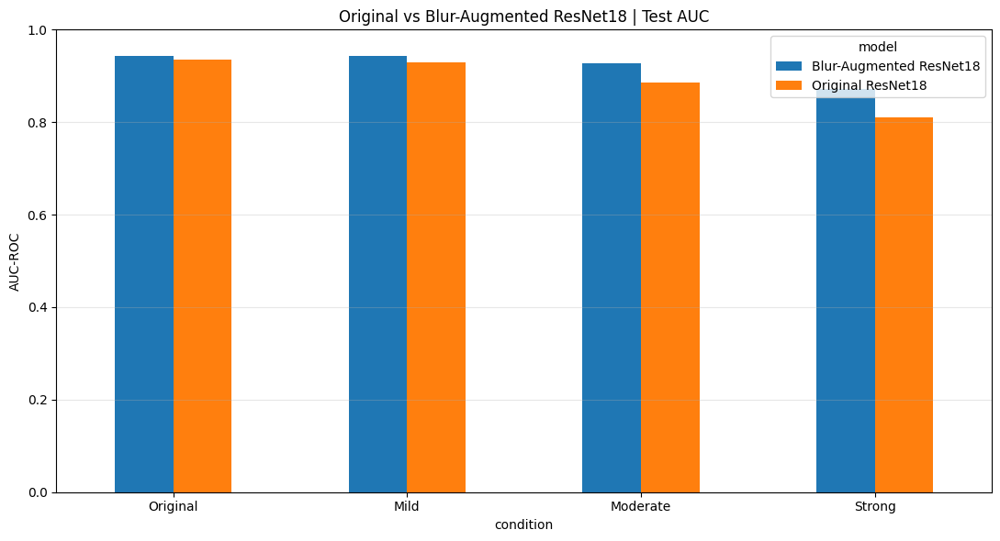


CELL 25 COMPLETED
Comparison: /kaggle/working/lungvision_results/final_model_comparison/test_model_comparison.csv
Probabilities: /kaggle/working/lungvision_results/final_model_comparison/test_model_probabilities.csv


In [36]:
# ============================================================
# CELL 25: ORIGINAL VS BLUR-AUGMENTED RESNET18
# TEST COMPARISON
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import models
from torchvision.transforms import functional as TF
from torch.utils.data import DataLoader

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

ORIGINAL_PATH = Path(
    "/kaggle/working/lungvision_models/"
    "incxr_resnet18_best.pth"
)

AUGMENTED_PATH = Path(
    "/kaggle/working/lungvision_models/"
    "blur_augmented/incxr_resnet18_bluraug_best.pth"
)

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "final_model_comparison"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert ORIGINAL_PATH.exists(), ORIGINAL_PATH
assert AUGMENTED_PATH.exists(), AUGMENTED_PATH
assert "test_dataset" in globals()

BATCH_SIZE = 32
THRESHOLD = 0.50

# Same blur settings used in Cell 22 and Cell 24
CONDITIONS = [
    ("Original", None, None),
    ("Mild", 3, 0.5),
    ("Moderate", 7, 1.0),
    ("Strong", 15, 2.0)
]

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

def load_resnet18(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    network = models.resnet18(
        weights=None
    )

    network.fc = nn.Linear(
        network.fc.in_features,
        1
    )

    network.load_state_dict(
        checkpoint["model_state_dict"]
    )

    network = network.to(DEVICE)
    network.eval()

    return network, checkpoint


original_model, original_checkpoint = load_resnet18(
    ORIGINAL_PATH
)

augmented_model, augmented_checkpoint = load_resnet18(
    AUGMENTED_PATH
)

print("Original checkpoint epoch:",
      original_checkpoint["epoch"])

print("Augmented checkpoint epoch:",
      augmented_checkpoint["epoch"])


# ------------------------------------------------------------
# EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_checkpoint(network, condition_name, kernel, sigma):

    network.eval()

    labels_all = []
    probs_all = []

    with torch.inference_mode():

        for images, labels in test_loader:

            images = images.to(DEVICE)

            # Apply identical transformations to both models
            if kernel is not None:

                images = TF.gaussian_blur(
                    images,
                    kernel_size=[kernel, kernel],
                    sigma=[sigma, sigma]
                )

            logits = network(images).flatten()

            probabilities = torch.sigmoid(logits)

            labels_all.extend(
                labels.numpy().astype(int)
            )

            probs_all.extend(
                probabilities.cpu().numpy()
            )

    y_true_local = np.asarray(
        labels_all,
        dtype=int
    )

    y_prob_local = np.asarray(
        probs_all,
        dtype=float
    )

    y_pred_local = (
        y_prob_local >= THRESHOLD
    ).astype(int)

    cm = confusion_matrix(
        y_true_local,
        y_pred_local,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "condition": condition_name,

        "auc": roc_auc_score(
            y_true_local,
            y_prob_local
        ),

        "average_precision": average_precision_score(
            y_true_local,
            y_prob_local
        ),

        "accuracy": accuracy_score(
            y_true_local,
            y_pred_local
        ),

        "balanced_accuracy": balanced_accuracy_score(
            y_true_local,
            y_pred_local
        ),

        "precision": precision_score(
            y_true_local,
            y_pred_local,
            zero_division=0
        ),

        "sensitivity": (
            tp / (tp + fn)
            if tp + fn else 0
        ),

        "specificity": (
            tn / (tn + fp)
            if tn + fp else 0
        ),

        "f1": f1_score(
            y_true_local,
            y_pred_local,
            zero_division=0
        ),

        "abnormal_prediction_rate": y_pred_local.mean(),

        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp
    }

    return metrics, y_true_local, y_prob_local


# ------------------------------------------------------------
# EVALUATE BOTH MODELS
# ------------------------------------------------------------

all_results = []
prediction_data = {}

models_to_evaluate = {
    "Original ResNet18": original_model,
    "Blur-Augmented ResNet18": augmented_model
}

for model_name, network in models_to_evaluate.items():

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    for condition_name, kernel, sigma in CONDITIONS:

        print("\nEvaluating:", condition_name)

        metrics, y_true, y_prob = evaluate_checkpoint(
            network,
            condition_name,
            kernel,
            sigma
        )

        metrics["model"] = model_name

        all_results.append(metrics)

        prediction_data[
            f"{model_name}_{condition_name}"
        ] = y_prob

        print(
            f"AUC: {metrics['auc']:.4f} | "
            f"Accuracy: {metrics['accuracy']:.4f} | "
            f"Sensitivity: {metrics['sensitivity']:.4f} | "
            f"Specificity: {metrics['specificity']:.4f}"
        )


# ------------------------------------------------------------
# BUILD COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

columns = [
    "model",
    "condition",
    "auc",
    "average_precision",
    "accuracy",
    "balanced_accuracy",
    "sensitivity",
    "specificity",
    "precision",
    "f1",
    "abnormal_prediction_rate",
    "tn",
    "fp",
    "fn",
    "tp"
]

results_df = results_df[columns]

print("\nFINAL TEST COMPARISON")

display(
    results_df.round(4)
)

results_df.to_csv(
    OUTPUT_DIR / "test_model_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# SAVE INDIVIDUAL PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame(
    prediction_data
)

prediction_df["actual_label"] = (
    test_df["label"].to_numpy().astype(int)
)

prediction_df.to_csv(
    OUTPUT_DIR / "test_model_probabilities.csv",
    index=False
)


# ------------------------------------------------------------
# PLOT AUC COMPARISON
# ------------------------------------------------------------

auc_pivot = results_df.pivot(
    index="condition",
    columns="model",
    values="auc"
)

auc_pivot = auc_pivot.reindex([
    "Original",
    "Mild",
    "Moderate",
    "Strong"
])

auc_pivot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Original vs Blur-Augmented ResNet18 | Test AUC"
)

plt.ylabel("AUC-ROC")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "test_auc_comparison.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# FINAL EXPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 25 COMPLETED")
print("=" * 65)

print("Comparison:", OUTPUT_DIR / "test_model_comparison.csv")
print("Probabilities:", OUTPUT_DIR / "test_model_probabilities.csv")

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

LUNGVISION AI | SENSITIVITY-FIRST CALIBRATION

Evaluating: Original ResNet18

Model: Original ResNet18
Validation AUC: 0.9332
Default sensitivity: 0.8127
Default specificity: 0.9063

Selected threshold: 0.1765
Calibrated sensitivity: 0.9
Calibrated specificity: 0.7952
False negatives: 63
False positives: 129

Evaluating: Blur-Augmented ResNet18

Model: Blur-Augmented ResNet18
Validation AUC: 0.9381
Default sensitivity: 0.8238
Default specificity: 0.9111

Selected threshold: 0.1887
Calibrated sensitivity: 0.9
Calibrated specificity: 0.8222
False negatives: 63
False positives: 112

THRESHOLD CALIBRATION COMPARISON


,model,validation_auc,default_threshold,calibrated_threshold,sensitivity_at_0.5,specificity_at_0.5,calibrated_sensitivity,calibrated_specificity,calibrated_precision,calibrated_f1,calibrated_accuracy,calibrated_abnormal_rate,tn,fp,fn,tp
0,Original ResNet18,0.9332,0.5,0.1765,0.8127,0.9063,0.9,0.7952,0.8147,0.8552,0.8476,0.5524,501,129,63,567
1,Blur-Augmented ResNet18,0.9381,0.5,0.1887,0.8238,0.9111,0.9,0.8222,0.8351,0.8663,0.8611,0.5389,518,112,63,567


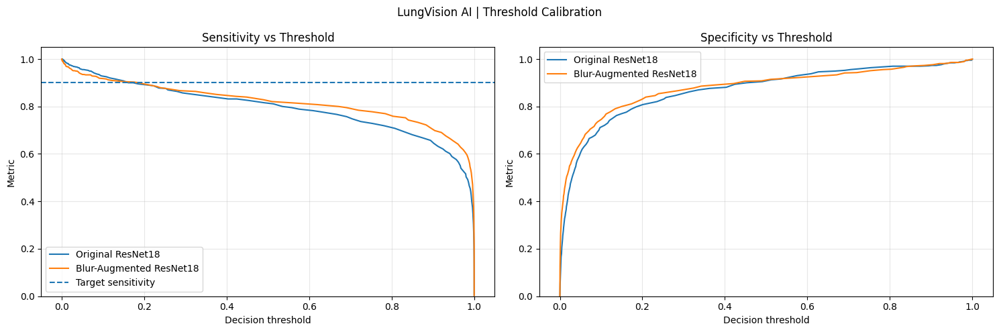


CELL 26 COMPLETED
Target sensitivity: 0.9
Results directory: /kaggle/working/lungvision_results/threshold_calibration

Selected thresholds:
Original ResNet18 -> 0.1765
Blur-Augmented ResNet18 -> 0.1887


In [37]:
# ============================================================
# CELL 26: SENSITIVITY-FIRST THRESHOLD CALIBRATION
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

TARGET_SENSITIVITY = 0.90
BATCH_SIZE = 32

CHECKPOINTS = {
    "Original ResNet18": Path(
        "/kaggle/working/lungvision_models/"
        "incxr_resnet18_best.pth"
    ),

    "Blur-Augmented ResNet18": Path(
        "/kaggle/working/lungvision_models/"
        "blur_augmented/incxr_resnet18_bluraug_best.pth"
    )
}

OUTPUT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "threshold_calibration"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# RESTORE VALIDATION DATASET IF REQUIRED
# ------------------------------------------------------------

if "val_dataset" not in globals():

    val_dataset = INCXRDataset(
        val_df,
        eval_transform
    )

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

def load_model(checkpoint_path):

    if not checkpoint_path.exists():
        raise FileNotFoundError(checkpoint_path)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    network = models.resnet18(weights=None)

    network.fc = nn.Linear(
        network.fc.in_features,
        1
    )

    network.load_state_dict(
        checkpoint["model_state_dict"]
    )

    network = network.to(DEVICE)
    network.eval()

    return network


# ------------------------------------------------------------
# VALIDATION INFERENCE
# ------------------------------------------------------------

def get_validation_predictions(network):

    labels = []
    probabilities = []

    with torch.inference_mode():

        for images, batch_labels in val_loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            logits = network(images).flatten()

            probs = torch.sigmoid(logits)

            labels.extend(
                batch_labels.numpy().astype(int)
            )

            probabilities.extend(
                probs.cpu().numpy()
            )

    return (
        np.asarray(labels, dtype=int),
        np.asarray(probabilities, dtype=float)
    )


# ------------------------------------------------------------
# THRESHOLD METRICS
# ------------------------------------------------------------

def calculate_threshold_metrics(y_true, y_prob, threshold):

    predictions = (
        y_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,
        "sensitivity": tp / (tp + fn) if tp + fn else 0,
        "specificity": tn / (tn + fp) if tn + fp else 0,
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "accuracy": accuracy_score(
            y_true, predictions
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "abnormal_prediction_rate": predictions.mean()
    }


# ------------------------------------------------------------
# CALIBRATE THRESHOLD
# ------------------------------------------------------------

model_results = {}
summary_results = []
threshold_tables = []

print("=" * 65)
print("LUNGVISION AI | SENSITIVITY-FIRST CALIBRATION")
print("=" * 65)

for model_name, checkpoint_path in CHECKPOINTS.items():

    print("\nEvaluating:", model_name)

    network = load_model(checkpoint_path)

    y_true, y_prob = get_validation_predictions(network)

    auc = roc_auc_score(y_true, y_prob)

    # Test all unique prediction scores.
    # Threshold 0 guarantees a feasible 90% sensitivity target.
    thresholds = np.unique(
        np.concatenate([
            np.array([0.0]),
            y_prob,
            np.array([1.0])
        ])
    )

    threshold_rows = []

    for threshold in thresholds:

        metrics = calculate_threshold_metrics(
            y_true,
            y_prob,
            float(threshold)
        )

        metrics["model"] = model_name
        metrics["auc"] = auc

        threshold_rows.append(metrics)

    threshold_df = pd.DataFrame(threshold_rows)

    # Keep thresholds meeting the sensitivity requirement
    eligible = threshold_df[
        threshold_df["sensitivity"] >= TARGET_SENSITIVITY
    ]

    if eligible.empty:
        raise RuntimeError(
            f"No threshold meets target sensitivity for {model_name}"
        )

    # Maximize specificity while maintaining target sensitivity.
    # In a tie, choose the threshold with higher F1.
    best = eligible.sort_values(
        ["specificity", "f1", "threshold"],
        ascending=[False, False, False]
    ).iloc[0]

    # Standard 0.5 operating point for comparison
    baseline = threshold_df.iloc[
        np.argmin(
            np.abs(threshold_df["threshold"].values - 0.5)
        )
    ]

    result = {
        "model": model_name,
        "validation_auc": auc,
        "default_threshold": 0.50,
        "calibrated_threshold": best["threshold"],
        "sensitivity_at_0.5": baseline["sensitivity"],
        "specificity_at_0.5": baseline["specificity"],
        "calibrated_sensitivity": best["sensitivity"],
        "calibrated_specificity": best["specificity"],
        "calibrated_precision": best["precision"],
        "calibrated_f1": best["f1"],
        "calibrated_accuracy": best["accuracy"],
        "calibrated_abnormal_rate": best["abnormal_prediction_rate"],
        "tn": int(best["tn"]),
        "fp": int(best["fp"]),
        "fn": int(best["fn"]),
        "tp": int(best["tp"])
    }

    summary_results.append(result)

    threshold_df.to_csv(
        OUTPUT_DIR /
        f"{model_name.lower().replace(' ', '_')}_thresholds.csv",
        index=False
    )

    threshold_tables.append(threshold_df)

    model_results[model_name] = {
        "y_true": y_true,
        "y_prob": y_prob,
        "threshold": float(best["threshold"]),
        "metrics": result
    }

    print("\nModel:", model_name)
    print("Validation AUC:", round(auc, 4))
    print("Default sensitivity:", round(
        baseline["sensitivity"], 4
    ))
    print("Default specificity:", round(
        baseline["specificity"], 4
    ))

    print("\nSelected threshold:", round(
        float(best["threshold"]), 4
    ))

    print("Calibrated sensitivity:", round(
        best["sensitivity"], 4
    ))

    print("Calibrated specificity:", round(
        best["specificity"], 4
    ))

    print("False negatives:", int(best["fn"]))
    print("False positives:", int(best["fp"]))

    del network
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# COMPARISON TABLE
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_results)

print("\n" + "=" * 65)
print("THRESHOLD CALIBRATION COMPARISON")
print("=" * 65)

display(
    summary_df.round(4)
)

summary_df.to_csv(
    OUTPUT_DIR / "threshold_calibration_summary.csv",
    index=False
)


# ------------------------------------------------------------
# PLOT SENSITIVITY AND SPECIFICITY
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)

for threshold_df in threshold_tables:

    model_name = threshold_df["model"].iloc[0]

    # A small sample of thresholds for a readable curve
    sampled = threshold_df.iloc[
        np.unique(
            np.linspace(
                0,
                len(threshold_df) - 1,
                min(150, len(threshold_df))
            ).astype(int)
        )
    ]

    axes[0].plot(
        sampled["threshold"],
        sampled["sensitivity"],
        label=model_name
    )

    axes[1].plot(
        sampled["threshold"],
        sampled["specificity"],
        label=model_name
    )

axes[0].axhline(
    TARGET_SENSITIVITY,
    linestyle="--",
    label="Target sensitivity"
)

axes[0].set_title("Sensitivity vs Threshold")
axes[1].set_title("Specificity vs Threshold")

for ax in axes:

    ax.set_xlabel("Decision threshold")
    ax.set_ylabel("Metric")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "LungVision AI | Threshold Calibration"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "threshold_calibration_curves.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# SAVE VALIDATION PREDICTIONS
# ------------------------------------------------------------

prediction_export = pd.DataFrame({
    "actual_label": model_results[
        "Original ResNet18"
    ]["y_true"]
})

for model_name, values in model_results.items():

    column_name = (
        model_name.lower().replace(" ", "_")
    )

    prediction_export[
        column_name + "_probability"
    ] = values["y_prob"]

    prediction_export[
        column_name + "_calibrated_prediction"
    ] = (
        values["y_prob"] >= values["threshold"]
    ).astype(int)

prediction_export.to_csv(
    OUTPUT_DIR / "validation_calibrated_predictions.csv",
    index=False
)


# ------------------------------------------------------------
# COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 26 COMPLETED")
print("=" * 65)

print("Target sensitivity:", TARGET_SENSITIVITY)
print("Results directory:", OUTPUT_DIR)

print("\nSelected thresholds:")

for _, row in summary_df.iterrows():

    print(
        row["model"],
        "->",
        round(row["calibrated_threshold"], 4)
    )

In [38]:
# ============================================================
# CELL 27: LUNGVISION AI MODEL REGISTRY
# ============================================================

import os
import json
import shutil
import hashlib
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import torch

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path("/kaggle/working")

REGISTRY_DIR = ROOT / "LungVision_AI_Model_Registry"

ZIP_PATH = ROOT / "LungVision_AI_Model_Registry.zip"

ORIGINAL_MODEL = (
    ROOT / "lungvision_models/incxr_resnet18_best.pth"
)

AUGMENTED_MODEL = (
    ROOT / "lungvision_models/blur_augmented/"
    "incxr_resnet18_bluraug_best.pth"
)

THRESHOLD_FILE = (
    ROOT / "lungvision_results/threshold_calibration/"
    "threshold_calibration_summary.csv"
)

# ------------------------------------------------------------
# 2. VERIFY CHECKPOINTS
# ------------------------------------------------------------

for path in [ORIGINAL_MODEL, AUGMENTED_MODEL]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required checkpoint missing: {path}"
        )

print("Both model checkpoints found.")

# ------------------------------------------------------------
# 3. CREATE REGISTRY STRUCTURE
# ------------------------------------------------------------

if REGISTRY_DIR.exists():
    shutil.rmtree(REGISTRY_DIR)

folders = [
    "models/original_resnet18",
    "models/blur_augmented_resnet18",
    "configuration",
    "validation_results",
    "test_results",
    "training_history",
    "experiment_reports"
]

for folder in folders:
    (REGISTRY_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 4. COPY MODEL CHECKPOINTS
# ------------------------------------------------------------

shutil.copy2(
    ORIGINAL_MODEL,
    REGISTRY_DIR / "models/original_resnet18/model.pth"
)

shutil.copy2(
    AUGMENTED_MODEL,
    REGISTRY_DIR / "models/blur_augmented_resnet18/model.pth"
)

print("Model checkpoints copied.")

# ------------------------------------------------------------
# 5. COPY AVAILABLE EXPERIMENT ARTIFACTS
# ------------------------------------------------------------

artifact_mapping = {

    ROOT / "lungvision_models/incxr_resnet18_history.csv":
        "training_history/original_training_history.csv",

    ROOT / "lungvision_models/blur_augmented/bluraug_training_history.csv":
        "training_history/augmented_training_history.csv",

    THRESHOLD_FILE:
        "validation_results/threshold_calibration_summary.csv",

    ROOT / "lungvision_results/threshold_calibration/original_resnet18_thresholds.csv":
        "validation_results/original_threshold_details.csv",

    ROOT / "lungvision_results/threshold_calibration/blur-augmented_resnet18_thresholds.csv":
        "validation_results/augmented_threshold_details.csv",

    ROOT / "lungvision_models/blur_augmented/bluraug_model_comparison.csv":
        "validation_results/augmentation_comparison.csv",

    ROOT / "lungvision_results/final_model_comparison/test_model_comparison.csv":
        "test_results/test_model_comparison.csv",

    ROOT / "lungvision_results/final_model_comparison/test_model_probabilities.csv":
        "test_results/test_model_probabilities.csv",

    ROOT / "lungvision_results/incxr_test_metrics.csv":
        "test_results/original_test_metrics.csv",

    ROOT / "lungvision_results/incxr_test_predictions.csv":
        "test_results/original_test_predictions.csv",

    ROOT / "lungvision_results/incxr_image_quality_audit.csv":
        "experiment_reports/image_quality_audit.csv",

    ROOT / "lungvision_results/spatial_audit/spatial_audit_model_comparison.csv":
        "experiment_reports/spatial_audit_comparison.csv",

    ROOT / "lungvision_results/spatial_audit/spatial_position_control_results.csv":
        "experiment_reports/spatial_position_control.csv",

    ROOT / "lungvision_results/blur_robustness/blur_robustness_metrics.csv":
        "experiment_reports/blur_robustness_metrics.csv",

    ROOT / "lungvision_results/probability_shift/classwise_probability_statistics.csv":
        "experiment_reports/probability_shift_statistics.csv",

    ROOT / "lungvision_results/occlusion_analysis_v2/occlusion_sample_results.csv":
        "experiment_reports/occlusion_analysis_results.csv",

    ROOT / "lungvision_results/individual_occlusion/individual_occlusion_summary.csv":
        "experiment_reports/individual_occlusion_summary.csv"
}

copied_artifacts = []
missing_artifacts = []

for source, destination in artifact_mapping.items():

    if source.exists():

        target = REGISTRY_DIR / destination

        target.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        shutil.copy2(
            source,
            target
        )

        copied_artifacts.append(destination)

    else:
        missing_artifacts.append(str(source))

print("\nAdditional artifacts copied:", len(copied_artifacts))
print("Optional artifacts unavailable:", len(missing_artifacts))

# ------------------------------------------------------------
# 6. READ CALIBRATED THRESHOLDS
# ------------------------------------------------------------

threshold_mapping = {}

if THRESHOLD_FILE.exists():

    threshold_df = pd.read_csv(THRESHOLD_FILE)

    for _, row in threshold_df.iterrows():

        threshold_mapping[str(row["model"])] = {
            "validation_auc": float(row["validation_auc"]),
            "selected_threshold": float(row["calibrated_threshold"]),
            "target_sensitivity": 0.90,
            "achieved_sensitivity": float(row["calibrated_sensitivity"]),
            "achieved_specificity": float(row["calibrated_specificity"])
        }

else:
    print("Warning: Threshold calibration summary not found.")


# ------------------------------------------------------------
# 7. MODEL CHECKPOINT INFORMATION
# ------------------------------------------------------------

def checkpoint_metadata(path):

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    return {
        "checkpoint_epoch": int(checkpoint["epoch"]),
        "validation_auc": float(checkpoint["best_val_auc"]),
        "architecture": "ResNet18",
        "number_of_parameters": 11177025
    }


original_metadata = checkpoint_metadata(
    REGISTRY_DIR / "models/original_resnet18/model.pth"
)

augmented_metadata = checkpoint_metadata(
    REGISTRY_DIR / "models/blur_augmented_resnet18/model.pth"
)

# ------------------------------------------------------------
# 8. CREATE MODEL REGISTRY JSON
# ------------------------------------------------------------

registry = {
    "project": "LungVision AI",
    "version": "0.1.0",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),

    "task": {
        "name": "Binary chest X-ray classification",
        "class_0": "Normal",
        "class_1": "Abnormal",
        "input": "Frontal chest X-ray",
        "image_size": [224, 224],
        "channels": 3,
        "output": "Abnormal-class sigmoid score"
    },

    "models": {
        "original_resnet18": {
            **original_metadata,
            "checkpoint": "models/original_resnet18/model.pth",
            "threshold_calibration": threshold_mapping.get(
                "Original ResNet18"
            )
        },

        "blur_augmented_resnet18": {
            **augmented_metadata,
            "checkpoint": "models/blur_augmented_resnet18/model.pth",
            "augmentation": {
                "blur_probability": 0.35,
                "kernel_sizes": [3, 5],
                "sigma_range": [0.3, 0.8],
                "rotation_degrees": 5
            },
            "threshold_calibration": threshold_mapping.get(
                "Blur-Augmented ResNet18"
            )
        }
    },

    "preprocessing": {
        "resize": [224, 224],
        "color_mode": "RGB",
        "normalization_mean": [
            0.485, 0.456, 0.406
        ],
        "normalization_std": [
            0.229, 0.224, 0.225
        ]
    },

    "data": {
        "dataset": "IN-CXR PNG derivative",
        "total_images": 12600,
        "training_images": 10080,
        "validation_images": 1260,
        "test_images": 1260,
        "patient_level_independence_verified": False
    },

    "validation_status": {
        "external_validation_completed": False,
        "patient_level_validation_completed": False,
        "clinical_validation_completed": False,
        "intended_use": "Research-only decision-support prototype"
    },

    "artifacts": {
        "additional_files": copied_artifacts
    }
}

registry_json = REGISTRY_DIR / "configuration/model_registry.json"

with open(registry_json, "w") as file:

    json.dump(
        registry,
        file,
        indent=4
    )

# ------------------------------------------------------------
# 9. CREATE RESEARCH MODEL CARD
# ------------------------------------------------------------

model_card = """
# LungVision AI — Model Registry

## Project
LungVision AI

Version: 0.1.0

## Purpose
Research prototype for binary classification of frontal chest X-rays
into Normal and Abnormal categories.

## Models

### Original ResNet18
The baseline model trained using the IN-CXR dataset.

### Blur-Augmented ResNet18
Fine-tuned from the original model using mild Gaussian blur
augmentation and random rotation.

## Class mapping

- 0: Normal
- 1: Abnormal

## Input configuration

- Image dimensions: 224 × 224
- Channels: 3
- Color conversion: RGB
- Normalization: ImageNet mean and standard deviation

## Calibration

Thresholds were selected on the validation dataset with an
exploratory target sensitivity of 90%.

These thresholds are not clinically validated.

## Important limitations

1. Binary Normal/Abnormal classification is not disease-specific.
2. Abnormal predictions do not establish TB or lung cancer.
3. Patient-level data independence has not been established.
4. External clinical validation has not been completed.
5. Blur experiments are artificial robustness experiments.
6. Grad-CAM and occlusion maps are model explanations, not
   lesion segmentations or confirmed disease locations.

## Intended use

Research and development only.

This model is not approved or validated for autonomous
clinical diagnosis or patient-management decisions.

A qualified clinician must interpret medical imaging and use
appropriate confirmatory testing.

## Preservation

The original and augmented model checkpoints are preserved
separately. Neither checkpoint overwrites the other.
"""

with open(
    REGISTRY_DIR / "README.md",
    "w"
) as file:

    file.write(model_card)

# ------------------------------------------------------------
# 10. GENERATE SHA256 CHECKSUMS
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


checksum_records = []

for path in REGISTRY_DIR.rglob("*"):

    if path.is_file():

        checksum_records.append({
            "file": str(path.relative_to(REGISTRY_DIR)),
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path)
        })


pd.DataFrame(checksum_records).to_csv(
    REGISTRY_DIR / "configuration/checksums.csv",
    index=False
)

# ------------------------------------------------------------
# 11. CREATE PORTABLE ZIP
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for path in REGISTRY_DIR.rglob("*"):

        if path.is_file():

            archive.write(
                path,
                path.relative_to(REGISTRY_DIR.parent)
            )

# ------------------------------------------------------------
# 12. FINAL SUMMARY
# ------------------------------------------------------------

total_size = sum(
    path.stat().st_size
    for path in REGISTRY_DIR.rglob("*")
    if path.is_file()
)

print("\n" + "=" * 65)
print("LUNGVISION AI MODEL REGISTRY CREATED")
print("=" * 65)

print("Original model epoch:", original_metadata["checkpoint_epoch"])
print("Augmented model epoch:", augmented_metadata["checkpoint_epoch"])

print("Files packaged:", len(checksum_records))
print("Additional artifacts:", len(copied_artifacts))

print(
    "Registry size:",
    round(total_size / (1024 * 1024), 2),
    "MB"
)

print("\nREGISTRY DIRECTORY:")
print(REGISTRY_DIR)

print("\nPORTABLE ZIP:")
print(ZIP_PATH)

print("\nMODEL REGISTRY CREATION COMPLETED")

Both model checkpoints found.
Model checkpoints copied.

Additional artifacts copied: 17
Optional artifacts unavailable: 0

LUNGVISION AI MODEL REGISTRY CREATED
Original model epoch: 4
Augmented model epoch: 1
Files packaged: 21
Additional artifacts: 17
Registry size: 260.85 MB

REGISTRY DIRECTORY:
/kaggle/working/LungVision_AI_Model_Registry

PORTABLE ZIP:
/kaggle/working/LungVision_AI_Model_Registry.zip

MODEL REGISTRY CREATION COMPLETED


In [39]:
from pathlib import Path
from IPython.display import display, FileLink

zip_path = Path(
    "/kaggle/working/LungVision_AI_Model_Registry.zip"
)

if zip_path.exists():

    size_mb = zip_path.stat().st_size / (1024 * 1024)

    print("File found!")
    print(f"Size: {size_mb:.2f} MB")

    display(
        FileLink(str(zip_path), result_html_prefix="Download your LungVision AI registry: ")
    )

else:
    print("ZIP not found. Recreate the registry ZIP first.")

File found!
Size: 235.85 MB


/kaggle/working/LungVision_AI_Model_Registry.zip

In [40]:
# ============================================================
# CELL 28: MIMIC-CXR EXTERNAL VALIDATION READINESS AUDIT
# ============================================================

import re
import numpy as np
import pandas as pd

from pathlib import Path

# ------------------------------------------------------------
# 1. FIND MIMIC-CXR DATASET
# ------------------------------------------------------------

MIMIC_ROOT = None

if "dataset_path_by_name" in globals():

    for name, path in dataset_path_by_name.items():

        if "mimic" in str(name).lower():

            candidate = Path(path)

            if candidate.exists():
                MIMIC_ROOT = candidate
                break

if MIMIC_ROOT is None:

    candidates = [
        p for p in Path("/kaggle/input/datasets").rglob("*")
        if p.is_dir()
        and "mimic" in p.name.lower()
    ]

    if candidates:
        MIMIC_ROOT = candidates[0]

if MIMIC_ROOT is None:
    raise FileNotFoundError(
        "MIMIC-CXR dataset directory not found."
    )

print("MIMIC root:", MIMIC_ROOT)


# ------------------------------------------------------------
# 2. LOCATE CSV
# ------------------------------------------------------------

csv_candidates = list(
    MIMIC_ROOT.rglob("mimic-cxr.csv")
)

if not csv_candidates:

    csv_candidates = [
        p for p in MIMIC_ROOT.rglob("*.csv")
        if "mimic" in p.name.lower()
    ]

if not csv_candidates:
    raise FileNotFoundError(
        "MIMIC-CXR CSV manifest not found."
    )

CSV_PATH = csv_candidates[0]

mimic = pd.read_csv(CSV_PATH)

print("\nManifest:", CSV_PATH)
print("Rows:", len(mimic))
print("Columns:", len(mimic.columns))

print("\nAvailable columns:")
print(mimic.columns.tolist())

display(mimic.head(5))


# ------------------------------------------------------------
# 3. COLUMN DETECTION
# ------------------------------------------------------------

def normalize_name(value):

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).lower()
    )


def detect_column(columns, aliases):

    lookup = {
        normalize_name(col): col
        for col in columns
    }

    for alias in aliases:

        key = normalize_name(alias)

        if key in lookup:
            return lookup[key]

    return None


IMAGE_COL = detect_column(
    mimic.columns,
    [
        "image_path",
        "filepath",
        "file_path",
        "filename",
        "file_name",
        "image",
        "dicom_id",
        "image_id"
    ]
)

SPLIT_COL = detect_column(
    mimic.columns,
    ["split", "partition", "subset"]
)

PATIENT_COL = detect_column(
    mimic.columns,
    ["subject_id", "patient_id", "patient"]
)

STUDY_COL = detect_column(
    mimic.columns,
    ["study_id", "study"]
)

VIEW_COL = detect_column(
    mimic.columns,
    [
        "ViewPosition",
        "view_position",
        "view",
        "image_view"
    ]
)

print("\nDetected columns:")
print("Image:", IMAGE_COL)
print("Split:", SPLIT_COL)
print("Patient:", PATIENT_COL)
print("Study:", STUDY_COL)
print("View:", VIEW_COL)


# ------------------------------------------------------------
# 4. DETECT LABEL COLUMNS
# ------------------------------------------------------------

ABNORMAL_LABEL_ALIASES = [
    "Atelectasis",
    "Cardiomegaly",
    "Consolidation",
    "Edema",
    "Enlarged Cardiomediastinum",
    "Lung Lesion",
    "Lung Opacity",
    "Pleural Effusion",
    "Pneumonia",
    "Pneumothorax"
]

NORMAL_ALIASES = [
    "Normal",
    "No Finding",
    "No_Finding"
]

column_lookup = {
    normalize_name(col): col
    for col in mimic.columns
}

abnormal_columns = []

for label in ABNORMAL_LABEL_ALIASES:

    actual_column = column_lookup.get(
        normalize_name(label)
    )

    if actual_column is not None:
        abnormal_columns.append(actual_column)

NORMAL_COL = None

for label in NORMAL_ALIASES:

    actual_column = column_lookup.get(
        normalize_name(label)
    )

    if actual_column is not None:
        NORMAL_COL = actual_column
        break

print("\nDetected abnormal labels:")
print(abnormal_columns)

print("Detected normal label:", NORMAL_COL)

if not abnormal_columns:
    raise ValueError(
        "No expected abnormality labels found. "
        "Inspect the CSV columns before proceeding."
    )


# ------------------------------------------------------------
# 5. AUDIT LABEL VALUES
# ------------------------------------------------------------

label_columns = abnormal_columns.copy()

if NORMAL_COL is not None:
    label_columns.append(NORMAL_COL)

for col in label_columns:
    mimic[col] = pd.to_numeric(
        mimic[col],
        errors="coerce"
    )

print("\nLABEL VALUE DISTRIBUTION")

for col in label_columns:

    print(f"\n{col}")

    print(
        mimic[col]
        .value_counts(dropna=False)
        .sort_index()
    )


# ------------------------------------------------------------
# 6. BUILD STRICT BINARY EXTERNAL LABELS
# ------------------------------------------------------------

abnormal_matrix = mimic[
    abnormal_columns
]

# At least one explicitly positive disease label
disease_positive = abnormal_matrix.eq(1).any(axis=1)

# Explicit Normal / No Finding label
if NORMAL_COL is not None:

    normal_positive = mimic[NORMAL_COL].eq(1)

else:

    normal_positive = pd.Series(
        False,
        index=mimic.index
    )

# Conflicting records
conflict = (
    disease_positive
    & normal_positive
)

# Explicit uncertainty
uncertain = (
    mimic[label_columns].eq(-1).any(axis=1)
)

# Strict normal:
# No Finding is explicitly positive,
# with no positive pathology or uncertain pathology labels.
strict_normal = (
    normal_positive
    & ~disease_positive
    & ~uncertain
)

# Abnormal:
# At least one pathology explicitly positive,
# with no contradictory Normal label.
strict_abnormal = (
    disease_positive
    & ~normal_positive
)

mimic["external_label"] = np.nan

mimic.loc[
    strict_normal,
    "external_label"
] = 0

mimic.loc[
    strict_abnormal,
    "external_label"
] = 1

mimic["label_status"] = "Unresolved"

mimic.loc[
    strict_normal,
    "label_status"
] = "Strict Normal"

mimic.loc[
    strict_abnormal,
    "label_status"
] = "Strict Abnormal"

mimic.loc[
    conflict,
    "label_status"
] = "Conflicting labels"

mimic.loc[
    uncertain & ~disease_positive & ~normal_positive,
    "label_status"
] = "Uncertain"

print("\nBINARY LABEL AUDIT")

print(
    mimic["label_status"].value_counts(dropna=False)
)

print("\nEligible records:")

print(
    mimic["external_label"]
    .value_counts(dropna=False)
)


# ------------------------------------------------------------
# 7. AUDIT SPLITS
# ------------------------------------------------------------

if SPLIT_COL is not None:

    print("\nORIGINAL SPLIT DISTRIBUTION")

    display(
        mimic[SPLIT_COL]
        .value_counts(dropna=False)
        .to_frame("images")
    )

    print("\nELIGIBLE LABELS BY SPLIT")

    split_summary = pd.crosstab(
        mimic[SPLIT_COL],
        mimic["external_label"].map({
            0: "Normal",
            1: "Abnormal"
        }),
        dropna=False
    )

    display(split_summary)

else:

    print("\nWARNING: No split column found.")


# ------------------------------------------------------------
# 8. PATIENT AND STUDY INDEPENDENCE
# ------------------------------------------------------------

if PATIENT_COL is not None and SPLIT_COL is not None:

    print("\nPATIENT-LEVEL SPLIT AUDIT")

    patient_split_counts = (
        mimic.groupby(PATIENT_COL)[SPLIT_COL]
        .nunique()
    )

    crossing_patients = (
        patient_split_counts > 1
    ).sum()

    print(
        "Patients appearing in multiple splits:",
        int(crossing_patients)
    )

    print(
        "Unique patients:",
        mimic[PATIENT_COL].nunique()
    )

else:

    print(
        "\nWARNING: Patient-level independence "
        "cannot be verified from this manifest."
    )

if STUDY_COL is not None:

    print("\nStudy mapping:")
    print(
        "Unique studies:",
        mimic[STUDY_COL].nunique()
    )

    print(
        "Images per study:"
    )

    print(
        mimic.groupby(STUDY_COL).size().describe()
    )


# ------------------------------------------------------------
# 9. VIEW POSITION AUDIT
# ------------------------------------------------------------

if VIEW_COL is not None:

    print("\nVIEW POSITION DISTRIBUTION")

    display(
        mimic[VIEW_COL]
        .value_counts(dropna=False)
        .to_frame("images")
    )

else:

    print(
        "\nWARNING: View position unavailable. "
        "Cannot verify frontal-only eligibility."
    )


# ------------------------------------------------------------
# 10. IMAGE FILE RESOLUTION AUDIT
# ------------------------------------------------------------

IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png"
}

image_files = [
    p for p in MIMIC_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("\nAvailable image files:", len(image_files))

image_lookup = {}

for path in image_files:

    image_lookup.setdefault(
        path.name.lower(),
        path
    )

    image_lookup.setdefault(
        path.stem.lower(),
        path
    )


def resolve_mimic_path(value):

    if pd.isna(value):
        return None

    raw = str(value).strip()

    if not raw:
        return None

    candidate = Path(raw)

    if candidate.is_file():
        return str(candidate)

    candidate = MIMIC_ROOT / raw

    if candidate.is_file():
        return str(candidate)

    candidate = MIMIC_ROOT / candidate.name

    if candidate.is_file():
        return str(candidate)

    filename = Path(raw).name.lower()
    stem = Path(raw).stem.lower()

    found = image_lookup.get(
        filename,
        image_lookup.get(stem)
    )

    return str(found) if found else None


if IMAGE_COL is not None:

    mimic["resolved_image_path"] = mimic[
        IMAGE_COL
    ].apply(resolve_mimic_path)

elif STUDY_COL is not None:

    print(
        "\nNo image path or image ID column detected. "
        "Inspect the manifest before constructing image paths."
    )

    mimic["resolved_image_path"] = None

else:

    mimic["resolved_image_path"] = None


if IMAGE_COL is not None:

    resolved = mimic[
        "resolved_image_path"
    ].notna().sum()

    print("\nImage resolution:")
    print("Resolved:", resolved)
    print("Missing:", len(mimic) - resolved)


# ------------------------------------------------------------
# 11. CREATE PROPOSED EXTERNAL COHORT
# ------------------------------------------------------------

eligible = mimic[
    mimic["external_label"].notna()
].copy()

eligible["external_label"] = (
    eligible["external_label"].astype(int)
)

if IMAGE_COL is not None:

    eligible = eligible.dropna(
        subset=["resolved_image_path"]
    )

# Restrict to frontal images when metadata is available
if VIEW_COL is not None:

    normalized_view = (
        eligible[VIEW_COL]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    frontal_mask = normalized_view.isin([
        "AP",
        "PA"
    ])

    frontal_eligible = eligible[
        frontal_mask
    ].copy()

else:

    frontal_eligible = eligible.iloc[0:0].copy()

print("\nPROPOSED FRONTAL EXTERNAL COHORT")

print("Total eligible records:", len(frontal_eligible))

print(
    frontal_eligible["external_label"]
    .value_counts()
    .rename(index={
        0: "Normal",
        1: "Abnormal"
    })
)


# ------------------------------------------------------------
# 12. SAVE AUDIT RESULTS
# ------------------------------------------------------------

AUDIT_DIR = Path(
    "/kaggle/working/lungvision_results/"
    "mimic_external_audit"
)

AUDIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

mimic.to_csv(
    AUDIT_DIR / "mimic_full_label_audit.csv",
    index=False
)

eligible.to_csv(
    AUDIT_DIR / "mimic_eligible_label_manifest.csv",
    index=False
)

frontal_eligible.to_csv(
    AUDIT_DIR / "mimic_frontal_candidate_manifest.csv",
    index=False
)

print("\n" + "=" * 65)
print("MIMIC-CXR AUDIT COMPLETED")
print("=" * 65)

print("Audit directory:", AUDIT_DIR)

MIMIC root: /kaggle/input/datasets/itsanmol124/mimic-cxr

Manifest: /kaggle/input/datasets/itsanmol124/mimic-cxr/mimic-cxr.csv
Rows: 86003
Columns: 14

Available columns:
['filename', 'split', 'label', 'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum', 'Lung Lesion', 'Lung Opacity', 'Normal', 'Pleural Effusion', 'Pneumonia', 'Pneumothorax']


,filename,split,label,Atelectasis,Cardiomegaly,Consolidation,Edema,Enlarged Cardiomediastinum,Lung Lesion,Lung Opacity,Normal,Pleural Effusion,Pneumonia,Pneumothorax
0,s50000014.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,s50000052.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,s50000125.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,s50000173.jpg,train,Normal,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,s50000198.jpg,train,Consolidation,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Detected columns:
Image: filename
Split: split
Patient: None
Study: None
View: None

Detected abnormal labels:
['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum', 'Lung Lesion', 'Lung Opacity', 'Pleural Effusion', 'Pneumonia', 'Pneumothorax']
Detected normal label: Normal

LABEL VALUE DISTRIBUTION

Atelectasis
Atelectasis
0.0    67511
1.0    18492
Name: count, dtype: int64

Cardiomegaly
Cardiomegaly
0.0    70187
1.0    15816
Name: count, dtype: int64

Consolidation
Consolidation
0.0    81745
1.0     4258
Name: count, dtype: int64

Edema
Edema
0.0    75225
1.0    10778
Name: count, dtype: int64

Enlarged Cardiomediastinum
Enlarged Cardiomediastinum
0.0    83252
1.0     2751
Name: count, dtype: int64

Lung Lesion
Lung Lesion
0.0    83506
1.0     2497
Name: count, dtype: int64

Lung Opacity
Lung Opacity
0.0    65352
1.0    20651
Name: count, dtype: int64

Pleural Effusion
Pleural Effusion
0.0    64719
1.0    21284
Name: count, dtype: int64

Pneumonia
P

,images
split,
train,83837
test,1455
valid,711



ELIGIBLE LABELS BY SPLIT


external_label,Abnormal,Normal
split,,
test,917,538
train,52846,30991
valid,413,298





Available image files: 86003

Image resolution:
Resolved: 86003
Missing: 0

PROPOSED FRONTAL EXTERNAL COHORT
Total eligible records: 0
Series([], Name: count, dtype: int64)

MIMIC-CXR AUDIT COMPLETED
Audit directory: /kaggle/working/lungvision_results/mimic_external_audit


In [41]:
# ============================================================
# CELL 28.1: MIMIC STUDY / PATIENT / VIEW METADATA RECOVERY
# ============================================================

import re
import pandas as pd
import numpy as np

from pathlib import Path

MIMIC_ROOT = Path(
    "/kaggle/input/datasets/itsanmol124/mimic-cxr"
)

AUDIT_DIR = Path(
    "/kaggle/working/lungvision_results/mimic_external_audit"
)

AUDIT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. DISCOVER AVAILABLE METADATA FILES
# ------------------------------------------------------------

metadata_candidates = []

for path in MIMIC_ROOT.rglob("*"):

    if not path.is_file():
        continue

    name = path.name.lower()

    if not any(term in name for term in [
        "metadata",
        "split",
        "record-list",
        "study-list",
        "mapping"
    ]):
        continue

    if not (
        name.endswith(".csv")
        or name.endswith(".csv.gz")
    ):
        continue

    try:
        preview = pd.read_csv(
            path,
            nrows=3
        )

        columns = {
            re.sub(r"[^a-z0-9]", "", c.lower())
            for c in preview.columns
        }

        metadata_candidates.append({
            "path": path,
            "columns": preview.columns.tolist()
        })

    except Exception as exc:
        print("Could not inspect:", path.name, exc)


print("METADATA FILES FOUND")
print("=" * 55)

for item in metadata_candidates:

    print("\nFile:", item["path"])
    print("Columns:", item["columns"])


# ------------------------------------------------------------
# 2. IDENTIFY IMAGE-LEVEL METADATA
# ------------------------------------------------------------

metadata_path = None

for item in metadata_candidates:

    normalized = {
        re.sub(r"[^a-z0-9]", "", c.lower())
        for c in item["columns"]
    }

    required = {
        "studyid",
        "subjectid",
        "viewposition"
    }

    if required.issubset(normalized):

        metadata_path = item["path"]
        break


if metadata_path is None:

    print("\nNO SUITABLE IMAGE METADATA FILE FOUND.")

    print(
        "The current Kaggle copy does not expose the "
        "patient/study/view metadata required for "
        "verified frontal-image matching."
    )

    print(
        "\nDo not run external model evaluation yet."
    )

else:

    print("\nSelected metadata:", metadata_path)

    metadata = pd.read_csv(metadata_path)

    print("Metadata records:", len(metadata))
    print("Metadata columns:", metadata.columns.tolist())


    # --------------------------------------------------------
    # 3. DETECT METADATA COLUMNS
    # --------------------------------------------------------

    def find_col(columns, candidates):

        normalized = {
            re.sub(r"[^a-z0-9]", "", c.lower()): c
            for c in columns
        }

        for candidate in candidates:

            key = re.sub(
                r"[^a-z0-9]",
                "",
                candidate.lower()
            )

            if key in normalized:
                return normalized[key]

        return None


    META_STUDY = find_col(
        metadata.columns,
        ["study_id"]
    )

    META_SUBJECT = find_col(
        metadata.columns,
        ["subject_id"]
    )

    META_VIEW = find_col(
        metadata.columns,
        ["ViewPosition"]
    )

    META_DICOM = find_col(
        metadata.columns,
        ["dicom_id"]
    )

    assert META_STUDY is not None
    assert META_SUBJECT is not None
    assert META_VIEW is not None


    # --------------------------------------------------------
    # 4. NORMALIZE STUDY IDENTIFIERS
    # --------------------------------------------------------

    def normalize_study_id(value):

        if pd.isna(value):
            return None

        digits = re.sub(
            r"\D",
            "",
            str(value)
        )

        if not digits:
            return None

        return "s" + str(int(digits)).zfill(8)


    metadata["study_key"] = metadata[
        META_STUDY
    ].apply(normalize_study_id)


    # --------------------------------------------------------
    # 5. VERIFY STUDY FILENAME PATTERN
    # --------------------------------------------------------

    mimic = pd.read_csv(
        MIMIC_ROOT / "mimic-cxr.csv"
    )

    mimic["study_key"] = mimic[
        "filename"
    ].apply(
        lambda x: normalize_study_id(
            Path(str(x)).stem
        )
    )

    print("\nFILENAME VALIDATION")

    print(
        "Unique filenames:",
        mimic["filename"].nunique()
    )

    print(
        "Valid study-like filenames:",
        mimic["study_key"].notna().sum()
    )

    print(
        mimic[
            ["filename", "study_key"]
        ].head(10)
    )


    # --------------------------------------------------------
    # 6. SUMMARIZE IMAGE-LEVEL METADATA PER STUDY
    # --------------------------------------------------------

    metadata[META_VIEW] = (
        metadata[META_VIEW]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    metadata["is_frontal"] = (
        metadata[META_VIEW].isin(["AP", "PA"])
    )

    metadata["is_lateral"] = (
        metadata[META_VIEW].eq("LATERAL")
    )

    aggregations = {
        "metadata_image_count": (
            META_VIEW,
            "size"
        ),

        "frontal_count": (
            "is_frontal",
            "sum"
        ),

        "lateral_count": (
            "is_lateral",
            "sum"
        ),

        "view_positions": (
            META_VIEW,
            lambda x: "|".join(
                sorted(x.dropna().unique())
            )
        ),

        "subject_count": (
            META_SUBJECT,
            "nunique"
        ),

        "subject_id": (
            META_SUBJECT,
            "first"
        )
    }

    study_summary = (
        metadata.groupby("study_key")
        .agg(**aggregations)
        .reset_index()
    )


    # --------------------------------------------------------
    # 7. MERGE WITH CUSTOM IMAGE MANIFEST
    # --------------------------------------------------------

    merged = mimic.merge(
        study_summary,
        on="study_key",
        how="left",
        indicator=True
    )

    print("\nSTUDY MAPPING RESULTS")

    print(
        "Matched records:",
        int((merged["_merge"] == "both").sum())
    )

    print(
        "Unmatched records:",
        int((merged["_merge"] == "left_only").sum())
    )


    # --------------------------------------------------------
    # 8. IMAGE-TO-STUDY AMBIGUITY AUDIT
    # --------------------------------------------------------

    print("\nMETADATA IMAGE COUNT PER STUDY")

    display(
        merged[
            "metadata_image_count"
        ].value_counts(dropna=False).sort_index()
    )

    print("\nVIEW DISTRIBUTION")

    print(
        merged["view_positions"]
        .value_counts(dropna=False)
    )


    # --------------------------------------------------------
    # 9. CONSERVATIVE FRONTAL CANDIDATE SELECTION
    # --------------------------------------------------------

    # A custom file is considered unambiguous only when:
    # 1. It matches a metadata study.
    # 2. That study has exactly one metadata image.
    # 3. That image has AP or PA view.
    # This avoids assigning a frontal view to an unknown
    # image when the original study contains multiple views.

    safe_frontal_mask = (
        (merged["_merge"] == "both")
        & (merged["metadata_image_count"] == 1)
        & (merged["frontal_count"] == 1)
        & (merged["subject_count"] == 1)
    )

    safe_frontal = merged[
        safe_frontal_mask
    ].copy()

    print("\nCONSERVATIVE FRONTAL CANDIDATES")

    print("Candidates:", len(safe_frontal))

    if len(safe_frontal):

        print("\nLabel distribution:")

        display(
            safe_frontal["label"].value_counts(
                dropna=False
            )
        )


    # --------------------------------------------------------
    # 10. PATIENT-LEVEL AUDIT
    # --------------------------------------------------------

    print("\nPATIENT-LEVEL AUDIT")

    if safe_frontal.empty:

        print(
            "No unambiguous frontal cohort available."
        )

    else:

        print(
            "Unique patients:",
            safe_frontal["subject_id"].nunique()
        )

        print(
            "Duplicate patient records:",
            safe_frontal["subject_id"].duplicated().sum()
        )


    # --------------------------------------------------------
    # 11. CROSS-CHECK LABEL COLUMN CONSISTENCY
    # --------------------------------------------------------

    label_column = find_col(
        mimic.columns,
        ["label"]
    )

    if label_column is not None:

        abnormal_columns = [
            c for c in mimic.columns
            if c in [
                "Atelectasis",
                "Cardiomegaly",
                "Consolidation",
                "Edema",
                "Enlarged Cardiomediastinum",
                "Lung Lesion",
                "Lung Opacity",
                "Pleural Effusion",
                "Pneumonia",
                "Pneumothorax"
            ]
        ]

        positive_count = (
            mimic[abnormal_columns]
            .eq(1)
            .sum(axis=1)
        )

        mimic["abnormal_positive_count"] = positive_count

        print("\nLABEL CONSISTENCY CHECK")

        display(
            pd.crosstab(
                mimic[label_column],
                mimic["abnormal_positive_count"]
            )
        )


    # --------------------------------------------------------
    # 12. EXPORT AUDIT
    # --------------------------------------------------------

    study_summary.to_csv(
        AUDIT_DIR / "mimic_study_metadata_summary.csv",
        index=False
    )

    merged.to_csv(
        AUDIT_DIR / "mimic_study_metadata_mapping.csv",
        index=False
    )

    safe_frontal.to_csv(
        AUDIT_DIR / "mimic_unambiguous_frontal_candidates.csv",
        index=False
    )

    print("\nCELL 28.1 COMPLETED")

    print("Output directory:", AUDIT_DIR)

METADATA FILES FOUND

NO SUITABLE IMAGE METADATA FILE FOUND.
The current Kaggle copy does not expose the patient/study/view metadata required for verified frontal-image matching.

Do not run external model evaluation yet.


In [42]:
# ============================================================
# CELL 28.2: COMPLETE MIMIC FILE INVENTORY
# ============================================================

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/kaggle/input/datasets/itsanmol124/mimic-cxr"
)

print("CSV / METADATA FILE INVENTORY")
print("=" * 60)

for path in sorted(ROOT.rglob("*")):

    if not path.is_file():
        continue

    if (
        path.name.endswith(".csv")
        or path.name.endswith(".csv.gz")
        or path.name.endswith(".parquet")
    ):

        print("\nFILE:", path.relative_to(ROOT))

        try:
            if path.suffix == ".parquet":
                columns = pd.read_parquet(
                    path
                ).columns.tolist()
            else:
                columns = pd.read_csv(
                    path,
                    nrows=0
                ).columns.tolist()

            print("COLUMNS:", columns)

            normalized = {
                str(c).lower().replace("_", "")
                for c in columns
            }

            if {
                "dicomid",
                "viewposition"
            }.issubset(normalized):

                print(">>> IMAGE METADATA CANDIDATE FOUND")

        except Exception as e:
            print("Could not inspect:", str(e))


print("\nIMAGE FILENAME EXAMPLES")

images = [
    p for p in ROOT.rglob("*.jpg")
    if p.is_file()
]

for path in images[:15]:
    print(path.name)

print("\nTotal JPG images:", len(images))

CSV / METADATA FILE INVENTORY

FILE: mimic-cxr.csv
COLUMNS: ['filename', 'split', 'label', 'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum', 'Lung Lesion', 'Lung Opacity', 'Normal', 'Pleural Effusion', 'Pneumonia', 'Pneumothorax']

IMAGE FILENAME EXAMPLES
s50010747.jpg
s50014127.jpg
s50016102.jpg
s50016413.jpg
s50017760.jpg
s50024272.jpg
s50030496.jpg
s50037760.jpg
s50042142.jpg
s50043351.jpg
s50049540.jpg
s50065890.jpg
s50082220.jpg
s50084331.jpg
s50090559.jpg

Total JPG images: 86003
